# 06 · Frozen evaluation and statistical tests of the adaptive Bayesian multi-agent model

# Part A · Rossmann daily store sales

In [1]:
import json, hashlib, warnings, platform, sys, os, gc, gzip, time, copy
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import font_manager
from scipy import stats
from IPython.display import Image, display


from importlib.metadata import version as package_version

PACKAGE_VERSIONS = {
    name: package_version(name)
    for name in [
        "numpy",
        "pandas",
        "scipy",
        "scikit-learn",
        "lightgbm",
        "xgboost",
        "catboost",
        "torch",
        "matplotlib",
        "cloudpickle",
    ]
}

SEED = 2026
rng = np.random.default_rng(SEED)
pd.set_option(
    "display.max_rows",
    None,
    "display.max_columns",
    None,
    "display.max_colwidth",
    None,
    "display.width",
    220,
    "display.float_format",
    lambda v: f"{0.0 if abs(v)<0.00005 else v:,.4f}",
)

ROOT = Path("..").resolve()
RAW = ROOT / "dataset" / "raw"
INTERIM, PROCESSED, SPLITS = (
    ROOT / "outputs" / "data" / "interim",
    ROOT / "outputs" / "data" / "processed",
    ROOT / "outputs" / "data" / "splits",
)
TABLES, FIGURES, MANIFESTS, CONFIGS = (
    ROOT / "outputs" / "tables",
    ROOT / "outputs" / "figures",
    ROOT / "outputs" / "manifests",
    ROOT / "outputs" / "configs",
)
for d in (INTERIM, PROCESSED, SPLITS, TABLES, FIGURES, MANIFESTS, CONFIGS):
    d.mkdir(parents=True, exist_ok=True)

_serif = "Times New Roman"
assert any(
    f.name == _serif for f in font_manager.fontManager.ttflist
), "Times New Roman is required"
plt.rcParams.update(
    {
        "font.family": "serif",
        "font.serif": [_serif, "Liberation Serif", "DejaVu Serif"],
        "font.size": 18,
        "axes.labelsize": 18,
        "axes.titlesize": 20,
        "xtick.labelsize": 18,
        "ytick.labelsize": 18,
        "legend.fontsize": 18,
        "figure.dpi": 350,
        "savefig.dpi": 350,
        "axes.unicode_minus": True,
        "savefig.bbox": "tight",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "mathtext.fontset": "custom",
        "mathtext.rm": "Times New Roman",
        "mathtext.it": "Times New Roman:italic",
        "mathtext.bf": "Times New Roman:bold",
        "mathtext.sf": "Times New Roman",
        "mathtext.tt": "Times New Roman",
        "mathtext.cal": "Times New Roman",
        "mathtext.default": "regular",
        "mathtext.fallback": None,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
PALETTE = [
    "#0072B2",
    "#E69F00",
    "#009E73",
    "#D55E00",
    "#CC79A7",
    "#56B4E9",
    "#000000",
]  # Okabe–Ito, colour-blind safe

RUN_ID = "NB06_" + pd.Timestamp.now(tz="UTC").strftime("%Y%m%dT%H%M%S%fZ")
TABLES = ROOT / "outputs" / "tables" / RUN_ID
FIGURES = ROOT / "outputs" / "figures" / "png" / RUN_ID
PDF_FIGURES = ROOT / "outputs" / "figures" / "pdf" / RUN_ID
for folder in (TABLES, FIGURES, PDF_FIGURES):
    folder.mkdir(parents=True, exist_ok=True)

FIGURE_PARTS = {}


def save_fig(fig, name):
    """18–20 pt masters; inspect readability at 180 mm full-width placement.
    Wide multi-panel masters are exported as separate panels, without shrinking text.
    """
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    text_items = [
        t
        for t in fig.findobj(match=matplotlib.text.Text)
        if t.get_visible() and t.get_text().strip()
    ]
    actual_fonts = {
        font_manager.FontProperties(
            fname=font_manager.findfont(
                t.get_fontproperties(), fallback_to_default=False
            )
        ).get_name()
        for t in text_items
    }
    assert actual_fonts == {_serif}, f"Unexpected figure font: {actual_fonts}"
    assert all(
        18 <= t.get_fontsize() <= 20 for t in text_items
    ), "Every visible master label must be 18–20 pt"
    master_bbox = fig.get_tightbbox(renderer).padded(0.08)
    axes = fig.axes
    has_colorbar = any(ax.get_label() == "<colorbar>" for ax in axes)
    separate = (
        not has_colorbar
        and master_bbox.width > 13.0
        and len(axes) > 1
        and all(
            abs(a.get_position().x0 - b.get_position().x0) > 0.01
            or abs(a.get_position().y0 - b.get_position().y0) > 0.01
            for i, a in enumerate(axes)
            for b in axes[i + 1 :]
        )
    )
    panels = (
        [
            (
                name + chr(97 + i),
                ax.get_tightbbox(renderer)
                .transformed(fig.dpi_scale_trans.inverted())
                .padded(0.08),
            )
            for i, ax in enumerate(axes)
        ]
        if separate
        else [(name, master_bbox)]
    )
    FIGURE_PARTS[name] = [key for key, _ in panels]
    for key, bbox in panels:
        fig.savefig(FIGURES / f"{key}.png", dpi=350, bbox_inches=bbox)
        fig.savefig(FIGURES / f"{key}_600dpi.png", dpi=600, bbox_inches=bbox)
        fig.savefig(PDF_FIGURES / f"{key}.pdf", bbox_inches=bbox)
    fig.clear()
    fig.set_size_inches(1, 1)
    fig.canvas.draw()
    plt.close(fig)
    gc.collect()


def show_fig(name, width=1000):
    from IPython.display import display

    for key in FIGURE_PARTS[name]:
        display(Image(filename=str(FIGURES / f"{key}.png"), width=1000))


def tidy(df, note="n/a"):
    """Display copy of a table: missing cells are marked explicitly (not applicable / not available) instead of NaN; underflowed p-values are shown as bounds."""
    out = df.copy()
    for c in out.columns:
        if "p-value" in str(c) or str(c).startswith("p ") or str(c) == "p":
            out[c] = [
                (
                    "< 1e-300"
                    if (isinstance(v, float) and v == 0.0)
                    else (f"{v:.3g}" if isinstance(v, (float, np.floating)) else v)
                )
                for v in out[c]
            ]
    return out.astype(object).where(out.notna(), note)


def label_panels(axes, labels="abcdefghij"):
    """Letter each panel of a multi-panel canvas below its x-axis label: (a), (b), ... so that panels can be cited in the text."""
    for ax, l in zip(np.ravel(axes), labels):
        ax.set_xlabel((ax.get_xlabel() + "\n" if ax.get_xlabel() else "") + f"({l})")


def save_table(df, name, caption, index=True, float_format="%.4f"):
    clean = tidy(df)
    clean.to_csv(TABLES / f"{name}.csv", index=index)
    (TABLES / f"{name}.tex").write_text(
        clean.to_latex(
            index=index,
            caption=caption,
            label=f"tab:{name}",
            float_format=lambda v: (
                (float_format % (0.0 if float(float_format % v) == 0 else v))
                if isinstance(float_format, str)
                else float_format(v)
            ),
            escape=True,
        )
    )
    return tidy(df)


# ---- study design, features, preprocessing parameters (all fitted on train in NB02) ----
design = json.loads((CONFIGS / "study_design.json").read_text())
prep = json.loads((CONFIGS / "preprocessing.json").read_text())
FEATURES, CATEGORICAL, NUMERIC, GROUPS = (
    prep["features"],
    prep["categorical"],
    prep["numeric"],
    prep["groups"],
)
data = pd.read_parquet(
    PROCESSED / "rossmann_features.parquet",
)
PART = {
    p: data[data["partition"] == p].reset_index(drop=True) for p in ("train", "valid")
}  # NB06 is the only notebook that reads the locked and external partitions

PART["train"] = PART["train"][
    PART["train"]["Date"] <= design["fit_label_cutoff"]
].reset_index(drop=True)
PART["valid"] = PART["valid"][
    PART["valid"]["Date"] <= design["selection_label_cutoff"]
].reset_index(drop=True)


def fold_stats(fit_df):
    """Imputation and scaling parameters estimated on a fold's fit rows only (used for inner-fold out-of-fold predictions)."""
    return {
        "median": fit_df[NUMERIC].median().fillna(0).to_dict(),
        "mean": fit_df[NUMERIC].mean().fillna(0).to_dict(),
        "std": fit_df[NUMERIC].std().replace(0, 1).fillna(1).to_dict(),
        "categorical_levels": {
            c: sorted(fit_df[c].dropna().unique().tolist()) for c in CATEGORICAL
        },
    }


def design_matrix(df, kind, stats=None):
    """kind = 'tree': raw features, NaN kept, categoricals as integer codes.
    kind = 'dense': median imputation + missing indicators + standardisation + one-hot categoricals (for linear / kNN / neural models);
    the parameters come from Configs/preprocessing.json (fitted on train) unless fold-specific `stats` are given.
    """
    X = df[FEATURES].copy()
    if kind == "tree":
        return X
    st = stats or prep
    for c in prep["missing_indicator_for"]:
        X[f"{c}__na"] = X[c].isna().astype(np.float32)
    for c in NUMERIC:
        X[c] = ((X[c].fillna(st["median"][c]) - st["mean"][c]) / st["std"][c]).astype(
            np.float32
        )
    for c in CATEGORICAL:
        for lvl in prep["categorical_levels"][c]:
            X[f"{c}__{lvl}"] = (
                (X[c] == lvl)
                & (lvl in st.get("categorical_levels", prep["categorical_levels"])[c])
            ).astype(np.float32)
        X = X.drop(columns=c)
    return X


# ---- metrics ------------------------------------------------------------------
def rmspe(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    m = y != 0
    return float(np.sqrt(np.mean(((y[m] - p[m]) / y[m]) ** 2)))


def point_metrics(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return {
        "RMSPE": rmspe(y, p),
        "RMSE": float(np.sqrt(np.mean((y - p) ** 2))),
        "MAE": float(np.mean(np.abs(y - p))),
        "sMAPE": float(np.mean(2 * np.abs(y - p) / (np.abs(y) + np.abs(p)))),
        "R2": float(1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2)),
    }


def interval_metrics(y, lo, hi):
    y, lo, hi = (np.asarray(a, float) for a in (y, lo, hi))
    return {
        "PICP90": float(np.mean((y >= lo) & (y <= hi))),
        "MPIW90": float(np.mean(hi - lo)),
        "MPIW90_rel": float(np.mean((hi - lo) / y)),
    }


def bootstrap_ci(y, p, clusters, B=2000, seed=SEED, metric="RMSPE"):
    """Store-cluster bootstrap: resample stores, retaining each complete observed history."""
    y, p = np.asarray(y, float), np.asarray(p, float)
    d = pd.factorize(pd.Series(clusters))[0]
    nd = d.max() + 1
    if metric == "RMSPE":
        v = ((y - p) / y) ** 2
    elif metric == "RMSE":
        v = (y - p) ** 2
    else:
        v = np.abs(y - p)
    s = np.bincount(d, weights=v, minlength=nd)
    n = np.bincount(d, minlength=nd).astype(float)
    g = np.random.default_rng(seed)
    idx = g.integers(0, nd, size=(B, nd))
    stat = s[idx].sum(1) / n[idx].sum(1)
    if metric in ("RMSPE", "RMSE"):
        stat = np.sqrt(stat)
    return float(np.percentile(stat, 2.5)), float(np.percentile(stat, 97.5))


# ---- experiment and run folder ---------------------------------------------------
experiment = json.loads((CONFIGS / "current_experiment.json").read_text())
EXPERIMENT_ID = experiment["experiment_id"]

assert PART["train"].Date.max() <= pd.Timestamp(design["fit_label_cutoff"])
assert PART["valid"].Date.max() <= pd.Timestamp(design["selection_label_cutoff"])
assert experiment["selection_label_cutoff"] == design["selection_label_cutoff"]

RUNS = ROOT / "outputs" / "artifacts" / "runs" / EXPERIMENT_ID
RUNS.mkdir(parents=True, exist_ok=True)


N_TRIALS = (
    8  # identical random-search budget for every tunable model (NB03, NB04, NB05)
)
N_JOBS = (
    8  # initial cap; training-only resource probe selects the execution cap in NB03
)
INNER_FOLDS = prep[
    "inner_folds"
]  # expanding-window folds inside train (NB02, Table 2.12)

## 1. Frozen configuration

In [2]:
# ABMA engine: every label of date d enters the state only at date d + lag.
from scipy import special

ABMA_DEFAULT = dict(lag=7, nctx=14, clip=0.5, sig_floor=0.03, sig_scale=1.0, disc_var=0.995, store_sigma=True,
                    bias_mode="none", q=1e-6, p0=5e-4,
                    weight_mode="global", eta=0.5, disc_w=0.98, store_shrink=30.0,
                    gate_on=True, reactivate=True, theta0=0.5, gate_p=0.7, disc_beta=0.98, min_active=3, kappa=2.5,
                    action="bayes", dispersion=True, gate_loss="log",
                    law="lognormal", n_res=257, disc_res=0.98, smooth=0.5)


def abma_run(stream, P, cfg=None):
    """stream: Store, Date, Sales, ctx sorted by Date; P: n x K positive agent forecasts (NaN = agent absent).
    law = "lognormal": the predictive law of each agent is lognormal on log Sales (positive continuous targets).
    law = "count": Sales and P are non-negative counts; the lognormal state works on log(1 + count) and the predictive law of each agent is an
    empirical count law, y = max(0, round(p + sqrt(p + 1) r)) with r drawn from a discounted chain-wide reservoir of the agent's scaled residuals
    (n_res weighted quantiles, discount disc_res); the weights use the log predictive mass of the observed count (Laplace smoothing `smooth`) and
    the Bayes action under the positive-target relative loss is E[1/y; y > 0] / E[1/y^2; y > 0] of the mixture of count laws."""
    c = {**ABMA_DEFAULT, **(cfg or {})}
    n, K = P.shape
    N = c["nctx"]
    si = np.unique(stream["Store"].to_numpy(), return_inverse=True)[1]
    S = si.max() + 1
    dates, di = np.unique(stream["Date"].to_numpy(), return_inverse=True)
    day = dates.astype("datetime64[D]").astype(int)
    COUNT = c["law"] == "count"
    if COUNT:
        Pq = np.asarray(P, float)
        yq = stream["Sales"].to_numpy(float)
        y = np.log1p(yq)
        lp = np.log1p(Pq)
        NQ = int(c["n_res"])
        qgrid = (np.arange(NQ) + 0.5) / NQ
        rsv = [np.zeros(0) for _ in range(K)]
        rsv_w = [np.zeros(0) for _ in range(K)]
        law_q = np.full((K, NQ), np.nan)
        LAW = np.full((len(dates), K, NQ), np.nan)

        def law_update(k):
            o = np.argsort(rsv[k])
            cw = np.cumsum(rsv_w[k][o])
            cw /= cw[-1]
            return np.interp(qgrid, cw, rsv[k][o])

        def law_draws(k, ix):
            return np.maximum(0.0, np.rint(Pq[ix, k][:, None] + np.sqrt(Pq[ix, k][:, None] + 1.0) * law_q[k][None, :]))
    else:
        y = np.log(stream["Sales"].to_numpy(float))
        lp = np.log(P)
    C = stream["ctx"].to_numpy()
    bias, bias_var = np.zeros((S, K)), np.full((S, K), c["p0"])
    v_n, v_s = np.full((S, K), 5.0), np.full((S, K), 5 * 0.02)
    ctx_n, ctx_s = np.ones((N, K)), np.ones((N, K))
    L_g, L_s, n_s = np.zeros((N, K)), np.zeros((S, N, K)), np.zeros((S, N))
    a, b = np.ones((S, K)), np.ones((S, K))
    latched = np.zeros((S, K), bool)
    out = np.zeros(n)
    W, MU, SG = np.zeros((n, K), np.float32), np.zeros((n, K)), np.zeros((n, K))
    ACT = np.zeros((n, K), bool)
    days = [np.where(di == d)[0] for d in range(len(dates))]
    ptr = 0
    for d, ix in enumerate(days):
        while ptr < d and day[ptr] <= day[d] - c["lag"]:
            jx = days[ptr]
            ptr += 1
            s, cc, yy = si[jx], C[jx], y[jx][:, None]
            mu, sg, ok = MU[jx], np.maximum(SG[jx], 1e-3), ~np.isnan(lp[jx])
            ll = np.where(ok, np.maximum(-0.5 * ((yy - mu) / sg) ** 2 - np.log(sg), -12.0), 0.0)
            if COUNT:  # log predictive mass of the observed count under each agent's count law (lognormal score until the law exists)
                for k in range(K):
                    if np.isnan(law_q[k, 0]):
                        continue
                    hits = (np.abs(law_draws(k, jx) - yq[jx][:, None]) < 0.5).mean(1) * NQ
                    ll[:, k] = np.where(ok[:, k], np.log((hits + c["smooth"]) / (NQ + c["smooth"])), 0.0)
                r_new = np.where(ok, (yq[jx][:, None] - np.nan_to_num(Pq[jx])) / np.sqrt(np.nan_to_num(Pq[jx]) + 1.0), np.nan)
                for k in range(K):
                    rk = r_new[ok[:, k], k]
                    if len(rk) == 0:
                        continue
                    rsv[k] = np.concatenate([rsv[k], rk])
                    rsv_w[k] = np.concatenate([rsv_w[k] * c["disc_res"], np.ones(len(rk))])
                    if len(rsv[k]) > 40 * NQ:
                        rsv[k] = law_update(k)
                        rsv_w[k] = np.full(NQ, rsv_w[k].sum() / NQ)
                    law_q[k] = law_update(k)
            L_s[s, cc] = c["disc_w"] * L_s[s, cc] + ll
            n_s[s, cc] = c["disc_w"] * n_s[s, cc] + 1
            for x in np.unique(cc):
                L_g[x] = c["disc_w"] * L_g[x] + ll[cc == x].mean(0)
            if c.get("gate_loss", "log") == "log":  # default criterion: absolute log error
                ae = np.where(ok, np.abs(yy - mu), np.nan)
            else:  # alternative criterion: squared relative error of the point forecast, the loss of the Bayes action
                ae = np.where(ok, (np.exp(mu - yy) - 1) ** 2, np.nan)
            win = ae <= np.nanmedian(ae, axis=1, keepdims=True)
            keep = 1 - c["disc_beta"]
            a[s] = c["disc_beta"] * a[s] + keep + (win & ok)
            b[s] = c["disc_beta"] * b[s] + keep + (~win & ok)
            e = yy - lp[jx]
            for k in range(K):
                o = ok[:, k]
                sk = s[o]
                r = np.maximum(v_s[sk, k] / v_n[sk, k], 1e-4)
                pp = bias_var[sk, k] + c["q"]
                gain = pp / (pp + r)
                bias[sk, k] += gain * np.clip(e[o, k] - bias[sk, k], -c["clip"], c["clip"])
                bias_var[sk, k] = (1 - gain) * pp
                res = yy[o, 0] - (lp[jx][o, k] + (bias[sk, k] if c["bias_mode"] == "agent" else 0.0))
                sq = np.minimum(res ** 2, c["clip"] ** 2)
                v_n[sk, k] = c["disc_var"] * v_n[sk, k] + 1
                v_s[sk, k] = c["disc_var"] * v_s[sk, k] + sq
                for x in np.unique(cc[o]):
                    u = cc[o] == x
                    ctx_n[x, k] = 0.99 * ctx_n[x, k] + 1
                    ctx_s[x, k] = 0.99 * ctx_s[x, k] + (sq[u] / np.maximum(v_s[sk[u], k] / v_n[sk[u], k], 1e-4)).mean()
        s, cc = si[ix], C[ix]
        mu = lp[ix] + (bias[s] if c["bias_mode"] == "agent" else 0.0)
        var = v_s[s] / v_n[s] if c["store_sigma"] else np.broadcast_to((v_s / v_n).mean(0), (len(ix), K))
        sg = c["sig_scale"] * np.maximum(np.sqrt(var * ctx_s[cc] / ctx_n[cc]), c["sig_floor"])
        MU[ix], SG[ix] = mu, sg
        A = ~np.isnan(lp[ix])
        if c["gate_on"]:
            pl = special.betainc(a[s], b[s], c["theta0"])
            g = pl < c["gate_p"]
            if not c["reactivate"]:
                latched[s] |= ~g
                g = ~latched[s]
            few = g.sum(1) < c["min_active"]
            if few.any():
                best = np.argsort(pl[few], axis=1)[:, : c["min_active"]]
                gf = np.zeros((few.sum(), K), bool)
                np.put_along_axis(gf, best, True, axis=1)
                g[few] = gf
            A = A & g
        if c["kappa"] > 0:  # instantaneous gate: an active agent far from the consensus of the active pool is switched off for this row
            mu_act = np.where(A, np.nan_to_num(mu), np.nan)
            consensus = np.nanmedian(mu_act, axis=1, keepdims=True)
            pool_sd = np.sqrt(np.nanmedian(np.where(A, sg ** 2, np.nan), axis=1, keepdims=True))
            far = np.abs(np.nan_to_num(mu) - consensus) > c["kappa"] * np.maximum(sg, pool_sd)
            A2 = A & ~far
            A = np.where((A2.sum(1) >= c["min_active"])[:, None], A2, A)
        ACT[ix] = A
        if c["weight_mode"] == "uniform":
            lw = np.zeros((len(ix), K))
        elif c["weight_mode"] == "global":
            lw = np.repeat(c["eta"] * L_g.mean(0, keepdims=True), len(ix), 0)
        elif c["weight_mode"] == "context":
            lam = (n_s[s, cc] / (n_s[s, cc] + c["store_shrink"]))[:, None]
            lw = c["eta"] * (L_g[cc] + lam * (L_s[s, cc] - L_g[cc]))
        lw = np.where(A, lw, -np.inf)
        lw -= lw.max(1, keepdims=True)
        w = np.exp(lw)
        w /= w.sum(1, keepdims=True)
        W[ix] = w
        m0 = np.nan_to_num(mu)
        if COUNT:
            LAW[d] = law_q
            num, den = np.zeros(len(ix)), np.zeros(len(ix))
            for k in range(K):
                if np.isnan(law_q[k, 0]):  # no residual history yet: lognormal fallback on the shifted scale
                    num += w[:, k] * np.exp(-m0[:, k] + 0.5 * sg[:, k] ** 2)
                    den += w[:, k] * np.exp(-2 * m0[:, k] + 2 * sg[:, k] ** 2)
                    continue
                yk = law_draws(k, ix)
                inv = np.where(yk > 0, 1.0 / np.where(yk > 0, yk, 1.0), 0.0)
                num += w[:, k] * inv.mean(1)
                den += w[:, k] * (inv ** 2).mean(1)
            if c["action"] == "bayes":
                out[ix] = np.where(den > 0, num / np.maximum(den, 1e-300), np.nan_to_num(Pq[ix]).mean(1))
            else:
                out[ix] = np.expm1((w * m0).sum(1))
            continue
        if c["action"] == "bayes":
            s2 = sg if c["dispersion"] else np.full_like(sg, np.sqrt((w * sg ** 2).sum(1, keepdims=True)))
            out[ix] = (w * np.exp(-m0 + 0.5 * s2 ** 2)).sum(1) / (w * np.exp(-2 * m0 + 2 * s2 ** 2)).sum(1)
        else:
            out[ix] = np.exp((w * m0).sum(1))
    if COUNT:
        return out, dict(W=W, MU=MU, SG=SG, ACT=ACT, LAW=LAW, LAW_IDX=di, P=Pq)
    return out, dict(W=W, MU=MU, SG=SG, ACT=ACT)


def mixture_quantile(W, MU, SG, q, iters=40, count=None):
    """Quantile of the lognormal mixture, by bisection in log sales; with `count` = (P, LAW, LAW_IDX) from a count-law run, the weighted quantile of the mixture of empirical count laws (rows without a law fall back to the lognormal quantile minus one, clipped at zero)."""
    if count is not None:
        Pq, LAW, idx = count
        n, K = Pq.shape
        NQ = LAW.shape[2]
        out = np.full(n, np.nan)
        for a in range(0, n, 2048):
            ix = np.arange(a, min(n, a + 2048))
            lq = LAW[idx[ix]]
            ok = ~np.isnan(lq[:, :, 0])
            draws = np.maximum(0.0, np.rint(Pq[ix][:, :, None] + np.sqrt(Pq[ix][:, :, None] + 1.0) * np.nan_to_num(lq)))
            wts = np.where(ok, W[ix], 0.0)[:, :, None] * np.ones((1, 1, NQ)) / NQ
            flat = draws.reshape(len(ix), -1)
            wf = wts.reshape(len(ix), -1)
            o = np.argsort(flat, axis=1)
            fs = np.take_along_axis(flat, o, 1)
            cw = np.cumsum(np.take_along_axis(wf, o, 1), axis=1)
            tot = cw[:, -1:]
            pos = (cw >= q * tot).argmax(1)
            val = fs[np.arange(len(ix)), pos]
            none = tot[:, 0] <= 0
            if none.any():
                val[none] = np.maximum(0.0, _lognormal_quantile(W[ix][none], MU[ix][none], SG[ix][none], q, iters) - 1.0)
            out[ix] = val
        return out
    return _lognormal_quantile(W, MU, SG, q, iters)


def _lognormal_quantile(W, MU, SG, q, iters=40):
    lo, hi = (MU - 6 * SG).min(1), (MU + 6 * SG).max(1)
    for _ in range(iters):
        mid = (lo + hi) / 2
        cdf = (W * special.ndtr((mid[:, None] - MU) / SG)).sum(1)
        lo, hi = np.where(cdf < q, mid, lo), np.where(cdf < q, hi, mid)
    return np.exp((lo + hi) / 2)


# Streaming combiners from the data-stream literature, used as controls; they are not part of the frozen model and are outside the engine hash.
def _stream_index(stream):
    si = np.unique(stream["Store"].to_numpy(), return_inverse=True)[1]
    dates, di = np.unique(stream["Date"].to_numpy(), return_inverse=True)
    day = dates.astype("datetime64[D]").astype(int)
    return si, si.max() + 1, day, [np.where(di == d)[0] for d in range(len(dates))]


def fixed_share(stream, P, y, eta=10.0, alpha=0.01, scope="store", lag=7):
    """Fixed-share exponentially weighted average (Herbster and Warmuth, 1998): weights proportional to exp(-eta * cumulative loss) with a share alpha of the mass redistributed uniformly at every update; loss = squared relative error of the point forecast clipped at 1; weights per store or chain-wide; the log forecasts are combined; labels of day d enter at day d + lag."""
    n, K = P.shape
    lp, ly = np.log(P), np.log(y)
    si, S, day, days = _stream_index(stream)
    LW = np.zeros((S if scope == "store" else 1, K))
    out = np.zeros(n)
    ptr = 0
    for d, ix in enumerate(days):
        while ptr < d and day[ptr] <= day[d] - lag:
            jx = days[ptr]
            ptr += 1
            ok = ~np.isnan(lp[jx])
            loss = np.where(ok, np.minimum((np.exp(lp[jx] - ly[jx][:, None]) - 1) ** 2, 1.0), 0.0)
            r = si[jx] if scope == "store" else np.zeros(1, int)
            if scope == "store":
                LW[r] -= eta * loss
            else:
                LW[0] -= eta * loss.mean(0)
            if alpha > 0:
                w = np.exp(LW[r] - LW[r].max(1, keepdims=True))
                w /= w.sum(1, keepdims=True)
                LW[r] = np.log((1 - alpha) * w + alpha / K)
        r = si[ix] if scope == "store" else np.zeros(len(ix), int)
        lw = np.where(~np.isnan(lp[ix]), LW[r], -1e9)
        lw -= lw.max(1, keepdims=True)
        w = np.exp(lw)
        w /= w.sum(1, keepdims=True)
        out[ix] = np.exp((w * np.nan_to_num(lp[ix])).sum(1))
    return out


def dwm(stream, P, y, beta=0.5, theta=0.01, eps=0.1, period=1, lag=7):
    """Dynamic weighted majority (Kolter and Maloof, 2007) adapted to a fixed pool of regression agents with store-specific weights: an agent errs on a day when its absolute relative error exceeds eps and its weight is multiplied by beta; every `period` days the weights are normalised to a maximum of one, agents below theta are removed, and if the ensemble itself erred in the period the removed agents are re-admitted with weight theta (the original creates a new learner there; the pool is fixed). Forecast = weighted mean of the log forecasts of the admitted agents; labels of day d enter at day d + lag."""
    n, K = P.shape
    lp, ly = np.log(P), np.log(y)
    si, S, day, days = _stream_index(stream)
    W, REM = np.ones((S, K)), np.zeros((S, K), bool)
    ens_err, n_days = np.zeros(S, bool), np.zeros(S, int)
    out = np.zeros(n)
    ptr = 0
    for d, ix in enumerate(days):
        while ptr < d and day[ptr] <= day[d] - lag:
            jx = days[ptr]
            ptr += 1
            s = si[jx]
            ok = ~np.isnan(lp[jx])
            err = ok & (np.abs(np.exp(lp[jx] - ly[jx][:, None]) - 1) > eps)
            W[s] = np.maximum(W[s] * np.where(err, beta, 1.0), 1e-12)
            ens_err[s] |= np.abs(out[jx] / y[jx] - 1) > eps
            n_days[s] += 1
            due = n_days[s] >= period
            if due.any():
                sd = s[due]
                Wd = W[sd] / W[sd].max(1, keepdims=True)
                REM[sd] |= Wd < theta
                back = ens_err[sd]
                if back.any():
                    REM[sd[back]] = False
                    Wd[back] = np.maximum(Wd[back], theta)
                W[sd] = Wd
                ens_err[sd] = False
                n_days[sd] = 0
        s = si[ix]
        ok = ~np.isnan(lp[ix])
        adm = ok & ~REM[s]
        adm = np.where(adm.any(1, keepdims=True), adm, ok)
        w = np.where(adm, W[s], 0.0)
        w /= np.maximum(w.sum(1, keepdims=True), 1e-300)
        out[ix] = np.exp((w * np.nan_to_num(lp[ix])).sum(1))
    return out


def drift_nnls(stream, P, y, window, lam, idx, delta=0.005, lam_ph=0.1, lag=7):
    """Rolling NNLS on relative errors (weekly refit from labels at least `lag` days old, ridge lam, history of `window` days or all) whose history is additionally cut at the last drift found by the Page-Hinkley test (Page, 1954: allowed drift delta, alarm threshold lam_ph) on the daily mean squared relative error of its own forecasts."""
    from scipy.optimize import nnls as _nnls
    idx = list(idx)
    K, n = len(idx), len(y)
    out = np.zeros(n)
    dates, di = np.unique(stream["Date"].to_numpy(), return_inverse=True)
    rel = P[:, idx] / y[:, None]
    rows = [np.where(di == d)[0] for d in range(len(dates))]
    grams = [(rel[r].T @ rel[r], rel[r].sum(0)) for r in rows]
    reset = checked = 0
    x_sum, x_n, m_sum, m_min = 0.0, 0, 0.0, 0.0
    for w0 in range(0, len(dates), 7):
        end = int(np.searchsorted(dates, dates[w0] - np.timedelta64(lag, "D"), side="right"))
        for d in range(checked, end):  # forecasts of these days were made in earlier weeks and their labels are now known
            r = rows[d]
            x = float((((out[r] - y[r]) / y[r]) ** 2).mean()) if len(r) else 0.0
            x_n += 1
            x_sum += x
            m_sum += x - x_sum / x_n - delta
            m_min = min(m_min, m_sum)
            if m_sum - m_min > lam_ph:
                reset = d + 1
                x_sum, x_n, m_sum, m_min = 0.0, 0, 0.0, 0.0
        checked = max(checked, end)
        start = max(0 if window is None else end - int(window), reset)
        now = np.concatenate(rows[w0:w0 + 7])
        if end - start < 7:
            out[now] = P[now][:, idx].mean(1)
            continue
        G = sum(g[0] for g in grams[start:end]) + lam * np.eye(K)
        h = sum(g[1] for g in grams[start:end])
        L = np.linalg.cholesky(G)
        beta = _nnls(L.T, np.linalg.solve(L, h), maxiter=200)[0]
        out[now] = P[now][:, idx] @ beta if beta.sum() > 0 else P[now][:, idx].mean(1)
    return out

In [3]:
import inspect, lightgbm as lgb, xgboost as xgb, catboost as cb
frozen = json.loads((CONFIGS / "abma_frozen.json").read_text())
NET_INPUTS = frozen["net_inputs"]; assert NET_INPUTS == "quantile-normal", NET_INPUTS  # input transformation of the network agents, part of the frozen agent definition
NB = "NB06"; ABMA_CFG, AGENTS, VIEW, lgb_cfg = frozen["abma"], frozen["agents"], frozen["views"], frozen["lgb_cfg"]
print("Selected configuration:", ABMA_CFG)

Selected configuration: {'eta': 0.5, 'disc_w': 0.99, 'disc_var': 0.995, 'gate_loss': 'relative', 'sig_scale': 0.9, 'theta0': 0.5, 'gate_p': 0.9, 'disc_beta': 0.9, 'kappa': 0.0}


## 2. Refit every agent at the development and final origins

Tree and linear experts and the LightGBM views are rebuilt from the configurations stored in the freeze; the networks use quantile-normal inputs and early stopping on the last 28 days of labels of each fit window.

In [4]:
all_rows = data.sort_values(["Date", "Store"], kind="stable").reset_index(drop=True)
FIT_CUT = pd.Timestamp("2015-04-24"); in_stores = all_rows["partition"].isin(["train", "valid", "test_locked"])
fit_T = all_rows[in_stores & (all_rows["Date"] <= FIT_CUT)].copy()
fit_V = fit_T[fit_T["Date"] <= "2014-12-25"].copy()
test = all_rows[all_rows["partition"] == "test_locked"].copy(); ext = all_rows[all_rows["partition"].isin(["external_history", "external_test"]) & (all_rows["Date"] >= "2015-01-01")].copy()
print(f"Fit rows {len(fit_T):,}; test rows {len(test):,}; external rows {len(ext):,} of which scored {(ext.partition == 'external_test').sum():,}")
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)  # one-hot design matrix of the Ridge expert
EXPERT_CFG, EXPERTS = frozen["expert_cfg"], frozen["experts"]
LEVEL_FALLBACK = float(PART["train"]["log_sales"].median())
def level(df, kind):
    """Lagged store level in log units (labels at least seven days old), as in NB05."""
    base = df["rmean_28"].fillna(df["expanding_mean"]).fillna(LEVEL_FALLBACK)
    return (df["sdp_mean_12w"].fillna(base) if kind == "sdp_mean_12w" else base).to_numpy()
def cb_x(df):
    X = df[FEATURES].copy()
    for c in CATEGORICAL: X[c] = X[c].astype(int)
    return X
def fit_view(view, fit, seed=SEED):
    kw = {**lgb_cfg, **view.get("params", {})}
    if "objective" in view: kw["objective"] = view["objective"]
    if "window" in view: fit = fit[fit["Date"] > fit["Date"].max() - pd.Timedelta(days=view["window"])]
    w = None
    if view.get("weight") == "relative": w = (fit["Sales"].median() / fit["Sales"]).to_numpy()
    if view.get("weight") == "recency": w = np.exp(-(fit["Date"].max() - fit["Date"]).dt.days.to_numpy() / 365.0)
    target = fit["log_sales"].to_numpy() - (level(fit, view["target"]) if "target" in view else 0.0)
    return lgb.LGBMRegressor(**kw, subsample_freq=1, random_state=seed, n_jobs=N_JOBS, verbose=-1).fit(fit[FEATURES], target, sample_weight=w, categorical_feature=CATEGORICAL)
def view_forecasts(view, fit, frames, seed=SEED):
    m = fit_view(view, fit, seed)
    return [np.exp(m.predict(f[FEATURES]) + (level(f, view["target"]) if "target" in view else 0.0)) for f in frames]
def expert_forecasts(name, fit, frames, seed=SEED):
    """Refit one tree or linear expert on `fit` with its frozen NB03 configuration and forecast every frame (original scale)."""
    if name in VIEW: return view_forecasts(VIEW[name], fit, frames, seed)
    c = EXPERT_CFG[name]
    if name == "Ridge":
        st = fold_stats(fit); m = Ridge(alpha=c["alpha"], random_state=seed).fit(design_matrix(fit, "dense", st), fit["log_sales"]); return [np.exp(m.predict(design_matrix(f, "dense", st))) for f in frames]
    if name == "Random forest":
        m = RandomForestRegressor(**c, n_jobs=N_JOBS, random_state=seed).fit(fit[FEATURES].fillna(-999), fit["log_sales"]); return [np.exp(m.predict(f[FEATURES].fillna(-999))) for f in frames]
    if name == "LightGBM":
        m = lgb.LGBMRegressor(**c, subsample_freq=1, random_state=seed, n_jobs=N_JOBS, verbose=-1).fit(fit[FEATURES], fit["log_sales"], categorical_feature=CATEGORICAL); return [np.exp(m.predict(f[FEATURES])) for f in frames]
    if name == "XGBoost":
        m = xgb.XGBRegressor(**c, tree_method="hist", random_state=seed, n_jobs=N_JOBS).fit(fit[FEATURES], fit["log_sales"]); return [np.exp(m.predict(f[FEATURES])) for f in frames]
    if name == "CatBoost":
        m = cb.CatBoostRegressor(**c, random_seed=seed, thread_count=N_JOBS, verbose=0, allow_writing_files=False).fit(cb_x(fit), fit["log_sales"], cat_features=[FEATURES.index(k) for k in CATEGORICAL]); return [np.exp(m.predict(cb_x(f))) for f in frames]
    raise KeyError(name)
pred = {"T": {}, "EV": {}, "ET": {}}; costs = []
ext_h, ext_t = ext[ext.partition == "external_history"], ext[ext.partition == "external_test"]
NET_NAMES = ["MLP", "ResNet"]
for name in [a for a in AGENTS if a not in NET_NAMES]:
    t0 = time.time(); pred["EV"][name] = expert_forecasts(name, fit_V, [ext_h])[0]
    t1 = time.time(); pred["T"][name], pred["ET"][name] = expert_forecasts(name, fit_T, [test, ext_t]); costs.append({"Agent": name, "Final fit seconds": time.time() - t1})
    print(name, f"{time.time() - t0:.0f}s", flush=True)

Fit rows 678,156; test rows 75,997; external rows 19,696 of which scored 8,493


LightGBM 310s


XGBoost 80s


CatBoost 315s


Random forest 317s


Ridge 10s


... (3 outputs left out)

LGB 1-year 317s


LGB deep 86s


LGB ratio to level 308s


LGB ratio to profile 273s


In [5]:
import torch, torch.nn as nn, torch.nn.functional as F
from scipy import stats
from scipy.stats import norm

torch.set_num_threads(N_JOBS)
torch.manual_seed(SEED)
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
tr, va = PART["train"], PART["valid"]
y_tr, y_va = tr["log_sales"].values.astype(np.float32), va["log_sales"].values.astype(
    np.float32
)
Y_MU, Y_SD = float(y_tr.mean()), float(y_tr.std())


def tensors(df, stats_=None):
    dense = design_matrix(df, "dense", stats_)
    num_cols = [c for c in dense.columns if "__" not in c or c.endswith("__na")]
    Xn = torch.tensor(dense[num_cols].values, dtype=torch.float32)
    Xc = torch.tensor(
        np.stack(
            [
                (
                    pd.Categorical(
                        df[c], categories=prep["categorical_levels"][c]
                    ).codes
                    + 1
                )
                for c in CATEGORICAL
            ],
            1,
        ).astype(np.int64)
    )
    if stats_ is not None:
        for j, c in enumerate(CATEGORICAL):
            Xc[~torch.tensor(df[c].isin(stats_["categorical_levels"][c]).values), j] = 0
    return Xn, Xc


CARD = [1 + len(prep["categorical_levels"][c]) for c in CATEGORICAL]
N_NUM = tensors(tr.head(50))[0].shape[1]
Xn_tr, Xc_tr = tensors(tr.head(256))
Xn_va, Xc_va = tensors(va.head(256))


class Embeds(nn.Module):
    def __init__(self, card, d):
        super().__init__()
        self.embs = nn.ModuleList([nn.Embedding(c, d) for c in card])

    def forward(self, xc):
        return torch.cat([e(xc[:, i]) for i, e in enumerate(self.embs)], 1)


class MLP(nn.Module):
    def __init__(self, width=512, depth=3, dropout=0.1, d_emb=8, out=1):
        super().__init__()
        self.emb = Embeds(CARD, d_emb)
        layers, d_in = [], N_NUM + d_emb * len(CARD)
        for _ in range(depth):
            layers += [nn.Linear(d_in, width), nn.ReLU(), nn.Dropout(dropout)]
            d_in = width
        self.body = nn.Sequential(*layers)
        self.head = nn.Linear(d_in, out)

    def forward(self, xn, xc):
        return self.head(self.body(torch.cat([xn, self.emb(xc)], 1)))


class ResBlock(nn.Module):
    def __init__(self, d, hidden, dropout):
        super().__init__()
        self.norm = nn.BatchNorm1d(d)
        self.l1 = nn.Linear(d, hidden)
        self.l2 = nn.Linear(hidden, d)
        self.dp = nn.Dropout(dropout)

    def forward(self, x):
        return x + self.l2(self.dp(F.relu(self.l1(self.norm(x)))))


class ResNet(nn.Module):
    def __init__(self, d=256, depth=3, dropout=0.1, d_emb=8, out=1):
        super().__init__()
        self.emb = Embeds(CARD, d_emb)
        self.inp = nn.Linear(N_NUM + d_emb * len(CARD), d)
        self.blocks = nn.Sequential(
            *[ResBlock(d, 2 * d, dropout) for _ in range(depth)]
        )
        self.norm = nn.BatchNorm1d(d)
        self.head = nn.Linear(d, out)

    def forward(self, xn, xc):
        return self.head(
            F.relu(self.norm(self.blocks(self.inp(torch.cat([xn, self.emb(xc)], 1)))))
        )



def gaussian_nll(out, y):
    mu, log_var = out[:, 0], out[:, 1].clamp(-8, 4)
    return 0.5 * (log_var + (y - mu) ** 2 / log_var.exp()).mean()


@torch.no_grad()
def predict_net(net, Xn, Xc, bs=1024, mc=0, mu_sd=None):
    original_device = next(net.parameters()).device
    net.to(DEVICE)
    net.eval()
    if mc:
        for m in net.modules():
            if isinstance(m, nn.Dropout):
                m.train()
    mus, lvs = [], []
    for i in range(0, len(Xn), bs):
        out = net(Xn[i : i + bs].to(DEVICE), Xc[i : i + bs].to(DEVICE))
        mus.append(out[:, 0].cpu())
        lvs.append(
            (
                out[:, 1].clamp(-8, 4)
                if out.shape[1] > 1
                else torch.zeros_like(out[:, 0])
            ).cpu()
        )
    m_, s_ = mu_sd or (Y_MU, Y_SD)
    mu = torch.cat(mus).numpy() * s_ + m_
    lv = torch.cat(lvs).numpy() + 2 * np.log(s_)
    net.to(original_device)
    return mu, lv


def fit_net(
    make,
    cfg,
    idx=None,
    max_epochs=30,
    patience=5,
    loss="mse",
    seed=SEED,
    data=None,
    fixed_epochs=None,
):
    """Early stopping on validation RMSPE (default), or exactly `fixed_epochs` epochs on `data` = (Xn, Xc, y_standardised) without any validation (inner folds).
    Returns the network, its best validation RMSPE (NaN for fixed epochs), the number of epochs run and the per-epoch history.
    """
    torch.manual_seed(seed)
    net = make(cfg).to(DEVICE)
    opt = torch.optim.AdamW(
        net.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"]
    )
    if data is not None:
        Xn, Xc, y = data
    else:
        Xn, Xc, y = (
            (Xn_tr, Xc_tr, torch.tensor((y_tr - Y_MU) / Y_SD))
            if idx is None
            else (
                Xn_tr[idx],
                Xc_tr[idx],
                torch.tensor((y_tr[idx.numpy()] - Y_MU) / Y_SD),
            )
        )
    n, bs = len(y), cfg.get("batch_size", 1024)
    best, best_state, bad, hist = np.inf, None, 0, []
    best_epoch = 0
    for ep in range(fixed_epochs or max_epochs):
        net.to(DEVICE)
        net.train()
        perm = torch.randperm(n)
        tl = 0.0
        for i in range(0, n, bs):
            j = perm[i : i + bs]
            opt.zero_grad()
            out = net(Xn[j].to(DEVICE), Xc[j].to(DEVICE))
            l = (
                F.mse_loss(out[:, 0], y[j].to(DEVICE))
                if loss == "mse"
                else gaussian_nll(out, y[j].to(DEVICE))
            )
            l.backward()
            nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            opt.step()
            tl += float(l.detach()) * len(j)
        if fixed_epochs:
            hist.append({"epoch": ep + 1, "train_loss": tl / n})
            print(
                f"Fixed epoch {ep+1}/{fixed_epochs}: train loss={tl/n:.6f}", flush=True
            )
            continue
        score = rmspe(va["Sales"], np.exp(predict_net(net, Xn_va, Xc_va)[0]))
        hist.append({"epoch": ep + 1, "train_loss": tl / n, "valid_RMSPE": score})
        print(
            f"Epoch {ep+1}: train loss={tl/n:.6f}, validation RMSPE={score:.6f}",
            flush=True,
        )
        if score < best - 1e-5:
            best, best_state, bad = (
                score,
                {k: v.clone() for k, v in net.state_dict().items()},
                0,
            )
            best_epoch = ep + 1
        else:
            bad += 1
            if bad >= patience:
                break
    if best_state is not None:
        net.load_state_dict(best_state)
    net.cpu().eval()
    history = pd.DataFrame(hist)
    history.attrs["best_epoch"] = best_epoch if best_state is not None else len(hist)
    history["selected_checkpoint"] = history["epoch"] == history.attrs["best_epoch"]
    return net, best, len(hist), history


from scipy.special import logsumexp, ndtr
from collections import deque


def ensemble_mixture_quantile(mu, variance, weights, probability, steps=32):
    """Gaussian-mixture quantile on the log scale, from the actual mixture CDF."""
    sd = np.sqrt(np.maximum(variance, 1e-8))
    lower = np.min(np.where(weights > 0, mu - 12 * sd, np.inf), axis=1)
    upper = np.max(np.where(weights > 0, mu + 12 * sd, -np.inf), axis=1)
    for _ in range(steps):
        middle = (lower + upper) / 2
        cdf = (weights * ndtr((middle[:, None] - mu) / sd)).sum(1)
        lower = np.where(cdf < probability, middle, lower)
        upper = np.where(cdf >= probability, middle, upper)
    return (lower + upper) / 2

In [6]:
import contextlib, io
NETS = {"MLP": lambda c: MLP(c["width"], c["depth"], c["dropout"]), "ResNet": lambda c: ResNet(c["d"], c["depth"], c["dropout"])}
from sklearn.preprocessing import QuantileTransformer
NET_EPOCHS = frozen["net_epochs"]  # inner early-stopping budget recorded in the freeze
_dense = design_matrix(fit_T.head(64), "dense", fold_stats(fit_T.head(64)))
NUM_POS = [i for i, c in enumerate([c for c in _dense.columns if "__" not in c or c.endswith("__na")]) if not c.endswith("__na")]
NET_LOG = []
def net_inputs(df, st, qt=None):
    """Network inputs: fold-standardised numeric features mapped to a normal distribution by a quantile transformation fitted on the fit rows; missing indicators and categorical codes unchanged."""
    Xn, Xc = tensors(df, st); Z = Xn[:, NUM_POS].numpy()
    if qt is None: qt = QuantileTransformer(n_quantiles=1000, output_distribution="normal", subsample=200_000, random_state=SEED).fit(Z)
    Xn = Xn.clone(); Xn[:, NUM_POS] = torch.tensor(qt.transform(Z), dtype=torch.float32)
    return Xn, Xc, qt
def fit_net_inner(make, cfg, fit, inner, seed=SEED):
    """NB04 training recipe (AdamW, batch 1024, MSE on the standardised log target, gradient clipping at 1.0) with early stopping on the RMSPE of the inner window `inner`, which is not fitted; patience and maximum epochs from NET_EPOCHS; the best state is restored."""
    st = fold_stats(fit); mu_f, sd_f = float(fit["log_sales"].mean()), float(fit["log_sales"].std())
    Xn, Xc, qt = net_inputs(fit, st); yv = torch.tensor(((fit["log_sales"].values - mu_f) / sd_f).astype(np.float32)); Xn_i, Xc_i, _ = net_inputs(inner, st, qt)
    torch.manual_seed(seed); net = make(cfg).to(DEVICE); opt = torch.optim.AdamW(net.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    n, bs = len(yv), cfg.get("batch_size", 1024); best, best_state, best_epoch, bad = np.inf, None, 0, 0
    for ep in range(NET_EPOCHS["max_epochs"]):
        net.train(); perm = torch.randperm(n)
        for i in range(0, n, bs):
            j = perm[i:i + bs]; opt.zero_grad(); out = net(Xn[j].to(DEVICE), Xc[j].to(DEVICE)); loss = F.mse_loss(out[:, 0], yv[j].to(DEVICE)); loss.backward(); nn.utils.clip_grad_norm_(net.parameters(), 1.0); opt.step()
        score = rmspe(inner["Sales"], np.exp(predict_net(net, Xn_i, Xc_i, mu_sd=(mu_f, sd_f))[0]))
        if score < best - 1e-5: best, best_state, best_epoch, bad = score, {k: v.clone() for k, v in net.state_dict().items()}, ep + 1, 0
        else:
            bad += 1
            if bad >= NET_EPOCHS["patience"]: break
    net.load_state_dict(best_state); net.eval()
    return net, st, qt, (mu_f, sd_f), best_epoch, best
def net_forecasts(name, fit, frames, seed=SEED):
    """Refit one network with its NB04 configuration; the inner window (last 28 days of labels of `fit`) selects the number of epochs and is excluded from fitting; forecasts on the original scale."""
    cut_inner = fit["Date"].max() - pd.Timedelta(days=NET_EPOCHS["hold_out_days"])
    net, st, qt, mu_sd, ep, score = fit_net_inner(NETS[name], EXPERT_CFG[name], fit[fit["Date"] <= cut_inner], fit[fit["Date"] > cut_inner], seed)
    NET_LOG.append({"Agent": name, "Fit labels to": str(fit["Date"].max().date()), "Selected epoch": ep, "Inner-window RMSPE": score})
    return [np.exp(predict_net(net, *net_inputs(f, st, qt)[:2], mu_sd=mu_sd)[0]) for f in frames]
for name in NETS:
    t0 = time.time(); pred["EV"][name] = net_forecasts(name, fit_V, [ext_h])[0]
    t1 = time.time(); pred["T"][name], pred["ET"][name] = net_forecasts(name, fit_T, [test, ext_t]); costs.append({"Agent": name, "Final fit seconds": time.time() - t1})
    print(name, f"{time.time() - t0:.0f}s", flush=True)
assert all(a in pred["T"] and a in pred["ET"] and a in pred["EV"] for a in AGENTS)
display(save_table(pd.DataFrame(NET_LOG).set_index(["Agent", "Fit labels to"]), "tab6_1b_network_epochs", "Epoch selected by early stopping on the inner window and the inner-window RMSPE, per network agent and origin (development origin for the external-store history, final origin for the scored periods)."))
cost_tab = pd.DataFrame(costs).set_index("Agent"); display(save_table(cost_tab, "tab6_1_refit_cost", "Wall-clock seconds of the final refit of each agent on labels up to 24 April 2015 (54 features)."))

MLP 115s


ResNet 232s


Selected epoch Inner-window RMSPE
Agent  Fit labels to                                  
MLP    2014-12-25                 7             0.2089
       2015-04-24                 3             0.1373
ResNet 2014-12-25                 6             0.1876
       2015-04-24                 7             0.1199

,Final fit seconds
Agent,
LightGBM,161.8644
XGBoost,42.9023
CatBoost,165.4159
Random forest,172.9033
Ridge,5.3915
LGB relative,159.2712
LGB L1,176.6563
LGB recency,170.2892
LGB 1-year,164.7884


## 3. Primary evaluation on identical rows

ABMA, ablations and adaptive controls continue from their development states with the settings frozen in NB05 and are scored on identical rows of May to July 2015.

In [7]:
dev = pd.read_parquet(RUNS / "NB05_agent_forecasts.parquet"); dev_dates = pd.read_parquet(RUNS / "NB05_development_forecasts.parquet", columns=["row_id", "Store", "Date", "Sales", "ctx", "block"])
dv = dev_dates.merge(dev, on="row_id", validate="one_to_one")
test_part = test[["row_id", "Store", "Date", "Sales", "dow", "promo", "store_type", "assortment", "school_holiday", "state_holiday", "carn_code", "carn_eff", "rstd_28", "rmean_28"]].copy()
test_part["ctx"] = test_part["dow"].astype(int) % 7 * 2 + test_part["promo"].astype(int); test_part["block"] = "T"
for a in AGENTS: test_part[a] = pred["T"][a]
meta_cols = ["dow", "promo", "school_holiday", "state_holiday", "carn_code", "carn_eff", "rstd_28", "rmean_28"]
dv = dv.merge(all_rows[["row_id"] + meta_cols + ["store_type", "assortment"]], on="row_id", validate="one_to_one")
stream = pd.concat([dv, test_part], ignore_index=True).sort_values(["Date", "Store"], kind="stable").reset_index(drop=True)
P = stream[AGENTS].to_numpy(); y = stream["Sales"].to_numpy(float); mask = {b: (stream["block"] == b).to_numpy() for b in ["F1", "F2", "F3", "V", "T"]}; Tm = mask["T"]
t0 = time.time(); abma_out, tr = abma_run(stream, P, ABMA_CFG); ABMA_SEC = time.time() - t0
ORDER = ["F1", "F2", "F3", "V", "T"]; ctx = stream["ctx"].to_numpy()
def relative_correct(p):
    out = p.copy()
    for i in range(1, len(ORDER)):
        hist = np.logical_or.reduce([mask[b] for b in ORDER[:i]]); now = mask[ORDER[i]]; r = p[hist] / y[hist]
        out[now] = p[now] * (np.bincount(ctx[hist], r, 14) / np.bincount(ctx[hist], r ** 2, 14))[ctx[now]]
    return out
from scipy.optimize import nnls
dates = np.sort(stream["Date"].unique()); rel = P / y[:, None]; day_id = np.searchsorted(dates, stream["Date"].to_numpy())
grams = [(rel[day_id == d].T @ rel[day_id == d], rel[day_id == d].sum(0)) for d in range(len(dates))]
NO_NETS = [i for i, a in enumerate(AGENTS) if a not in NET_NAMES]
def rolling_nnls(window, lam, pool="all"):
    idx = list(range(P.shape[1])) if pool == "all" else NO_NETS; K = len(idx); out = np.zeros(len(y)); gr = [(g[0][np.ix_(idx, idx)], g[1][idx]) for g in grams]
    for w0 in range(0, len(dates), 7):
        end = np.searchsorted(dates, dates[w0] - np.timedelta64(7, "D"), side="right"); start = 0 if window is None else max(0, end - window); now = (day_id >= w0) & (day_id < w0 + 7)
        if end - start < 7: out[now] = P[now][:, idx].mean(1); continue
        G = sum(g[0] for g in gr[start:end]) + lam * np.eye(K); h = sum(g[1] for g in gr[start:end]); L = np.linalg.cholesky(G); beta = nnls(L.T, np.linalg.solve(L, h), maxiter=200)[0]
        out[now] = P[now][:, idx] @ beta if beta.sum() > 0 else P[now][:, idx].mean(1)
    return out
log_p = np.log(P); Xs = pd.DataFrame(log_p, columns=AGENTS); Xs["dispersion"] = log_p.std(1)
for c in meta_cols: Xs[c] = stream[c].to_numpy()
def stack_forecast(cfg, seed=SEED):
    cfg = dict(cfg); pw = cfg.pop("weight"); pool = cfg.pop("pool"); use = [c for c in Xs.columns if pool == "all" or c not in NET_NAMES]; out = P.mean(1).copy()
    for i in range(1, len(ORDER)):
        h = np.logical_or.reduce([mask[b] for b in ORDER[:i]]); now = mask[ORDER[i]]
        m = lgb.LGBMRegressor(**{k: (int(v) if k in ("n_estimators", "num_leaves", "min_child_samples") else v) for k, v in cfg.items()}, subsample=0.8, subsample_freq=1, random_state=seed, n_jobs=N_JOBS, verbose=-1).fit(Xs.loc[h, use], np.log(y[h]), sample_weight=(1 / y[h]) ** pw)
        out[now] = np.exp(m.predict(Xs.loc[now, use]))
    return out
KAPPA_ON, STORE_SIGMA_ON = ABMA_CFG.get("kappa", 2.5) > 0, ABMA_CFG.get("store_sigma", True)
GATE_ABL = "No gate (neither level)" if KAPPA_ON else "No persistent gate"
ABL = {"No Bayes action": {"action": "median"}, "Uniform weights": {"weight_mode": "uniform"}, "No persistent gate": {"gate_on": False}, "No reactivation": {"reactivate": False}}
if KAPPA_ON: ABL["No instantaneous gate"] = {"kappa": 0.0}; ABL["No gate (neither level)"] = {"gate_on": False, "kappa": 0.0}
else: ABL["Added instantaneous gate (kappa 2.5)"] = {"kappa": 2.5}
if STORE_SIGMA_ON: ABL["Global store variance"] = {"store_sigma": False}
else: ABL["Added store-level variance"] = {"store_sigma": True}
ABL["Added hierarchical store-context weights"] = {"weight_mode": "context", "store_shrink": 30.0}; ABL["Added store bias tracker"] = {"bias_mode": "agent"}
fc = {"ABMA": abma_out}
for n, c in ABL.items(): fc["A: " + n] = abma_run(stream, P, {**ABMA_CFG, **c})[0]
bs, top3 = frozen["best_single"], frozen["top3"]; i_bs = AGENTS.index(bs)
fc[f"A: Single agent ({bs}) with Bayes action"] = abma_run(stream, P[:, [i_bs] * 3], {**ABMA_CFG, "gate_on": False})[0]
fc["A: Pool without the ratio views"] = abma_run(stream, P[:, [i for i, a in enumerate(AGENTS) if "ratio" not in a]], ABMA_CFG)[0]
CORR = frozen["corrected"]
def frozen_control(name, raw): return relative_correct(raw) if CORR[name] else raw
fc["C: Best single agent"] = frozen_control("C: Best single agent", P[:, i_bs])
fc["C: Uniform average (all agents)"] = frozen_control("C: Uniform average (all agents)", P.mean(1))
fc["C: Uniform average (three best agents)"] = frozen_control("C: Uniform average (three best agents)", stream[top3].mean(1).to_numpy())
fc["C: Three boosters average"] = frozen_control("C: Three boosters average", stream[["LightGBM", "XGBoost", "CatBoost"]].mean(1).to_numpy())
CTRL_SEC = {}
def timed_control(name, make):
    """Frozen control with its wall time on the full stream (used by the scalability section)."""
    t0 = time.time(); raw = make(); CTRL_SEC[name] = time.time() - t0; return frozen_control(name, raw)
NN_IDX = list(range(P.shape[1])) if frozen["nnls"]["pool"] == "all" else NO_NETS
fc["C: Rolling NNLS"] = timed_control("C: Rolling NNLS", lambda: rolling_nnls(frozen["nnls"]["window"], frozen["nnls"]["lam"], frozen["nnls"]["pool"]))
fc["C: Nonlinear stacking"] = timed_control("C: Nonlinear stacking", lambda: stack_forecast(frozen["stack"]))
fc["C: Dynamic model averaging"] = timed_control("C: Dynamic model averaging", lambda: abma_run(stream, P, {**frozen["dma"], "weight_mode": "global", "gate_on": False, "action": "median"})[0])
fc["C: Fixed-share exponential weighting"] = timed_control("C: Fixed-share exponential weighting", lambda: fixed_share(stream, P, y, **frozen["fixed_share"]))
fc["C: Dynamic weighted majority"] = timed_control("C: Dynamic weighted majority", lambda: dwm(stream, P, y, **frozen["dwm"]))
fc["C: Drift-reset NNLS (Page-Hinkley)"] = timed_control("C: Drift-reset NNLS (Page-Hinkley)", lambda: drift_nnls(stream, P, y, frozen["nnls"]["window"], frozen["nnls"]["lam"], NN_IDX, **frozen["drift_nnls"]))
for a in ["LightGBM", "CatBoost", "XGBoost", "Ridge", "Random forest", "MLP", "ResNet"]: fc["B: " + a] = stream[a].to_numpy()
qlo, qhi = mixture_quantile(tr["W"][Tm], tr["MU"][Tm], frozen["pi_scale"] * tr["SG"][Tm], 0.05), mixture_quantile(tr["W"][Tm], tr["MU"][Tm], frozen["pi_scale"] * tr["SG"][Tm], 0.95)
rows = [{"Model": k, **point_metrics(y[Tm], v[Tm])} for k, v in fc.items()]
board = pd.DataFrame(rows).set_index("Model").sort_values("RMSPE")
display(save_table(board, "tab6_2_primary_point", "Final period May to July 2015, 1,003 stores, identical rows. ABMA with ablations (A) controls (C) and baselines (B)."))
stores_T = stream["Store"].to_numpy()[Tm]
def paired(y_, base, others, ids, B=10000):
    st = np.unique(ids, return_inverse=True)[1]; Ns = st.max() + 1; cnt = np.bincount(st, minlength=Ns).astype(float); be = np.bincount(st, ((base - y_) / y_) ** 2, Ns)
    draws = np.random.default_rng(SEED).multinomial(Ns, np.full(Ns, 1 / Ns), B).astype(float); out = []
    for n, v in others.items():
        oe = np.bincount(st, ((v - y_) / y_) ** 2, Ns); d = np.sqrt(draws @ be / (draws @ cnt)) - np.sqrt(draws @ oe / (draws @ cnt))
        out.append({"Comparator": n, "RMSPE comparator": np.sqrt(oe.sum() / cnt.sum()), "Difference (ABMA - comparator)": np.sqrt(be.sum() / cnt.sum()) - np.sqrt(oe.sum() / cnt.sum()), "CI low": np.quantile(d, 0.025), "CI high": np.quantile(d, 0.975), "p": min(1.0, 2 * min((d >= 0).mean(), (d <= 0).mean()) + 2 / B)})
    r = pd.DataFrame(out).sort_values("p").reset_index(drop=True); m = len(r); r["Holm p"] = np.minimum(1, np.maximum.accumulate(r["p"] * (m - np.arange(m))))
    return r.sort_values("RMSPE comparator").reset_index(drop=True)
pair_T = paired(y[Tm], fc["ABMA"][Tm], {k: v[Tm] for k, v in fc.items() if k != "ABMA"}, stores_T)
display(save_table(pair_T, "tab6_3_primary_paired", "Final period: difference in RMSPE to ABMA with store-cluster bootstrap (10,000 replicates) and Holm adjustment across all comparators. Negative favours ABMA.", index=False, float_format="%.5f"))

,RMSPE,RMSE,MAE,sMAPE,R2
Model,,,,,
A: Global store variance,0.0999,760.1926,522.4769,0.0744,0.9392
A: Added hierarchical store-context weights,0.1000,759.2745,522.4282,0.0745,0.9393
ABMA,0.1000,761.5616,522.7083,0.0745,0.9390
A: No persistent gate,0.1000,762.1407,522.9041,0.0745,0.9389
A: Added instantaneous gate (kappa 2.5),0.1002,761.1385,522.5879,0.0745,0.9390
A: Pool without the ratio views,0.1002,765.3045,524.9150,0.0748,0.9384
A: Uniform weights,0.1005,774.7949,527.9179,0.0751,0.9368
A: Added store bias tracker,0.1007,752.1002,518.7223,0.0741,0.9405
C: Fixed-share exponential weighting,0.1008,737.4406,510.0798,0.0728,0.9428


,Comparator,RMSPE comparator,Difference (ABMA - comparator),CI low,CI high,p,Holm p
0,A: Global store variance,0.0999,0.0001,-0.0001,0.0002,0.358,0.7168
1,A: Added hierarchical store-context weights,0.1000,0.0000,-0.0003,0.0003,0.897,0.8968
2,A: No persistent gate,0.1000,0.0000,-0.0001,0.0000,0.112,0.3354
3,A: Added instantaneous gate (kappa 2.5),0.1002,-0.0002,-0.0006,0.0000,0.0148,0.0592
4,A: Pool without the ratio views,0.1002,-0.0003,-0.0003,-0.0002,0.0002,0.0054
5,A: Uniform weights,0.1005,-0.0005,-0.0009,-0.0002,0.0004,0.0054
6,A: Added store bias tracker,0.1007,-0.0008,-0.0010,-0.0006,0.0002,0.0054
7,C: Fixed-share exponential weighting,0.1008,-0.0008,-0.0015,-0.0003,0.0002,0.0054
8,C: Drift-reset NNLS (Page-Hinkley),0.1008,-0.0009,-0.0016,-0.0003,0.0026,0.0130
9,A: No Bayes action,0.1008,-0.0009,-0.0012,-0.0005,0.0002,0.0054


## 4. Temporal dependence check

In [8]:
day_T = stream["Date"].to_numpy()[Tm]
def dm_hac(base, other):
    l = pd.Series(((base - y[Tm]) / y[Tm]) ** 2 - ((other - y[Tm]) / y[Tm]) ** 2).groupby(day_T).mean().to_numpy()
    h = 7; n = len(l); u = l - l.mean(); v = (u @ u) / n + 2 * sum((1 - j / (h + 1)) * (u[j:] @ u[:-j]) / n for j in range(1, h + 1))
    t = l.mean() / np.sqrt(v / n); return l.mean(), t, 2 * stats.t.sf(abs(t), n - 1)
dm_rows = []
for k, v in fc.items():
    if k != "ABMA": m_, t_, p_ = dm_hac(fc["ABMA"][Tm], v[Tm]); dm_rows.append({"Comparator": k, "Mean daily loss difference": m_, "t (Newey-West, 7 lags)": t_, "p": p_})
dm = pd.DataFrame(dm_rows).sort_values("p").reset_index(drop=True); dm["Holm p"] = np.minimum(1, np.maximum.accumulate(dm["p"] * (len(dm) - np.arange(len(dm)))))
display(save_table(dm, "tab6_4_temporal_test", "Diebold-Mariano test on daily mean squared percentage errors with Newey-West variance (7 lags), Holm adjusted. Negative mean difference favours ABMA.", index=False, float_format="%.5f"))

,Comparator,Mean daily loss difference,"t (Newey-West, 7 lags)",p,Holm p
0,B: Ridge,-0.0321,-2.0623,0.042,1.0000
1,A: No persistent gate,0.0000,-2.0179,0.0465,1.0000
2,A: Uniform weights,-0.0013,-1.9781,0.0509,1.0000
3,B: MLP,-0.0283,-1.9616,0.0529,1.0000
4,A: No reactivation,-0.0008,-1.8531,0.0671,1.0000
5,A: Added hierarchical store-context weights,0.0014,1.8492,0.0677,1.0000
6,A: Added instantaneous gate (kappa 2.5),-0.0006,-1.8169,0.0725,1.0000
7,B: XGBoost,-0.0022,-1.7952,0.0759,1.0000
8,A: Added store bias tracker,-0.0004,-1.7912,0.0766,1.0000
9,B: Random forest,-0.0271,-1.7103,0.0906,1.0000


## 5. External stores, never used for fitting

The online state of the 112 external stores starts on 1 January 2015 from a flat prior, and only May to July 2015 is scored.

In [9]:
xs = ext[["row_id", "Store", "Date", "Sales", "dow", "promo", "partition"]].copy(); xs["ctx"] = xs["dow"].astype(int) % 7 * 2 + xs["promo"].astype(int)
Px = np.zeros((len(xs), len(AGENTS))); is_h = (xs["partition"] == "external_history").to_numpy()
for j, a in enumerate(AGENTS): Px[is_h, j] = pred["EV"][a]; Px[~is_h, j] = pred["ET"][a]
yx = xs["Sales"].to_numpy(float); xfc = {"ABMA": abma_run(xs, Px, ABMA_CFG)[0], "A: " + GATE_ABL: abma_run(xs, Px, {**ABMA_CFG, "gate_on": False, "kappa": 0.0})[0], "A: No Bayes action": abma_run(xs, Px, {**ABMA_CFG, "action": "median"})[0], "A: Uniform weights": abma_run(xs, Px, {**ABMA_CFG, "weight_mode": "uniform"})[0], "A: No reactivation": abma_run(xs, Px, {**ABMA_CFG, "reactivate": False})[0]}
ctxx = xs["ctx"].to_numpy(); hx, nx = is_h, ~is_h
def xcorrect(p):
    r = p[hx] / yx[hx]; c = np.bincount(ctxx[hx], r, 14) / np.maximum(np.bincount(ctxx[hx], r ** 2, 14), 1e-9); out = p.copy(); out[nx] = p[nx] * c[ctxx[nx]]; return out
xfc["C: Best single agent"] = xcorrect(Px[:, i_bs]) if CORR["C: Best single agent"] else Px[:, i_bs]; xfc["C: Uniform average (all agents)"] = xcorrect(Px.mean(1)) if CORR["C: Uniform average (all agents)"] else Px.mean(1); xfc["C: Three boosters average"] = (lambda v: xcorrect(v) if CORR["C: Three boosters average"] else v)(Px[:, [AGENTS.index(a) for a in ("LightGBM", "XGBoost", "CatBoost")]].mean(1))
for a in ["LightGBM", "CatBoost", "ResNet"]: xfc["B: " + a] = Px[:, AGENTS.index(a)]
for nm, v in {"C: Fixed-share exponential weighting": fixed_share(xs, Px, yx, **frozen["fixed_share"]), "C: Dynamic weighted majority": dwm(xs, Px, yx, **frozen["dwm"]), "C: Drift-reset NNLS (Page-Hinkley)": drift_nnls(xs, Px, yx, frozen["nnls"]["window"], frozen["nnls"]["lam"], NN_IDX, **frozen["drift_nnls"])}.items(): xfc[nm] = xcorrect(v) if CORR[nm] else v
xboard = pd.DataFrame([{"Model": k, **point_metrics(yx[nx], v[nx])} for k, v in xfc.items()]).set_index("Model").sort_values("RMSPE")
display(save_table(xboard, "tab6_5_external_point", "External stores, May to July 2015: accuracy on identical rows; these stores were not used to fit any agent."))
pair_X = paired(yx[nx], xfc["ABMA"][nx], {k: v[nx] for k, v in xfc.items() if k != "ABMA"}, xs["Store"].to_numpy()[nx])
display(save_table(pair_X, "tab6_6_external_paired", "External stores: difference in RMSPE to ABMA with store-cluster bootstrap (10,000 replicates) and Holm adjustment. Negative favours ABMA.", index=False, float_format="%.5f"))

,RMSPE,RMSE,MAE,sMAPE,R2
Model,,,,,
ABMA,0.1012,824.0151,542.9457,0.0758,0.9222
A: No persistent gate,0.1013,827.1149,544.3607,0.0759,0.9217
A: Uniform weights,0.1019,834.5842,548.3306,0.0764,0.9202
A: No reactivation,0.1023,827.9524,546.1708,0.0762,0.9215
C: Dynamic weighted majority,0.1023,804.6442,532.1415,0.0745,0.9259
C: Fixed-share exponential weighting,0.1024,805.0840,533.1743,0.0746,0.9258
A: No Bayes action,0.1033,804.7920,532.4247,0.0746,0.9258
C: Drift-reset NNLS (Page-Hinkley),0.1033,823.1962,544.3619,0.0760,0.9224
C: Three boosters average,0.1034,807.9733,537.9031,0.0753,0.9252


,Comparator,RMSPE comparator,Difference (ABMA - comparator),CI low,CI high,p,Holm p
0,A: No persistent gate,0.1013,-0.0001,-0.0002,0.0000,0.157,0.1574
1,A: Uniform weights,0.1019,-0.0007,-0.0012,-0.0003,0.0002,0.0026
2,A: No reactivation,0.1023,-0.0011,-0.0017,-0.0006,0.0002,0.0026
3,C: Dynamic weighted majority,0.1023,-0.0011,-0.0022,-0.0002,0.0126,0.0400
4,C: Fixed-share exponential weighting,0.1024,-0.0012,-0.0023,-0.0002,0.0116,0.0400
5,A: No Bayes action,0.1033,-0.0021,-0.0041,-0.0005,0.0026,0.0156
6,C: Drift-reset NNLS (Page-Hinkley),0.1033,-0.0021,-0.0049,-0.0002,0.01,0.0400
7,C: Three boosters average,0.1034,-0.0022,-0.0033,-0.0013,0.0002,0.0026
8,C: Best single agent,0.1035,-0.0023,-0.0037,-0.0007,0.0052,0.0260
9,B: LightGBM,0.1044,-0.0032,-0.0053,-0.0016,0.0002,0.0026


## 6. Population dynamics, weights and subgroups in the final period

,Mean active agents,Minimum,Maximum,Deactivations,Reactivations
0,13.2898,8,14,16565,16826


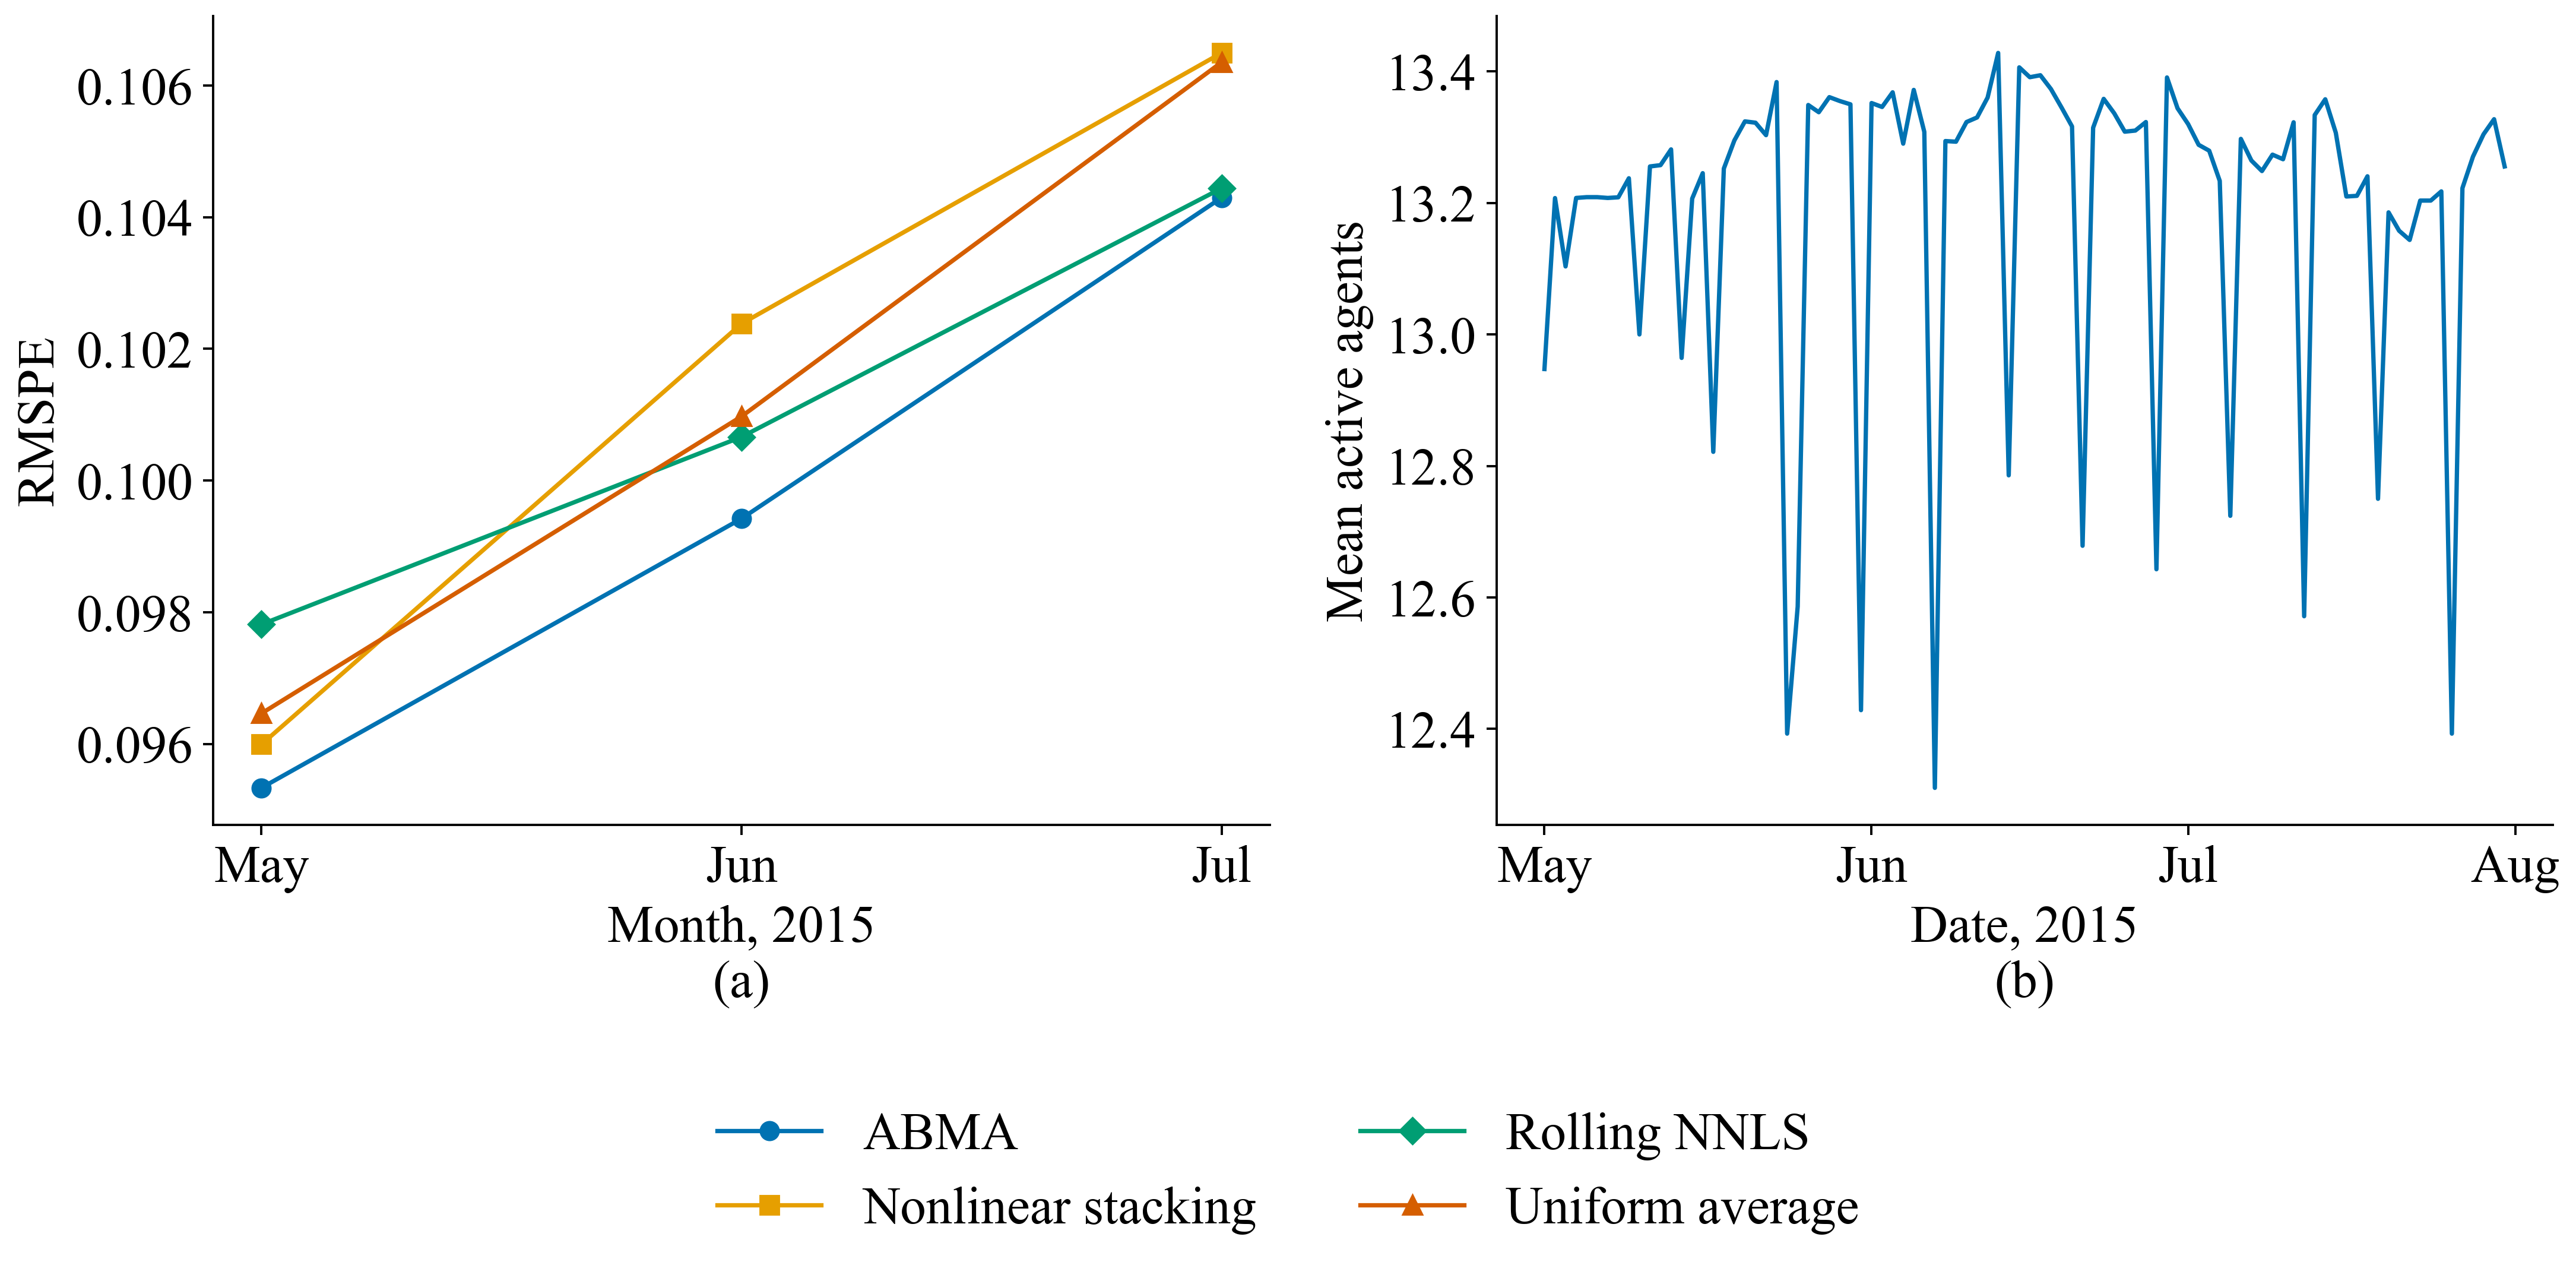

,Group,Level,Rows,ABMA,Rolling NNLS,Nonlinear stacking,Best single agent
0,Promotion,0,41520,0.1040,0.1041,0.1050,0.1049
1,Promotion,1,34477,0.0949,0.0975,0.0982,0.0990
2,Store type,0,40588,0.0984,0.0997,0.1002,0.1008
3,Store type,1,1472,0.1040,0.1009,0.1098,0.1077
4,Store type,2,10183,0.1024,0.1033,0.1045,0.1046
5,Store type,3,23754,0.1013,0.1028,0.1034,0.1034
6,School holiday,0,61175,0.1008,0.1024,0.1023,0.1029
7,School holiday,1,14822,0.0965,0.0962,0.1007,0.0995
8,Weekday Sat,False,75630,0.0998,0.1011,0.1017,0.1021
9,Weekday Sat,True,367,0.1317,0.1225,0.1428,0.1316


,Share of total squared relative loss (%)
Date,
2015-07-04,3.3712
2015-05-13,3.2012
2015-07-25,2.9784
2015-05-29,2.7906
2015-06-30,2.1601
2015-06-04,2.1369
2015-07-30,2.0472
2015-06-06,1.7923


,Mean weight,Active share
CatBoost,0.1849,0.9694
XGBoost,0.1289,0.9801
LightGBM,0.1066,0.9818
LGB deep,0.1009,0.9801
LGB recency,0.0910,0.9797
LGB ratio to profile,0.0858,0.9599
LGB ratio to level,0.0834,0.9741
LGB relative,0.0761,0.9696
LGB 1-year,0.0692,0.9635
LGB L1,0.0366,0.9802


In [10]:
act_T = tr["ACT"][Tm]; wT = pd.DataFrame(tr["W"][Tm], columns=AGENTS); frame = pd.DataFrame(tr["ACT"], columns=AGENTS); frame["s"] = stream["Store"].to_numpy(); frame["t"] = Tm
off = on = 0
for a in AGENTS:
    for _, g in frame[["s", "t", a]].groupby("s"):
        v = g[a].to_numpy().astype(int); keep = g["t"].to_numpy()[1:]; d = np.diff(v)[keep]; off += int((d == -1).sum()); on += int((d == 1).sum())
dyn = pd.DataFrame([{"Mean active agents": act_T.sum(1).mean(), "Minimum": act_T.sum(1).min(), "Maximum": act_T.sum(1).max(), "Deactivations": off, "Reactivations": on}])
display(save_table(dyn, "tab6_7_population", "Store-specific agent population during the final period.", index=False, float_format="%.2f"))
daily = pd.DataFrame({"Date": stream["Date"][Tm].values, "n": act_T.sum(1)}).groupby("Date")["n"].mean()
months = stream["Date"].dt.to_period("M").astype(str).to_numpy()
series = {"ABMA": fc["ABMA"], "Nonlinear stacking": fc["C: Nonlinear stacking"], "Rolling NNLS": fc["C: Rolling NNLS"], "Uniform average": fc["C: Uniform average (all agents)"]}
mo = sorted(set(months[Tm]))
fig, axes = plt.subplots(1, 2, figsize=(12.8, 6.4))  # one canvas (<= 13 in) so the shared legend stays below both panels
for (n, v), col, mk in zip(series.items(), PALETTE, "osD^"): axes[0].plot(range(len(mo)), [rmspe(y[Tm & (months == m)], v[Tm & (months == m)]) for m in mo], color=col, marker=mk, label=n)
axes[0].set_xticks(range(len(mo)), ["May", "Jun", "Jul"]); axes[0].set(xlabel="Month, 2015", ylabel="RMSPE")
axes[1].plot(daily.index, daily.values, color=PALETTE[0]); axes[1].xaxis.set_major_locator(mdates.MonthLocator()); axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b")); axes[1].set(xlabel="Date, 2015", ylabel="Mean active agents")
h, l = axes[0].get_legend_handles_labels(); label_panels(axes); fig.legend(h, l, loc="lower center", ncol=2, frameon=False); fig.tight_layout(rect=[0, 0.17, 1, 1]); save_fig(fig, "fig6_1_months_population"); show_fig("fig6_1_months_population")
Tf = stream[Tm]
sub = []
for label, s in {"Promotion": Tf["promo"], "Store type": Tf["store_type"], "School holiday": Tf["school_holiday"], "Weekday Sat": (Tf["dow"].astype(int) == Tf["dow"].astype(int).max())}.items():
    for lv in sorted(pd.unique(s)):
        u = (s == lv).to_numpy(); sub.append({"Group": label, "Level": str(lv), "Rows": int(u.sum()), "ABMA": rmspe(y[Tm][u], fc["ABMA"][Tm][u]), "Rolling NNLS": rmspe(y[Tm][u], fc["C: Rolling NNLS"][Tm][u]), "Nonlinear stacking": rmspe(y[Tm][u], fc["C: Nonlinear stacking"][Tm][u]), "Best single agent": rmspe(y[Tm][u], fc["C: Best single agent"][Tm][u])})
display(save_table(pd.DataFrame(sub), "tab6_8_subgroups", "Final period RMSPE by subgroup.", index=False))
e_T = ((fc["ABMA"][Tm] - y[Tm]) / y[Tm]) ** 2; ds = pd.DataFrame({"Date": day_T, "e": e_T}).groupby("Date")["e"].sum().sort_values(ascending=False)
display(save_table((100 * ds.head(8) / e_T.sum()).rename("Share of total squared relative loss (%)").to_frame(), "tab6_9_worst_days", "Eight days with the largest ABMA loss in the final period."))
order_w = wT.mean().sort_values().index
wg = pd.DataFrame(tr["W"][Tm], columns=AGENTS).groupby(Tf["promo"].to_numpy()).mean()[list(order_w)]
display(save_table(wT.mean().sort_values(ascending=False).rename("Mean weight").to_frame().assign(**{"Active share": pd.DataFrame(act_T, columns=AGENTS).mean()}), "tab6_10_weights", "Posterior weight and active share of each agent, final period, used as the explanation of the combination."))

## 7. Predictive intervals against a quantile-regression baseline on identical rows

Quantile LightGBM (NB03 configuration, alpha 0.05 and 0.95) refitted at the final origin in 323s


,Model,PICP90,MPIW90,MPIW90_rel,Coverage gap to 0.90
0,ABMA mixture (frozen scale),0.9117,"2,265.0762",0.3224,0.0117
1,LightGBM quantile regression (NB03 configuration),0.7934,"1,618.8337",0.2364,-0.1066


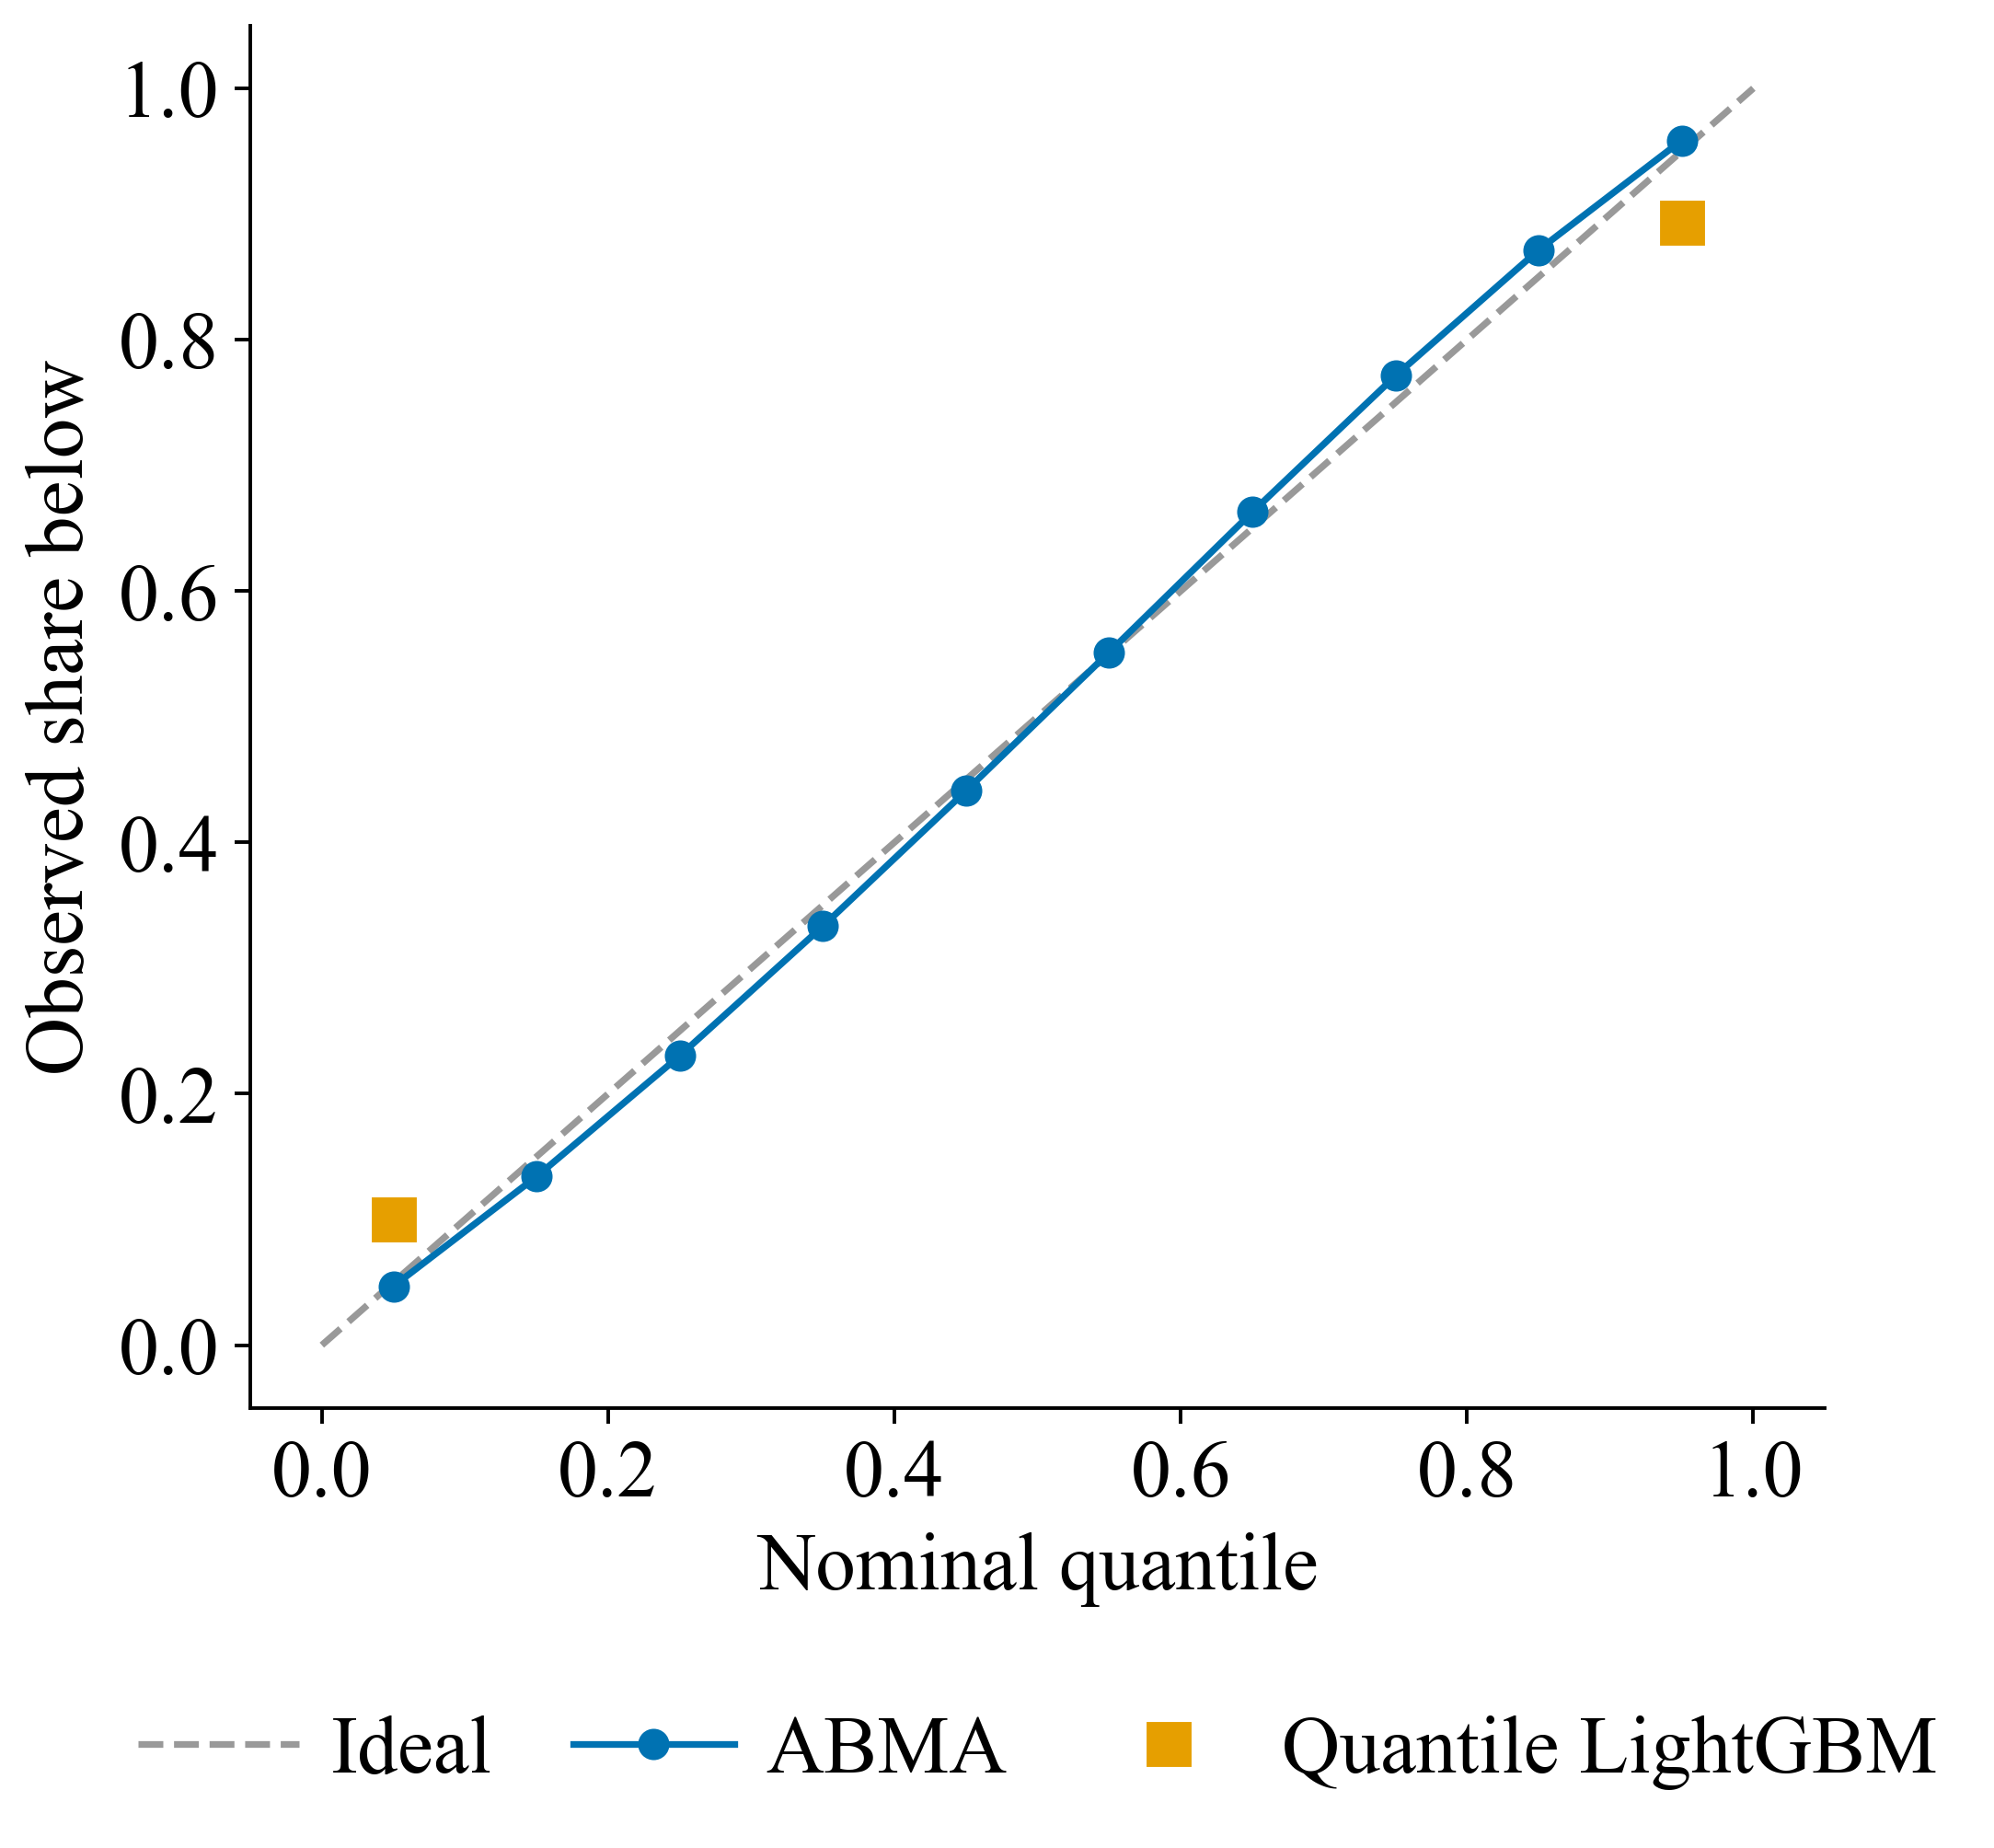

In [11]:
t0 = time.time(); q_models = {tau: lgb.LGBMRegressor(**{**lgb_cfg, "objective": "quantile", "alpha": tau}, subsample_freq=1, random_state=SEED, n_jobs=N_JOBS, verbose=-1).fit(fit_T[FEATURES], fit_T["log_sales"], categorical_feature=CATEGORICAL) for tau in (0.05, 0.95)}
q_pred = pd.DataFrame({tau: np.exp(q_models[tau].predict(test[FEATURES])) for tau in (0.05, 0.95)}, index=test["row_id"].to_numpy()).reindex(stream.loc[Tm, "row_id"].to_numpy())
q_lo, q_hi = np.minimum(q_pred[0.05].to_numpy(), q_pred[0.95].to_numpy()), np.maximum(q_pred[0.05].to_numpy(), q_pred[0.95].to_numpy())
print(f"Quantile LightGBM (NB03 configuration, alpha 0.05 and 0.95) refitted at the final origin in {time.time() - t0:.0f}s")
pi = pd.DataFrame([{"Model": "ABMA mixture (frozen scale)", **interval_metrics(y[Tm], qlo, qhi)}, {"Model": "LightGBM quantile regression (NB03 configuration)", **interval_metrics(y[Tm], q_lo, q_hi)}])
pi["Coverage gap to 0.90"] = pi["PICP90"] - 0.9
display(save_table(pi, "tab6_11_intervals", "Coverage (PICP) and width (MPIW, absolute and relative) of 90% predictive intervals in the final period on identical rows: the ABMA mixture with the frozen scale and the quantile-LightGBM interval of NB03 refitted at the final origin.", index=False))
pc = np.linspace(.05, .95, 10); cov = [(y[Tm] <= mixture_quantile(tr["W"][Tm], tr["MU"][Tm], frozen["pi_scale"] * tr["SG"][Tm], q)).mean() for q in pc]
fig, ax = plt.subplots(figsize=(6.5, 6.2)); ax.plot([0, 1], [0, 1], color="0.6", ls="--", label="Ideal"); ax.plot(pc, cov, color=PALETTE[0], marker="o", label="ABMA")
ax.plot([0.05, 0.95], [(y[Tm] <= q_lo).mean(), (y[Tm] <= q_hi).mean()], ls="none", marker="s", ms=9, color=PALETTE[1], label="Quantile LightGBM"); ax.set(xlabel="Nominal quantile", ylabel="Observed share below")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3, frameon=False, handletextpad=0.4, columnspacing=1.0); fig.tight_layout(); save_fig(fig, "fig6_2_reliability"); show_fig("fig6_2_reliability")

## 8. Computational scalability of the online layer

Wall time and peak traced memory of the online layer with the frozen configuration on the full stream, for random subsets of stores and for the 3, 7 and all agents with the largest final-period weights.

stores 100 agents 3: 0.2s, 5 MiB


stores 100 agents 7: 0.3s, 9 MiB


stores 100 agents 14: 0.6s, 17 MiB


stores 250 agents 3: 0.3s, 12 MiB


stores 250 agents 7: 0.6s, 22 MiB


stores 250 agents 14: 1.0s, 41 MiB


... (5 outputs left out)

stores 1003 agents 14: 3.3s, 162 MiB


,Stores,Agents,Store-days,Seconds,Seconds per million store-days,Peak memory (MiB)
0,100,3,37820,0.2090,5.5250,4.8640
1,100,7,37820,0.3371,8.9130,9.1129
2,100,14,37820,0.5683,15.0268,16.6301
3,250,3,93339,0.3250,3.4822,11.6974
4,250,7,93339,0.5719,6.1272,22.2962
5,250,14,93339,1.0135,10.8586,40.8510
6,500,3,184545,0.5133,2.7814,22.9975
7,500,7,184545,0.9686,5.2484,43.9603
8,500,14,184545,1.7822,9.6574,80.6552
9,1003,3,370863,0.9083,2.4492,46.0741


,Stream,Store-days,Seconds,Store-days per second,Peak memory (MiB)
0,"Last 120 days, 1,003 stores",93173,0.7455,"124,976.2186",43.6891
1,"Synthetic replication x10, 10,030 stores",931730,7.0811,"131,578.9491",435.8972


,Combiner,Seconds
0,ABMA online layer (14 agents),3.3301
1,Rolling NNLS,0.1104
2,Nonlinear stacking,18.2605
3,Dynamic model averaging,1.4870
4,Fixed-share exponential weighting,0.2037
5,Dynamic weighted majority,0.2336
6,Drift-reset NNLS (Page-Hinkley),0.0988


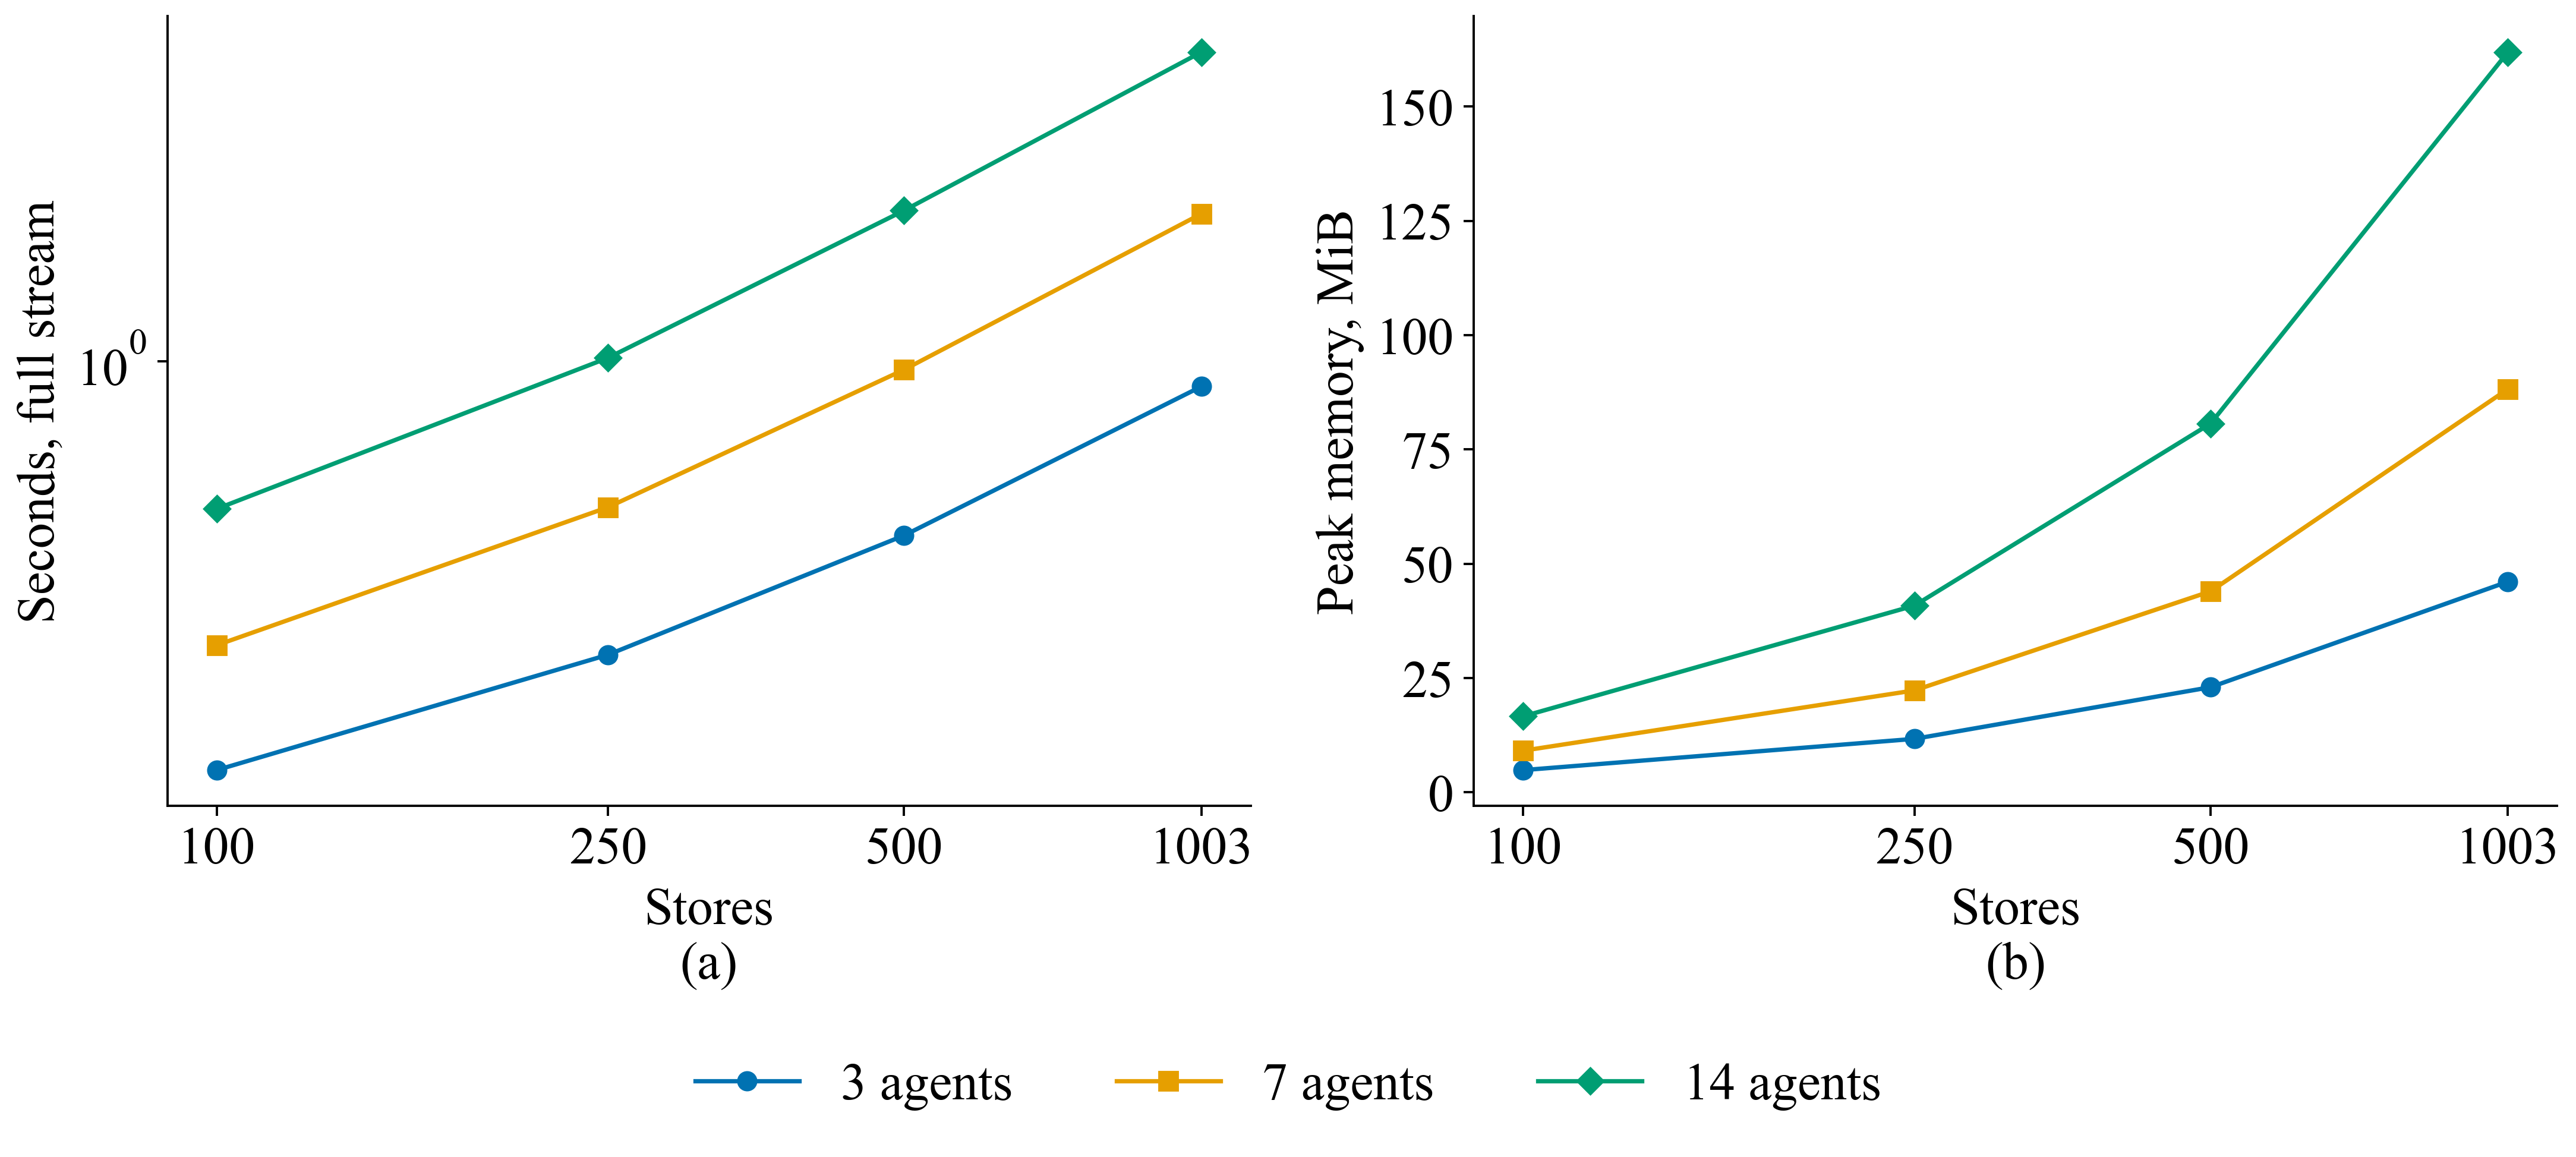

In [12]:
import tracemalloc
def timed_layer(st, Pm):
    """Wall time of one pass of the online layer (no tracing) and peak traced memory of a second identical pass."""
    t0 = time.time(); abma_run(st, Pm, ABMA_CFG); dt = time.time() - t0
    tracemalloc.start(); abma_run(st, Pm, ABMA_CFG); peak = tracemalloc.get_traced_memory()[1] / 2 ** 20; tracemalloc.stop(); return dt, peak
top_agents = list(wT.mean().sort_values(ascending=False).index)
stores_all = np.sort(stream["Store"].unique()); g_sc = np.random.default_rng(SEED); scal = []
for ns in (100, 250, 500, len(stores_all)):
    sel = stores_all if ns == len(stores_all) else g_sc.choice(stores_all, ns, replace=False)
    m = stream["Store"].isin(sel).to_numpy(); st = stream.loc[m, ["Store", "Date", "Sales", "ctx"]].reset_index(drop=True)
    for k in (3, 7, len(AGENTS)):
        cols = [AGENTS.index(a) for a in top_agents[:k]]; dt, peak = timed_layer(st, P[m][:, cols])
        scal.append({"Stores": int(ns), "Agents": k, "Store-days": int(m.sum()), "Seconds": dt, "Seconds per million store-days": 1e6 * dt / m.sum(), "Peak memory (MiB)": peak}); print(f"stores {ns} agents {k}: {dt:.1f}s, {peak:.0f} MiB", flush=True)
scal = pd.DataFrame(scal)
display(save_table(scal, "tab6_13_scalability", "Wall time (no tracing) and peak traced memory of the online layer with the frozen configuration on the full stream, for random subsets of stores and for the agents with the largest final-period weights.", index=False, float_format="%.2f"))
tail_m = (stream["Date"] >= stream["Date"].max() - pd.Timedelta(days=119)).to_numpy(); base = stream.loc[tail_m, ["Store", "Date", "Sales", "ctx"]].reset_index(drop=True); Pb = P[tail_m]
rep = pd.concat([base.assign(Store=base["Store"] + 10000 * r) for r in range(10)], ignore_index=True); Prep = np.tile(Pb, (10, 1))
dt_one, peak_one = timed_layer(base, Pb); dt_rep, peak_rep = timed_layer(rep, Prep)
thr = pd.DataFrame([{"Stream": "Last 120 days, 1,003 stores", "Store-days": len(base), "Seconds": dt_one, "Store-days per second": len(base) / dt_one, "Peak memory (MiB)": peak_one}, {"Stream": "Synthetic replication x10, 10,030 stores", "Store-days": len(rep), "Seconds": dt_rep, "Store-days per second": len(rep) / dt_rep, "Peak memory (MiB)": peak_rep}])
display(save_table(thr, "tab6_14_throughput", "Throughput of the online layer on the last 120 days of the stream and on its tenfold synthetic replication with offset store identifiers (cost only; the replicated rows carry no new information).", index=False, float_format="%.1f"))
comb = pd.DataFrame([{"Combiner": f"ABMA online layer ({len(AGENTS)} agents)", "Seconds": ABMA_SEC}] + [{"Combiner": k[3:], "Seconds": v} for k, v in CTRL_SEC.items()])
display(save_table(comb, "tab6_15_combiner_time", f"Wall time of each combination rule on the full stream (development and final period, 1,003 stores, {len(AGENTS)} agents); the nonlinear stacker includes its LightGBM refits at four origins, the other rules are online updates.", index=False, float_format="%.1f"))
fig, axes = plt.subplots(1, 2, figsize=(12.8, 5.8))
for k, col, mk in zip((3, 7, len(AGENTS)), PALETTE, "osD"):
    sk = scal[scal["Agents"] == k]; axes[0].plot(sk["Stores"], sk["Seconds"], color=col, marker=mk, label=f"{k} agents"); axes[1].plot(sk["Stores"], sk["Peak memory (MiB)"], color=col, marker=mk, label=f"{k} agents")
axes[0].set(xlabel="Stores", ylabel="Seconds, full stream", xscale="log", yscale="log"); axes[1].set(xlabel="Stores", ylabel="Peak memory, MiB", xscale="log")
for ax in axes: ax.set_xticks([100, 250, 500, 1003], ["100", "250", "500", "1003"]); ax.minorticks_off()
h, l = axes[0].get_legend_handles_labels(); label_panels(axes); fig.legend(h, l, loc="lower center", ncol=3, frameon=False); fig.tight_layout(rect=[0, 0.10, 1, 1]); save_fig(fig, "fig6_4_scalability"); show_fig("fig6_4_scalability")

## 9. Component evidence and forest plot

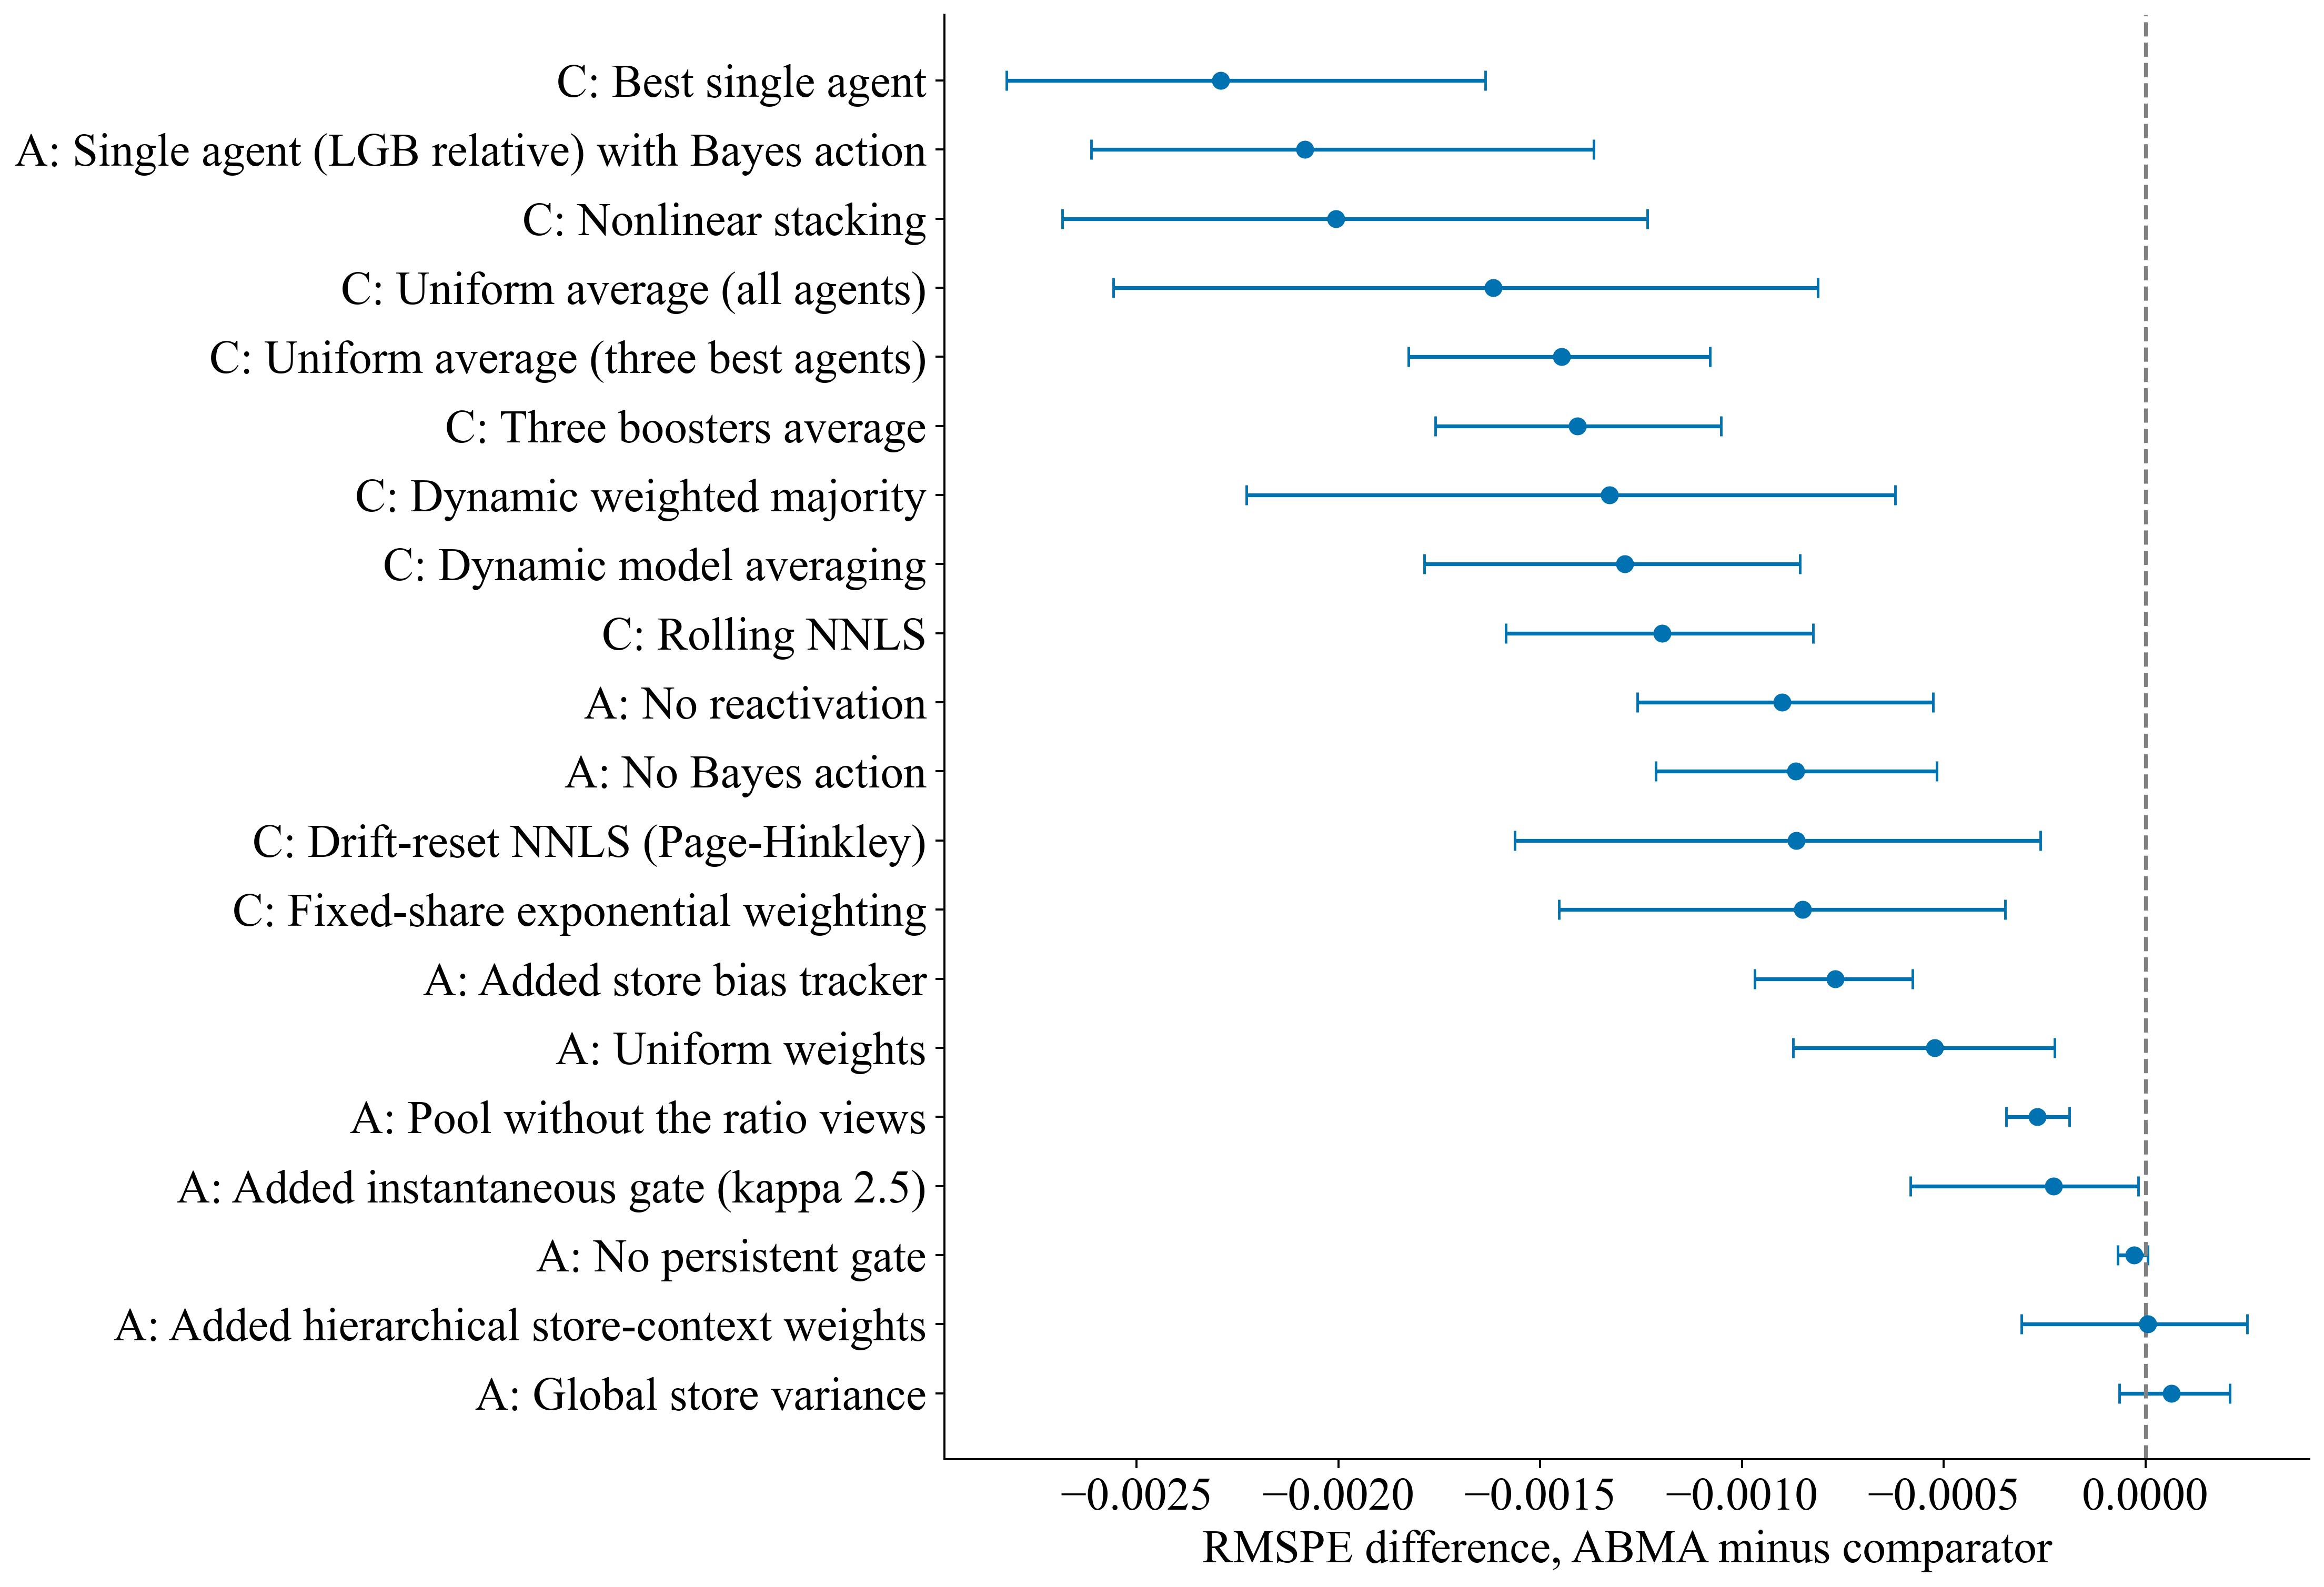

In [13]:
keys = [k for k in pair_T["Comparator"] if k.startswith(("A:", "C:"))]
pf = pair_T.set_index("Comparator").loc[keys].sort_values("Difference (ABMA - comparator)", ascending=False)
fig, ax = plt.subplots(figsize=(13, 9.0)); yy = np.arange(len(pf))
ax.errorbar(pf["Difference (ABMA - comparator)"], yy, xerr=[pf["Difference (ABMA - comparator)"] - pf["CI low"], pf["CI high"] - pf["Difference (ABMA - comparator)"]], fmt="o", color=PALETTE[0], capsize=4)
ax.axvline(0, color="0.5", ls="--"); ax.set_yticks(yy, [k for k in pf.index]); ax.set(xlabel="RMSPE difference, ABMA minus comparator"); fig.tight_layout(); save_fig(fig, "fig6_3_forest"); show_fig("fig6_3_forest")

In [14]:
# Forecasts of every model on the final period
pd.DataFrame({k: v[Tm] for k, v in fc.items()}).assign(row_id=stream["row_id"][Tm].values, y=y[Tm]).to_parquet(RUNS / "NB06_test_forecasts.parquet", index=False)

# Part B · UCI Sales Transactions Weekly

## Sealed evaluation of the count-law model on weeks 40–51 and on the external products

Weeks 40–51 of the 729 core products are the primary panel; the 82 external products, never used for fitting, are the secondary panel.

In [1]:
# NB06_SETUP: inputs, packages and helpers (same conventions as NB01-NB05 of this panel)
import os
os.environ['OMP_NUM_THREADS']='4';os.environ['OPENBLAS_NUM_THREADS']='4'
import json,hashlib,time,platform,sys,resource,gzip,importlib.metadata,inspect,warnings,io,csv,zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import cloudpickle
from IPython.display import display,Markdown,Image
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib import font_manager
from threadpoolctl import threadpool_limits,threadpool_info
from scipy import special,stats
THREAD_LIMIT=threadpool_limits(limits=4)
SEED=2026
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'dataset').is_dir() and (p/'notebooks').is_dir())
BASE=ROOT/'outputs'/'uci'
for _d in ('Artifacts','Manifests','Configs'):(BASE/_d).mkdir(parents=True,exist_ok=True)
RUN_ID='NB06_UCI_'+pd.Timestamp.now(tz='UTC').strftime('%Y%m%dT%H%M%S%fZ');OUT=BASE/'Artifacts'/RUN_ID;OUT.mkdir(parents=True,exist_ok=True)
def dump(p,v):p.write_text(json.dumps(v,indent=2,allow_nan=False,default=str))
LATEST=json.loads((BASE/'Manifests/latest_runs.json').read_text())
FONT=font_manager.findfont('Times New Roman',fallback_to_default=False)
plt.rcParams.update({'font.family':'Times New Roman','font.size':18,'axes.labelsize':18,'axes.titlesize':20,'xtick.labelsize':18,'ytick.labelsize':18,'legend.fontsize':18,'figure.dpi':350,'savefig.dpi':350,'pdf.fonttype':42,'axes.unicode_minus':True,'axes.spines.top':False,'axes.spines.right':False,'mathtext.fontset':'custom','mathtext.rm':'Times New Roman','mathtext.it':'Times New Roman:italic','mathtext.bf':'Times New Roman:bold','mathtext.default':'regular'})
PALETTE=['#0072B2','#E69F00','#009E73','#D55E00','#CC79A7','#56B4E9','#000000']  # Okabe-Ito, colour-blind safe
pd.set_option('display.max_rows',200,'display.max_columns',20,'display.max_colwidth',None,'display.width',220,'display.float_format',lambda v:f'{v:.5f}')
def tidy(df,note='n/a'):
    """Display copy of a table: missing cells are marked explicitly instead of NaN; underflowed p-values are shown as bounds."""
    out=df.copy()
    for c in out.columns:
        if str(c)=='p' or str(c).startswith('p ') or 'p-value' in str(c) or str(c).startswith('Holm p'):
            out[c]=['< 1e-300' if (isinstance(v,float) and v==0.0) else (f'{v:.4g}' if isinstance(v,(float,np.floating)) else v) for v in out[c]]
    return out.astype(object).where(out.notna(),note)
def table(df,name,best=None,fmt='%.5f'):
    clean=tidy(df.reset_index() if df.index.name is not None else df)
    clean.to_csv(OUT/(name+'.csv'),index=False);(OUT/(name+'.tex')).write_text(clean.to_latex(index=False,float_format=fmt,escape=True))
    if best:display(clean.style.format({k:(lambda v:(fmt%v) if isinstance(v,(float,np.floating)) else v) for k in best}).highlight_min(subset=best,props='font-weight:bold;'))
    else:display(clean)
def figure(fig,name):
    for ext,dpi in [('pdf',350),('png',350),('png',600)]:fig.savefig(OUT/(name+('_600dpi' if dpi==600 else '')+'.'+ext),dpi=dpi,bbox_inches='tight')
    plt.close(fig);display(Image(filename=str(OUT/(name+'.png')),width=900))
def label_panels(axes,labels='abcdefgh'):
    """Letter each panel below its x-axis label, (a), (b), ..., so that panels can be cited."""
    for ax,l in zip(np.ravel(axes),labels):ax.set_xlabel((ax.get_xlabel()+'\n' if ax.get_xlabel() else '')+f'({l})')
def metrics(y,p):
    y=np.asarray(y,float);p=np.asarray(p,float);assert len(y)==len(p) and np.isfinite(p).all() and (p>=0).all()
    positive=y>0;zero=~positive;den=np.abs(y)+np.abs(p);sm=np.divide(2*np.abs(y-p),den,out=np.zeros(len(y)),where=den>0)
    return {'RMSPE':float(np.sqrt(np.mean(((p[positive]-y[positive])/y[positive])**2))),'RMSE':float(np.sqrt(np.mean((p-y)**2))),'MAE':float(np.mean(np.abs(p-y))),'sMAPE_pct':float(100*sm.mean()),'R2':float(1-np.sum((p-y)**2)/np.sum((y-y.mean())**2)),'Zero_MAE':float(np.mean(p[zero])) if zero.any() else 0.,'Positive_n':int(positive.sum()),'Zero_n':int(zero.sum())}
def rmspe(y,p):
    y=np.asarray(y,float);p=np.asarray(p,float);m=y>0;return float(np.sqrt(np.mean(((p[m]-y[m])/y[m])**2)))

import torch,torch.nn as nn,torch.nn.functional as F
from sklearn.preprocessing import QuantileTransformer
from sklearn.linear_model import Ridge,PoissonRegressor
from sklearn.ensemble import RandomForestRegressor
import lightgbm as lgb
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from scipy.optimize import nnls
torch.set_num_threads(4);DEVICE=torch.device('cpu')
PLAN=json.loads((BASE/'Configs/baseline_search.json').read_text());FM=json.loads((BASE/'Manifests/feature_manifest.json').read_text());BM=json.loads((BASE/'Manifests/baseline_manifest.json').read_text());NM=json.loads((BASE/'Manifests/network_manifest.json').read_text())
CTRL=json.loads((BASE/'Configs/uci_frozen_controls.json').read_text());CONTRACT=json.loads((BASE/'Configs/feature_contract.json').read_text());DESIGN=json.loads((BASE/'Configs/study_design.json').read_text())
NB03_OUT,NB04_OUT,NB05_OUT=(BASE/'Artifacts'/r for r in (BM['run_id'],NM['run_id'],LATEST['NB05']))
FROZEN=json.loads((ROOT/'outputs'/'configs'/'abma_frozen.json').read_text())
RAW=ROOT/'dataset'/'raw'/'UCI_SalesTransactionsWeekly'/'source.zip'

### 1. Frozen configuration

In [2]:
# ABMA engine: every label of date d enters the state only at date d + lag.
from scipy import special

ABMA_DEFAULT = dict(lag=7, nctx=14, clip=0.5, sig_floor=0.03, sig_scale=1.0, disc_var=0.995, store_sigma=True,
                    bias_mode="none", q=1e-6, p0=5e-4,
                    weight_mode="global", eta=0.5, disc_w=0.98, store_shrink=30.0,
                    gate_on=True, reactivate=True, theta0=0.5, gate_p=0.7, disc_beta=0.98, min_active=3, kappa=2.5,
                    action="bayes", dispersion=True, gate_loss="log",
                    law="lognormal", n_res=257, disc_res=0.98, smooth=0.5)


def abma_run(stream, P, cfg=None):
    """stream: Store, Date, Sales, ctx sorted by Date; P: n x K positive agent forecasts (NaN = agent absent).
    law = "lognormal": the predictive law of each agent is lognormal on log Sales (positive continuous targets).
    law = "count": Sales and P are non-negative counts; the lognormal state works on log(1 + count) and the predictive law of each agent is an
    empirical count law, y = max(0, round(p + sqrt(p + 1) r)) with r drawn from a discounted chain-wide reservoir of the agent's scaled residuals
    (n_res weighted quantiles, discount disc_res); the weights use the log predictive mass of the observed count (Laplace smoothing `smooth`) and
    the Bayes action under the positive-target relative loss is E[1/y; y > 0] / E[1/y^2; y > 0] of the mixture of count laws."""
    c = {**ABMA_DEFAULT, **(cfg or {})}
    n, K = P.shape
    N = c["nctx"]
    si = np.unique(stream["Store"].to_numpy(), return_inverse=True)[1]
    S = si.max() + 1
    dates, di = np.unique(stream["Date"].to_numpy(), return_inverse=True)
    day = dates.astype("datetime64[D]").astype(int)
    COUNT = c["law"] == "count"
    if COUNT:
        Pq = np.asarray(P, float)
        yq = stream["Sales"].to_numpy(float)
        y = np.log1p(yq)
        lp = np.log1p(Pq)
        NQ = int(c["n_res"])
        qgrid = (np.arange(NQ) + 0.5) / NQ
        rsv = [np.zeros(0) for _ in range(K)]
        rsv_w = [np.zeros(0) for _ in range(K)]
        law_q = np.full((K, NQ), np.nan)
        LAW = np.full((len(dates), K, NQ), np.nan)

        def law_update(k):
            o = np.argsort(rsv[k])
            cw = np.cumsum(rsv_w[k][o])
            cw /= cw[-1]
            return np.interp(qgrid, cw, rsv[k][o])

        def law_draws(k, ix):
            return np.maximum(0.0, np.rint(Pq[ix, k][:, None] + np.sqrt(Pq[ix, k][:, None] + 1.0) * law_q[k][None, :]))
    else:
        y = np.log(stream["Sales"].to_numpy(float))
        lp = np.log(P)
    C = stream["ctx"].to_numpy()
    bias, bias_var = np.zeros((S, K)), np.full((S, K), c["p0"])
    v_n, v_s = np.full((S, K), 5.0), np.full((S, K), 5 * 0.02)
    ctx_n, ctx_s = np.ones((N, K)), np.ones((N, K))
    L_g, L_s, n_s = np.zeros((N, K)), np.zeros((S, N, K)), np.zeros((S, N))
    a, b = np.ones((S, K)), np.ones((S, K))
    latched = np.zeros((S, K), bool)
    out = np.zeros(n)
    W, MU, SG = np.zeros((n, K), np.float32), np.zeros((n, K)), np.zeros((n, K))
    ACT = np.zeros((n, K), bool)
    days = [np.where(di == d)[0] for d in range(len(dates))]
    ptr = 0
    for d, ix in enumerate(days):
        while ptr < d and day[ptr] <= day[d] - c["lag"]:
            jx = days[ptr]
            ptr += 1
            s, cc, yy = si[jx], C[jx], y[jx][:, None]
            mu, sg, ok = MU[jx], np.maximum(SG[jx], 1e-3), ~np.isnan(lp[jx])
            ll = np.where(ok, np.maximum(-0.5 * ((yy - mu) / sg) ** 2 - np.log(sg), -12.0), 0.0)
            if COUNT:  # log predictive mass of the observed count under each agent's count law (lognormal score until the law exists)
                for k in range(K):
                    if np.isnan(law_q[k, 0]):
                        continue
                    hits = (np.abs(law_draws(k, jx) - yq[jx][:, None]) < 0.5).mean(1) * NQ
                    ll[:, k] = np.where(ok[:, k], np.log((hits + c["smooth"]) / (NQ + c["smooth"])), 0.0)
                r_new = np.where(ok, (yq[jx][:, None] - np.nan_to_num(Pq[jx])) / np.sqrt(np.nan_to_num(Pq[jx]) + 1.0), np.nan)
                for k in range(K):
                    rk = r_new[ok[:, k], k]
                    if len(rk) == 0:
                        continue
                    rsv[k] = np.concatenate([rsv[k], rk])
                    rsv_w[k] = np.concatenate([rsv_w[k] * c["disc_res"], np.ones(len(rk))])
                    if len(rsv[k]) > 40 * NQ:
                        rsv[k] = law_update(k)
                        rsv_w[k] = np.full(NQ, rsv_w[k].sum() / NQ)
                    law_q[k] = law_update(k)
            L_s[s, cc] = c["disc_w"] * L_s[s, cc] + ll
            n_s[s, cc] = c["disc_w"] * n_s[s, cc] + 1
            for x in np.unique(cc):
                L_g[x] = c["disc_w"] * L_g[x] + ll[cc == x].mean(0)
            if c.get("gate_loss", "log") == "log":  # default criterion: absolute log error
                ae = np.where(ok, np.abs(yy - mu), np.nan)
            else:  # alternative criterion: squared relative error of the point forecast, the loss of the Bayes action
                ae = np.where(ok, (np.exp(mu - yy) - 1) ** 2, np.nan)
            win = ae <= np.nanmedian(ae, axis=1, keepdims=True)
            keep = 1 - c["disc_beta"]
            a[s] = c["disc_beta"] * a[s] + keep + (win & ok)
            b[s] = c["disc_beta"] * b[s] + keep + (~win & ok)
            e = yy - lp[jx]
            for k in range(K):
                o = ok[:, k]
                sk = s[o]
                r = np.maximum(v_s[sk, k] / v_n[sk, k], 1e-4)
                pp = bias_var[sk, k] + c["q"]
                gain = pp / (pp + r)
                bias[sk, k] += gain * np.clip(e[o, k] - bias[sk, k], -c["clip"], c["clip"])
                bias_var[sk, k] = (1 - gain) * pp
                res = yy[o, 0] - (lp[jx][o, k] + (bias[sk, k] if c["bias_mode"] == "agent" else 0.0))
                sq = np.minimum(res ** 2, c["clip"] ** 2)
                v_n[sk, k] = c["disc_var"] * v_n[sk, k] + 1
                v_s[sk, k] = c["disc_var"] * v_s[sk, k] + sq
                for x in np.unique(cc[o]):
                    u = cc[o] == x
                    ctx_n[x, k] = 0.99 * ctx_n[x, k] + 1
                    ctx_s[x, k] = 0.99 * ctx_s[x, k] + (sq[u] / np.maximum(v_s[sk[u], k] / v_n[sk[u], k], 1e-4)).mean()
        s, cc = si[ix], C[ix]
        mu = lp[ix] + (bias[s] if c["bias_mode"] == "agent" else 0.0)
        var = v_s[s] / v_n[s] if c["store_sigma"] else np.broadcast_to((v_s / v_n).mean(0), (len(ix), K))
        sg = c["sig_scale"] * np.maximum(np.sqrt(var * ctx_s[cc] / ctx_n[cc]), c["sig_floor"])
        MU[ix], SG[ix] = mu, sg
        A = ~np.isnan(lp[ix])
        if c["gate_on"]:
            pl = special.betainc(a[s], b[s], c["theta0"])
            g = pl < c["gate_p"]
            if not c["reactivate"]:
                latched[s] |= ~g
                g = ~latched[s]
            few = g.sum(1) < c["min_active"]
            if few.any():
                best = np.argsort(pl[few], axis=1)[:, : c["min_active"]]
                gf = np.zeros((few.sum(), K), bool)
                np.put_along_axis(gf, best, True, axis=1)
                g[few] = gf
            A = A & g
        if c["kappa"] > 0:  # instantaneous gate: an active agent far from the consensus of the active pool is switched off for this row
            mu_act = np.where(A, np.nan_to_num(mu), np.nan)
            consensus = np.nanmedian(mu_act, axis=1, keepdims=True)
            pool_sd = np.sqrt(np.nanmedian(np.where(A, sg ** 2, np.nan), axis=1, keepdims=True))
            far = np.abs(np.nan_to_num(mu) - consensus) > c["kappa"] * np.maximum(sg, pool_sd)
            A2 = A & ~far
            A = np.where((A2.sum(1) >= c["min_active"])[:, None], A2, A)
        ACT[ix] = A
        if c["weight_mode"] == "uniform":
            lw = np.zeros((len(ix), K))
        elif c["weight_mode"] == "global":
            lw = np.repeat(c["eta"] * L_g.mean(0, keepdims=True), len(ix), 0)
        elif c["weight_mode"] == "context":
            lam = (n_s[s, cc] / (n_s[s, cc] + c["store_shrink"]))[:, None]
            lw = c["eta"] * (L_g[cc] + lam * (L_s[s, cc] - L_g[cc]))
        lw = np.where(A, lw, -np.inf)
        lw -= lw.max(1, keepdims=True)
        w = np.exp(lw)
        w /= w.sum(1, keepdims=True)
        W[ix] = w
        m0 = np.nan_to_num(mu)
        if COUNT:
            LAW[d] = law_q
            num, den = np.zeros(len(ix)), np.zeros(len(ix))
            for k in range(K):
                if np.isnan(law_q[k, 0]):  # no residual history yet: lognormal fallback on the shifted scale
                    num += w[:, k] * np.exp(-m0[:, k] + 0.5 * sg[:, k] ** 2)
                    den += w[:, k] * np.exp(-2 * m0[:, k] + 2 * sg[:, k] ** 2)
                    continue
                yk = law_draws(k, ix)
                inv = np.where(yk > 0, 1.0 / np.where(yk > 0, yk, 1.0), 0.0)
                num += w[:, k] * inv.mean(1)
                den += w[:, k] * (inv ** 2).mean(1)
            if c["action"] == "bayes":
                out[ix] = np.where(den > 0, num / np.maximum(den, 1e-300), np.nan_to_num(Pq[ix]).mean(1))
            else:
                out[ix] = np.expm1((w * m0).sum(1))
            continue
        if c["action"] == "bayes":
            s2 = sg if c["dispersion"] else np.full_like(sg, np.sqrt((w * sg ** 2).sum(1, keepdims=True)))
            out[ix] = (w * np.exp(-m0 + 0.5 * s2 ** 2)).sum(1) / (w * np.exp(-2 * m0 + 2 * s2 ** 2)).sum(1)
        else:
            out[ix] = np.exp((w * m0).sum(1))
    if COUNT:
        return out, dict(W=W, MU=MU, SG=SG, ACT=ACT, LAW=LAW, LAW_IDX=di, P=Pq)
    return out, dict(W=W, MU=MU, SG=SG, ACT=ACT)


def mixture_quantile(W, MU, SG, q, iters=40, count=None):
    """Quantile of the lognormal mixture, by bisection in log sales; with `count` = (P, LAW, LAW_IDX) from a count-law run, the weighted quantile of the mixture of empirical count laws (rows without a law fall back to the lognormal quantile minus one, clipped at zero)."""
    if count is not None:
        Pq, LAW, idx = count
        n, K = Pq.shape
        NQ = LAW.shape[2]
        out = np.full(n, np.nan)
        for a in range(0, n, 2048):
            ix = np.arange(a, min(n, a + 2048))
            lq = LAW[idx[ix]]
            ok = ~np.isnan(lq[:, :, 0])
            draws = np.maximum(0.0, np.rint(Pq[ix][:, :, None] + np.sqrt(Pq[ix][:, :, None] + 1.0) * np.nan_to_num(lq)))
            wts = np.where(ok, W[ix], 0.0)[:, :, None] * np.ones((1, 1, NQ)) / NQ
            flat = draws.reshape(len(ix), -1)
            wf = wts.reshape(len(ix), -1)
            o = np.argsort(flat, axis=1)
            fs = np.take_along_axis(flat, o, 1)
            cw = np.cumsum(np.take_along_axis(wf, o, 1), axis=1)
            tot = cw[:, -1:]
            pos = (cw >= q * tot).argmax(1)
            val = fs[np.arange(len(ix)), pos]
            none = tot[:, 0] <= 0
            if none.any():
                val[none] = np.maximum(0.0, _lognormal_quantile(W[ix][none], MU[ix][none], SG[ix][none], q, iters) - 1.0)
            out[ix] = val
        return out
    return _lognormal_quantile(W, MU, SG, q, iters)


def _lognormal_quantile(W, MU, SG, q, iters=40):
    lo, hi = (MU - 6 * SG).min(1), (MU + 6 * SG).max(1)
    for _ in range(iters):
        mid = (lo + hi) / 2
        cdf = (W * special.ndtr((mid[:, None] - MU) / SG)).sum(1)
        lo, hi = np.where(cdf < q, mid, lo), np.where(cdf < q, hi, mid)
    return np.exp((lo + hi) / 2)


# Streaming combiners from the data-stream literature, used as controls; they are not part of the frozen model and are outside the engine hash.
def _stream_index(stream):
    si = np.unique(stream["Store"].to_numpy(), return_inverse=True)[1]
    dates, di = np.unique(stream["Date"].to_numpy(), return_inverse=True)
    day = dates.astype("datetime64[D]").astype(int)
    return si, si.max() + 1, day, [np.where(di == d)[0] for d in range(len(dates))]


def fixed_share(stream, P, y, eta=10.0, alpha=0.01, scope="store", lag=7):
    """Fixed-share exponentially weighted average (Herbster and Warmuth, 1998): weights proportional to exp(-eta * cumulative loss) with a share alpha of the mass redistributed uniformly at every update; loss = squared relative error of the point forecast clipped at 1; weights per store or chain-wide; the log forecasts are combined; labels of day d enter at day d + lag."""
    n, K = P.shape
    lp, ly = np.log(P), np.log(y)
    si, S, day, days = _stream_index(stream)
    LW = np.zeros((S if scope == "store" else 1, K))
    out = np.zeros(n)
    ptr = 0
    for d, ix in enumerate(days):
        while ptr < d and day[ptr] <= day[d] - lag:
            jx = days[ptr]
            ptr += 1
            ok = ~np.isnan(lp[jx])
            loss = np.where(ok, np.minimum((np.exp(lp[jx] - ly[jx][:, None]) - 1) ** 2, 1.0), 0.0)
            r = si[jx] if scope == "store" else np.zeros(1, int)
            if scope == "store":
                LW[r] -= eta * loss
            else:
                LW[0] -= eta * loss.mean(0)
            if alpha > 0:
                w = np.exp(LW[r] - LW[r].max(1, keepdims=True))
                w /= w.sum(1, keepdims=True)
                LW[r] = np.log((1 - alpha) * w + alpha / K)
        r = si[ix] if scope == "store" else np.zeros(len(ix), int)
        lw = np.where(~np.isnan(lp[ix]), LW[r], -1e9)
        lw -= lw.max(1, keepdims=True)
        w = np.exp(lw)
        w /= w.sum(1, keepdims=True)
        out[ix] = np.exp((w * np.nan_to_num(lp[ix])).sum(1))
    return out


def dwm(stream, P, y, beta=0.5, theta=0.01, eps=0.1, period=1, lag=7):
    """Dynamic weighted majority (Kolter and Maloof, 2007) adapted to a fixed pool of regression agents with store-specific weights: an agent errs on a day when its absolute relative error exceeds eps and its weight is multiplied by beta; every `period` days the weights are normalised to a maximum of one, agents below theta are removed, and if the ensemble itself erred in the period the removed agents are re-admitted with weight theta (the original creates a new learner there; the pool is fixed). Forecast = weighted mean of the log forecasts of the admitted agents; labels of day d enter at day d + lag."""
    n, K = P.shape
    lp, ly = np.log(P), np.log(y)
    si, S, day, days = _stream_index(stream)
    W, REM = np.ones((S, K)), np.zeros((S, K), bool)
    ens_err, n_days = np.zeros(S, bool), np.zeros(S, int)
    out = np.zeros(n)
    ptr = 0
    for d, ix in enumerate(days):
        while ptr < d and day[ptr] <= day[d] - lag:
            jx = days[ptr]
            ptr += 1
            s = si[jx]
            ok = ~np.isnan(lp[jx])
            err = ok & (np.abs(np.exp(lp[jx] - ly[jx][:, None]) - 1) > eps)
            W[s] = np.maximum(W[s] * np.where(err, beta, 1.0), 1e-12)
            ens_err[s] |= np.abs(out[jx] / y[jx] - 1) > eps
            n_days[s] += 1
            due = n_days[s] >= period
            if due.any():
                sd = s[due]
                Wd = W[sd] / W[sd].max(1, keepdims=True)
                REM[sd] |= Wd < theta
                back = ens_err[sd]
                if back.any():
                    REM[sd[back]] = False
                    Wd[back] = np.maximum(Wd[back], theta)
                W[sd] = Wd
                ens_err[sd] = False
                n_days[sd] = 0
        s = si[ix]
        ok = ~np.isnan(lp[ix])
        adm = ok & ~REM[s]
        adm = np.where(adm.any(1, keepdims=True), adm, ok)
        w = np.where(adm, W[s], 0.0)
        w /= np.maximum(w.sum(1, keepdims=True), 1e-300)
        out[ix] = np.exp((w * np.nan_to_num(lp[ix])).sum(1))
    return out


def drift_nnls(stream, P, y, window, lam, idx, delta=0.005, lam_ph=0.1, lag=7):
    """Rolling NNLS on relative errors (weekly refit from labels at least `lag` days old, ridge lam, history of `window` days or all) whose history is additionally cut at the last drift found by the Page-Hinkley test (Page, 1954: allowed drift delta, alarm threshold lam_ph) on the daily mean squared relative error of its own forecasts."""
    from scipy.optimize import nnls as _nnls
    idx = list(idx)
    K, n = len(idx), len(y)
    out = np.zeros(n)
    dates, di = np.unique(stream["Date"].to_numpy(), return_inverse=True)
    rel = P[:, idx] / y[:, None]
    rows = [np.where(di == d)[0] for d in range(len(dates))]
    grams = [(rel[r].T @ rel[r], rel[r].sum(0)) for r in rows]
    reset = checked = 0
    x_sum, x_n, m_sum, m_min = 0.0, 0, 0.0, 0.0
    for w0 in range(0, len(dates), 7):
        end = int(np.searchsorted(dates, dates[w0] - np.timedelta64(lag, "D"), side="right"))
        for d in range(checked, end):  # forecasts of these days were made in earlier weeks and their labels are now known
            r = rows[d]
            x = float((((out[r] - y[r]) / y[r]) ** 2).mean()) if len(r) else 0.0
            x_n += 1
            x_sum += x
            m_sum += x - x_sum / x_n - delta
            m_min = min(m_min, m_sum)
            if m_sum - m_min > lam_ph:
                reset = d + 1
                x_sum, x_n, m_sum, m_min = 0.0, 0, 0.0, 0.0
        checked = max(checked, end)
        start = max(0 if window is None else end - int(window), reset)
        now = np.concatenate(rows[w0:w0 + 7])
        if end - start < 7:
            out[now] = P[now][:, idx].mean(1)
            continue
        G = sum(g[0] for g in grams[start:end]) + lam * np.eye(K)
        h = sum(g[1] for g in grams[start:end])
        L = np.linalg.cholesky(G)
        beta = _nnls(L.T, np.linalg.solve(L, h), maxiter=200)[0]
        out[now] = P[now][:, idx] @ beta if beta.sum() > 0 else P[now][:, idx].mean(1)
    return out

In [3]:
# NB06_FROZEN: configuration of the frozen model
ABMA_CFG=CTRL['abma_cfg'];CL=FROZEN['count_law'];assert ABMA_CFG=={**FROZEN['abma'],'lag':14,'nctx':1,'law':'count','n_res':CL['n_res'],'disc_res':CL['disc_res'],'smooth':CL['smooth']}
AGENTS=CTRL['agents'];NET_NAMES=CTRL['net_names'];NB03_MODELS=BM['model_order'];NB04_MODELS=NM['model_order'];assert AGENTS==NB03_MODELS+NB04_MODELS
def to_quantity(out):return np.asarray(out,float)  # the count law returns counts

### 2. Refit every agent at the final origin before the sealed read

The twelve agents are refitted with their selected configurations on core weeks 6–38; the networks use early stopping on the inner window W35–W38, which is excluded from fitting.

In [4]:
# NB06_REFIT: twelve agents on core W6–W38
rows=pd.read_parquet(BASE/'Data/causal_features_core.parquet').sort_values(['week','Product_Code']).reset_index(drop=True)
panel=pd.read_parquet(BASE/'Data/core_permitted_long.parquet');wide=panel.pivot(index='Product_Code',columns='week',values='quantity').sort_index();assert list(wide.columns)==list(range(39))
FEATURES=FM['features'];COUNT=FM['count_features'];MISSING=FM['missing_indicator_features'];NAMES=FEATURES+[f'{x}_missing' for x in MISSING];LAGS=CONTRACT['lags'];WINDOWS=CONTRACT['rolling_windows']
class FoldPreprocessor:
    def fixed(self,frame):
        a=frame[FEATURES].astype(float).copy();assert (a[COUNT].ge(0)|a[COUNT].isna()).all().all();a[COUNT]=np.log1p(a[COUNT]);return a
    def fit(self,frame):
        a=self.fixed(frame);self.median=a.median();assert self.median.notna().all()
        b=a.fillna(self.median);self.scale=(b.quantile(.75)-b.quantile(.25));self.scale=self.scale.where(self.scale>0,1.);self.fit_row_ids=frame.row_id.tolist();return self
    def transform(self,frame):
        a=self.fixed(frame);z=(a.fillna(self.median)-self.median)/self.scale
        for k in MISSING:z[k+'_missing']=a[k].isna().astype(float)
        assert np.isfinite(z.to_numpy()).all();return z[NAMES]
    def parameters(self):return {'features':FEATURES,'median':self.median.to_dict(),'scale':self.scale.to_dict(),'fit_row_ids':self.fit_row_ids}
CONF3=json.loads((NB03_OUT/'selected_configurations.json').read_text());CONF4=json.loads((NB04_OUT/'selected_configurations.json').read_text())
HISTORY={'Lag 2','Historical mean','Positive-history action','Croston-SBA'}
def estimator(name,cfg,seed):
    if name=='Ridge':return Ridge(alpha=cfg['alpha'],solver='svd')
    if name=='Poisson GLM':return PoissonRegressor(alpha=cfg['alpha'],max_iter=2000,tol=1e-7)
    if name=='Random forest':return RandomForestRegressor(n_estimators=PLAN['forest_trees'],max_depth=cfg['depth'],min_samples_leaf=cfg['leaf'],max_features=.8,n_jobs=4,random_state=seed)
    if name=='LightGBM':return lgb.LGBMRegressor(objective='poisson' if cfg['loss']=='poisson' else 'regression',n_estimators=400,learning_rate=.04,num_leaves=cfg['leaves'],min_child_samples=cfg['min_child'],reg_lambda=5.,subsample=.9,subsample_freq=1,colsample_bytree=.9,n_jobs=4,random_state=seed,verbosity=-1,deterministic=True,force_col_wise=True)
    if name=='XGBoost':return XGBRegressor(objective='count:poisson' if cfg['loss']=='poisson' else 'reg:squarederror',n_estimators=400,learning_rate=.04,max_depth=cfg['depth'],min_child_weight=cfg['min_child'],reg_lambda=5.,subsample=.9,colsample_bytree=.9,tree_method='hist',n_jobs=4,random_state=seed)
    if name=='CatBoost':return CatBoostRegressor(loss_function='Poisson' if cfg['loss']=='poisson' else 'RMSE',iterations=400,learning_rate=.04,depth=cfg['depth'],l2_leaf_reg=cfg['l2'],thread_count=4,random_seed=seed,verbose=False,allow_writing_files=False)
    raise ValueError(name)
def historical_forecast(name,cfg,hist_wide,origins):
    """NB03 historical rules on the product's own history through origin minus two; `hist_wide` holds the outcomes with integer week columns."""
    forecasts=[]
    for origin in origins:
        h=hist_wide.loc[:,list(range(origin-1))].to_numpy(dtype=float)
        if name=='Lag 2':point=h[:,-1]
        elif name=='Historical mean':
            rec=h if cfg['window'] is None else h[:,-cfg['window']:];point=rec.mean(axis=1)
            if cfg['market_adjust']:point=point*(h[:,-4:].mean()/max(h.mean(),1e-12))
        elif name=='Positive-history action':
            rec=h if cfg['window'] is None else h[:,-cfg['window']:];inverse=np.divide(1,rec,out=np.zeros_like(rec),where=rec>0)
            all_inverse=np.divide(1,h,out=np.zeros_like(h),where=h>0);n=(h>0).sum();m1=all_inverse.sum()/max(n,1);m2=(all_inverse**2).sum()/max(n,1)
            den=(inverse**2).sum(axis=1)+cfg['strength']*m2;point=np.divide(inverse.sum(axis=1)+cfg['strength']*m1,den,out=np.zeros(len(h)),where=den>0)
        else:
            alpha=cfg['alpha'];point=np.zeros(len(h))
            for i,history in enumerate(h):
                events=np.flatnonzero(history>0)
                if len(events)==0:continue
                first=events[0];size=history[first];interval=float(first+1);last=first
                for t in events[1:]:size=alpha*history[t]+(1-alpha)*size;interval=alpha*(t-last)+(1-alpha)*interval;last=t
                point[i]=(1-alpha/2)*size/interval
        forecasts.append(pd.DataFrame({'row_id':hist_wide.index+'::W'+str(origin),'prediction':point}))
    return pd.concat(forecasts).set_index('row_id').prediction
FINAL_LAST=38;fit_rows=rows[rows.week.between(6,FINAL_LAST)].copy();PREP_T=FoldPreprocessor().fit(fit_rows);X_T=PREP_T.transform(fit_rows);y_T=fit_rows.quantity.to_numpy(float)
init_rows=rows[rows.week.between(6,26)].copy();PREP_I=FoldPreprocessor().fit(init_rows)
MODELS={};COSTS=[]
for name in NB03_MODELS:
    if name in HISTORY:continue
    cfg=CONF3[name]['parameters'];t0=time.perf_counter();model=estimator(name,cfg,SEED);target=np.log1p(y_T) if cfg.get('target')=='log1p' else y_T;kwargs={}
    if cfg.get('loss')=='relative_l2':weights=1/np.maximum(y_T,1)**2;kwargs['sample_weight']=weights/weights.mean()
    model.fit(X_T,target,**kwargs);MODELS[name]=model;COSTS.append({'Agent':name,'Fit rows':len(X_T),'Final fit seconds':time.perf_counter()-t0});print(name,f'{COSTS[-1]["Final fit seconds"]:.1f}s',flush=True)
def learned_predict(name,model,prep,frame):
    cfg=CONF3[name]['parameters'];p=model.predict(prep.transform(frame));p=np.expm1(p) if cfg.get('target')=='log1p' else p;p=np.maximum(0,p);assert np.isfinite(p).all();return p
N_NUM=len(NAMES);CARD=[];NUM_POS=NM.get('numeric_positions',[i for i,c in enumerate(NAMES) if not c.endswith('_missing')]);NET_EPOCHS=NM['net_epochs']
class Embeds(nn.Module):
    def __init__(self,card,d):
        super().__init__();self.embs=nn.ModuleList([nn.Embedding(c,d) for c in card])
    def forward(self,xc):return torch.cat([e(xc[:,i]) for i,e in enumerate(self.embs)],1) if len(self.embs) else xc.new_zeros((xc.shape[0],0),dtype=torch.float32)
class MLP(nn.Module):
    def __init__(self,width=512,depth=3,dropout=0.1,d_emb=8,out=1):
        super().__init__();self.emb=Embeds(CARD,d_emb);layers,d_in=[],N_NUM+d_emb*len(CARD)
        for _ in range(depth):layers+=[nn.Linear(d_in,width),nn.ReLU(),nn.Dropout(dropout)];d_in=width
        self.body=nn.Sequential(*layers);self.head=nn.Linear(d_in,out)
    def forward(self,xn,xc):return self.head(self.body(torch.cat([xn,self.emb(xc)],1)))
class ResBlock(nn.Module):
    def __init__(self,d,hidden,dropout):
        super().__init__();self.norm=nn.BatchNorm1d(d);self.l1=nn.Linear(d,hidden);self.l2=nn.Linear(hidden,d);self.dp=nn.Dropout(dropout)
    def forward(self,x):return x+self.l2(self.dp(F.relu(self.l1(self.norm(x)))))
class ResNet(nn.Module):
    def __init__(self,d=256,depth=3,dropout=0.1,d_emb=8,out=1):
        super().__init__();self.emb=Embeds(CARD,d_emb);self.inp=nn.Linear(N_NUM+d_emb*len(CARD),d);self.blocks=nn.Sequential(*[ResBlock(d,2*d,dropout) for _ in range(depth)]);self.norm=nn.BatchNorm1d(d);self.head=nn.Linear(d,out)
    def forward(self,xn,xc):return self.head(F.relu(self.norm(self.blocks(self.inp(torch.cat([xn,self.emb(xc)],1))))))
NETS={'MLP':lambda c:MLP(c['width'],c['depth'],c['dropout']),'ResNet':lambda c:ResNet(c['d'],c['depth'],c['dropout'])}
class NetInputs:
    def fit(self,X):self.qt=QuantileTransformer(n_quantiles=min(1000,len(X)),output_distribution='normal',subsample=200_000,random_state=SEED).fit(X.to_numpy(float)[:,NUM_POS]);return self
    def transform(self,X):
        Z=X.to_numpy(np.float32).copy();Z[:,NUM_POS]=self.qt.transform(Z[:,NUM_POS].astype(float)).astype(np.float32);assert np.isfinite(Z).all();return torch.tensor(Z),torch.zeros((len(Z),0),dtype=torch.int64)
def qt_transform(qt,X):
    Z=X.to_numpy(np.float32).copy();Z[:,NUM_POS]=qt.transform(Z[:,NUM_POS].astype(float)).astype(np.float32);return torch.tensor(Z),torch.zeros((len(Z),0),dtype=torch.int64)
@torch.no_grad()
def predict_net(net,Xn,Xc,mu_sd,bs=2048):
    net.eval();out=torch.cat([net(Xn[i:i+bs],Xc[i:i+bs])[:,0] for i in range(0,len(Xn),bs)]).numpy();return np.maximum(0.,np.expm1(out*mu_sd[1]+mu_sd[0]))
def fit_net_inner(name,cfg,X,yq,fit,inner,seed=SEED):
    """NB04 recipe: AdamW, MSE on the standardised log1p target, gradient clipping 1.0, early stopping on the inner window; best state restored."""
    ni=NetInputs().fit(X[fit]);Xf,Cf=ni.transform(X[fit]);Xi,Ci=ni.transform(X[inner]);lf=np.log1p(yq[fit]);mu_sd=(float(lf.mean()),float(lf.std()));yf=torch.tensor(((lf-mu_sd[0])/mu_sd[1]).astype(np.float32));yi=yq[inner]
    torch.manual_seed(seed);net=NETS[name](cfg).to(DEVICE);opt=torch.optim.AdamW(net.parameters(),lr=cfg['lr'],weight_decay=cfg['weight_decay']);n,bs=len(yf),NET_EPOCHS['batch_size'];best,best_state,best_epoch,bad,hist=np.inf,None,0,0,[]
    for ep in range(NET_EPOCHS['max_epochs']):
        net.train();perm=torch.randperm(n);tl=0.
        for i in range(0,n,bs):
            j=perm[i:i+bs]
            if len(j)<2:continue
            opt.zero_grad();out=net(Xf[j],Cf[j]);loss=F.mse_loss(out[:,0],yf[j]);loss.backward();nn.utils.clip_grad_norm_(net.parameters(),1.0);opt.step();tl+=float(loss.detach())*len(j)
        score=rmspe(yi,predict_net(net,Xi,Ci,mu_sd));hist.append({'epoch':ep+1,'train_loss':tl/n,'inner_RMSPE':score})
        if score<best-1e-5:best,best_state,best_epoch,bad=score,{k:v.clone() for k,v in net.state_dict().items()},ep+1,0
        else:
            bad+=1
            if bad>=NET_EPOCHS['patience']:break
    net.load_state_dict(best_state);net.eval();return {'net':net,'qt':ni.qt,'mu_sd':mu_sd,'epoch':best_epoch,'inner':best,'history':hist}
fit_mask=(fit_rows.week<=FINAL_LAST-NET_EPOCHS['hold_out_weeks']).to_numpy();inner_mask=~fit_mask;NET_LOG=[]
for name in NB04_MODELS:
    t0=time.perf_counter();MODELS[name]=fit_net_inner(name,CONF4[name]['parameters'],X_T,y_T,fit_mask,inner_mask);COSTS.append({'Agent':name,'Fit rows':int(fit_mask.sum()),'Final fit seconds':time.perf_counter()-t0})
    NET_LOG.append({'Agent':name,'Fit labels to':f'W{FINAL_LAST-NET_EPOCHS["hold_out_weeks"]}','Inner window':f'W{FINAL_LAST-NET_EPOCHS["hold_out_weeks"]+1}–W{FINAL_LAST}','Selected epoch':MODELS[name]['epoch'],'Epochs run':len(MODELS[name]['history']),'Inner-window RMSPE':MODELS[name]['inner']});print(name,f'{COSTS[-1]["Final fit seconds"]:.1f}s, epoch {MODELS[name]["epoch"]}',flush=True)
with gzip.open(NB03_OUT/'fitted_models.pkl.gz','rb') as f:INIT3=cloudpickle.load(f)
with gzip.open(NB04_OUT/'fitted_models.pkl.gz','rb') as f:INIT4=cloudpickle.load(f)
table(pd.DataFrame(NET_LOG),'network_epochs');table(pd.DataFrame(COSTS),'refit_cost',fmt='%.1f')

Ridge 0.0s


Poisson GLM 0.0s


Random forest 6.0s


LightGBM 0.9s


XGBoost 0.4s


CatBoost 0.9s


MLP 12.4s, epoch 6


ResNet 63.3s, epoch 12


,Agent,Fit labels to,Inner window,Selected epoch,Epochs run,Inner-window RMSPE
0,MLP,W34,W35–W38,6,14,0.50700
1,ResNet,W34,W35–W38,12,20,0.51653


,Agent,Fit rows,Final fit seconds
0,Ridge,24057,0.02680
1,Poisson GLM,24057,0.02883
2,Random forest,24057,5.96022
3,LightGBM,24057,0.90398
4,XGBoost,24057,0.36638
5,CatBoost,24057,0.92391
6,MLP,21141,12.39608
7,ResNet,21141,63.25108


### 3. The single sealed read

Features for the sealed origins use outcomes through origin minus two; week 39 is a feature input only and is never scored.

In [5]:
# NB06_READ: the sealed outcomes
with zipfile.ZipFile(RAW) as z:
    csvs=[n for n in z.namelist() if n.lower().endswith('.csv')];assert len(csvs)==1 and csvs[0]==DESIGN['csv_member'];MEMBER=csvs[0]
    with z.open(MEMBER) as stream_:
        reader=csv.reader(io.TextIOWrapper(stream_,encoding='utf-8-sig'));HEADER=next(reader);id_col=HEADER.index('Product_Code');positions=[HEADER.index('W'+str(w)) for w in range(52)]
        records=[[row[id_col]]+[row[j] for j in positions] for row in reader if row]
wide_all=pd.DataFrame(records,columns=['Product_Code']+list(range(52))).set_index('Product_Code').sort_index().apply(pd.to_numeric,errors='coerce')
arr=wide_all.to_numpy(float);assert np.isfinite(arr).all() and (arr>=0).all() and (arr==np.floor(arr)).all() and wide_all.index.is_unique and len(wide_all)==DESIGN['products']
alloc=pd.read_csv(BASE/'Configs/product_allocation.csv');CORE_IDS=sorted(alloc[alloc.cohort=='core'].Product_Code);EXT_IDS=sorted(alloc[alloc.cohort=='external'].Product_Code);assert len(CORE_IDS)==729 and len(EXT_IDS)==82
core_all=wide_all.loc[CORE_IDS];ext_all=wide_all.loc[EXT_IDS]
assert core_all.index.tolist()==wide.index.tolist() and np.array_equal(core_all[list(range(39))].to_numpy(float),wide.to_numpy(float)),'Core W0–W38 differ from the permitted panel'
def build_features(history,origins,market_history):
    """Use only outcome columns through origin minus two; never receive current labels."""
    history=history.sort_index();market_history=market_history.sort_index();frames=[]
    for origin in origins:
        cutoff=origin-2;assert set(range(cutoff+1)).issubset(history.columns)
        h=history.loc[:,list(range(cutoff+1))].to_numpy(dtype=float);mh=market_history.loc[:,list(range(cutoff+1))].to_numpy(dtype=float);f=pd.DataFrame(index=history.index)
        for lag in LAGS:f[f'lag_{lag}']=history[origin-lag].astype(float) if origin-lag>=0 else np.nan
        for window in WINDOWS:
            recent=h[:,-window:];f[f'mean_{window}']=recent.mean(axis=1);f[f'std_{window}']=recent.std(axis=1,ddof=0);f[f'zero_{window}']=(recent==0).mean(axis=1)
        recent=h[:,-8:];positive=(recent>0).sum(axis=1);f['positive_mean_8']=np.divide(recent.sum(axis=1),positive,out=np.zeros(len(f)),where=positive>0);f['max_8']=recent.max(axis=1)
        f['history_mean']=h.mean(axis=1);f['history_std']=h.std(axis=1,ddof=0);f['history_zero']=(h==0).mean(axis=1)
        last_positive=np.where(h>0,np.arange(h.shape[1]),-1).max(axis=1);f['positive_age']=np.where(last_positive>=0,cutoff-last_positive,h.shape[1]+1);f['ever_positive']=(last_positive>=0).astype(float)
        f['history_length']=h.shape[1];f['week_index']=origin;f['short_long_change']=(f['mean_4']-f['mean_13'])/(1+f['mean_13']);f['recent_level_change']=(f['lag_2']-f['mean_8'])/(1+f['mean_8'])
        f['market_mean_4']=mh[:,-4:].mean();f['market_mean_13']=mh[:,-13:].mean();f['market_zero_4']=(mh[:,-4:]==0).mean();f['market_change']=(f['market_mean_4']-f['market_mean_13'])/(1+f['market_mean_13'])
        f.insert(0,'week',origin);f.insert(0,'Product_Code',history.index);frames.append(f.reset_index(drop=True))
    return pd.concat(frames,ignore_index=True)
def with_targets(feat,hist_wide):
    long=hist_wide.rename_axis('Product_Code').reset_index().melt(id_vars='Product_Code',var_name='week',value_name='quantity');long['week']=long.week.astype(int)
    out=feat.merge(long,on=['Product_Code','week'],validate='one_to_one');out.insert(0,'row_id',out.Product_Code+'::W'+out.week.astype(str));assert out[FEATURES].columns.tolist()==FEATURES;return out.sort_values(['week','Product_Code']).reset_index(drop=True)
core_T=with_targets(build_features(core_all,range(40,52),core_all),core_all)
ext_H=with_targets(build_features(ext_all,range(28,39),core_all),ext_all);ext_T=with_targets(build_features(ext_all,range(40,52),core_all),ext_all)
assert len(core_T)==729*12 and len(ext_H)==82*11 and len(ext_T)==82*12
support=pd.DataFrame([{'Panel':p,'Weeks':w,'Rows':len(f),'Positive targets':int((f.quantity>0).sum()),'Zero targets':int((f.quantity==0).sum()),'Zero share':float((f.quantity==0).mean()),'Mean quantity':float(f.quantity.mean())} for p,w,f in [('Core (primary)','W40–W51',core_T),('External warm-up (not scored)','W28–W38',ext_H),('External (secondary)','W40–W51',ext_T)]])
table(support,'sealed_support')

,Panel,Weeks,Rows,Positive targets,Zero targets,Zero share,Mean quantity
0,Core (primary),W40–W51,8748,6581,2167,0.24771,8.37803
1,External warm-up (not scored),W28–W38,902,718,184,0.20399,9.27716
2,External (secondary),W40–W51,984,823,161,0.16362,10.27439


### 4. Agent forecasts on the sealed weeks

The external warm-up weeks 28–38 are forecast by the initial-origin checkpoints (fit through week 26) and all scored weeks by the final-origin agents.

In [6]:
# NB06_FORECASTS: twelve agents on every sealed frame
def init_net_forecast(name,frame):
    m=INIT4['models'][name];net=NETS[name](m['configuration']);net.load_state_dict(m['state_dict']);return predict_net(net,*qt_transform(m['inputs'].qt,PREP_I.transform(frame)),m['mu_sd'])
def agent_forecasts(frame,hist_wide,origin_models,prep,init):
    out=pd.DataFrame(index=frame.row_id)
    for name in NB03_MODELS:
        if name in HISTORY:out[name]=historical_forecast(name,CONF3[name]['parameters'],hist_wide,sorted(frame.week.unique())).reindex(frame.row_id).to_numpy()
        else:out[name]=learned_predict(name,origin_models[name],prep,frame)
    for name in NB04_MODELS:out[name]=init_net_forecast(name,frame) if init else predict_net(origin_models[name]['net'],*qt_transform(origin_models[name]['qt'],prep.transform(frame)),origin_models[name]['mu_sd'])
    assert out.notna().all().all() and (out>=0).all().all();return out[AGENTS]
P_core_T=agent_forecasts(core_T,core_all,MODELS,PREP_T,False)
P_ext_H=agent_forecasts(ext_H,ext_all,INIT3['models'],PREP_I,True)
P_ext_T=agent_forecasts(ext_T,ext_all,MODELS,PREP_T,False)
agent_sealed=pd.DataFrame([{'Agent':a,**{k:v for k,v in metrics(core_T.quantity,P_core_T[a]).items() if k in ('RMSPE','RMSE','MAE','Zero_MAE')},'RMSPE external':rmspe(ext_T.quantity,P_ext_T[a])} for a in AGENTS]).sort_values('RMSPE').reset_index(drop=True)
table(agent_sealed,'agents_sealed',['RMSPE','RMSE','MAE','Zero_MAE','RMSPE external'])
P_core_T.reset_index().to_parquet(OUT/'agent_forecasts_core_sealed.parquet',index=False);pd.concat([P_ext_H,P_ext_T]).reset_index().to_parquet(OUT/'agent_forecasts_external.parquet',index=False)

,Agent,RMSPE,RMSE,MAE,Zero_MAE,RMSPE external
0,Positive-history action,0.43856,3.92111,2.55369,1.04518,0.52947
1,LightGBM,0.54040,4.69286,2.87269,0.21412,0.61414
2,CatBoost,0.55319,5.09962,3.18603,0.21145,0.59615
3,XGBoost,0.55551,5.03663,3.12315,0.19894,0.59702
4,MLP,0.55712,7.15655,4.14912,0.35043,0.59343
5,Random forest,0.55936,4.00039,2.39549,0.27062,0.66627
6,Ridge,0.56346,3.73589,2.27368,0.25330,0.69597
7,Croston-SBA,0.56800,5.86700,3.43428,0.27795,0.64601
8,ResNet,0.56938,5.43191,3.28020,0.13679,0.58054
9,Poisson GLM,0.57886,4.08621,2.44855,0.54178,0.71988


### 5. Primary evaluation: core products, weeks 40–51, identical rows

Positive-target RMSPE is primary; paired product-cluster bootstrap (10,000 replicates) with Holm adjustment over all comparators.

In [7]:
# NB06_PRIMARY: stream, frozen model, ablations, controls, board, paired bootstrap
dev=pd.read_parquet(NB05_OUT/'agent_forecasts.parquet');assert set(dev.block)=={'W','F2','D'} and dev.week.max()==38
core_part=core_T[['row_id','Product_Code','week','quantity']].assign(block='T');core_part[AGENTS]=P_core_T.to_numpy()
stream=pd.concat([dev,core_part],ignore_index=True).sort_values(['week','Product_Code'],kind='stable').reset_index(drop=True)
stream['Store']=stream.Product_Code;stream['Date']=pd.Timestamp('2000-01-01')+pd.to_timedelta(7*stream.week,'D');stream['Sales']=stream.quantity.astype(float);stream['ctx']=0
y=stream.quantity.to_numpy(float);Pq=stream[AGENTS].to_numpy(float);P=Pq;P1=Pq+1.0;S1=y+1.0;st1=stream.assign(Sales=S1);wk=stream.week.to_numpy();pos=y>0;Tm=(stream.block=='T').to_numpy();hist_T=(wk<=38)
weeks_all=np.sort(stream.week.unique());weeks_T=np.sort(stream.week[Tm].unique())
t0=time.perf_counter();abma_out,abma_tr=abma_run(stream,P,ABMA_CFG);ABMA_SEC=time.perf_counter()-t0;fc={'ABMA':to_quantity(abma_out)}
def run(cfg,Pm=None,st=None):return to_quantity(abma_run(stream if st is None else st,P if Pm is None else Pm,cfg)[0])
PROTECTED={'No Bayes action (posterior mean of log forecast)':{'action':'median'},'Uniform weights over active agents':{'weight_mode':'uniform'},'No persistent gate':{'gate_on':False},'No reactivation':{'reactivate':False}}
ABL=dict(PROTECTED);ABL['Added instantaneous gate (kappa 2.5)']={'kappa':2.5};ABL['Added product bias tracker']={'bias_mode':'agent'}
for n,c in ABL.items():fc['A: '+n]=run({**ABMA_CFG,**c})
BEST_SINGLE=CTRL['best_single'];i_bs=AGENTS.index(BEST_SINGLE);TOP3=CTRL['top3'];CORR=CTRL['corrected']
fc[f'A: Single agent ({BEST_SINGLE}) with count-law action']=run({**ABMA_CFG,'gate_on':False},Pm=P[:,[i_bs]*3])
def relative_correct(p,y_,hist,now):
    out=p.copy();h=hist&(y_>0);r=p[h]/y_[h];out[now]=p[now]*(r.sum()/max((r**2).sum(),1e-12));return out
def frozen_control(name,raw):return relative_correct(raw,y,hist_T,Tm) if CORR[name] else raw
def rolling_nnls_stream(Pq_,y_,wk_,window,lam,pool,reset=None):
    """Weekly NNLS on relative errors of positive targets from labels released at each week (weeks <= w-2), history of `window` weeks or all."""
    idx=list(range(len(AGENTS))) if pool=='all' else [i for i,a in enumerate(AGENTS) if a not in NET_NAMES];K=len(idx);out=np.zeros(len(y_));p_=y_>0;ws=np.sort(np.unique(wk_))
    rel=np.where(p_[:,None],Pq_/np.where(p_,y_,1.0)[:,None],0.0);gr={w:(rel[(wk_==w)&p_].T@rel[(wk_==w)&p_],rel[(wk_==w)&p_].sum(0)) for w in ws}
    for w in ws:
        hw=[v for v in ws if v<=w-2 and (window is None or v>w-2-window) and (reset is None or v>=reset.get(w,0))];now=wk_==w
        if len(hw)<2:out[now]=Pq_[now][:,idx].mean(1);continue
        G=sum(gr[v][0][np.ix_(idx,idx)] for v in hw)+lam*np.eye(K);h=sum(gr[v][1][idx] for v in hw);L=np.linalg.cholesky(G);beta=nnls(L.T,np.linalg.solve(L,h),maxiter=200)[0]
        out[now]=Pq_[now][:,idx]@beta if beta.sum()>0 else Pq_[now][:,idx].mean(1)
    return out
def drift_nnls_stream(Pq_,y_,wk_,window,lam,pool,delta,lam_ph):
    ws=np.sort(np.unique(wk_));p_=y_>0;out=np.zeros(len(y_));last_reset=0;checked=set();x_sum,x_n,m_sum,m_min=0.0,0,0.0,0.0
    for w in ws:
        for v in [v for v in ws if v<=w-2 and v not in checked]:
            checked.add(v);r=(wk_==v)&p_;x=float((((out[r]-y_[r])/y_[r])**2).mean()) if r.any() else 0.0;x_n+=1;x_sum+=x;m_sum+=x-x_sum/x_n-delta;m_min=min(m_min,m_sum)
            if m_sum-m_min>lam_ph:last_reset=v+1;x_sum,x_n,m_sum,m_min=0.0,0,0.0,0.0
        out[wk_==w]=rolling_nnls_stream(Pq_,y_,wk_,window,lam,pool,reset={w:last_reset})[wk_==w]
    return out
hz=pd.concat([pd.read_parquet(BASE/'Data/causal_features_core.parquet',columns=['row_id','history_zero']),core_T[['row_id','history_zero']]]).set_index('row_id').history_zero
Xs=pd.DataFrame(np.log1p(Pq),columns=AGENTS);Xs['dispersion']=np.log1p(Pq).std(1);Xs['history_zero']=hz.reindex(stream.row_id).to_numpy();assert Xs.columns.tolist()==CTRL['stack_features']
def stack_forecast(cfg,hist,now,seed=SEED):
    cfg=dict(cfg);pw=cfg.pop('weight');pool=cfg.pop('pool');use=[c for c in Xs.columns if pool=='all' or c not in NET_NAMES]
    m=lgb.LGBMRegressor(**{k:(int(v) if k in ('n_estimators','num_leaves','min_child_samples') else float(v)) for k,v in cfg.items()},subsample=0.8,subsample_freq=1,random_state=seed,n_jobs=4,verbose=-1,deterministic=True,force_col_wise=True).fit(Xs.loc[hist,use],np.log1p(y[hist]),sample_weight=(1/np.maximum(y[hist],1))**pw)
    return m,np.maximum(0.,np.expm1(m.predict(Xs.loc[now,use])))
CTRL_SEC={}
def timed(name,make):
    t0=time.perf_counter();raw=make();CTRL_SEC[name]=time.perf_counter()-t0;return frozen_control(name,raw)
fc['C: Best single agent']=frozen_control('C: Best single agent',Pq[:,i_bs])
fc['C: Uniform average (all agents)']=frozen_control('C: Uniform average (all agents)',Pq.mean(1))
fc['C: Uniform average (three best agents)']=frozen_control('C: Uniform average (three best agents)',Pq[:,[AGENTS.index(a) for a in TOP3]].mean(1))
fc['C: Three boosters average']=frozen_control('C: Three boosters average',Pq[:,[AGENTS.index(a) for a in ('LightGBM','XGBoost','CatBoost')]].mean(1))
fc['C: Rolling NNLS']=timed('C: Rolling NNLS',lambda:rolling_nnls_stream(Pq,y,wk,CTRL['nnls']['window'],CTRL['nnls']['lam'],CTRL['nnls']['pool']))
STACK_MODEL,stack_T=stack_forecast(CTRL['stack'],hist_T,Tm);raw=Pq.mean(1).copy();raw[Tm]=stack_T;fc['C: Nonlinear stacking']=frozen_control('C: Nonlinear stacking',raw)
fc['C: Dynamic model averaging']=timed('C: Dynamic model averaging',lambda:np.maximum(0.,abma_run(st1,P1,{**CTRL['dma'],'weight_mode':'global','gate_on':False,'action':'median','lag':14,'nctx':1})[0]-1.0))
fc['C: Fixed-share exponential weighting']=timed('C: Fixed-share exponential weighting',lambda:np.maximum(0.,fixed_share(st1,P1,S1,lag=14,**CTRL['fixed_share'])-1.0))
fc['C: Dynamic weighted majority']=timed('C: Dynamic weighted majority',lambda:np.maximum(0.,dwm(st1,P1,S1,lag=14,**CTRL['dwm'])-1.0))
fc['C: Drift-reset NNLS (Page-Hinkley)']=timed('C: Drift-reset NNLS (Page-Hinkley)',lambda:drift_nnls_stream(Pq,y,wk,CTRL['nnls']['window'],CTRL['nnls']['lam'],CTRL['nnls']['pool'],**CTRL['drift_nnls']))
for i,a in enumerate(AGENTS):fc['B: '+a]=Pq[:,i]
board=pd.DataFrame([{'Model':k,**{kk:vv for kk,vv in metrics(y[Tm],v[Tm]).items() if kk in ('RMSPE','RMSE','MAE','Zero_MAE','sMAPE_pct','R2')}} for k,v in fc.items()]).sort_values('RMSPE').reset_index(drop=True)
table(board,'primary_point',['RMSPE','RMSE','MAE','Zero_MAE'])
def paired(y_,base,others,ids,B=10000):
    st=np.unique(ids,return_inverse=True)[1];Ns=st.max()+1;cnt=np.bincount(st,minlength=Ns).astype(float);be=np.bincount(st,((base-y_)/y_)**2,Ns);draws=np.random.default_rng(SEED).multinomial(Ns,np.full(Ns,1/Ns),B).astype(float);out=[]
    for n,v in others.items():
        oe=np.bincount(st,((v-y_)/y_)**2,Ns);d=np.sqrt(draws@be/(draws@cnt))-np.sqrt(draws@oe/(draws@cnt))
        out.append({'Comparator':n,'RMSPE comparator':np.sqrt(oe.sum()/cnt.sum()),'Difference (ABMA - comparator)':np.sqrt(be.sum()/cnt.sum())-np.sqrt(oe.sum()/cnt.sum()),'CI low':np.quantile(d,0.025),'CI high':np.quantile(d,0.975),'p':min(1.0,2*min((d>=0).mean(),(d<=0).mean())+2/B)})
    r=pd.DataFrame(out).sort_values('p').reset_index(drop=True);m=len(r);r['Holm p']=np.minimum(1,np.maximum.accumulate(r['p']*(m-np.arange(m))));return r.sort_values('RMSPE comparator').reset_index(drop=True)
evT=Tm&pos;ids_T=stream.Store.to_numpy()[evT]
pair_T=paired(y[evT],fc['ABMA'][evT],{k:v[evT] for k,v in fc.items() if k!='ABMA'},ids_T)
table(pair_T,'primary_paired')

,Model,RMSPE,RMSE,MAE,sMAPE_pct,R2,Zero_MAE
0,B: Positive-history action,0.43856,3.92111,2.55369,79.600523,0.871835,1.04518
1,C: Best single agent,0.45365,4.77368,3.02667,86.517072,0.810043,0.86605
2,A: No reactivation,0.45510,4.92126,3.22709,88.374141,0.798116,1.15318
3,A: Added instantaneous gate (kappa 2.5),0.45946,5.08161,3.32934,89.533188,0.784746,1.15764
4,ABMA,0.45947,5.08210,3.32967,89.535805,0.784703,1.15799
5,A: Added product bias tracker,0.45970,5.08584,3.33358,89.573289,0.784387,1.15892
6,A: No persistent gate,0.46261,5.19464,3.39866,90.234928,0.775063,1.16364
7,C: Rolling NNLS,0.47216,5.32389,3.34036,90.886201,0.763730,0.76124
8,C: Drift-reset NNLS (Page-Hinkley),0.47216,5.32389,3.34036,90.886201,0.763730,0.76124
9,A: Single agent (Positive-history action) with count-law action,0.47663,4.61245,3.14152,91.497059,0.822657,1.27300


,Comparator,RMSPE comparator,Difference (ABMA - comparator),CI low,CI high,p,Holm p
0,B: Positive-history action,0.43856,0.02092,0.01234,0.02939,0.0002,0.0058
1,C: Best single agent,0.45365,0.00582,0.00058,0.01104,0.0322,0.0966
2,A: No reactivation,0.45510,0.00437,0.00276,0.00599,0.0002,0.0058
3,A: Added instantaneous gate (kappa 2.5),0.45946,0.00001,-0.00000,0.00003,0.1284,0.1284
4,A: Added product bias tracker,0.45970,-0.00022,-0.00043,-0.00001,0.0426,0.0966
5,A: No persistent gate,0.46261,-0.00314,-0.00397,-0.00226,0.0002,0.0058
6,C: Rolling NNLS,0.47216,-0.01269,-0.01738,-0.00810,0.0002,0.0058
7,C: Drift-reset NNLS (Page-Hinkley),0.47216,-0.01269,-0.01738,-0.00810,0.0002,0.0058
8,A: Single agent (Positive-history action) with count-law action,0.47663,-0.01715,-0.02215,-0.01234,0.0002,0.0058
9,C: Uniform average (three best agents),0.50958,-0.05011,-0.05764,-0.04274,0.0002,0.0058


### 6. Temporal dependence check

Diebold–Mariano test on weekly mean squared percentage error differences with a Newey–West variance (two lags) over the twelve sealed weeks.

In [8]:
# NB06_DM: weekly loss differentials, HAC lag 2
def dm_hac(base,other,h=2):
    l=pd.Series(((base-y[evT])/y[evT])**2-((other-y[evT])/y[evT])**2).groupby(wk[evT]).mean().to_numpy();n=len(l);u=l-l.mean();v=(u@u)/n+2*sum((1-j/(h+1))*(u[j:]@u[:-j])/n for j in range(1,h+1))
    t=l.mean()/np.sqrt(max(v,1e-18)/n);return float(l.mean()),float(t),float(2*stats.t.sf(abs(t),n-1))
dm=pd.DataFrame([{'Comparator':k,'Mean weekly loss difference':m_,'t (Newey-West, 2 lags)':t_,'p':p_} for k,v in fc.items() if k!='ABMA' for m_,t_,p_ in [dm_hac(fc['ABMA'][evT],v[evT])]]).sort_values('p').reset_index(drop=True);dm['Holm p']=np.minimum(1,np.maximum.accumulate(dm['p']*(len(dm)-np.arange(len(dm)))))
table(dm,'temporal_test')

,Comparator,Mean weekly loss difference,"t (Newey-West, 2 lags)",p,Holm p
0,C: Uniform average (all agents),-0.15689,-21.93491,1.98e-10,5.743e-09
1,C: Fixed-share exponential weighting,-0.10162,-20.46701,4.171e-10,1.168e-08
2,C: Dynamic weighted majority,-0.11517,-19.47255,7.118e-10,1.922e-08
3,C: Dynamic model averaging,-0.09708,-17.74611,1.92e-09,4.991e-08
4,C: Nonlinear stacking,-0.10752,-16.39926,4.442e-09,1.11e-07
5,B: CatBoost,-0.09423,-11.24679,2.258e-07,5.42e-06
6,C: Three boosters average,-0.11382,-11.22457,2.304e-07,5.42e-06
7,B: LightGBM,-0.08038,-11.18175,2.396e-07,5.42e-06
8,B: Lag 2,-0.52987,-10.55908,4.282e-07,8.991e-06
9,B: XGBoost,-0.09671,-10.19020,6.122e-07,1.224e-05


### 7. External products, never used for fitting

The online state of the 82 external products starts flat at week 28 from the initial-origin agents, and only weeks 40–51 are scored.

In [9]:
# NB06_EXTERNAL: secondary panel
xh=ext_H[['row_id','Product_Code','week','quantity']].assign(block='XH');xh[AGENTS]=P_ext_H.to_numpy();xt=ext_T[['row_id','Product_Code','week','quantity']].assign(block='XT');xt[AGENTS]=P_ext_T.to_numpy()
xs=pd.concat([xh,xt],ignore_index=True).sort_values(['week','Product_Code'],kind='stable').reset_index(drop=True);xs['Store']=xs.Product_Code;xs['Date']=pd.Timestamp('2000-01-01')+pd.to_timedelta(7*xs.week,'D');xs['Sales']=xs.quantity.astype(float);xs['ctx']=0
yx=xs.quantity.to_numpy(float);Pxq=xs[AGENTS].to_numpy(float);Px=Pxq;Px1=Pxq+1.0;xs1=xs.assign(Sales=yx+1.0);wkx=xs.week.to_numpy();XT=(xs.block=='XT').to_numpy();XH=~XT;posx=yx>0
x_out,x_tr=abma_run(xs,Px,ABMA_CFG);xfc={'ABMA':to_quantity(x_out)}
for n,c in PROTECTED.items():xfc['A: '+n]=to_quantity(abma_run(xs,Px,{**ABMA_CFG,**c})[0])
def xcontrol(name,raw):return relative_correct(raw,yx,XH,XT) if CORR[name] else raw
xfc['C: Best single agent']=xcontrol('C: Best single agent',Pxq[:,i_bs]);xfc['C: Uniform average (all agents)']=xcontrol('C: Uniform average (all agents)',Pxq.mean(1));xfc['C: Uniform average (three best agents)']=xcontrol('C: Uniform average (three best agents)',Pxq[:,[AGENTS.index(a) for a in TOP3]].mean(1));xfc['C: Three boosters average']=xcontrol('C: Three boosters average',Pxq[:,[AGENTS.index(a) for a in ('LightGBM','XGBoost','CatBoost')]].mean(1))
xfc['C: Rolling NNLS']=xcontrol('C: Rolling NNLS',rolling_nnls_stream(Pxq,yx,wkx,CTRL['nnls']['window'],CTRL['nnls']['lam'],CTRL['nnls']['pool']))
Xx=pd.DataFrame(np.log1p(Pxq),columns=AGENTS);Xx['dispersion']=np.log1p(Pxq).std(1);Xx['history_zero']=pd.concat([ext_H,ext_T]).set_index('row_id').history_zero.reindex(xs.row_id).to_numpy()
use=[c for c in Xx.columns if CTRL['stack']['pool']=='all' or c not in NET_NAMES];raw=Pxq.mean(1).copy();raw[XT]=np.maximum(0.,np.expm1(STACK_MODEL.predict(Xx.loc[XT,use])));xfc['C: Nonlinear stacking']=xcontrol('C: Nonlinear stacking',raw)
xfc['C: Dynamic model averaging']=xcontrol('C: Dynamic model averaging',np.maximum(0.,abma_run(xs1,Px1,{**CTRL['dma'],'weight_mode':'global','gate_on':False,'action':'median','lag':14,'nctx':1})[0]-1.0))
xfc['C: Fixed-share exponential weighting']=xcontrol('C: Fixed-share exponential weighting',np.maximum(0.,fixed_share(xs1,Px1,yx+1.0,lag=14,**CTRL['fixed_share'])-1.0))
xfc['C: Dynamic weighted majority']=xcontrol('C: Dynamic weighted majority',np.maximum(0.,dwm(xs1,Px1,yx+1.0,lag=14,**CTRL['dwm'])-1.0))
xfc['C: Drift-reset NNLS (Page-Hinkley)']=xcontrol('C: Drift-reset NNLS (Page-Hinkley)',drift_nnls_stream(Pxq,yx,wkx,CTRL['nnls']['window'],CTRL['nnls']['lam'],CTRL['nnls']['pool'],**CTRL['drift_nnls']))
for i,a in enumerate(AGENTS):xfc['B: '+a]=Pxq[:,i]
xboard=pd.DataFrame([{'Model':k,**{kk:vv for kk,vv in metrics(yx[XT],v[XT]).items() if kk in ('RMSPE','RMSE','MAE','Zero_MAE')}} for k,v in xfc.items()]).sort_values('RMSPE').reset_index(drop=True)
table(xboard,'external_point',['RMSPE','RMSE','MAE','Zero_MAE'])
evX=XT&posx;pair_X=paired(yx[evX],xfc['ABMA'][evX],{k:v[evX] for k,v in xfc.items() if k!='ABMA'},xs.Store.to_numpy()[evX])
table(pair_X,'external_paired')

,Model,RMSPE,RMSE,MAE,Zero_MAE
0,ABMA,0.52101,5.71887,3.88372,1.19027
1,A: No reactivation,0.52367,5.67242,3.85006,1.18472
2,A: No persistent gate,0.52386,5.94439,4.03463,1.19684
3,B: Positive-history action,0.52947,4.26356,2.92432,1.05345
4,C: Best single agent,0.53406,6.03350,4.00520,0.79336
5,C: Uniform average (three best agents),0.56615,6.43854,4.26201,0.40576
6,A: Uniform weights over active agents,0.58007,9.47161,6.14569,1.21943
7,B: ResNet,0.58054,6.13508,3.92611,0.16472
8,B: MLP,0.59343,8.24682,5.12547,0.38747
9,B: CatBoost,0.59615,5.63017,3.73741,0.23480


,Comparator,RMSPE comparator,Difference (ABMA - comparator),CI low,CI high,p,Holm p
0,A: No reactivation,0.52367,-0.00266,-0.01043,0.00399,0.5716,1
1,A: No persistent gate,0.52386,-0.00284,-0.00657,0.00199,0.217,0.651
2,B: Positive-history action,0.52947,-0.00846,-0.05977,0.04253,0.8542,1
3,C: Best single agent,0.53406,-0.01305,-0.02749,0.00160,0.0792,0.3168
4,C: Uniform average (three best agents),0.56615,-0.04514,-0.07267,-0.01559,0.0036,0.0288
5,A: Uniform weights over active agents,0.58007,-0.05906,-0.10047,-0.01279,0.0128,0.0896
6,B: ResNet,0.58054,-0.05953,-0.11003,-0.00444,0.0334,0.167
7,B: MLP,0.59343,-0.07241,-0.11334,-0.02831,0.0008,0.008
8,B: CatBoost,0.59615,-0.07513,-0.10199,-0.05097,0.0002,0.0052
9,B: XGBoost,0.59702,-0.07601,-0.10409,-0.04992,0.0002,0.0052


### 8. Population dynamics, weights and weekly errors in the sealed weeks

,Mean active agents,Minimum,Maximum,Deactivations in W40–W51,Reactivations in W40–W51
0,10.16404,6,12,2521,2758


,Agent,Mean weight,Active share,RMSPE W40–W51
0,Historical mean,0.31873,0.98994,0.67907
1,Random forest,0.29109,0.97142,0.55936
2,LightGBM,0.12605,0.94159,0.54040
3,CatBoost,0.06781,0.77915,0.55319
4,XGBoost,0.06528,0.84248,0.55551
5,Croston-SBA,0.03767,0.82853,0.56800
6,ResNet,0.02930,0.83768,0.56938
7,MLP,0.01960,0.79790,0.55712
8,Lag 2,0.01874,0.97291,0.85918
9,Positive-history action,0.01326,0.76772,0.43856


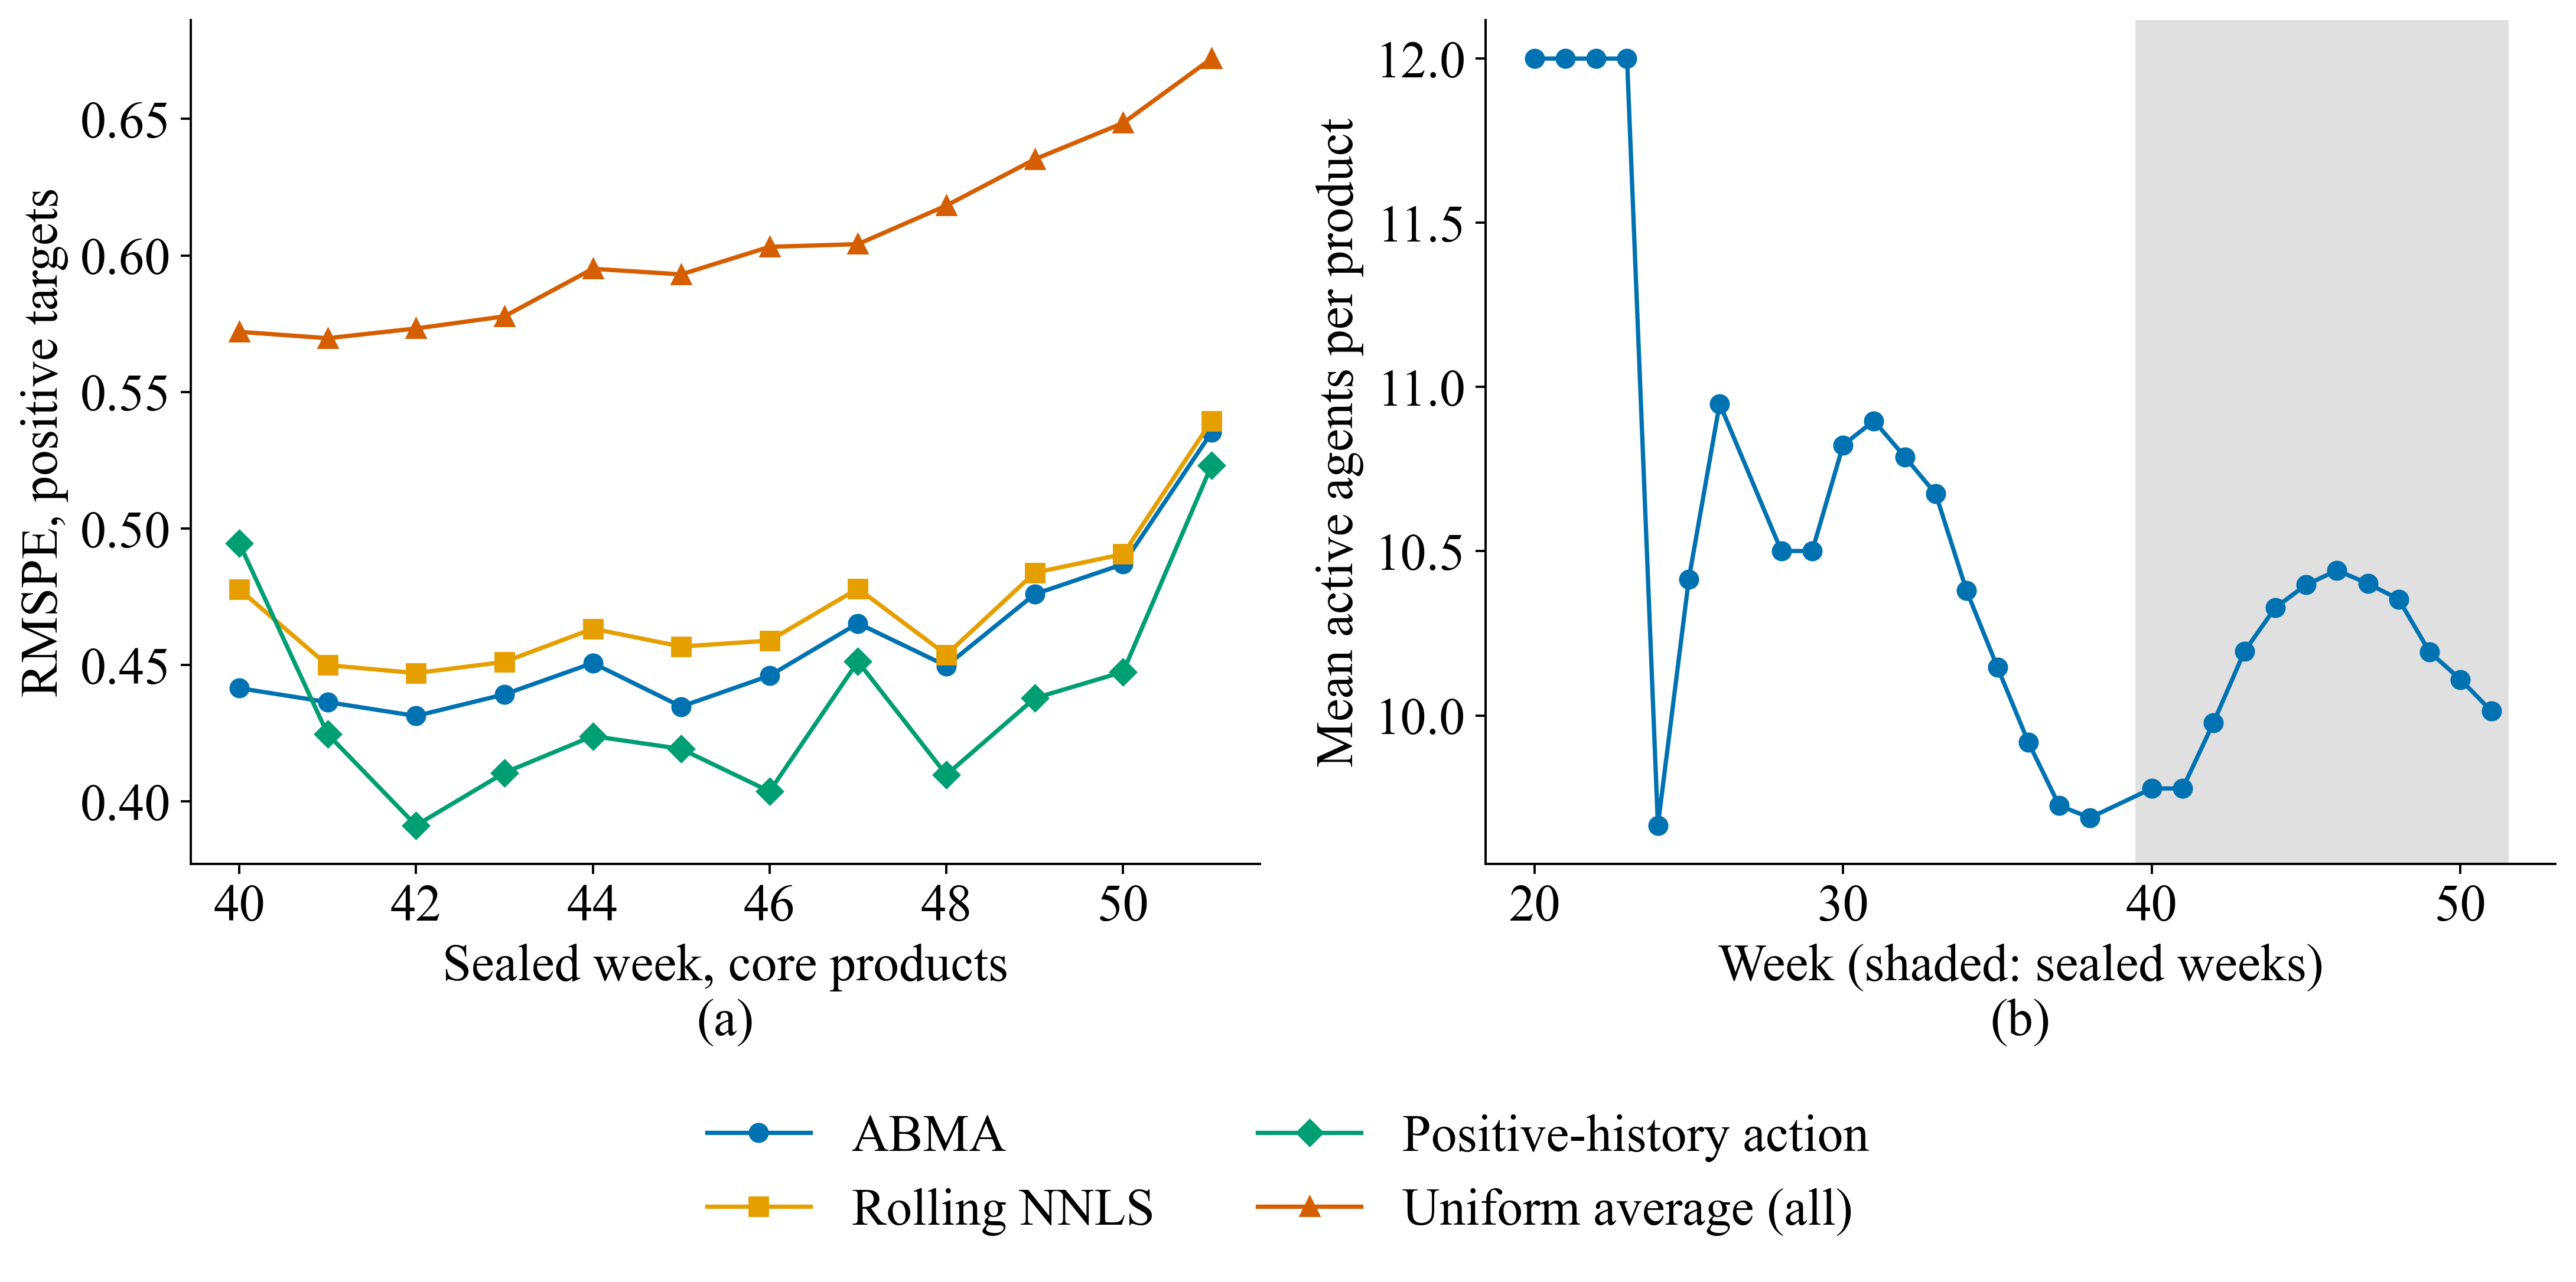

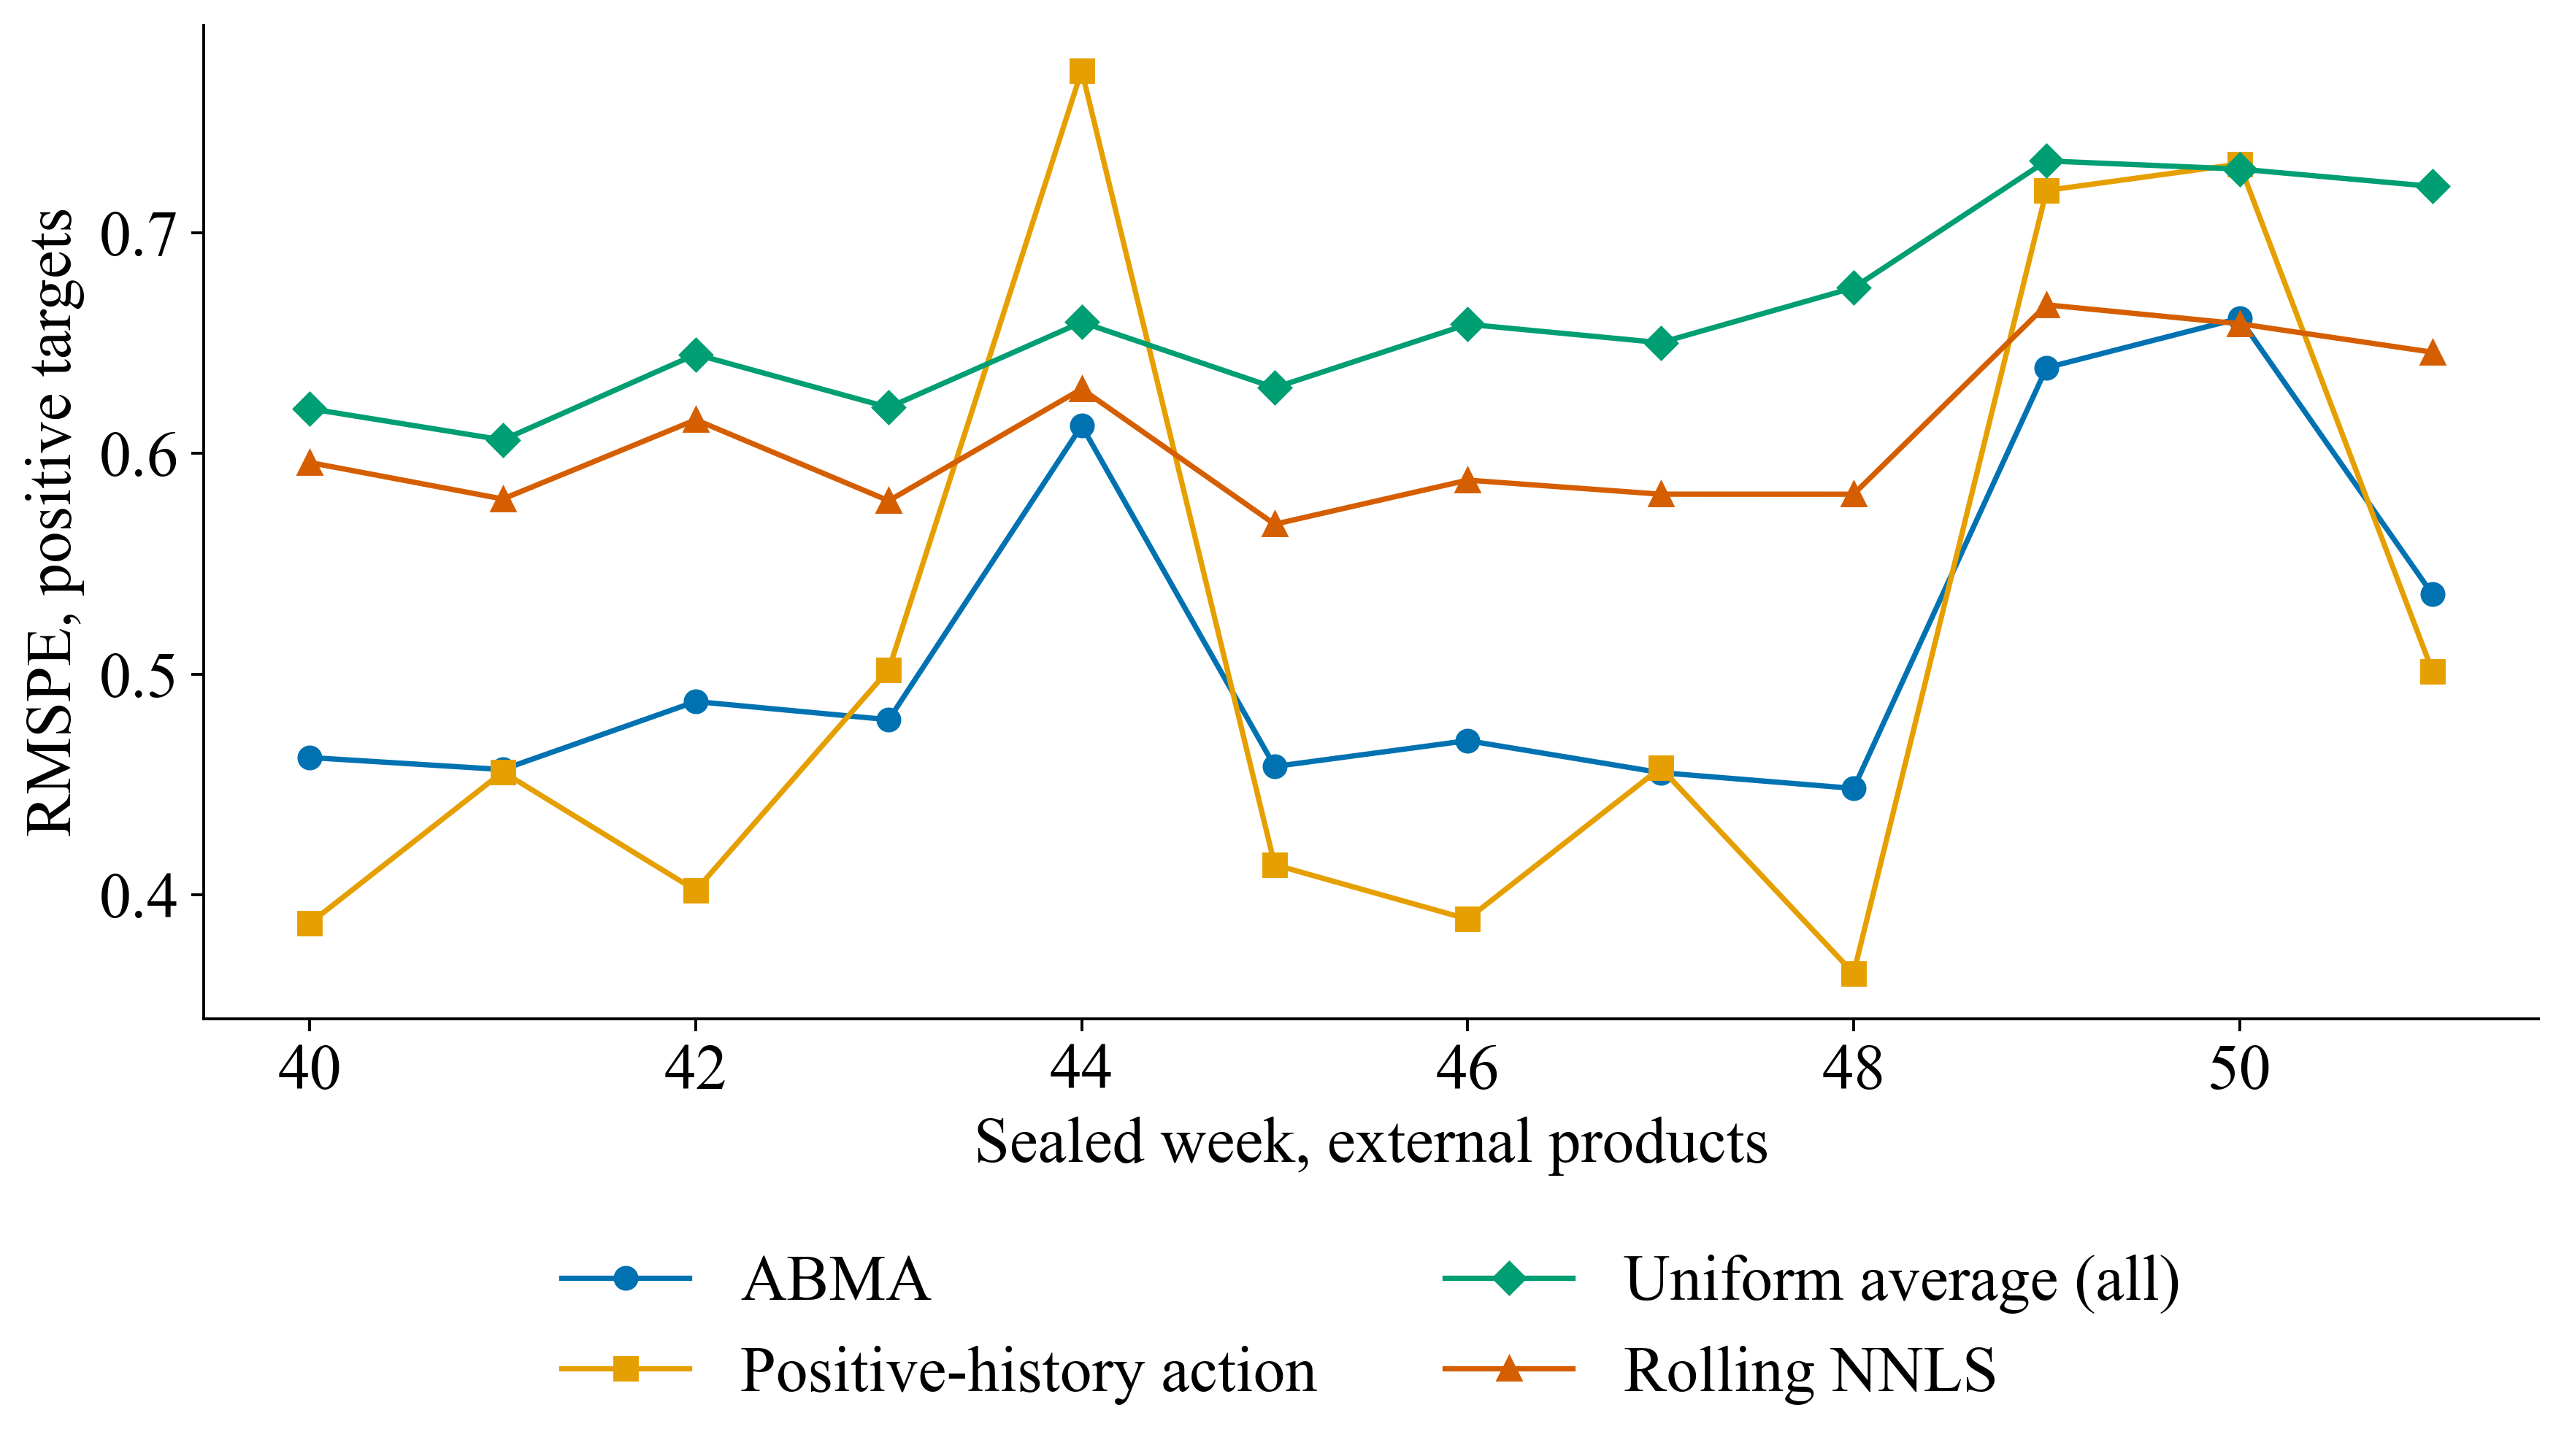

In [10]:
# NB06_DYNAMICS: active agents, weights, weekly RMSPE on both panels
act_T=abma_tr['ACT'][Tm];wT=pd.DataFrame(abma_tr['W'][Tm],columns=AGENTS);frame=pd.DataFrame(abma_tr['ACT'],columns=AGENTS);frame['s']=stream.Store.to_numpy();frame['t']=Tm;off=on=0
for a in AGENTS:
    for _,g in frame[['s','t',a]].groupby('s'):
        v=g[a].to_numpy().astype(int);keep=g['t'].to_numpy()[1:];d=np.diff(v)[keep];off+=int((d==-1).sum());on+=int((d==1).sum())
dyn=pd.DataFrame([{'Mean active agents':float(act_T.sum(1).mean()),'Minimum':int(act_T.sum(1).min()),'Maximum':int(act_T.sum(1).max()),'Deactivations in W40–W51':off,'Reactivations in W40–W51':on}]);table(dyn,'population_sealed',fmt='%.2f')
GATE_FIRED_T=off>0 and on>0
table(pd.DataFrame({'Agent':wT.mean().sort_values(ascending=False).index,'Mean weight':wT.mean().sort_values(ascending=False).to_numpy(),'Active share':pd.DataFrame(act_T,columns=AGENTS).mean().reindex(wT.mean().sort_values(ascending=False).index).to_numpy(),'RMSPE W40–W51':[rmspe(y[Tm],Pq[Tm,AGENTS.index(a)]) for a in wT.mean().sort_values(ascending=False).index]}),'weights_sealed')
BEST_COMB=str(board[board.Model.str.startswith('C: ')&~board.Model.str.contains('Best single')].iloc[0].Model);BEST_B=str(board[board.Model.str.startswith('B: ')].iloc[0].Model)
fig,axes=plt.subplots(1,2,figsize=(12.8,6.4))
for (n,v),col,mk in zip({'ABMA':fc['ABMA'],BEST_COMB[3:]:fc[BEST_COMB],BEST_B[3:]:fc[BEST_B],'Uniform average (all)':fc['C: Uniform average (all agents)']}.items(),PALETTE,'osD^'):axes[0].plot(weeks_T,[rmspe(y[Tm&(wk==w)],v[Tm&(wk==w)]) for w in weeks_T],color=col,marker=mk,label=n)
axes[0].set(xlabel='Sealed week, core products',ylabel='RMSPE, positive targets');axes[0].set_xticks(weeks_T[::2])
weekly_active=pd.DataFrame({'week':wk,'active':abma_tr['ACT'].sum(1)}).groupby('week')['active'].mean()
axes[1].plot(weekly_active.index,weekly_active.to_numpy(),color=PALETTE[0],marker='o');axes[1].axvspan(39.5,51.5,color='0.88',zorder=0);axes[1].set(xlabel='Week (shaded: sealed weeks)',ylabel='Mean active agents per product')
h,l=axes[0].get_legend_handles_labels();label_panels(axes);fig.legend(h,l,loc='lower center',ncol=2,frameon=False);fig.tight_layout(rect=[0,0.14,1,1]);figure(fig,'fig_uci_sealed_weekly_population')
XBEST_B=str(xboard[xboard.Model.str.startswith('B: ')].iloc[0].Model)
fig,ax=plt.subplots(figsize=(10.5,6.2))
for (n,v),col,mk in zip({'ABMA':xfc['ABMA'],XBEST_B[3:]:xfc[XBEST_B],'Uniform average (all)':xfc['C: Uniform average (all agents)'],'Rolling NNLS':xfc['C: Rolling NNLS']}.items(),PALETTE,'osD^'):ax.plot(weeks_T,[rmspe(yx[XT&(wkx==w)],v[XT&(wkx==w)]) for w in weeks_T],color=col,marker=mk,label=n)
ax.set(xlabel='Sealed week, external products',ylabel='RMSPE, positive targets');ax.set_xticks(weeks_T[::2]);ax.legend(loc='upper center',bbox_to_anchor=(0.5,-0.18),ncol=2,frameon=False);fig.tight_layout();figure(fig,'fig_uci_sealed_external_weekly')
weekly_T=pd.DataFrame({k:[rmspe(y[Tm&(wk==w)],v[Tm&(wk==w)]) for w in weeks_T] for k,v in fc.items()},index=weeks_T).rename_axis('Week');weekly_T.reset_index().to_csv(OUT/'weekly_rmspe_sealed.csv',index=False)

### 9. Predictive intervals against the best competitor's nested residual law on identical rows

The comparator interval rescales the nested W20–W26 residuals $(y-p)/\sqrt{p+1}$ of the best baseline at its final-origin forecast.

,Model,PICP90,Coverage error,MPIW90,Interval score,Zero-target coverage,Width ratio to competitor
0,ABMA count-law mixture (frozen scale),0.92581,0.02581,8.21273,12.30738,0.99815,0.80578
1,"Positive-history action, nested residual law",0.94364,0.04364,10.19227,13.37243,1.00000,1.00000


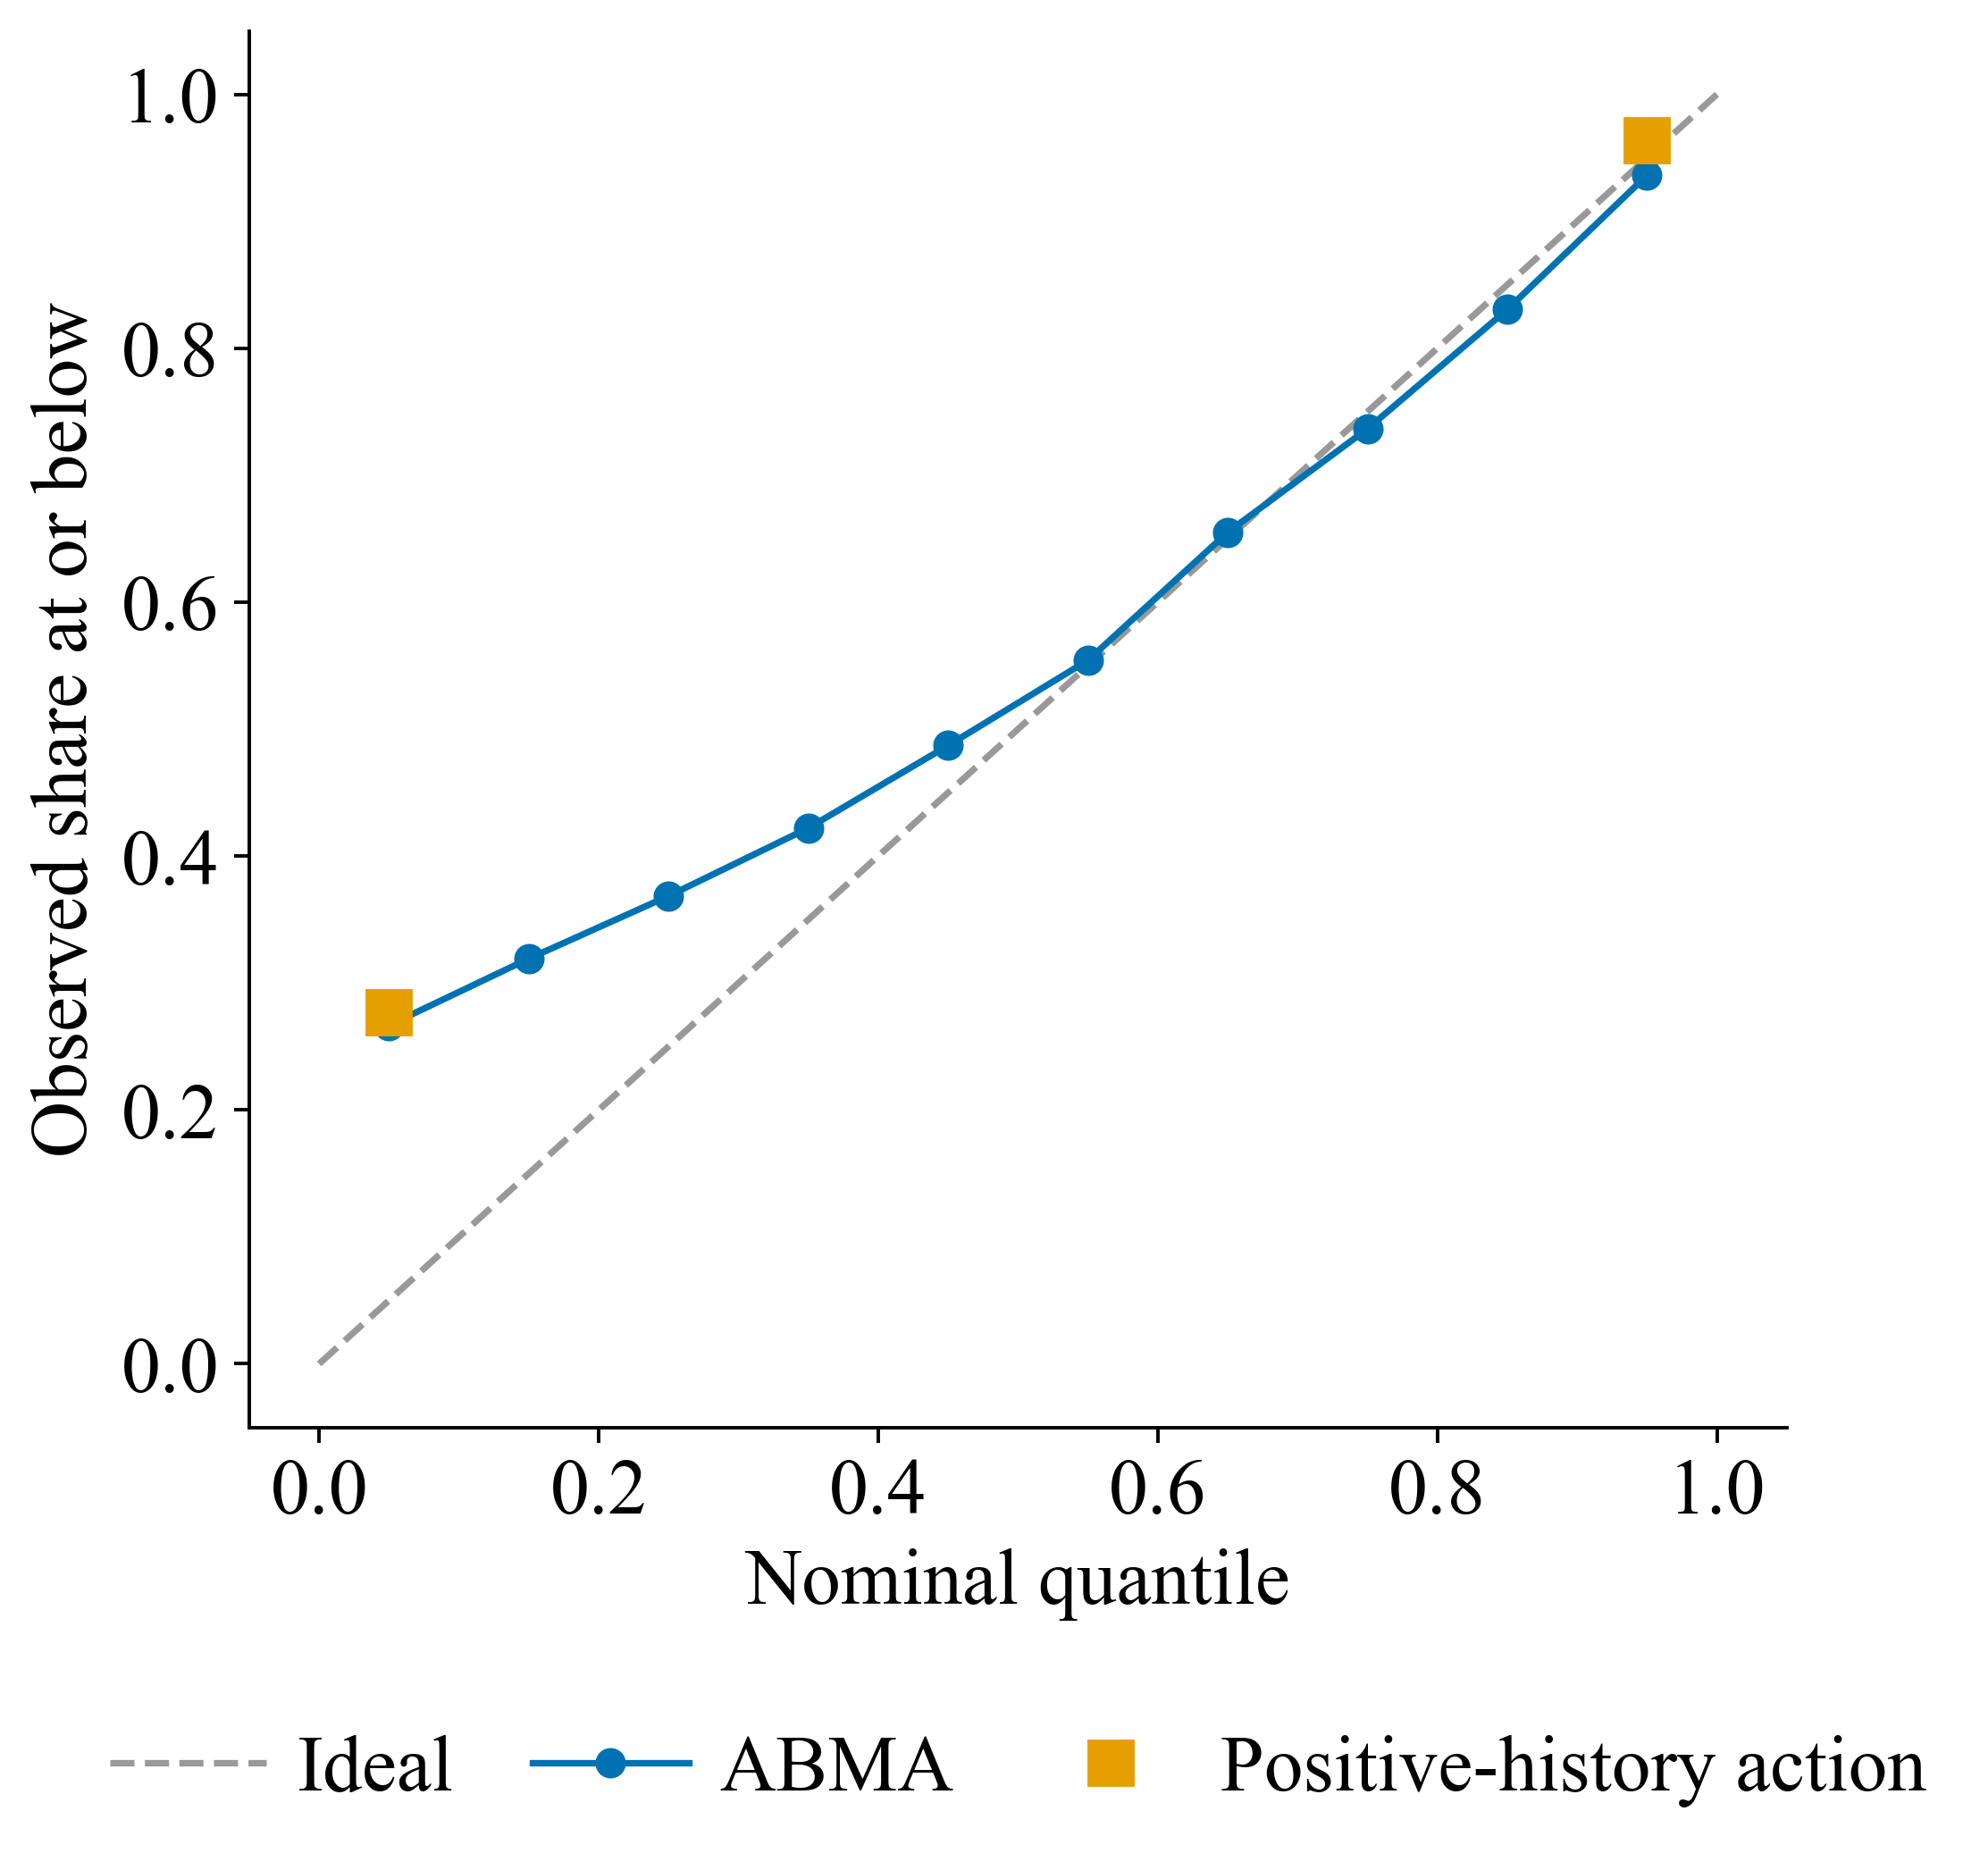

In [11]:
# NB06_INTERVALS: coverage, width and interval score; reliability diagram
def mix_q(mk,q,scale=CTRL['pi_scale']):return mixture_quantile(abma_tr['W'][mk],abma_tr['MU'][mk],abma_tr['SG'][mk],q,count=(abma_tr['P'][mk],abma_tr['LAW']*scale,abma_tr['LAW_IDX'][mk]))
qlo,qhi=mix_q(Tm,0.05),mix_q(Tm,0.95);yT=y[Tm]
best_comp=BEST_B[3:];cal=np.load(NB03_OUT/'nested_residual_calibrators.npz') if best_comp in NB03_MODELS else np.load(NB04_OUT/'nested_residual_calibrators.npz');grid_r=cal[str((NB03_MODELS if best_comp in NB03_MODELS else NB04_MODELS).index(best_comp))]
pc_=Pq[Tm,AGENTS.index(best_comp)];draws=np.maximum(0,np.rint(pc_[:,None]+np.sqrt(pc_[:,None]+1)*grid_r[None,:]));clo,chi=np.quantile(draws,[.05,.95],axis=1,method='inverted_cdf')
def interval_row(name,lo,hi):
    cov=float(np.mean((yT>=lo)&(yT<=hi)));return {'Model':name,'PICP90':cov,'Coverage error':abs(cov-0.9),'MPIW90':float(np.mean(hi-lo)),'Interval score':float(np.mean((hi-lo)+20*np.maximum(lo-yT,0)+20*np.maximum(yT-hi,0))),'Zero-target coverage':float(np.mean(lo[yT==0]<=0))}
pi=pd.DataFrame([interval_row('ABMA count-law mixture (frozen scale)',qlo,qhi),interval_row(f'{best_comp}, nested residual law',clo,chi)]);pi['Width ratio to competitor']=pi['MPIW90']/pi['MPIW90'].iloc[1]
table(pi,'intervals_sealed')
pc=np.linspace(.05,.95,10);cov_curve=[float((yT<=mix_q(Tm,q)).mean()) for q in pc]
fig,ax=plt.subplots(figsize=(6.6,6.4));ax.plot([0,1],[0,1],color='0.6',ls='--',label='Ideal');ax.plot(pc,cov_curve,color=PALETTE[0],marker='o',label='ABMA');ax.plot([0.05,0.95],[(yT<=clo).mean(),(yT<=chi).mean()],ls='none',marker='s',ms=10,color=PALETTE[1],label=best_comp)
ax.set(xlabel='Nominal quantile',ylabel='Observed share at or below');ax.legend(loc='upper center',bbox_to_anchor=(0.5,-0.17),ncol=3,frameon=False,columnspacing=1.0,handletextpad=0.4);fig.tight_layout();figure(fig,'fig_uci_sealed_reliability')

### 10. Component evidence and forest plot

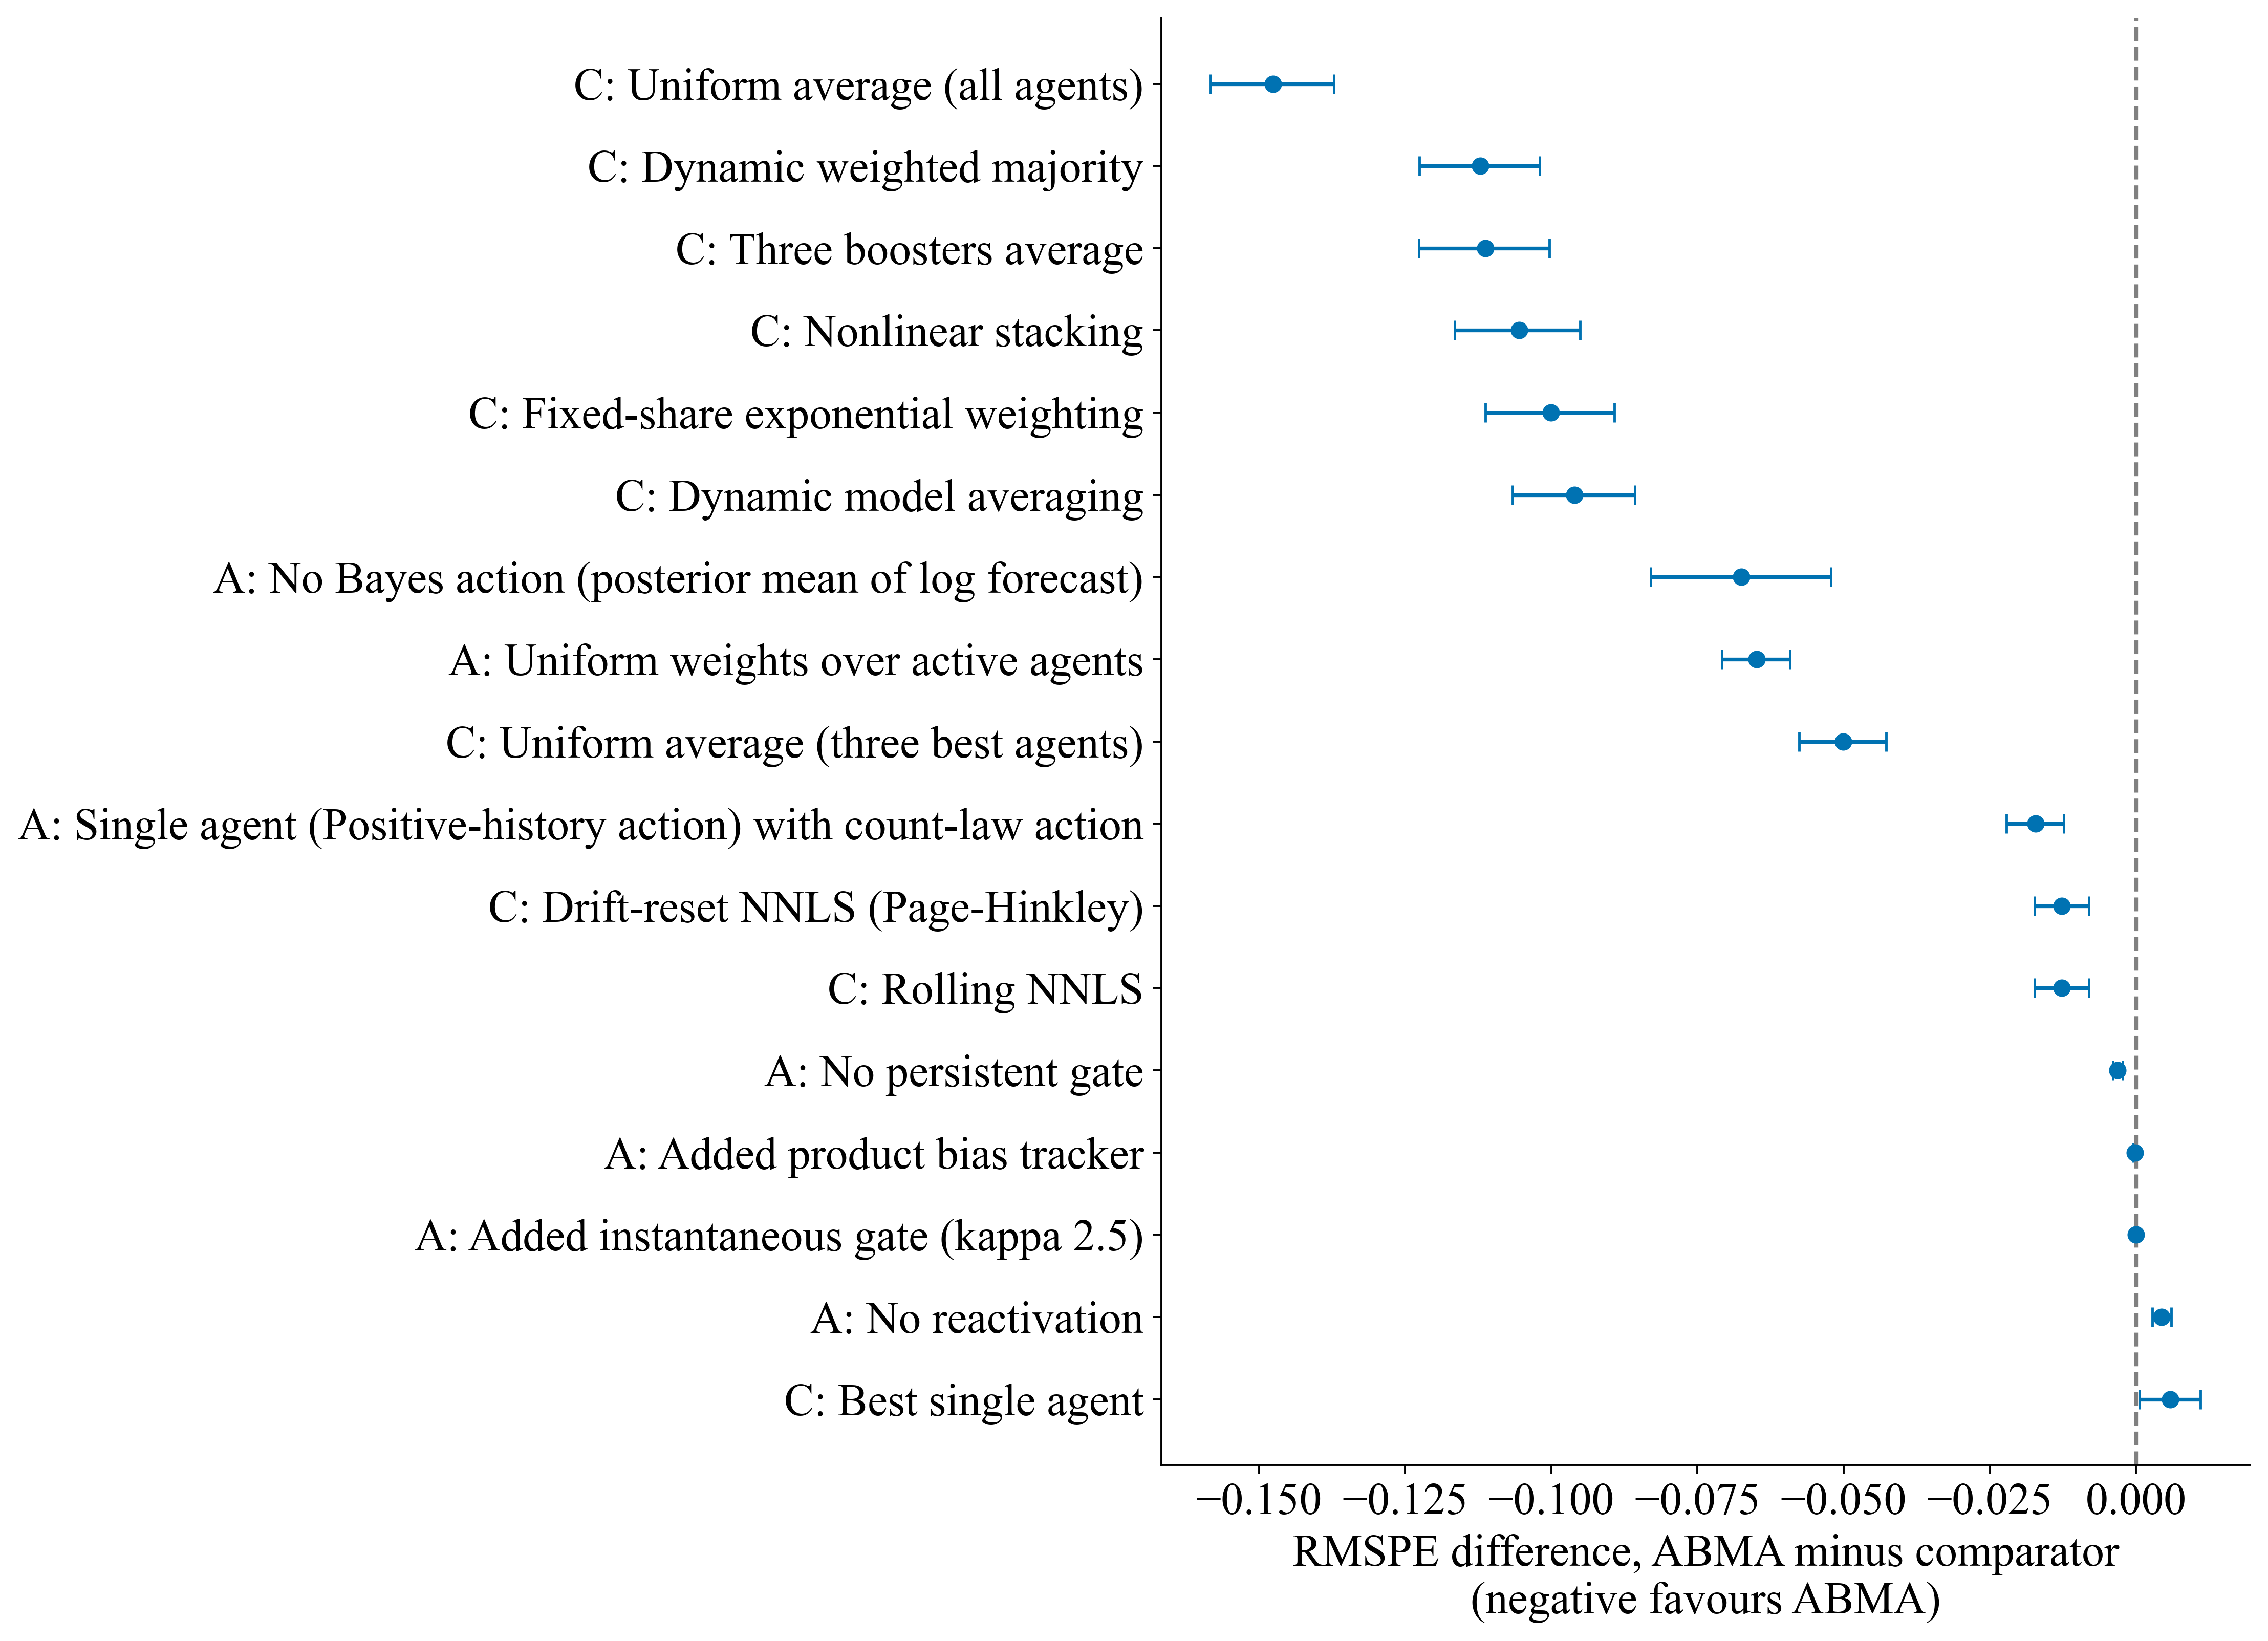

,Component removed,Kind,Difference (ABMA - ablation),Holm p (all comparators),Significantly worse without it
0,No Bayes action (posterior mean of log forecast),protected,-0.06750,0.0058,True
1,Uniform weights over active agents,protected,-0.06484,0.0058,True
2,No persistent gate,protected,-0.00314,0.0058,True
3,No reactivation,protected,0.00437,0.0058,False


In [12]:
# NB06_FOREST: ablations and controls against ABMA with bootstrap intervals
keys=[k for k in pair_T['Comparator'] if k.startswith(('A:','C:'))];pf=pair_T.set_index('Comparator').loc[keys].sort_values('Difference (ABMA - comparator)',ascending=False)
fig,ax=plt.subplots(figsize=(13,9.5));yy=np.arange(len(pf))
ax.errorbar(pf['Difference (ABMA - comparator)'],yy,xerr=[pf['Difference (ABMA - comparator)']-pf['CI low'],pf['CI high']-pf['Difference (ABMA - comparator)']],fmt='o',color=PALETTE[0],capsize=4)
ax.axvline(0,color='0.5',ls='--');ax.set_yticks(yy,list(pf.index));ax.set(xlabel='RMSPE difference, ABMA minus comparator\n(negative favours ABMA)');fig.tight_layout();figure(fig,'fig_uci_sealed_forest')
MECH=list(PROTECTED)
component=pd.DataFrame({'Component removed':MECH,'Kind':['protected']*4,'Difference (ABMA - ablation)':[pair_T.set_index('Comparator').loc['A: '+m,'Difference (ABMA - comparator)'] for m in MECH],'Holm p (all comparators)':[pair_T.set_index('Comparator').loc['A: '+m,'Holm p'] for m in MECH],'Significantly worse without it':[bool(pair_T.set_index('Comparator').loc['A: '+m,'Difference (ABMA - comparator)']<0 and pair_T.set_index('Comparator').loc['A: '+m,'Holm p']<0.05) for m in MECH]})
table(component,'component_sealed')

In [13]:
# NB06_SAVE: forecasts of every model on the sealed rows
stream[['row_id','Product_Code','week','quantity','block']].assign(**{k:v for k,v in fc.items()}).to_parquet(OUT/'sealed_forecasts_core.parquet',index=False)
xs[['row_id','Product_Code','week','quantity','block']].assign(**{k:v for k,v in xfc.items()}).to_parquet(OUT/'sealed_forecasts_external.parquet',index=False)

# Part C · M5 (Walmart) weekly item-store sales

## Sealed evaluation of the count-law model on weeks 265–276 and on the external series

Core weeks 265–276 are the primary panel; the 3,049 external series, never used for fitting, are the secondary panel.

In [1]:
# NB06_SETUP: inputs, packages and helpers (same conventions as NB01-NB05 of this panel)
import os
os.environ['OMP_NUM_THREADS']='4';os.environ['OPENBLAS_NUM_THREADS']='4'
import json,hashlib,time,platform,sys,resource,gzip,importlib.metadata,inspect,warnings,io,csv,zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import cloudpickle
from IPython.display import display,Markdown,Image
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib import font_manager
from threadpoolctl import threadpool_limits,threadpool_info
from scipy import special,stats
THREAD_LIMIT=threadpool_limits(limits=4)
SEED=2026
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'dataset').is_dir() and (p/'notebooks').is_dir())
BASE=ROOT/'outputs'/'m5'
for _d in ('Artifacts','Manifests','Configs'):(BASE/_d).mkdir(parents=True,exist_ok=True)
RUN_ID='NB06_M5_'+pd.Timestamp.now(tz='UTC').strftime('%Y%m%dT%H%M%S%fZ');OUT=BASE/'Artifacts'/RUN_ID;OUT.mkdir(parents=True,exist_ok=True)
def dump(p,v):p.write_text(json.dumps(v,indent=2,allow_nan=False,default=str))
LATEST=json.loads((BASE/'Manifests/latest_runs.json').read_text()) if (BASE/'Manifests/latest_runs.json').exists() else {}
FONT=font_manager.findfont('Times New Roman',fallback_to_default=False)
plt.rcParams.update({'font.family':'Times New Roman','font.size':18,'axes.labelsize':18,'axes.titlesize':20,'xtick.labelsize':18,'ytick.labelsize':18,'legend.fontsize':18,'figure.dpi':350,'savefig.dpi':350,'pdf.fonttype':42,'axes.unicode_minus':True,'axes.spines.top':False,'axes.spines.right':False,'mathtext.fontset':'custom','mathtext.rm':'Times New Roman','mathtext.it':'Times New Roman:italic','mathtext.bf':'Times New Roman:bold','mathtext.default':'regular'})
PALETTE=['#0072B2','#E69F00','#009E73','#D55E00','#CC79A7','#56B4E9','#000000']  # Okabe-Ito, colour-blind safe
pd.set_option('display.max_rows',200,'display.max_columns',20,'display.max_colwidth',None,'display.width',220,'display.float_format',lambda v:f'{v:.5f}')
def tidy(df,note='n/a'):
    """Display copy of a table: missing cells are marked explicitly instead of NaN; underflowed p-values are shown as bounds."""
    out=df.copy()
    for c in out.columns:
        if str(c)=='p' or str(c).startswith('p ') or 'p-value' in str(c) or str(c).startswith('Holm p'):
            out[c]=['< 1e-300' if (isinstance(v,float) and v==0.0) else (f'{v:.4g}' if isinstance(v,(float,np.floating)) else v) for v in out[c]]
    return out.astype(object).where(out.notna(),note)
def table(df,name,best=None,fmt='%.5f'):
    clean=tidy(df.reset_index() if df.index.name is not None else df)
    clean.to_csv(OUT/(name+'.csv'),index=False);(OUT/(name+'.tex')).write_text(clean.to_latex(index=False,float_format=fmt,escape=True))
    if best:display(clean.style.format({k:(lambda v:(fmt%v) if isinstance(v,(float,np.floating)) else v) for k in best}).highlight_min(subset=best,props='font-weight:bold;'))
    else:display(clean)
def figure(fig,name):
    for ext,dpi in [('pdf',350),('png',350),('png',600)]:fig.savefig(OUT/(name+('_600dpi' if dpi==600 else '')+'.'+ext),dpi=dpi,bbox_inches='tight')
    plt.close(fig);display(Image(filename=str(OUT/(name+'.png')),width=900))
def label_panels(axes,labels='abcdefgh'):
    """Letter each panel below its x-axis label, (a), (b), ..., so that panels can be cited."""
    for ax,l in zip(np.ravel(axes),labels):ax.set_xlabel((ax.get_xlabel()+'\n' if ax.get_xlabel() else '')+f'({l})')
def metrics(y,p):
    y=np.asarray(y,float);p=np.asarray(p,float);assert len(y)==len(p) and np.isfinite(p).all() and (p>=0).all()
    positive=y>0;zero=~positive;den=np.abs(y)+np.abs(p);sm=np.divide(2*np.abs(y-p),den,out=np.zeros(len(y)),where=den>0)
    return {'RMSPE':float(np.sqrt(np.mean(((p[positive]-y[positive])/y[positive])**2))),'RMSE':float(np.sqrt(np.mean((p-y)**2))),'MAE':float(np.mean(np.abs(p-y))),'sMAPE_pct':float(100*sm.mean()),'R2':float(1-np.sum((p-y)**2)/np.sum((y-y.mean())**2)),'Zero_MAE':float(np.mean(p[zero])) if zero.any() else 0.,'Positive_n':int(positive.sum()),'Zero_n':int(zero.sum())}
def rmspe(y,p):
    y=np.asarray(y,float);p=np.asarray(p,float);m=y>0;return float(np.sqrt(np.mean(((p[m]-y[m])/y[m])**2)))

import torch,torch.nn as nn,torch.nn.functional as F
from sklearn.preprocessing import QuantileTransformer
from sklearn.linear_model import Ridge,PoissonRegressor
from sklearn.ensemble import RandomForestRegressor
import lightgbm as lgb
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from scipy.optimize import nnls
import tracemalloc
torch.set_num_threads(4);DEVICE=torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
PLAN=json.loads((BASE/'Configs/baseline_search.json').read_text());FM=json.loads((BASE/'Manifests/feature_manifest.json').read_text());BM=json.loads((BASE/'Manifests/baseline_manifest.json').read_text());NM=json.loads((BASE/'Manifests/network_manifest.json').read_text())
CTRL=json.loads((BASE/'Configs/m5_frozen_controls.json').read_text());FROZEN_B=json.loads((BASE/'Configs/m5_frozen_b.json').read_text());CONTRACT=json.loads((BASE/'Configs/feature_contract.json').read_text());DESIGN=json.loads((BASE/'Configs/study_design.json').read_text())
NB03_OUT,NB04_OUT,NB05_OUT=(BASE/'Artifacts'/r for r in (BM['run_id'],NM['run_id'],LATEST['NB05']))
FROZEN=json.loads((ROOT/'outputs'/'configs'/'abma_frozen.json').read_text())
RAW=ROOT/'dataset'/'raw'/'m5'/'m5-forecasting-accuracy.zip'

### 1. Frozen configurations of arms A and B

In [2]:
# ABMA engine: every label of date d enters the state only at date d + lag.
from scipy import special

ABMA_DEFAULT = dict(lag=7, nctx=14, clip=0.5, sig_floor=0.03, sig_scale=1.0, disc_var=0.995, store_sigma=True,
                    bias_mode="none", q=1e-6, p0=5e-4,
                    weight_mode="global", eta=0.5, disc_w=0.98, store_shrink=30.0,
                    gate_on=True, reactivate=True, theta0=0.5, gate_p=0.7, disc_beta=0.98, min_active=3, kappa=2.5,
                    action="bayes", dispersion=True, gate_loss="log",
                    law="lognormal", n_res=257, disc_res=0.98, smooth=0.5)


def abma_run(stream, P, cfg=None):
    """stream: Store, Date, Sales, ctx sorted by Date; P: n x K positive agent forecasts (NaN = agent absent).
    law = "lognormal": the predictive law of each agent is lognormal on log Sales (positive continuous targets).
    law = "count": Sales and P are non-negative counts; the lognormal state works on log(1 + count) and the predictive law of each agent is an
    empirical count law, y = max(0, round(p + sqrt(p + 1) r)) with r drawn from a discounted chain-wide reservoir of the agent's scaled residuals
    (n_res weighted quantiles, discount disc_res); the weights use the log predictive mass of the observed count (Laplace smoothing `smooth`) and
    the Bayes action under the positive-target relative loss is E[1/y; y > 0] / E[1/y^2; y > 0] of the mixture of count laws."""
    c = {**ABMA_DEFAULT, **(cfg or {})}
    n, K = P.shape
    N = c["nctx"]
    si = np.unique(stream["Store"].to_numpy(), return_inverse=True)[1]
    S = si.max() + 1
    dates, di = np.unique(stream["Date"].to_numpy(), return_inverse=True)
    day = dates.astype("datetime64[D]").astype(int)
    COUNT = c["law"] == "count"
    if COUNT:
        Pq = np.asarray(P, float)
        yq = stream["Sales"].to_numpy(float)
        y = np.log1p(yq)
        lp = np.log1p(Pq)
        NQ = int(c["n_res"])
        qgrid = (np.arange(NQ) + 0.5) / NQ
        rsv = [np.zeros(0) for _ in range(K)]
        rsv_w = [np.zeros(0) for _ in range(K)]
        law_q = np.full((K, NQ), np.nan)
        LAW = np.full((len(dates), K, NQ), np.nan)

        def law_update(k):
            o = np.argsort(rsv[k])
            cw = np.cumsum(rsv_w[k][o])
            cw /= cw[-1]
            return np.interp(qgrid, cw, rsv[k][o])

        def law_draws(k, ix):
            return np.maximum(0.0, np.rint(Pq[ix, k][:, None] + np.sqrt(Pq[ix, k][:, None] + 1.0) * law_q[k][None, :]))
    else:
        y = np.log(stream["Sales"].to_numpy(float))
        lp = np.log(P)
    C = stream["ctx"].to_numpy()
    bias, bias_var = np.zeros((S, K)), np.full((S, K), c["p0"])
    v_n, v_s = np.full((S, K), 5.0), np.full((S, K), 5 * 0.02)
    ctx_n, ctx_s = np.ones((N, K)), np.ones((N, K))
    L_g, L_s, n_s = np.zeros((N, K)), np.zeros((S, N, K)), np.zeros((S, N))
    a, b = np.ones((S, K)), np.ones((S, K))
    latched = np.zeros((S, K), bool)
    out = np.zeros(n)
    W, MU, SG = np.zeros((n, K), np.float32), np.zeros((n, K)), np.zeros((n, K))
    ACT = np.zeros((n, K), bool)
    days = [np.where(di == d)[0] for d in range(len(dates))]
    ptr = 0
    for d, ix in enumerate(days):
        while ptr < d and day[ptr] <= day[d] - c["lag"]:
            jx = days[ptr]
            ptr += 1
            s, cc, yy = si[jx], C[jx], y[jx][:, None]
            mu, sg, ok = MU[jx], np.maximum(SG[jx], 1e-3), ~np.isnan(lp[jx])
            ll = np.where(ok, np.maximum(-0.5 * ((yy - mu) / sg) ** 2 - np.log(sg), -12.0), 0.0)
            if COUNT:  # log predictive mass of the observed count under each agent's count law (lognormal score until the law exists)
                for k in range(K):
                    if np.isnan(law_q[k, 0]):
                        continue
                    hits = (np.abs(law_draws(k, jx) - yq[jx][:, None]) < 0.5).mean(1) * NQ
                    ll[:, k] = np.where(ok[:, k], np.log((hits + c["smooth"]) / (NQ + c["smooth"])), 0.0)
                r_new = np.where(ok, (yq[jx][:, None] - np.nan_to_num(Pq[jx])) / np.sqrt(np.nan_to_num(Pq[jx]) + 1.0), np.nan)
                for k in range(K):
                    rk = r_new[ok[:, k], k]
                    if len(rk) == 0:
                        continue
                    rsv[k] = np.concatenate([rsv[k], rk])
                    rsv_w[k] = np.concatenate([rsv_w[k] * c["disc_res"], np.ones(len(rk))])
                    if len(rsv[k]) > 40 * NQ:
                        rsv[k] = law_update(k)
                        rsv_w[k] = np.full(NQ, rsv_w[k].sum() / NQ)
                    law_q[k] = law_update(k)
            L_s[s, cc] = c["disc_w"] * L_s[s, cc] + ll
            n_s[s, cc] = c["disc_w"] * n_s[s, cc] + 1
            for x in np.unique(cc):
                L_g[x] = c["disc_w"] * L_g[x] + ll[cc == x].mean(0)
            if c.get("gate_loss", "log") == "log":  # default criterion: absolute log error
                ae = np.where(ok, np.abs(yy - mu), np.nan)
            else:  # alternative criterion: squared relative error of the point forecast, the loss of the Bayes action
                ae = np.where(ok, (np.exp(mu - yy) - 1) ** 2, np.nan)
            win = ae <= np.nanmedian(ae, axis=1, keepdims=True)
            keep = 1 - c["disc_beta"]
            a[s] = c["disc_beta"] * a[s] + keep + (win & ok)
            b[s] = c["disc_beta"] * b[s] + keep + (~win & ok)
            e = yy - lp[jx]
            for k in range(K):
                o = ok[:, k]
                sk = s[o]
                r = np.maximum(v_s[sk, k] / v_n[sk, k], 1e-4)
                pp = bias_var[sk, k] + c["q"]
                gain = pp / (pp + r)
                bias[sk, k] += gain * np.clip(e[o, k] - bias[sk, k], -c["clip"], c["clip"])
                bias_var[sk, k] = (1 - gain) * pp
                res = yy[o, 0] - (lp[jx][o, k] + (bias[sk, k] if c["bias_mode"] == "agent" else 0.0))
                sq = np.minimum(res ** 2, c["clip"] ** 2)
                v_n[sk, k] = c["disc_var"] * v_n[sk, k] + 1
                v_s[sk, k] = c["disc_var"] * v_s[sk, k] + sq
                for x in np.unique(cc[o]):
                    u = cc[o] == x
                    ctx_n[x, k] = 0.99 * ctx_n[x, k] + 1
                    ctx_s[x, k] = 0.99 * ctx_s[x, k] + (sq[u] / np.maximum(v_s[sk[u], k] / v_n[sk[u], k], 1e-4)).mean()
        s, cc = si[ix], C[ix]
        mu = lp[ix] + (bias[s] if c["bias_mode"] == "agent" else 0.0)
        var = v_s[s] / v_n[s] if c["store_sigma"] else np.broadcast_to((v_s / v_n).mean(0), (len(ix), K))
        sg = c["sig_scale"] * np.maximum(np.sqrt(var * ctx_s[cc] / ctx_n[cc]), c["sig_floor"])
        MU[ix], SG[ix] = mu, sg
        A = ~np.isnan(lp[ix])
        if c["gate_on"]:
            pl = special.betainc(a[s], b[s], c["theta0"])
            g = pl < c["gate_p"]
            if not c["reactivate"]:
                latched[s] |= ~g
                g = ~latched[s]
            few = g.sum(1) < c["min_active"]
            if few.any():
                best = np.argsort(pl[few], axis=1)[:, : c["min_active"]]
                gf = np.zeros((few.sum(), K), bool)
                np.put_along_axis(gf, best, True, axis=1)
                g[few] = gf
            A = A & g
        if c["kappa"] > 0:  # instantaneous gate: an active agent far from the consensus of the active pool is switched off for this row
            mu_act = np.where(A, np.nan_to_num(mu), np.nan)
            consensus = np.nanmedian(mu_act, axis=1, keepdims=True)
            pool_sd = np.sqrt(np.nanmedian(np.where(A, sg ** 2, np.nan), axis=1, keepdims=True))
            far = np.abs(np.nan_to_num(mu) - consensus) > c["kappa"] * np.maximum(sg, pool_sd)
            A2 = A & ~far
            A = np.where((A2.sum(1) >= c["min_active"])[:, None], A2, A)
        ACT[ix] = A
        if c["weight_mode"] == "uniform":
            lw = np.zeros((len(ix), K))
        elif c["weight_mode"] == "global":
            lw = np.repeat(c["eta"] * L_g.mean(0, keepdims=True), len(ix), 0)
        elif c["weight_mode"] == "context":
            lam = (n_s[s, cc] / (n_s[s, cc] + c["store_shrink"]))[:, None]
            lw = c["eta"] * (L_g[cc] + lam * (L_s[s, cc] - L_g[cc]))
        lw = np.where(A, lw, -np.inf)
        lw -= lw.max(1, keepdims=True)
        w = np.exp(lw)
        w /= w.sum(1, keepdims=True)
        W[ix] = w
        m0 = np.nan_to_num(mu)
        if COUNT:
            LAW[d] = law_q
            num, den = np.zeros(len(ix)), np.zeros(len(ix))
            for k in range(K):
                if np.isnan(law_q[k, 0]):  # no residual history yet: lognormal fallback on the shifted scale
                    num += w[:, k] * np.exp(-m0[:, k] + 0.5 * sg[:, k] ** 2)
                    den += w[:, k] * np.exp(-2 * m0[:, k] + 2 * sg[:, k] ** 2)
                    continue
                yk = law_draws(k, ix)
                inv = np.where(yk > 0, 1.0 / np.where(yk > 0, yk, 1.0), 0.0)
                num += w[:, k] * inv.mean(1)
                den += w[:, k] * (inv ** 2).mean(1)
            if c["action"] == "bayes":
                out[ix] = np.where(den > 0, num / np.maximum(den, 1e-300), np.nan_to_num(Pq[ix]).mean(1))
            else:
                out[ix] = np.expm1((w * m0).sum(1))
            continue
        if c["action"] == "bayes":
            s2 = sg if c["dispersion"] else np.full_like(sg, np.sqrt((w * sg ** 2).sum(1, keepdims=True)))
            out[ix] = (w * np.exp(-m0 + 0.5 * s2 ** 2)).sum(1) / (w * np.exp(-2 * m0 + 2 * s2 ** 2)).sum(1)
        else:
            out[ix] = np.exp((w * m0).sum(1))
    if COUNT:
        return out, dict(W=W, MU=MU, SG=SG, ACT=ACT, LAW=LAW, LAW_IDX=di, P=Pq)
    return out, dict(W=W, MU=MU, SG=SG, ACT=ACT)


def mixture_quantile(W, MU, SG, q, iters=40, count=None):
    """Quantile of the lognormal mixture, by bisection in log sales; with `count` = (P, LAW, LAW_IDX) from a count-law run, the weighted quantile of the mixture of empirical count laws (rows without a law fall back to the lognormal quantile minus one, clipped at zero)."""
    if count is not None:
        Pq, LAW, idx = count
        n, K = Pq.shape
        NQ = LAW.shape[2]
        out = np.full(n, np.nan)
        for a in range(0, n, 2048):
            ix = np.arange(a, min(n, a + 2048))
            lq = LAW[idx[ix]]
            ok = ~np.isnan(lq[:, :, 0])
            draws = np.maximum(0.0, np.rint(Pq[ix][:, :, None] + np.sqrt(Pq[ix][:, :, None] + 1.0) * np.nan_to_num(lq)))
            wts = np.where(ok, W[ix], 0.0)[:, :, None] * np.ones((1, 1, NQ)) / NQ
            flat = draws.reshape(len(ix), -1)
            wf = wts.reshape(len(ix), -1)
            o = np.argsort(flat, axis=1)
            fs = np.take_along_axis(flat, o, 1)
            cw = np.cumsum(np.take_along_axis(wf, o, 1), axis=1)
            tot = cw[:, -1:]
            pos = (cw >= q * tot).argmax(1)
            val = fs[np.arange(len(ix)), pos]
            none = tot[:, 0] <= 0
            if none.any():
                val[none] = np.maximum(0.0, _lognormal_quantile(W[ix][none], MU[ix][none], SG[ix][none], q, iters) - 1.0)
            out[ix] = val
        return out
    return _lognormal_quantile(W, MU, SG, q, iters)


def _lognormal_quantile(W, MU, SG, q, iters=40):
    lo, hi = (MU - 6 * SG).min(1), (MU + 6 * SG).max(1)
    for _ in range(iters):
        mid = (lo + hi) / 2
        cdf = (W * special.ndtr((mid[:, None] - MU) / SG)).sum(1)
        lo, hi = np.where(cdf < q, mid, lo), np.where(cdf < q, hi, mid)
    return np.exp((lo + hi) / 2)


# Streaming combiners from the data-stream literature, used as controls; they are not part of the frozen model and are outside the engine hash.
def _stream_index(stream):
    si = np.unique(stream["Store"].to_numpy(), return_inverse=True)[1]
    dates, di = np.unique(stream["Date"].to_numpy(), return_inverse=True)
    day = dates.astype("datetime64[D]").astype(int)
    return si, si.max() + 1, day, [np.where(di == d)[0] for d in range(len(dates))]


def fixed_share(stream, P, y, eta=10.0, alpha=0.01, scope="store", lag=7):
    """Fixed-share exponentially weighted average (Herbster and Warmuth, 1998): weights proportional to exp(-eta * cumulative loss) with a share alpha of the mass redistributed uniformly at every update; loss = squared relative error of the point forecast clipped at 1; weights per store or chain-wide; the log forecasts are combined; labels of day d enter at day d + lag."""
    n, K = P.shape
    lp, ly = np.log(P), np.log(y)
    si, S, day, days = _stream_index(stream)
    LW = np.zeros((S if scope == "store" else 1, K))
    out = np.zeros(n)
    ptr = 0
    for d, ix in enumerate(days):
        while ptr < d and day[ptr] <= day[d] - lag:
            jx = days[ptr]
            ptr += 1
            ok = ~np.isnan(lp[jx])
            loss = np.where(ok, np.minimum((np.exp(lp[jx] - ly[jx][:, None]) - 1) ** 2, 1.0), 0.0)
            r = si[jx] if scope == "store" else np.zeros(1, int)
            if scope == "store":
                LW[r] -= eta * loss
            else:
                LW[0] -= eta * loss.mean(0)
            if alpha > 0:
                w = np.exp(LW[r] - LW[r].max(1, keepdims=True))
                w /= w.sum(1, keepdims=True)
                LW[r] = np.log((1 - alpha) * w + alpha / K)
        r = si[ix] if scope == "store" else np.zeros(len(ix), int)
        lw = np.where(~np.isnan(lp[ix]), LW[r], -1e9)
        lw -= lw.max(1, keepdims=True)
        w = np.exp(lw)
        w /= w.sum(1, keepdims=True)
        out[ix] = np.exp((w * np.nan_to_num(lp[ix])).sum(1))
    return out


def dwm(stream, P, y, beta=0.5, theta=0.01, eps=0.1, period=1, lag=7):
    """Dynamic weighted majority (Kolter and Maloof, 2007) adapted to a fixed pool of regression agents with store-specific weights: an agent errs on a day when its absolute relative error exceeds eps and its weight is multiplied by beta; every `period` days the weights are normalised to a maximum of one, agents below theta are removed, and if the ensemble itself erred in the period the removed agents are re-admitted with weight theta (the original creates a new learner there; the pool is fixed). Forecast = weighted mean of the log forecasts of the admitted agents; labels of day d enter at day d + lag."""
    n, K = P.shape
    lp, ly = np.log(P), np.log(y)
    si, S, day, days = _stream_index(stream)
    W, REM = np.ones((S, K)), np.zeros((S, K), bool)
    ens_err, n_days = np.zeros(S, bool), np.zeros(S, int)
    out = np.zeros(n)
    ptr = 0
    for d, ix in enumerate(days):
        while ptr < d and day[ptr] <= day[d] - lag:
            jx = days[ptr]
            ptr += 1
            s = si[jx]
            ok = ~np.isnan(lp[jx])
            err = ok & (np.abs(np.exp(lp[jx] - ly[jx][:, None]) - 1) > eps)
            W[s] = np.maximum(W[s] * np.where(err, beta, 1.0), 1e-12)
            ens_err[s] |= np.abs(out[jx] / y[jx] - 1) > eps
            n_days[s] += 1
            due = n_days[s] >= period
            if due.any():
                sd = s[due]
                Wd = W[sd] / W[sd].max(1, keepdims=True)
                REM[sd] |= Wd < theta
                back = ens_err[sd]
                if back.any():
                    REM[sd[back]] = False
                    Wd[back] = np.maximum(Wd[back], theta)
                W[sd] = Wd
                ens_err[sd] = False
                n_days[sd] = 0
        s = si[ix]
        ok = ~np.isnan(lp[ix])
        adm = ok & ~REM[s]
        adm = np.where(adm.any(1, keepdims=True), adm, ok)
        w = np.where(adm, W[s], 0.0)
        w /= np.maximum(w.sum(1, keepdims=True), 1e-300)
        out[ix] = np.exp((w * np.nan_to_num(lp[ix])).sum(1))
    return out


def drift_nnls(stream, P, y, window, lam, idx, delta=0.005, lam_ph=0.1, lag=7):
    """Rolling NNLS on relative errors (weekly refit from labels at least `lag` days old, ridge lam, history of `window` days or all) whose history is additionally cut at the last drift found by the Page-Hinkley test (Page, 1954: allowed drift delta, alarm threshold lam_ph) on the daily mean squared relative error of its own forecasts."""
    from scipy.optimize import nnls as _nnls
    idx = list(idx)
    K, n = len(idx), len(y)
    out = np.zeros(n)
    dates, di = np.unique(stream["Date"].to_numpy(), return_inverse=True)
    rel = P[:, idx] / y[:, None]
    rows = [np.where(di == d)[0] for d in range(len(dates))]
    grams = [(rel[r].T @ rel[r], rel[r].sum(0)) for r in rows]
    reset = checked = 0
    x_sum, x_n, m_sum, m_min = 0.0, 0, 0.0, 0.0
    for w0 in range(0, len(dates), 7):
        end = int(np.searchsorted(dates, dates[w0] - np.timedelta64(lag, "D"), side="right"))
        for d in range(checked, end):  # forecasts of these days were made in earlier weeks and their labels are now known
            r = rows[d]
            x = float((((out[r] - y[r]) / y[r]) ** 2).mean()) if len(r) else 0.0
            x_n += 1
            x_sum += x
            m_sum += x - x_sum / x_n - delta
            m_min = min(m_min, m_sum)
            if m_sum - m_min > lam_ph:
                reset = d + 1
                x_sum, x_n, m_sum, m_min = 0.0, 0, 0.0, 0.0
        checked = max(checked, end)
        start = max(0 if window is None else end - int(window), reset)
        now = np.concatenate(rows[w0:w0 + 7])
        if end - start < 7:
            out[now] = P[now][:, idx].mean(1)
            continue
        G = sum(g[0] for g in grams[start:end]) + lam * np.eye(K)
        h = sum(g[1] for g in grams[start:end])
        L = np.linalg.cholesky(G)
        beta = _nnls(L.T, np.linalg.solve(L, h), maxiter=200)[0]
        out[now] = P[now][:, idx] @ beta if beta.sum() > 0 else P[now][:, idx].mean(1)
    return out

In [3]:
# Arm B of the M5 cycle: the online layer of the ABMA engine with three optional additions
# (decision-loss weights, series-specific weight scope already in the engine, best-agent guard). Requires the names of the ABMA engine cell (ABMA_DEFAULT, np, special).
# With the default options abma_run_b reproduces abma_run bitwise.
import numpy as np
from scipy import special

ABMA_B_DEFAULT = dict(score="logmass", eta_g=1.0, gibbs_clip=4.0, guard=None, guard_min=4)


def abma_run_b(stream, P, cfg=None):
    """Arm B of the M5 cycle: abma_run with three optional additions, each off by default so that the
    default run reproduces abma_run bitwise. score = "gibbs" | "product": generalised-Bayes weights from the discounted relative squared error of each
    agent's point forecast on positive targets (clipped at gibbs_clip, temperature eta_g), alone or multiplied with the log predictive mass; guard = margin:
    per series the discounted relative loss of the unguarded mixture action is compared with that of the leading active agent (at least guard_min positive
    labels) and the leader's own count-law Bayes action is used while the mixture trails it by more than the margin (count law only)."""
    c = {**ABMA_DEFAULT, **ABMA_B_DEFAULT, **(cfg or {})}
    n, K = P.shape
    N = c["nctx"]
    si = np.unique(stream["Store"].to_numpy(), return_inverse=True)[1]
    S = si.max() + 1
    dates, di = np.unique(stream["Date"].to_numpy(), return_inverse=True)
    day = dates.astype("datetime64[D]").astype(int)
    COUNT = c["law"] == "count"
    if COUNT:
        Pq = np.asarray(P, float)
        yq = stream["Sales"].to_numpy(float)
        y = np.log1p(yq)
        lp = np.log1p(Pq)
        NQ = int(c["n_res"])
        qgrid = (np.arange(NQ) + 0.5) / NQ
        rsv = [np.zeros(0) for _ in range(K)]
        rsv_w = [np.zeros(0) for _ in range(K)]
        law_q = np.full((K, NQ), np.nan)
        LAW = np.full((len(dates), K, NQ), np.nan)

        def law_update(k):
            o = np.argsort(rsv[k])
            cw = np.cumsum(rsv_w[k][o])
            cw /= cw[-1]
            return np.interp(qgrid, cw, rsv[k][o])

        def law_draws(k, ix):
            return np.maximum(0.0, np.rint(Pq[ix, k][:, None] + np.sqrt(Pq[ix, k][:, None] + 1.0) * law_q[k][None, :]))
    else:
        y = np.log(stream["Sales"].to_numpy(float))
        lp = np.log(P)
    C = stream["ctx"].to_numpy()
    bias, bias_var = np.zeros((S, K)), np.full((S, K), c["p0"])
    v_n, v_s = np.full((S, K), 5.0), np.full((S, K), 5 * 0.02)
    ctx_n, ctx_s = np.ones((N, K)), np.ones((N, K))
    L_g, L_s, n_s = np.zeros((N, K)), np.zeros((S, N, K)), np.zeros((S, N))
    G_g, G_s = np.zeros((N, K)), np.zeros((S, N, K))
    M_s, m_n, out_mix = np.zeros(S), np.zeros(S), np.zeros(n)
    USE_G = c["score"] != "logmass" or c["guard"] is not None
    assert c["guard"] is None or COUNT, "the guard is defined for the count law"
    a, b = np.ones((S, K)), np.ones((S, K))
    latched = np.zeros((S, K), bool)
    out = np.zeros(n)
    W, MU, SG = np.zeros((n, K), np.float32), np.zeros((n, K)), np.zeros((n, K))
    ACT = np.zeros((n, K), bool)
    days = [np.where(di == d)[0] for d in range(len(dates))]
    ptr = 0
    for d, ix in enumerate(days):
        while ptr < d and day[ptr] <= day[d] - c["lag"]:
            jx = days[ptr]
            ptr += 1
            s, cc, yy = si[jx], C[jx], y[jx][:, None]
            mu, sg, ok = MU[jx], np.maximum(SG[jx], 1e-3), ~np.isnan(lp[jx])
            ll = np.where(ok, np.maximum(-0.5 * ((yy - mu) / sg) ** 2 - np.log(sg), -12.0), 0.0)
            if COUNT:  # log predictive mass of the observed count under each agent's count law (lognormal score until the law exists)
                for k in range(K):
                    if np.isnan(law_q[k, 0]):
                        continue
                    hits = (np.abs(law_draws(k, jx) - yq[jx][:, None]) < 0.5).mean(1) * NQ
                    ll[:, k] = np.where(ok[:, k], np.log((hits + c["smooth"]) / (NQ + c["smooth"])), 0.0)
                r_new = np.where(ok, (yq[jx][:, None] - np.nan_to_num(Pq[jx])) / np.sqrt(np.nan_to_num(Pq[jx]) + 1.0), np.nan)
                for k in range(K):
                    rk = r_new[ok[:, k], k]
                    if len(rk) == 0:
                        continue
                    rsv[k] = np.concatenate([rsv[k], rk])
                    rsv_w[k] = np.concatenate([rsv_w[k] * c["disc_res"], np.ones(len(rk))])
                    if len(rsv[k]) > 40 * NQ:
                        rsv[k] = law_update(k)
                        rsv_w[k] = np.full(NQ, rsv_w[k].sum() / NQ)
                    law_q[k] = law_update(k)
            if USE_G:  # arm B: decision-loss criterion of each agent and of the unguarded mixture, positive targets only
                yr = yq[jx] if COUNT else np.exp(y[jx])
                pr = np.nan_to_num(Pq[jx] if COUNT else np.asarray(P, float)[jx])
                pj = yr > 0
                yd = np.where(pj, yr, 1.0)
                rel = np.minimum(np.where(ok & pj[:, None], ((pr - yr[:, None]) / yd[:, None]) ** 2, 0.0), c["gibbs_clip"])
                G_s[s, cc] = c["disc_w"] * G_s[s, cc] + rel
                for x in np.unique(cc):
                    G_g[x] = c["disc_w"] * G_g[x] + rel[cc == x].mean(0)
                if c["guard"] is not None:
                    relm = np.minimum(np.where(pj, ((out_mix[jx] - yr) / yd) ** 2, 0.0), c["gibbs_clip"])
                    M_s[s] = c["disc_w"] * M_s[s] + relm
                    m_n[s] = c["disc_w"] * m_n[s] + pj
            L_s[s, cc] = c["disc_w"] * L_s[s, cc] + ll
            n_s[s, cc] = c["disc_w"] * n_s[s, cc] + 1
            for x in np.unique(cc):
                L_g[x] = c["disc_w"] * L_g[x] + ll[cc == x].mean(0)
            if c.get("gate_loss", "log") == "log":  # default criterion: absolute log error
                ae = np.where(ok, np.abs(yy - mu), np.nan)
            else:  # alternative criterion: squared relative error of the point forecast, the loss of the Bayes action
                ae = np.where(ok, (np.exp(mu - yy) - 1) ** 2, np.nan)
            win = ae <= np.nanmedian(ae, axis=1, keepdims=True)
            keep = 1 - c["disc_beta"]
            a[s] = c["disc_beta"] * a[s] + keep + (win & ok)
            b[s] = c["disc_beta"] * b[s] + keep + (~win & ok)
            e = yy - lp[jx]
            for k in range(K):
                o = ok[:, k]
                sk = s[o]
                r = np.maximum(v_s[sk, k] / v_n[sk, k], 1e-4)
                pp = bias_var[sk, k] + c["q"]
                gain = pp / (pp + r)
                bias[sk, k] += gain * np.clip(e[o, k] - bias[sk, k], -c["clip"], c["clip"])
                bias_var[sk, k] = (1 - gain) * pp
                res = yy[o, 0] - (lp[jx][o, k] + (bias[sk, k] if c["bias_mode"] == "agent" else 0.0))
                sq = np.minimum(res ** 2, c["clip"] ** 2)
                v_n[sk, k] = c["disc_var"] * v_n[sk, k] + 1
                v_s[sk, k] = c["disc_var"] * v_s[sk, k] + sq
                for x in np.unique(cc[o]):
                    u = cc[o] == x
                    ctx_n[x, k] = 0.99 * ctx_n[x, k] + 1
                    ctx_s[x, k] = 0.99 * ctx_s[x, k] + (sq[u] / np.maximum(v_s[sk[u], k] / v_n[sk[u], k], 1e-4)).mean()
        s, cc = si[ix], C[ix]
        mu = lp[ix] + (bias[s] if c["bias_mode"] == "agent" else 0.0)
        var = v_s[s] / v_n[s] if c["store_sigma"] else np.broadcast_to((v_s / v_n).mean(0), (len(ix), K))
        sg = c["sig_scale"] * np.maximum(np.sqrt(var * ctx_s[cc] / ctx_n[cc]), c["sig_floor"])
        MU[ix], SG[ix] = mu, sg
        A = ~np.isnan(lp[ix])
        if c["gate_on"]:
            pl = special.betainc(a[s], b[s], c["theta0"])
            g = pl < c["gate_p"]
            if not c["reactivate"]:
                latched[s] |= ~g
                g = ~latched[s]
            few = g.sum(1) < c["min_active"]
            if few.any():
                best = np.argsort(pl[few], axis=1)[:, : c["min_active"]]
                gf = np.zeros((few.sum(), K), bool)
                np.put_along_axis(gf, best, True, axis=1)
                g[few] = gf
            A = A & g
        if c["kappa"] > 0:  # instantaneous gate: an active agent far from the consensus of the active pool is switched off for this row
            mu_act = np.where(A, np.nan_to_num(mu), np.nan)
            consensus = np.nanmedian(mu_act, axis=1, keepdims=True)
            pool_sd = np.sqrt(np.nanmedian(np.where(A, sg ** 2, np.nan), axis=1, keepdims=True))
            far = np.abs(np.nan_to_num(mu) - consensus) > c["kappa"] * np.maximum(sg, pool_sd)
            A2 = A & ~far
            A = np.where((A2.sum(1) >= c["min_active"])[:, None], A2, A)
        ACT[ix] = A
        if c["weight_mode"] == "uniform":
            lw = np.zeros((len(ix), K))
        else:
            if c["weight_mode"] == "global":
                Lw = np.repeat(L_g.mean(0, keepdims=True), len(ix), 0)
                Gw = np.repeat(G_g.mean(0, keepdims=True), len(ix), 0)
            else:
                lam = (n_s[s, cc] / (n_s[s, cc] + c["store_shrink"]))[:, None]
                Lw = L_g[cc] + lam * (L_s[s, cc] - L_g[cc])
                Gw = G_g[cc] + lam * (G_s[s, cc] - G_g[cc])
            if c["score"] == "logmass":
                lw = c["eta"] * Lw
            elif c["score"] == "gibbs":
                lw = -c["eta_g"] * Gw
            else:
                lw = c["eta"] * Lw - c["eta_g"] * Gw
        lw = np.where(A, lw, -np.inf)
        lw -= lw.max(1, keepdims=True)
        w = np.exp(lw)
        w /= w.sum(1, keepdims=True)
        W[ix] = w
        m0 = np.nan_to_num(mu)
        if COUNT:
            LAW[d] = law_q
            num, den = np.zeros(len(ix)), np.zeros(len(ix))
            NUMK, DENK = np.zeros((len(ix), K)), np.zeros((len(ix), K))
            for k in range(K):
                if np.isnan(law_q[k, 0]):  # no residual history yet: lognormal fallback on the shifted scale
                    NUMK[:, k] = np.exp(-m0[:, k] + 0.5 * sg[:, k] ** 2)
                    DENK[:, k] = np.exp(-2 * m0[:, k] + 2 * sg[:, k] ** 2)
                else:
                    yk = law_draws(k, ix)
                    inv = np.where(yk > 0, 1.0 / np.where(yk > 0, yk, 1.0), 0.0)
                    NUMK[:, k] = inv.mean(1)
                    DENK[:, k] = (inv ** 2).mean(1)
                num += w[:, k] * NUMK[:, k]
                den += w[:, k] * DENK[:, k]
            if c["action"] == "bayes":
                mix = np.where(den > 0, num / np.maximum(den, 1e-300), np.nan_to_num(Pq[ix]).mean(1))
            else:
                mix = np.expm1((w * m0).sum(1))
            out_mix[ix] = mix
            if c["guard"] is not None:  # arm B: the leading active agent replaces the mixture while the mixture trails it by more than the margin
                Gs = np.where(A, G_s[s, cc], np.inf)
                lead = Gs.argmin(1)
                rr = np.arange(len(ix))
                enough = (m_n[s] >= c["guard_min"]) & np.isfinite(Gs[rr, lead])
                worse = enough & (M_s[s] > (1.0 + c["guard"]) * Gs[rr, lead])
                lead_act = np.where(DENK[rr, lead] > 0, NUMK[rr, lead] / np.maximum(DENK[rr, lead], 1e-300), np.nan_to_num(Pq[ix])[rr, lead])
                out[ix] = np.where(worse, lead_act, mix)
            else:
                out[ix] = mix
            continue
        if c["action"] == "bayes":
            s2 = sg if c["dispersion"] else np.full_like(sg, np.sqrt((w * sg ** 2).sum(1, keepdims=True)))
            out[ix] = (w * np.exp(-m0 + 0.5 * s2 ** 2)).sum(1) / (w * np.exp(-2 * m0 + 2 * s2 ** 2)).sum(1)
        else:
            out[ix] = np.exp((w * m0).sum(1))
        out_mix[ix] = out[ix]
    if COUNT:
        return out, dict(W=W, MU=MU, SG=SG, ACT=ACT, LAW=LAW, LAW_IDX=di, P=Pq, MIX=out_mix)
    return out, dict(W=W, MU=MU, SG=SG, ACT=ACT, MIX=out_mix)

In [4]:
# NB06_FROZEN
CFG_B=FROZEN_B['abma_cfg'];assert FROZEN_B['arm_a_cfg']==CTRL['abma_cfg'];BCOMP=FROZEN_B['component_ablations']
ABMA_CFG=CTRL['abma_cfg'];CL=FROZEN['count_law'];assert ABMA_CFG=={**FROZEN['abma'],'lag':14,'nctx':1,'law':'count','n_res':CL['n_res'],'disc_res':CL['disc_res'],'smooth':CL['smooth']}
AGENTS=CTRL['agents'];NET_NAMES=CTRL['net_names'];NB03_MODELS=BM['model_order'];NB04_MODELS=NM['model_order'];assert AGENTS==NB03_MODELS+NB04_MODELS

### 2. Refit every agent at the final origin before the sealed read

In [5]:
# NB06_REFIT
rows=pd.read_parquet(BASE/'Data/causal_features_core.parquet').sort_values(['week','id']).reset_index(drop=True);wide=pd.read_parquet(BASE/'Data/core_permitted_wide.parquet');wide.columns=[int(c) for c in wide.columns];CORE_IDS=wide.index.tolist()
FEATURES=FM['features'];COUNT=FM['count_features'];MISSING=FM['missing_indicator_features'];ONE_HOT=FM['one_hot'];NAMES=FEATURES+[f'{x}_missing' for x in MISSING]+ONE_HOT;LAGS=CONTRACT['lags'];WINDOWS=CONTRACT['rolling_windows'];FITW=PLAN['fit_window_weeks']
class FoldPreprocessor:
    def fixed(self,frame):
        a=frame[FEATURES].astype(float).copy();a[COUNT]=np.log1p(a[COUNT]);return a
    def fit(self,frame):
        a=self.fixed(frame);self.median=a.median();b=a.fillna(self.median);self.scale=(b.quantile(.75)-b.quantile(.25));self.scale=self.scale.where(self.scale>0,1.);return self
    def transform(self,frame):
        a=self.fixed(frame);z=(a.fillna(self.median)-self.median)/self.scale
        for k in MISSING:z[k+'_missing']=a[k].isna().astype(float)
        z[ONE_HOT]=frame[ONE_HOT].to_numpy(np.float32);out=z[NAMES].astype(np.float32);assert np.isfinite(out.to_numpy()).all();return out
CONF3=json.loads((NB03_OUT/'selected_configurations.json').read_text());CONF4=json.loads((NB04_OUT/'selected_configurations.json').read_text())
HISTORY={'Lag 2','Historical mean','Positive-history action','Croston-SBA'};NET_THREADS=4
def estimator(name,cfg,seed):
    if name=='Ridge':return Ridge(alpha=cfg['alpha'],solver='auto')
    if name=='Poisson GLM':return PoissonRegressor(alpha=cfg['alpha'],max_iter=500,tol=1e-6)
    if name=='Random forest':return RandomForestRegressor(n_estimators=PLAN['forest_trees'],max_depth=cfg['depth'],min_samples_leaf=cfg['leaf'],max_features=.8,max_samples=PLAN['forest_max_samples'],n_jobs=NET_THREADS,random_state=seed)
    if name=='LightGBM':return lgb.LGBMRegressor(objective='poisson' if cfg['loss']=='poisson' else 'regression',n_estimators=400,learning_rate=.04,num_leaves=cfg['leaves'],min_child_samples=cfg['min_child'],reg_lambda=5.,subsample=.9,subsample_freq=1,colsample_bytree=.9,n_jobs=NET_THREADS,random_state=seed,verbosity=-1,deterministic=True,force_col_wise=True)
    if name=='XGBoost':return XGBRegressor(objective='count:poisson' if cfg['loss']=='poisson' else 'reg:squarederror',n_estimators=400,learning_rate=.04,max_depth=cfg['depth'],min_child_weight=cfg['min_child'],reg_lambda=5.,subsample=.9,colsample_bytree=.9,tree_method='hist',n_jobs=NET_THREADS,random_state=seed)
    if name=='CatBoost':return CatBoostRegressor(loss_function='Poisson' if cfg['loss']=='poisson' else 'RMSE',iterations=400,learning_rate=.04,depth=cfg['depth'],l2_leaf_reg=cfg['l2'],thread_count=NET_THREADS,random_seed=seed,verbose=False,allow_writing_files=False)
def historical_forecast(name,cfg,hist_wide,origins):
    """NB03 historical rules on the series' own history through origin minus two."""
    W=hist_wide.to_numpy(float);forecasts=[]
    for origin in origins:
        h=W[:,:origin-1]
        if name=='Lag 2':point=h[:,-1]
        elif name=='Historical mean':
            rec=h if cfg['window'] is None else h[:,-cfg['window']:];point=rec.mean(axis=1)
            if cfg['market_adjust']:point=point*(h[:,-4:].mean()/max(h.mean(),1e-12))
        elif name=='Positive-history action':
            rec=h if cfg['window'] is None else h[:,-cfg['window']:];inverse=np.divide(1,rec,out=np.zeros_like(rec),where=rec>0);all_inverse=np.divide(1,h,out=np.zeros_like(h),where=h>0);n=(h>0).sum();m1=all_inverse.sum()/max(n,1);m2=(all_inverse**2).sum()/max(n,1);den=(inverse**2).sum(axis=1)+cfg['strength']*m2;point=np.divide(inverse.sum(axis=1)+cfg['strength']*m1,den,out=np.zeros(len(h)),where=den>0)
        else:
            alpha=cfg['alpha'];pos=h>0;size=np.zeros(len(h));interval=np.zeros(len(h));last=np.full(len(h),-1.0);started=np.zeros(len(h),bool)
            for t in range(h.shape[1]):
                e=pos[:,t];first=e&~started;cont=e&started;size[first]=h[first,t];interval[first]=t+1;last[first]=t;started|=first;size[cont]=alpha*h[cont,t]+(1-alpha)*size[cont];interval[cont]=alpha*(t-last[cont])+(1-alpha)*interval[cont];last[cont]=t
            point=np.where(started,(1-alpha/2)*size/np.maximum(interval,1e-9),0.0)
        forecasts.append(pd.DataFrame({'row_id':hist_wide.index+'::W'+str(origin),'prediction':point}))
    return pd.concat(forecasts).set_index('row_id').prediction
FINAL_LAST=263;fit_rows=rows[rows.week.between(FINAL_LAST-FITW+1,FINAL_LAST)];PREP_T=FoldPreprocessor().fit(fit_rows);X_T=PREP_T.transform(fit_rows);y_T=fit_rows.quantity.to_numpy(float)
init_rows=rows[rows.week.between(251-FITW+1,251)];PREP_I=FoldPreprocessor().fit(init_rows)
MODELS={};COSTS=[]
for name in NB03_MODELS:
    if name in HISTORY:continue
    cfg=CONF3[name]['parameters'];t0=time.perf_counter();model=estimator(name,cfg,SEED);target=np.log1p(y_T) if cfg.get('target')=='log1p' else y_T;kwargs={}
    if cfg.get('loss')=='relative_l2':weights=1/np.maximum(y_T,1)**2;kwargs['sample_weight']=weights/weights.mean()
    model.fit(X_T,target,**kwargs);MODELS[name]=model;COSTS.append({'Agent':name,'Fit rows':len(X_T),'Final fit seconds':time.perf_counter()-t0});print(name,f'{COSTS[-1]["Final fit seconds"]:.0f}s',flush=True)
def learned_predict(name,model,prep,frame):
    cfg=CONF3[name]['parameters'];p=model.predict(prep.transform(frame));p=np.expm1(p) if cfg.get('target')=='log1p' else p;return np.maximum(0,p)
N_NUM=len(NAMES);CARD=[];NUM_POS=NM['numeric_positions'];NET_EPOCHS=NM['net_epochs']
class Embeds(nn.Module):
    def __init__(self,card,d):
        super().__init__();self.embs=nn.ModuleList([nn.Embedding(c,d) for c in card])
    def forward(self,xc):return torch.cat([e(xc[:,i]) for i,e in enumerate(self.embs)],1) if len(self.embs) else xc.new_zeros((xc.shape[0],0),dtype=torch.float32)
class MLP(nn.Module):
    def __init__(self,width=512,depth=3,dropout=0.1,d_emb=8,out=1):
        super().__init__();self.emb=Embeds(CARD,d_emb);layers,d_in=[],N_NUM+d_emb*len(CARD)
        for _ in range(depth):layers+=[nn.Linear(d_in,width),nn.ReLU(),nn.Dropout(dropout)];d_in=width
        self.body=nn.Sequential(*layers);self.head=nn.Linear(d_in,out)
    def forward(self,xn,xc):return self.head(self.body(torch.cat([xn,self.emb(xc)],1)))
class ResBlock(nn.Module):
    def __init__(self,d,hidden,dropout):
        super().__init__();self.norm=nn.BatchNorm1d(d);self.l1=nn.Linear(d,hidden);self.l2=nn.Linear(hidden,d);self.dp=nn.Dropout(dropout)
    def forward(self,x):return x+self.l2(self.dp(F.relu(self.l1(self.norm(x)))))
class ResNet(nn.Module):
    def __init__(self,d=256,depth=3,dropout=0.1,d_emb=8,out=1):
        super().__init__();self.emb=Embeds(CARD,d_emb);self.inp=nn.Linear(N_NUM+d_emb*len(CARD),d);self.blocks=nn.Sequential(*[ResBlock(d,2*d,dropout) for _ in range(depth)]);self.norm=nn.BatchNorm1d(d);self.head=nn.Linear(d,out)
    def forward(self,xn,xc):return self.head(F.relu(self.norm(self.blocks(self.inp(torch.cat([xn,self.emb(xc)],1))))))
NETS={'MLP':lambda c:MLP(c['width'],c['depth'],c['dropout']),'ResNet':lambda c:ResNet(c['d'],c['depth'],c['dropout'])}
def qt_transform(qt,X):Z=X.to_numpy(np.float32).copy();Z[:,NUM_POS]=qt.transform(Z[:,NUM_POS]).astype(np.float32);return torch.tensor(Z),torch.zeros((len(Z),0),dtype=torch.int64)
@torch.no_grad()
def predict_net(net,Xn,Xc,mu_sd,bs=8192):
    net.eval();outs=[net(Xn[i:i+bs].to(DEVICE),Xc[i:i+bs].to(DEVICE))[:,0].cpu() for i in range(0,len(Xn),bs)];return np.maximum(0.,np.expm1(torch.cat(outs).numpy()*mu_sd[1]+mu_sd[0]))
def fit_net_inner(name,cfg,X,yq,fit,inner,seed=SEED):
    qt=QuantileTransformer(n_quantiles=1000,output_distribution='normal',subsample=200_000,random_state=SEED).fit(X.to_numpy(np.float32)[fit][:,NUM_POS]);Xf,Cf=qt_transform(qt,X[fit]);Xi,Ci=qt_transform(qt,X[inner]);lf=np.log1p(yq[fit]);mu_sd=(float(lf.mean()),float(lf.std()));yf=torch.tensor(((lf-mu_sd[0])/mu_sd[1]).astype(np.float32));yi=yq[inner]
    torch.manual_seed(seed);net=NETS[name](cfg).to(DEVICE);opt=torch.optim.AdamW(net.parameters(),lr=cfg['lr'],weight_decay=cfg['weight_decay']);n,bs=len(yf),NET_EPOCHS['batch_size'];best,best_state,best_epoch,bad,hist=np.inf,None,0,0,[]
    for ep in range(NET_EPOCHS['max_epochs']):
        net.train();perm=torch.randperm(n);tl=0.
        for i in range(0,n,bs):
            j=perm[i:i+bs]
            if len(j)<2:continue
            opt.zero_grad();out=net(Xf[j].to(DEVICE),Cf[j].to(DEVICE));loss=F.mse_loss(out[:,0],yf[j].to(DEVICE));loss.backward();nn.utils.clip_grad_norm_(net.parameters(),1.0);opt.step();tl+=float(loss.detach())*len(j)
        score=rmspe(yi,predict_net(net,Xi,Ci,mu_sd));hist.append({'epoch':ep+1,'train_loss':tl/n,'inner_RMSPE':score})
        if score<best-1e-5:best,best_state,best_epoch,bad=score,{k:v.detach().clone() for k,v in net.state_dict().items()},ep+1,0
        else:
            bad+=1
            if bad>=NET_EPOCHS['patience']:break
    net.load_state_dict(best_state);net.eval();return {'net':net,'qt':qt,'mu_sd':mu_sd,'epoch':best_epoch,'inner':best,'history':hist}
fit_mask=(fit_rows.week<=FINAL_LAST-NET_EPOCHS['hold_out_weeks']).to_numpy();NET_LOG=[]
for name in NB04_MODELS:
    t0=time.perf_counter();MODELS[name]=fit_net_inner(name,CONF4[name]['parameters'],X_T,y_T,fit_mask,~fit_mask);COSTS.append({'Agent':name,'Fit rows':int(fit_mask.sum()),'Final fit seconds':time.perf_counter()-t0});NET_LOG.append({'Agent':name,'Fit labels to':f'W{FINAL_LAST-NET_EPOCHS["hold_out_weeks"]}','Inner window':f'W{FINAL_LAST-NET_EPOCHS["hold_out_weeks"]+1}–W{FINAL_LAST}','Selected epoch':MODELS[name]['epoch'],'Epochs run':len(MODELS[name]['history']),'Inner-window RMSPE':MODELS[name]['inner']});print(name,f'{COSTS[-1]["Final fit seconds"]:.0f}s, epoch {MODELS[name]["epoch"]}',flush=True)
with gzip.open(NB03_OUT/'fitted_models.pkl.gz','rb') as f:INIT3=cloudpickle.load(f)
with gzip.open(NB04_OUT/'fitted_models.pkl.gz','rb') as f:INIT4=cloudpickle.load(f)
table(pd.DataFrame(NET_LOG),'network_epochs');table(pd.DataFrame(COSTS),'refit_cost',fmt='%.1f')

Ridge 27s


Poisson GLM 349s


Random forest 386s


LightGBM 57s


XGBoost 36s


CatBoost 65s


MLP 495s, epoch 8


ResNet 409s, epoch 2


,Agent,Fit labels to,Inner window,Selected epoch,Epochs run,Inner-window RMSPE
0,MLP,W259,W260–W263,8,12,0.94229
1,ResNet,W259,W260–W263,2,6,0.99204


,Agent,Fit rows,Final fit seconds
0,Ridge,2853864,27.21823
1,Poisson GLM,2853864,349.43274
2,Random forest,2853864,385.80780
3,LightGBM,2853864,57.33586
4,XGBoost,2853864,36.12564
5,CatBoost,2853864,64.60325
6,MLP,2744100,495.09563
7,ResNet,2744100,408.90693


### 3. The single sealed read

Features for the sealed origins use outcomes through origin minus two; week 264 is a feature input only and is never scored.

In [6]:
# NB06_READ
cal=pd.read_parquet(BASE/'Data/calendar_weeks.parquet');weeks_tab=pd.read_csv(BASE/'Configs/week_index.csv');WK=dict(zip(weeks_tab.wm_yr_wk,weeks_tab.week));NW=len(weeks_tab);alloc=pd.read_csv(BASE/'Configs/series_allocation.csv').set_index('id')
calw=cal.dropna(subset=['week']).copy();calw['week']=calw.week.astype(int);calw['event']=calw.event_name_1.notna().astype(int)+calw.event_name_2.notna().astype(int);wk_cov=calw.groupby('week').agg(event_days=('event',lambda s:int((s>0).sum())),snap_CA=('snap_CA','sum'),snap_TX=('snap_TX','sum'),snap_WI=('snap_WI','sum'));state_snap={'CA':wk_cov.snap_CA,'TX':wk_cov.snap_TX,'WI':wk_cov.snap_WI}
with zipfile.ZipFile(RAW) as z:
    with z.open('sales_train_evaluation.csv') as f:
        reader=csv.reader(io.TextIOWrapper(f,encoding='utf-8'));HEADER=next(reader);day_cols=HEADER[6:];day_week=calw.set_index('d').week.reindex(day_cols).to_numpy()
        ids=[];vals=[]
        for row in reader:
            if row:ids.append(row[0]);vals.append(np.array(row[6:],dtype=np.int64))
    with z.open('sell_prices.csv') as f:prices=pd.read_csv(f,dtype={'store_id':'category','item_id':'category','wm_yr_wk':'int32','sell_price':'float32'})
daily=np.vstack(vals);keep=~np.isnan(day_week);weekly=np.zeros((len(ids),NW),dtype=np.int64)
for w in range(NW):weekly[:,w]=daily[:,day_week==w].sum(1)
del daily;wide_all=pd.DataFrame(weekly,index=pd.Index(ids,name='id'),columns=range(NW)).sort_index();assert (wide_all.to_numpy()>=0).all() and len(wide_all)==DESIGN['series']
EXT_IDS=sorted(alloc[alloc.cohort=='external'].index);core_all=wide_all.loc[CORE_IDS];ext_all=wide_all.loc[EXT_IDS];assert np.array_equal(core_all[list(range(264))].to_numpy(),wide.to_numpy()),'Core W0–W263 differ from the permitted panel'
prices['week']=prices.wm_yr_wk.map(WK);prices=prices.dropna(subset=['week']);prices['week']=prices.week.astype(int);prices['id']=prices.item_id.astype(str)+'_'+prices.store_id.astype(str)+'_evaluation'
def price_arrays(id_list):
    pw=prices[prices.id.isin(id_list)].pivot(index='id',columns='week',values='sell_price').reindex(index=id_list,columns=range(NW));P=pw.to_numpy(np.float32);return pd.DataFrame(P).ffill(axis=1).bfill(axis=1).to_numpy(np.float32),np.isnan(P).astype(np.float32)
PF_core,PM_core=price_arrays(CORE_IDS);PF_ext,PM_ext=price_arrays(EXT_IDS);meta_core=alloc.loc[CORE_IDS,['item_id','dept_id','cat_id','store_id','state_id']];meta_ext=alloc.loc[EXT_IDS,['item_id','dept_id','cat_id','store_id','state_id']]
STORES=sorted(meta_core.store_id.unique());DEPTS=sorted(meta_core.dept_id.unique());CATS=sorted(meta_core.cat_id.unique());STATES=sorted(meta_core.state_id.unique())
def group_mean(h,idx,n):s=np.zeros((n,h.shape[1]));np.add.at(s,idx,h);c=np.bincount(idx,minlength=n)[:,None];return s/np.maximum(c,1)
def build_features(history,origins,market_history,meta_,price_filled,price_missing,wk_cov_,state_snap_):
    history=history.sort_index();market_history=market_history.sort_index();frames=[]
    c_store=np.unique(market_history.index.map(lambda i:i.rsplit('_',3)[-3]+'_'+i.rsplit('_',3)[-2]).to_numpy(),return_inverse=True);c_dept=np.unique(market_history.index.map(lambda i:'_'.join(i.split('_')[:2])).to_numpy(),return_inverse=True)
    for origin in origins:
        cutoff=origin-2;h=history.loc[:,list(range(cutoff+1))].to_numpy(dtype=float);mh=market_history.loc[:,list(range(cutoff+1))].to_numpy(dtype=float);f=pd.DataFrame(index=history.index)
        for lag in LAGS:f[f'lag_{lag}']=history[origin-lag].astype(float) if origin-lag>=0 else np.nan
        for window in WINDOWS:recent=h[:,-window:];f[f'mean_{window}']=recent.mean(axis=1);f[f'std_{window}']=recent.std(axis=1,ddof=0);f[f'zero_{window}']=(recent==0).mean(axis=1)
        recent=h[:,-8:];positive=(recent>0).sum(axis=1);f['positive_mean_8']=np.divide(recent.sum(axis=1),positive,out=np.zeros(len(f)),where=positive>0);f['max_8']=recent.max(axis=1);f['history_mean']=h.mean(axis=1);f['history_std']=h.std(axis=1,ddof=0);f['history_zero']=(h==0).mean(axis=1)
        last_positive=np.where(h>0,np.arange(h.shape[1]),-1).max(axis=1);f['positive_age']=np.where(last_positive>=0,cutoff-last_positive,h.shape[1]+1);f['ever_positive']=(last_positive>=0).astype(float);f['history_length']=h.shape[1];f['week_index']=origin;f['short_long_change']=(f['mean_4']-f['mean_13'])/(1+f['mean_13']);f['recent_level_change']=(f['lag_2']-f['mean_8'])/(1+f['mean_8'])
        sm=group_mean(mh[:,-13:],c_store[1],len(c_store[0]));dm=group_mean(mh[:,-13:],c_dept[1],len(c_dept[0]));s_of=np.searchsorted(c_store[0],meta_.store_id.to_numpy());d_of=np.searchsorted(c_dept[0],meta_.dept_id.to_numpy())
        f['store_mean_4']=sm[s_of][:,-4:].mean(1);f['store_mean_13']=sm[s_of].mean(1);f['store_zero_4']=(group_mean((mh[:,-4:]==0).astype(float),c_store[1],len(c_store[0]))[s_of]).mean(1);f['store_change']=(f['store_mean_4']-f['store_mean_13'])/(1+f['store_mean_13']);f['dept_mean_4']=dm[d_of][:,-4:].mean(1);f['dept_mean_13']=dm[d_of].mean(1);f['dept_change']=(f['dept_mean_4']-f['dept_mean_13'])/(1+f['dept_mean_13'])
        f['price']=price_filled[:,origin];prev=price_filled[:,max(0,origin-4):origin].mean(1);f['price_ratio_4']=price_filled[:,origin]/np.maximum(prev,1e-6);f['price_missing']=price_missing[:,origin];f['snap_days']=np.array([state_snap_[s].loc[origin] for s in STATES])[np.searchsorted(STATES,meta_.state_id.to_numpy())].astype(float);f['event_days']=float(wk_cov_.event_days.loc[origin])
        f.insert(0,'week',origin);f.insert(0,'id',history.index);frames.append(f.reset_index(drop=True))
    return pd.concat(frames,ignore_index=True)
def one_hot(meta_):
    cols={}
    for name,levels in [('store_id',STORES),('dept_id',DEPTS),('cat_id',CATS),('state_id',STATES)]:
        for lv in levels:cols[f'{name}={lv}']=(meta_[name].to_numpy()==lv).astype(np.float32)
    return pd.DataFrame(cols)
def with_targets(feat,hist_wide,meta_):
    oh=one_hot(meta_.loc[feat.id].reset_index(drop=True));feat=pd.concat([feat,oh],axis=1);long=hist_wide.reset_index().melt(id_vars='id',var_name='week',value_name='quantity');long['week']=long.week.astype(int)
    out=feat.merge(long,on=['id','week'],validate='one_to_one');out.insert(0,'row_id',out.id+'::W'+out.week.astype(str));return out.sort_values(['week','id']).reset_index(drop=True)
core_T=with_targets(build_features(core_all,range(265,277),core_all,meta_core,PF_core,PM_core,wk_cov,state_snap),core_all,meta_core)
ext_H=with_targets(build_features(ext_all,range(253,264),core_all,meta_ext,PF_ext,PM_ext,wk_cov,state_snap),ext_all,meta_ext);ext_T=with_targets(build_features(ext_all,range(265,277),core_all,meta_ext,PF_ext,PM_ext,wk_cov,state_snap),ext_all,meta_ext)
assert len(core_T)==len(CORE_IDS)*12 and len(ext_H)==len(EXT_IDS)*11 and len(ext_T)==len(EXT_IDS)*12
table(pd.DataFrame([{'Panel':p,'Weeks':w,'Rows':len(f),'Positive targets':int((f.quantity>0).sum()),'Zero targets':int((f.quantity==0).sum()),'Zero share':float((f.quantity==0).mean()),'Mean quantity':float(f.quantity.mean())} for p,w,f in [('Core (primary)','W265–W276',core_T),('External warm-up (not scored)','W253–W263',ext_H),('External (secondary)','W265–W276',ext_T)]]),'sealed_support')

,Panel,Weeks,Rows,Positive targets,Zero targets,Zero share,Mean quantity
0,Core (primary),W265–W276,329292,273856,55436,0.16835,9.75120
1,External warm-up (not scored),W253–W263,33539,25978,7561,0.22544,9.45845
2,External (secondary),W265–W276,36588,30646,5942,0.16240,10.20581


### 4. Agent forecasts on the sealed weeks

In [7]:
# NB06_FORECASTS
def init_net_forecast(name,frame):
    m=INIT4['models'][name];net=NETS[name](m['configuration']).to(DEVICE);net.load_state_dict(m['state_dict']);return predict_net(net,*qt_transform(m['qt'],PREP_I.transform(frame)),m['mu_sd'])
def agent_forecasts(frame,hist_wide,origin_models,prep,init):
    out=pd.DataFrame(index=frame.row_id)
    for name in NB03_MODELS:
        if name in HISTORY:out[name]=historical_forecast(name,CONF3[name]['parameters'],hist_wide,sorted(frame.week.unique())).reindex(frame.row_id).to_numpy()
        else:out[name]=learned_predict(name,origin_models[name],prep,frame)
    for name in NB04_MODELS:out[name]=init_net_forecast(name,frame) if init else predict_net(origin_models[name]['net'],*qt_transform(origin_models[name]['qt'],prep.transform(frame)),origin_models[name]['mu_sd'])
    assert out.notna().all().all() and (out>=0).all().all();return out[AGENTS].astype(np.float32)
P_core_T=agent_forecasts(core_T,core_all,MODELS,PREP_T,False);P_ext_H=agent_forecasts(ext_H,ext_all,INIT3['models'],PREP_I,True);P_ext_T=agent_forecasts(ext_T,ext_all,MODELS,PREP_T,False)
table(pd.DataFrame([{'Agent':a,**{k:v for k,v in metrics(core_T.quantity,P_core_T[a]).items() if k in ('RMSPE','RMSE','MAE','Zero_MAE')},'RMSPE external':rmspe(ext_T.quantity,P_ext_T[a])} for a in AGENTS]).sort_values('RMSPE').reset_index(drop=True),'agents_sealed',['RMSPE','RMSE','MAE','Zero_MAE','RMSPE external'])
P_core_T.reset_index().to_parquet(OUT/'agent_forecasts_core_sealed.parquet',index=False);pd.concat([P_ext_H,P_ext_T]).reset_index().to_parquet(OUT/'agent_forecasts_external.parquet',index=False)

,Agent,RMSPE,RMSE,MAE,Zero_MAE,RMSPE external
0,Positive-history action,0.64616,22.33530,8.00366,1.68463,0.64913
1,LightGBM,0.70105,21.93447,8.06532,0.58365,0.70195
2,XGBoost,0.70462,22.43507,8.24334,0.58660,0.70604
3,CatBoost,0.71924,22.60660,8.44228,0.56072,0.72062
4,Random forest,0.92573,9.76463,3.77168,1.64919,1.34572
5,MLP,0.93404,12.27514,4.21024,1.56504,1.36898
6,ResNet,0.99529,11.77232,4.07166,1.80089,1.30997
7,Croston-SBA,1.05385,11.43608,4.78745,2.32762,1.29104
8,Ridge,1.29621,9.13482,3.68601,1.67942,1.73626
9,Lag 2,1.62690,9.77544,4.21683,1.57169,1.85431


### 5. Primary evaluation: core series, weeks 265–276, identical rows

Arm A and arm B each have their own paired family; paired series-cluster bootstrap (5,000 replicates) with Holm adjustment over all comparators.

In [8]:
# NB06_PRIMARY
dev=pd.read_parquet(NB05_OUT/'agent_forecasts.parquet');assert set(dev.block)=={'W','F2','D'} and dev.week.max()==263
core_part=core_T[['row_id','id','week','quantity']].assign(block='T');core_part[AGENTS]=P_core_T.to_numpy();stream=pd.concat([dev,core_part],ignore_index=True).sort_values(['week','id'],kind='stable').reset_index(drop=True)
stream['Store']=stream.id;stream['Date']=pd.Timestamp('2000-01-01')+pd.to_timedelta(7*stream.week,'D');stream['Sales']=stream.quantity.astype(float);stream['ctx']=0
y=stream.quantity.to_numpy(float);Pq=stream[AGENTS].to_numpy(float);wk=stream.week.to_numpy();pos=y>0;Tm=(stream.block=='T').to_numpy();hist_T=(wk<=263);weeks_all=np.sort(stream.week.unique());weeks_T=np.sort(stream.week[Tm].unique())
t0=time.perf_counter();abma_out,abma_tr=abma_run(stream,Pq,ABMA_CFG);ABMA_SEC=time.perf_counter()-t0;fc={'ABMA':abma_out}
def run(cfg,Pm=None,st=None):return abma_run(stream if st is None else st,Pq if Pm is None else Pm,cfg)[0]
PROTECTED={'No Bayes action (posterior mean of log forecast)':{'action':'median'},'Uniform weights over active agents':{'weight_mode':'uniform'},'No persistent gate':{'gate_on':False},'No reactivation':{'reactivate':False}}
ABL=dict(PROTECTED);ABL['Added instantaneous gate (kappa 2.5)']={'kappa':2.5};ABL['Added product bias tracker']={'bias_mode':'agent'}
for n,c in ABL.items():fc['A: '+n]=run({**ABMA_CFG,**c})
t0=time.perf_counter();b_out,b_tr=abma_run_b(stream,Pq,CFG_B);B_SEC=time.perf_counter()-t0;fc['ABMA-B']=b_out
for n,c in {**PROTECTED,**BCOMP}.items():fc['A-B: '+n]=abma_run_b(stream,Pq,{**CFG_B,**c})[0]
BEST_SINGLE=CTRL['best_single'];i_bs=AGENTS.index(BEST_SINGLE);TOP3=CTRL['top3'];CORR=CTRL['corrected'];fc[f'A: Single agent ({BEST_SINGLE}) with count-law action']=run({**ABMA_CFG,'gate_on':False},Pm=Pq[:,[i_bs]*3])
def relative_correct(p,y_,hist,now):out=p.copy();h=hist&(y_>0);r=p[h]/y_[h];out[now]=p[now]*(r.sum()/max((r**2).sum(),1e-12));return out
def frozen_control(name,raw):return relative_correct(raw,y,hist_T,Tm) if CORR[name] else raw
def rolling_nnls_stream(Pq_,y_,wk_,window,lam,pool,reset=None):
    idx=list(range(len(AGENTS))) if pool=='all' else [i for i,a in enumerate(AGENTS) if a not in NET_NAMES];K=len(idx);out=np.zeros(len(y_));p_=y_>0;ws=np.sort(np.unique(wk_));rel=np.where(p_[:,None],Pq_/np.where(p_,y_,1.0)[:,None],0.0);gr={w:(rel[(wk_==w)&p_].T@rel[(wk_==w)&p_],rel[(wk_==w)&p_].sum(0)) for w in ws}
    for w in ws:
        hw=[v for v in ws if v<=w-2 and (window is None or v>w-2-window) and (reset is None or v>=reset.get(w,0))];now=wk_==w
        if len(hw)<2:out[now]=Pq_[now][:,idx].mean(1);continue
        G=sum(gr[v][0][np.ix_(idx,idx)] for v in hw)+lam*np.eye(K);h=sum(gr[v][1][idx] for v in hw);L=np.linalg.cholesky(G);beta=nnls(L.T,np.linalg.solve(L,h),maxiter=200)[0];out[now]=Pq_[now][:,idx]@beta if beta.sum()>0 else Pq_[now][:,idx].mean(1)
    return out
def drift_nnls_stream(Pq_,y_,wk_,window,lam,pool,delta,lam_ph):
    ws=np.sort(np.unique(wk_));p_=y_>0;out=np.zeros(len(y_));last_reset=0;checked=set();x_sum,x_n,m_sum,m_min=0.0,0,0.0,0.0
    for w in ws:
        for v in [v for v in ws if v<=w-2 and v not in checked]:
            checked.add(v);r=(wk_==v)&p_;x=float((((out[r]-y_[r])/y_[r])**2).mean()) if r.any() else 0.0;x_n+=1;x_sum+=x;m_sum+=x-x_sum/x_n-delta;m_min=min(m_min,m_sum)
            if m_sum-m_min>lam_ph:last_reset=v+1;x_sum,x_n,m_sum,m_min=0.0,0,0.0,0.0
        out[wk_==w]=rolling_nnls_stream(Pq_,y_,wk_,window,lam,pool,reset={w:last_reset})[wk_==w]
    return out
hz=pd.concat([pd.read_parquet(BASE/'Data/causal_features_core.parquet',columns=['row_id','history_zero']),core_T[['row_id','history_zero']]]).set_index('row_id').history_zero;Xs=pd.DataFrame(np.log1p(Pq),columns=AGENTS);Xs['dispersion']=np.log1p(Pq).std(1);Xs['history_zero']=hz.reindex(stream.row_id).to_numpy();assert Xs.columns.tolist()==CTRL['stack_features']
def stack_forecast(cfg,hist,now,seed=SEED):
    cfg=dict(cfg);pw=cfg.pop('weight');pool=cfg.pop('pool');use=[c for c in Xs.columns if pool=='all' or c not in NET_NAMES];m=lgb.LGBMRegressor(**{k:(int(v) if k in ('n_estimators','num_leaves','min_child_samples') else float(v)) for k,v in cfg.items()},subsample=0.8,subsample_freq=1,random_state=seed,n_jobs=4,verbose=-1,deterministic=True,force_col_wise=True).fit(Xs.loc[hist,use],np.log1p(y[hist]),sample_weight=(1/np.maximum(y[hist],1))**pw);return m,np.maximum(0.,np.expm1(m.predict(Xs.loc[now,use])))
P1=Pq+1.0;S1=y+1.0;st1=stream.assign(Sales=S1);CTRL_SEC={}
def timed(name,make):t0=time.perf_counter();raw=make();CTRL_SEC[name]=time.perf_counter()-t0;return frozen_control(name,raw)
fc['C: Best single agent']=frozen_control('C: Best single agent',Pq[:,i_bs]);fc['C: Uniform average (all agents)']=frozen_control('C: Uniform average (all agents)',Pq.mean(1));fc['C: Uniform average (three best agents)']=frozen_control('C: Uniform average (three best agents)',Pq[:,[AGENTS.index(a) for a in TOP3]].mean(1));fc['C: Three boosters average']=frozen_control('C: Three boosters average',Pq[:,[AGENTS.index(a) for a in ('LightGBM','XGBoost','CatBoost')]].mean(1))
fc['C: Rolling NNLS']=timed('C: Rolling NNLS',lambda:rolling_nnls_stream(Pq,y,wk,CTRL['nnls']['window'],CTRL['nnls']['lam'],CTRL['nnls']['pool']))
STACK_MODEL,stack_T=stack_forecast(CTRL['stack'],hist_T,Tm);raw=Pq.mean(1).copy();raw[Tm]=stack_T;fc['C: Nonlinear stacking']=frozen_control('C: Nonlinear stacking',raw)
fc['C: Dynamic model averaging']=timed('C: Dynamic model averaging',lambda:np.maximum(0.,abma_run(st1,P1,{**CTRL['dma'],'weight_mode':'global','gate_on':False,'action':'median','lag':14,'nctx':1})[0]-1.0))
fc['C: Fixed-share exponential weighting']=timed('C: Fixed-share exponential weighting',lambda:np.maximum(0.,fixed_share(st1,P1,S1,lag=14,**CTRL['fixed_share'])-1.0))
fc['C: Dynamic weighted majority']=timed('C: Dynamic weighted majority',lambda:np.maximum(0.,dwm(st1,P1,S1,lag=14,**CTRL['dwm'])-1.0))
fc['C: Drift-reset NNLS (Page-Hinkley)']=timed('C: Drift-reset NNLS (Page-Hinkley)',lambda:drift_nnls_stream(Pq,y,wk,CTRL['nnls']['window'],CTRL['nnls']['lam'],CTRL['nnls']['pool'],**CTRL['drift_nnls']))
for i,a in enumerate(AGENTS):fc['B: '+a]=Pq[:,i]
board=pd.DataFrame([{'Model':k,**{kk:vv for kk,vv in metrics(y[Tm],v[Tm]).items() if kk in ('RMSPE','RMSE','MAE','Zero_MAE','sMAPE_pct','R2')}} for k,v in fc.items()]).sort_values('RMSPE').reset_index(drop=True);table(board,'primary_point',['RMSPE','RMSE','MAE','Zero_MAE'])
def paired(y_,base,others,ids,B=5000,chunk=250):
    st=np.unique(ids,return_inverse=True)[1];Ns=st.max()+1;cnt=np.bincount(st,minlength=Ns).astype(float);be=np.bincount(st,((base-y_)/y_)**2,Ns);g=np.random.default_rng(SEED);names=list(others);oes=[np.bincount(st,((others[n]-y_)/y_)**2,Ns) for n in names];d=np.zeros((len(names),B))
    for a in range(0,B,chunk):
        draws=g.multinomial(Ns,np.full(Ns,1/Ns),min(chunk,B-a)).astype(float);ab=np.sqrt(draws@be/(draws@cnt))
        for j,oe in enumerate(oes):d[j,a:a+len(draws)]=ab-np.sqrt(draws@oe/(draws@cnt))
    out=[{'Comparator':n,'RMSPE comparator':np.sqrt(oe.sum()/cnt.sum()),'Difference (ABMA - comparator)':np.sqrt(be.sum()/cnt.sum())-np.sqrt(oe.sum()/cnt.sum()),'CI low':np.quantile(d[j],0.025),'CI high':np.quantile(d[j],0.975),'p':min(1.0,2*min((d[j]>=0).mean(),(d[j]<=0).mean())+2/B)} for j,(n,oe) in enumerate(zip(names,oes))]
    r=pd.DataFrame(out).sort_values('p').reset_index(drop=True);m=len(r);r['Holm p']=np.minimum(1,np.maximum.accumulate(r['p']*(m-np.arange(m))));return r.sort_values('RMSPE comparator').reset_index(drop=True)
evT=Tm&pos;ids_T=stream.Store.to_numpy()[evT];pair_T=paired(y[evT],fc['ABMA'][evT],{k:v[evT] for k,v in fc.items() if k!='ABMA' and not k.startswith('A-B: ')},ids_T);table(pair_T,'primary_paired')
pair_TB=paired(y[evT],fc['ABMA-B'][evT],{k:v[evT] for k,v in fc.items() if k!='ABMA-B' and not k.startswith('A: ')},ids_T).rename(columns={'Difference (ABMA - comparator)':'Difference (ABMA-B - comparator)'});table(pair_TB,'primary_paired_b')

,Model,RMSPE,RMSE,MAE,sMAPE_pct,R2,Zero_MAE
0,A: No persistent gate,0.61419,19.61277,6.34724,88.661028,0.172676,1.57435
1,A-B: No persistent gate,0.61557,20.13139,6.41442,88.484715,0.128343,1.58477
2,C: Rolling NNLS,0.61570,19.20382,6.86657,93.043009,0.206818,1.39331
3,C: Drift-reset NNLS (Page-Hinkley),0.61570,19.20382,6.86657,93.043009,0.206818,1.39331
4,C: Best single agent,0.64616,22.33530,8.00366,104.275693,-0.072955,1.68463
5,B: Positive-history action,0.64616,22.33530,8.00366,104.275693,-0.072955,1.68463
6,C: Uniform average (three best agents),0.64803,21.52640,7.40316,99.164685,0.003354,0.95898
7,C: Three boosters average,0.64803,21.52640,7.40316,99.164685,0.003354,0.95898
8,C: Nonlinear stacking,0.64837,20.19858,7.00000,102.962857,0.122515,0.74275
9,C: Dynamic weighted majority,0.65148,18.15785,6.46758,96.733330,0.290869,0.93878


,Comparator,RMSPE comparator,Difference (ABMA - comparator),CI low,CI high,p,Holm p
0,A: No persistent gate,0.61419,0.10045,0.00543,0.22326,0.0012,0.024
1,C: Rolling NNLS,0.61570,0.09893,0.00660,0.21973,0.0108,0.1944
2,C: Drift-reset NNLS (Page-Hinkley),0.61570,0.09893,0.00660,0.21973,0.0108,0.1944
3,B: Positive-history action,0.64616,0.06848,-0.02763,0.19341,0.2748,1
4,C: Best single agent,0.64616,0.06848,-0.02763,0.19341,0.2748,1
5,C: Three boosters average,0.64803,0.06660,-0.02962,0.19089,0.2912,1
6,C: Uniform average (three best agents),0.64803,0.06660,-0.02962,0.19089,0.2912,1
7,C: Nonlinear stacking,0.64837,0.06627,-0.02929,0.19091,0.2936,1
8,C: Dynamic weighted majority,0.65148,0.06315,-0.02195,0.17186,0.2404,1
9,C: Fixed-share exponential weighting,0.65334,0.06130,-0.02327,0.17041,0.2632,1


,Comparator,RMSPE comparator,Difference (ABMA-B - comparator),CI low,CI high,p,Holm p
0,A-B: No persistent gate,0.61557,0.08214,0.00854,0.17085,0.0004,0.0116
1,C: Drift-reset NNLS (Page-Hinkley),0.61570,0.08200,0.01109,0.16725,0.002,0.034
2,C: Rolling NNLS,0.61570,0.08200,0.01109,0.16725,0.002,0.034
3,C: Best single agent,0.64616,0.05155,-0.02316,0.14200,0.2228,1
4,B: Positive-history action,0.64616,0.05155,-0.02316,0.14200,0.2228,1
5,C: Uniform average (three best agents),0.64803,0.04967,-0.02457,0.13965,0.2392,1
6,C: Three boosters average,0.64803,0.04967,-0.02457,0.13965,0.2392,1
7,C: Nonlinear stacking,0.64837,0.04934,-0.02415,0.13901,0.2404,1
8,C: Dynamic weighted majority,0.65148,0.04622,-0.01705,0.12102,0.19,1
9,C: Fixed-share exponential weighting,0.65334,0.04437,-0.01815,0.11950,0.2036,1


### 6. Temporal dependence check (Diebold–Mariano on weekly losses, two lags)

In [9]:
# NB06_DM
def dm_hac(base,other,h=2):
    l=pd.Series(((base-y[evT])/y[evT])**2-((other-y[evT])/y[evT])**2).groupby(wk[evT]).mean().to_numpy();n=len(l);u=l-l.mean();v=(u@u)/n+2*sum((1-j/(h+1))*(u[j:]@u[:-j])/n for j in range(1,h+1));t=l.mean()/np.sqrt(max(v,1e-18)/n);return float(l.mean()),float(t),float(2*stats.t.sf(abs(t),n-1))
dm=pd.DataFrame([{'Comparator':k,'Mean weekly loss difference':m_,'t (Newey-West, 2 lags)':t_,'p':p_} for k,v in fc.items() if k!='ABMA' and not k.startswith('A-B: ') for m_,t_,p_ in [dm_hac(fc['ABMA'][evT],v[evT])]]).sort_values('p').reset_index(drop=True);dm['Holm p']=np.minimum(1,np.maximum.accumulate(dm['p']*(len(dm)-np.arange(len(dm)))));table(dm,'temporal_test')
dm_b=pd.DataFrame([{'Comparator':k,'Mean weekly loss difference':m_,'t (Newey-West, 2 lags)':t_,'p':p_} for k,v in fc.items() if k!='ABMA-B' and not k.startswith('A: ') for m_,t_,p_ in [dm_hac(fc['ABMA-B'][evT],v[evT])]]).sort_values('p').reset_index(drop=True);dm_b['Holm p']=np.minimum(1,np.maximum.accumulate(dm_b['p']*(len(dm_b)-np.arange(len(dm_b)))));table(dm_b,'temporal_test_b')

,Comparator,Mean weekly loss difference,"t (Newey-West, 2 lags)",p,Holm p
0,B: Random forest,-0.34530,-11.30192,2.149e-07,6.446e-06
1,B: ResNet,-0.47766,-7.02099,2.208e-05,0.0006404
2,B: Lag 2,-2.15008,-5.69902,0.0001384,0.003875
3,B: MLP,-0.36138,-4.92358,0.0004543,0.01227
4,B: Croston-SBA,-0.60378,-4.16482,0.001576,0.04099
5,A: No Bayes action (posterior mean of log forecast),-0.76102,-4.03743,0.001957,0.04893
6,B: Historical mean,-2.17885,-3.53902,0.004641,0.1114
7,B: Poisson GLM,-2.45437,-2.80601,0.01709,0.3931
8,B: Ridge,-1.18468,-2.62300,0.0237,0.5214
9,A: No reactivation,-0.01574,-2.53350,0.0278,0.5838


,Comparator,Mean weekly loss difference,"t (Newey-West, 2 lags)",p,Holm p
0,B: Random forest,-0.37062,-22.57157,1.455e-10,4.219e-09
1,A-B: No Bayes action (posterior mean of log forecast),-0.37336,-14.26858,1.927e-08,5.395e-07
2,B: ResNet,-0.50298,-12.44763,7.977e-08,2.154e-06
3,B: MLP,-0.38670,-6.32588,5.631e-05,0.001464
4,B: Lag 2,-2.17539,-5.31328,0.0002473,0.006183
5,B: Croston-SBA,-0.62910,-3.58946,0.004248,0.1019
6,B: Historical mean,-2.20417,-3.41493,0.005775,0.1328
7,A-B: No reactivation,-0.02257,-3.37502,0.006197,0.1363
8,B: Poisson GLM,-2.47968,-2.73600,0.01937,0.4068
9,A-B: Weight discount of arm A (0.99),-0.01489,-2.58903,0.02518,0.5036


### 7. External series, never used for fitting

In [10]:
# NB06_EXTERNAL
xh=ext_H[['row_id','id','week','quantity']].assign(block='XH');xh[AGENTS]=P_ext_H.to_numpy();xt=ext_T[['row_id','id','week','quantity']].assign(block='XT');xt[AGENTS]=P_ext_T.to_numpy();xs=pd.concat([xh,xt],ignore_index=True).sort_values(['week','id'],kind='stable').reset_index(drop=True)
xs['Store']=xs.id;xs['Date']=pd.Timestamp('2000-01-01')+pd.to_timedelta(7*xs.week,'D');xs['Sales']=xs.quantity.astype(float);xs['ctx']=0;yx=xs.quantity.to_numpy(float);Pxq=xs[AGENTS].to_numpy(float);wkx=xs.week.to_numpy();XT=(xs.block=='XT').to_numpy();XH=~XT;posx=yx>0
x_out,x_tr=abma_run(xs,Pxq,ABMA_CFG);xfc={'ABMA':x_out}
for n,c in PROTECTED.items():xfc['A: '+n]=abma_run(xs,Pxq,{**ABMA_CFG,**c})[0]
xfc['ABMA-B']=abma_run_b(xs,Pxq,CFG_B)[0]
for n,c in {**PROTECTED,**BCOMP}.items():xfc['A-B: '+n]=abma_run_b(xs,Pxq,{**CFG_B,**c})[0]
def xcontrol(name,raw):return relative_correct(raw,yx,XH,XT) if CORR[name] else raw
xfc['C: Best single agent']=xcontrol('C: Best single agent',Pxq[:,i_bs]);xfc['C: Uniform average (all agents)']=xcontrol('C: Uniform average (all agents)',Pxq.mean(1));xfc['C: Uniform average (three best agents)']=xcontrol('C: Uniform average (three best agents)',Pxq[:,[AGENTS.index(a) for a in TOP3]].mean(1));xfc['C: Three boosters average']=xcontrol('C: Three boosters average',Pxq[:,[AGENTS.index(a) for a in ('LightGBM','XGBoost','CatBoost')]].mean(1))
xfc['C: Rolling NNLS']=xcontrol('C: Rolling NNLS',rolling_nnls_stream(Pxq,yx,wkx,CTRL['nnls']['window'],CTRL['nnls']['lam'],CTRL['nnls']['pool']))
Xx=pd.DataFrame(np.log1p(Pxq),columns=AGENTS);Xx['dispersion']=np.log1p(Pxq).std(1);Xx['history_zero']=pd.concat([ext_H,ext_T]).set_index('row_id').history_zero.reindex(xs.row_id).to_numpy();use=[c for c in Xx.columns if CTRL['stack']['pool']=='all' or c not in NET_NAMES];raw=Pxq.mean(1).copy();raw[XT]=np.maximum(0.,np.expm1(STACK_MODEL.predict(Xx.loc[XT,use])));xfc['C: Nonlinear stacking']=xcontrol('C: Nonlinear stacking',raw)
xs1=xs.assign(Sales=yx+1.0);Px1=Pxq+1.0
xfc['C: Dynamic model averaging']=xcontrol('C: Dynamic model averaging',np.maximum(0.,abma_run(xs1,Px1,{**CTRL['dma'],'weight_mode':'global','gate_on':False,'action':'median','lag':14,'nctx':1})[0]-1.0));xfc['C: Fixed-share exponential weighting']=xcontrol('C: Fixed-share exponential weighting',np.maximum(0.,fixed_share(xs1,Px1,yx+1.0,lag=14,**CTRL['fixed_share'])-1.0));xfc['C: Dynamic weighted majority']=xcontrol('C: Dynamic weighted majority',np.maximum(0.,dwm(xs1,Px1,yx+1.0,lag=14,**CTRL['dwm'])-1.0));xfc['C: Drift-reset NNLS (Page-Hinkley)']=xcontrol('C: Drift-reset NNLS (Page-Hinkley)',drift_nnls_stream(Pxq,yx,wkx,CTRL['nnls']['window'],CTRL['nnls']['lam'],CTRL['nnls']['pool'],**CTRL['drift_nnls']))
for i,a in enumerate(AGENTS):xfc['B: '+a]=Pxq[:,i]
xboard=pd.DataFrame([{'Model':k,**{kk:vv for kk,vv in metrics(yx[XT],v[XT]).items() if kk in ('RMSPE','RMSE','MAE','Zero_MAE')}} for k,v in xfc.items()]).sort_values('RMSPE').reset_index(drop=True);table(xboard,'external_point',['RMSPE','RMSE','MAE','Zero_MAE'])
evX=XT&posx;pair_X=paired(yx[evX],xfc['ABMA'][evX],{k:v[evX] for k,v in xfc.items() if k!='ABMA' and not k.startswith('A-B: ')},xs.Store.to_numpy()[evX]);table(pair_X,'external_paired')
pair_XB=paired(yx[evX],xfc['ABMA-B'][evX],{k:v[evX] for k,v in xfc.items() if k!='ABMA-B' and not k.startswith('A: ')},xs.Store.to_numpy()[evX]).rename(columns={'Difference (ABMA - comparator)':'Difference (ABMA-B - comparator)'});table(pair_XB,'external_paired_b')

,Model,RMSPE,RMSE,MAE,Zero_MAE
0,A: No persistent gate,0.61451,23.44980,6.87230,1.53784
1,A-B: No persistent gate,0.63966,23.10088,6.57861,1.58796
2,C: Nonlinear stacking,0.64483,23.70442,7.40281,0.73125
3,B: Positive-history action,0.64913,25.49195,8.40054,1.67573
4,C: Best single agent,0.64913,25.49195,8.40054,1.67573
5,C: Three boosters average,0.64953,24.76026,7.78713,0.96209
6,C: Uniform average (three best agents),0.64953,24.76026,7.78713,0.96209
7,C: Rolling NNLS,0.65116,22.95623,7.54288,1.25519
8,C: Drift-reset NNLS (Page-Hinkley),0.65116,22.95623,7.54288,1.25519
9,C: Dynamic weighted majority,0.68320,21.27092,6.79809,0.97468


,Comparator,RMSPE comparator,Difference (ABMA - comparator),CI low,CI high,p,Holm p
0,A: No persistent gate,0.61451,0.63436,0.07650,1.25247,0.0028,0.0616
1,C: Nonlinear stacking,0.64483,0.60404,0.03634,1.22799,0.0332,0.54
2,B: Positive-history action,0.64913,0.59974,0.03118,1.22338,0.0336,0.54
3,C: Best single agent,0.64913,0.59974,0.03118,1.22338,0.0336,0.54
4,C: Three boosters average,0.64953,0.59934,0.03120,1.22494,0.0344,0.54
5,C: Uniform average (three best agents),0.64953,0.59934,0.03120,1.22494,0.0344,0.54
6,C: Rolling NNLS,0.65116,0.59770,0.05381,1.18277,0.0156,0.312
7,C: Drift-reset NNLS (Page-Hinkley),0.65116,0.59770,0.05381,1.18277,0.0156,0.312
8,C: Dynamic weighted majority,0.68320,0.56567,0.03787,1.13198,0.03,0.54
9,B: LightGBM,0.70195,0.54692,-0.02267,1.17019,0.0928,0.8352


,Comparator,RMSPE comparator,Difference (ABMA-B - comparator),CI low,CI high,p,Holm p
0,A-B: No persistent gate,0.63966,0.48473,0.05270,0.97810,0.0048,0.096
1,C: Nonlinear stacking,0.64483,0.47956,0.02230,0.99379,0.0316,0.476
2,B: Positive-history action,0.64913,0.47526,0.01879,0.98770,0.0344,0.4816
3,C: Best single agent,0.64913,0.47526,0.01879,0.98770,0.0344,0.4816
4,C: Uniform average (three best agents),0.64953,0.47486,0.01800,0.98772,0.0352,0.4816
5,C: Three boosters average,0.64953,0.47486,0.01800,0.98772,0.0352,0.4816
6,C: Drift-reset NNLS (Page-Hinkley),0.65116,0.47322,0.04228,0.94709,0.0148,0.2812
7,C: Rolling NNLS,0.65116,0.47322,0.04228,0.94709,0.0148,0.2812
8,C: Dynamic weighted majority,0.68320,0.44119,0.02620,0.89591,0.028,0.476
9,B: LightGBM,0.70195,0.42244,-0.03492,0.93507,0.11,0.88


### 8. Population dynamics, weights and weekly errors in the sealed weeks

,Mean active agents,Minimum,Maximum,Deactivations in W265–W276,Reactivations in W265–W276
0,9.67725,6,12,84472,87710


,Agent,Mean weight,Active share,RMSPE W265–W276
0,Random forest,0.24260,0.96625,0.92573
1,Ridge,0.19884,0.96266,1.29621
2,ResNet,0.19428,0.94197,0.99529
3,Poisson GLM,0.14592,0.89194,1.71390
4,MLP,0.09528,0.96826,0.93404
5,Historical mean,0.06267,0.98249,1.63515
6,Lag 2,0.03785,0.93751,1.62690
7,Croston-SBA,0.01920,0.85337,1.05385
8,LightGBM,0.00123,0.53431,0.70105
9,XGBoost,0.00118,0.53774,0.70462


,Agent,"Mean weight, arm B","Mean weight, arm A",RMSPE W265–W276
0,Random forest,0.63357,0.24260,0.92573
1,ResNet,0.15893,0.19428,0.99529
2,MLP,0.12703,0.09528,0.93404
3,Croston-SBA,0.04026,0.01920,1.05385
4,Ridge,0.03722,0.19884,1.29621
5,Positive-history action,0.00360,0.00044,0.64616
6,Poisson GLM,0.00000,0.14592,1.71390
7,Historical mean,0.00000,0.06267,1.63515
8,LightGBM,0.00000,0.00123,0.70105
9,XGBoost,0.00000,0.00118,0.70462


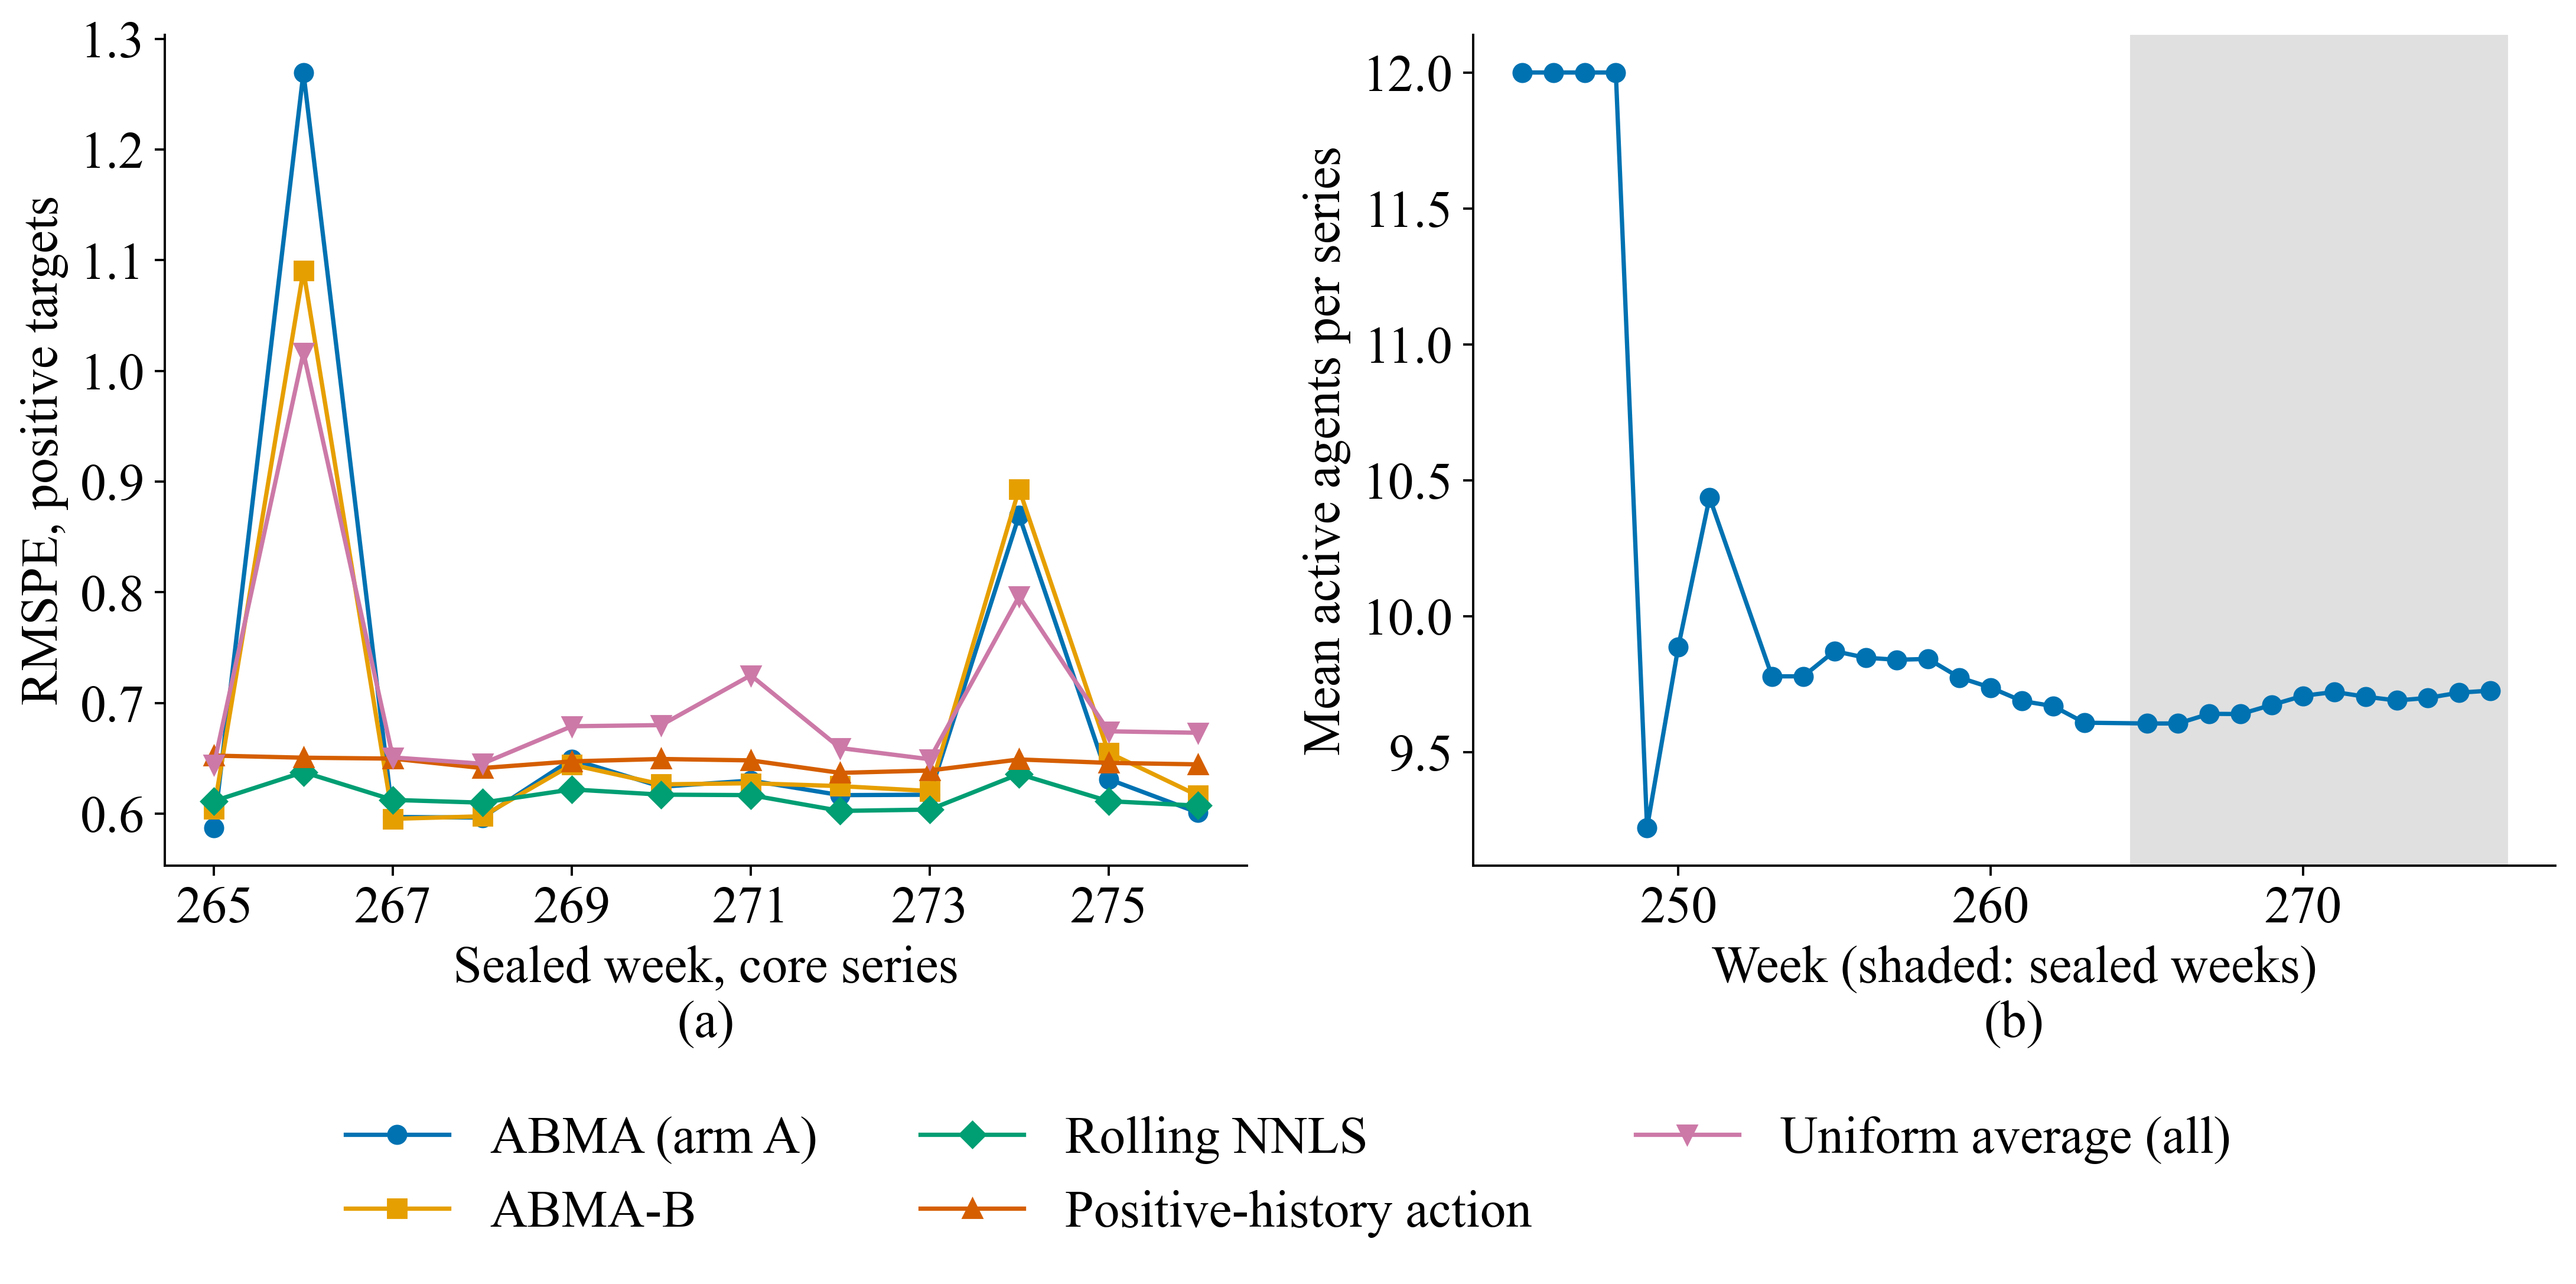

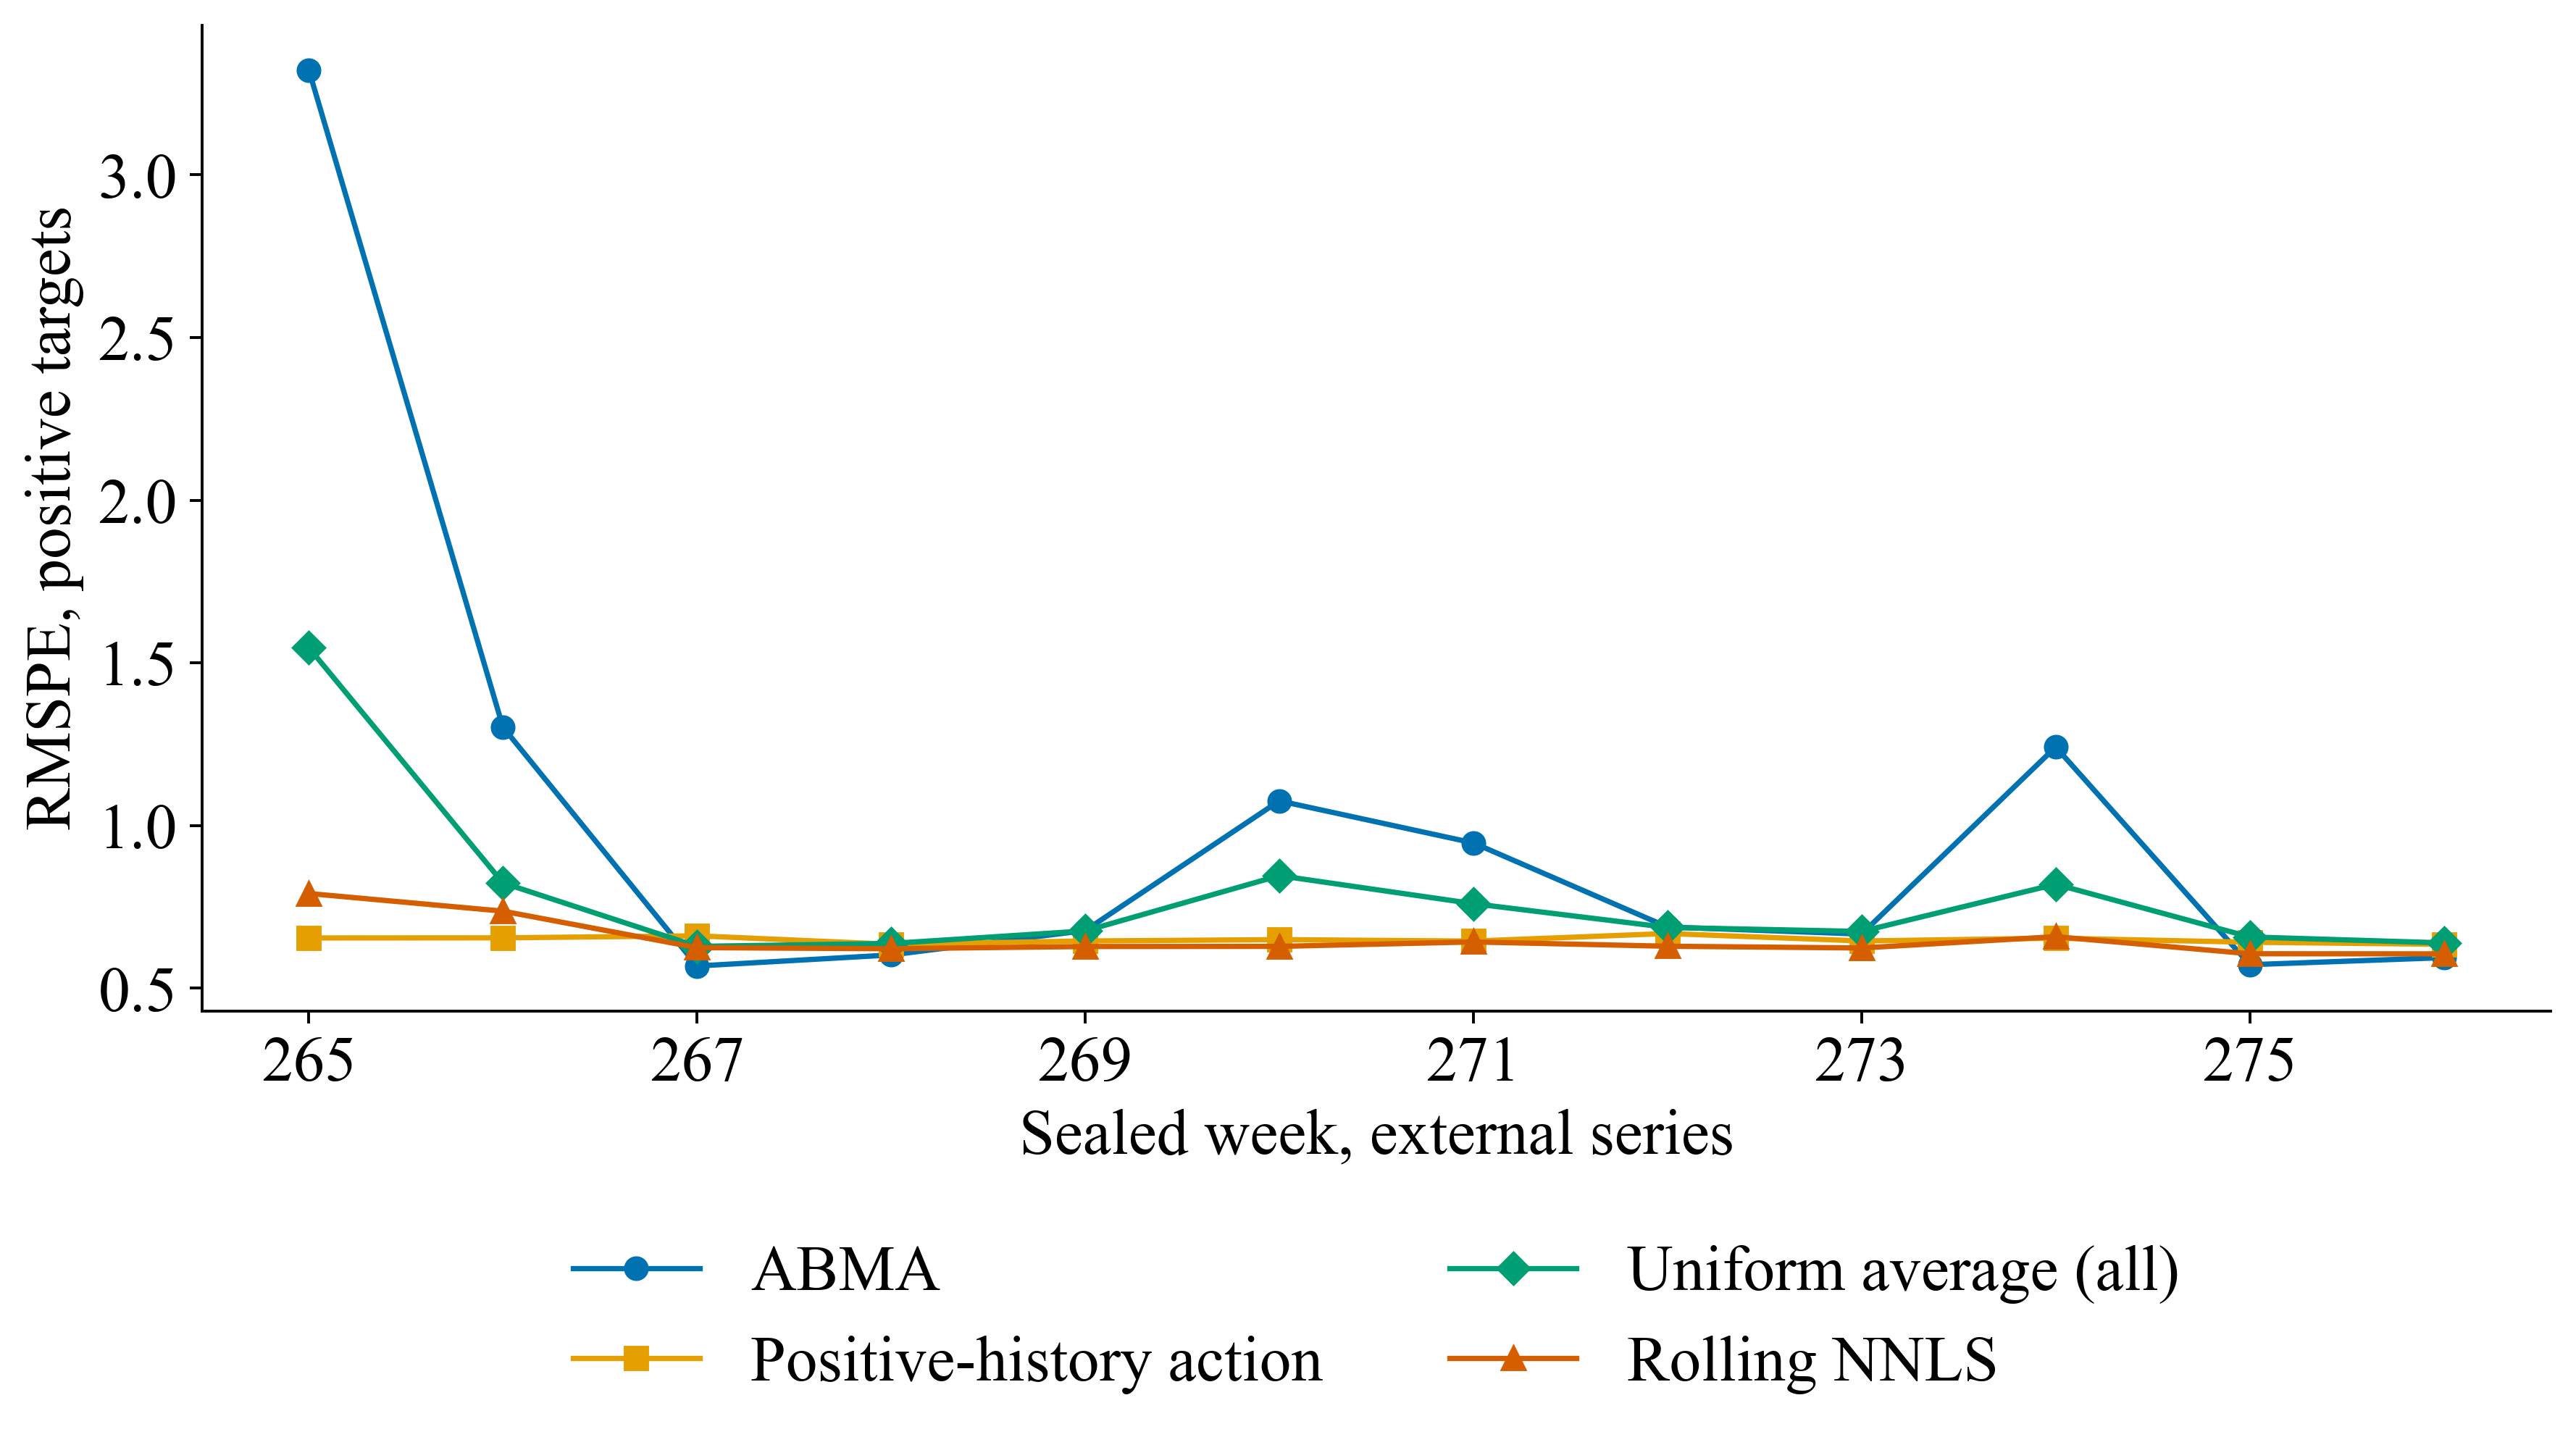

In [11]:
# NB06_DYNAMICS
act_T=abma_tr['ACT'][Tm];wT=pd.DataFrame(abma_tr['W'][Tm],columns=AGENTS);frame=pd.DataFrame(abma_tr['ACT'],columns=AGENTS);frame['s']=stream.Store.to_numpy();frame['t']=Tm;off=on=0
for a in AGENTS:
    g_=frame[['s','t',a]].sort_values('s',kind='stable');v=g_[a].to_numpy().astype(int);same=g_.s.to_numpy()[1:]==g_.s.to_numpy()[:-1];keep=g_.t.to_numpy()[1:]&same;d=np.diff(v)[keep];off+=int((d==-1).sum());on+=int((d==1).sum())
table(pd.DataFrame([{'Mean active agents':float(act_T.sum(1).mean()),'Minimum':int(act_T.sum(1).min()),'Maximum':int(act_T.sum(1).max()),'Deactivations in W265–W276':off,'Reactivations in W265–W276':on}]),'population_sealed',fmt='%.2f');GATE_FIRED_T=off>0 and on>0
table(pd.DataFrame({'Agent':wT.mean().sort_values(ascending=False).index,'Mean weight':wT.mean().sort_values(ascending=False).to_numpy(),'Active share':pd.DataFrame(act_T,columns=AGENTS).mean().reindex(wT.mean().sort_values(ascending=False).index).to_numpy(),'RMSPE W265–W276':[rmspe(y[Tm],Pq[Tm,AGENTS.index(a)]) for a in wT.mean().sort_values(ascending=False).index]}),'weights_sealed')
wTB=pd.DataFrame(b_tr['W'][Tm],columns=AGENTS).mean().sort_values(ascending=False);table(pd.DataFrame({'Agent':wTB.index,'Mean weight, arm B':wTB.to_numpy(),'Mean weight, arm A':wT.mean().reindex(wTB.index).to_numpy(),'RMSPE W265–W276':[rmspe(y[Tm],Pq[Tm,AGENTS.index(a)]) for a in wTB.index]}),'weights_sealed_b');GUARD_SHARE_T=float(np.mean(b_out[Tm]!=b_tr['MIX'][Tm]))
BEST_COMB=str(board[board.Model.str.startswith('C: ')&~board.Model.str.contains('Best single')].iloc[0].Model);BEST_B=str(board[board.Model.str.startswith('B: ')].iloc[0].Model)
fig,axes=plt.subplots(1,2,figsize=(12.8,6.4))
for (n,v),col,mk in zip({'ABMA (arm A)':fc['ABMA'],'ABMA-B':fc['ABMA-B'],BEST_COMB[3:]:fc[BEST_COMB],BEST_B[3:]:fc[BEST_B],'Uniform average (all)':fc['C: Uniform average (all agents)']}.items(),PALETTE,'osD^v'):axes[0].plot(weeks_T,[rmspe(y[Tm&(wk==w)],v[Tm&(wk==w)]) for w in weeks_T],color=col,marker=mk,label=n)
axes[0].set(xlabel='Sealed week, core series',ylabel='RMSPE, positive targets');axes[0].set_xticks(weeks_T[::2]);weekly_active=pd.DataFrame({'week':wk,'active':abma_tr['ACT'].sum(1)}).groupby('week')['active'].mean();axes[1].plot(weekly_active.index,weekly_active.to_numpy(),color=PALETTE[0],marker='o');axes[1].axvspan(264.5,276.5,color='0.88',zorder=0);axes[1].set(xlabel='Week (shaded: sealed weeks)',ylabel='Mean active agents per series')
h,l=axes[0].get_legend_handles_labels();label_panels(axes);fig.legend(h,l,loc='lower center',ncol=3,frameon=False);fig.tight_layout(rect=[0,0.14,1,1]);figure(fig,'fig_m5_sealed_weekly_population')
XBEST_B=str(xboard[xboard.Model.str.startswith('B: ')].iloc[0].Model);fig,ax=plt.subplots(figsize=(10.5,6.2))
for (n,v),col,mk in zip({'ABMA':xfc['ABMA'],XBEST_B[3:]:xfc[XBEST_B],'Uniform average (all)':xfc['C: Uniform average (all agents)'],'Rolling NNLS':xfc['C: Rolling NNLS']}.items(),PALETTE,'osD^'):ax.plot(weeks_T,[rmspe(yx[XT&(wkx==w)],v[XT&(wkx==w)]) for w in weeks_T],color=col,marker=mk,label=n)
ax.set(xlabel='Sealed week, external series',ylabel='RMSPE, positive targets');ax.set_xticks(weeks_T[::2]);ax.legend(loc='upper center',bbox_to_anchor=(0.5,-0.18),ncol=2,frameon=False);fig.tight_layout();figure(fig,'fig_m5_sealed_external_weekly')
pd.DataFrame({k:[rmspe(y[Tm&(wk==w)],v[Tm&(wk==w)]) for w in weeks_T] for k,v in fc.items()},index=weeks_T).rename_axis('Week').reset_index().to_csv(OUT/'weekly_rmspe_sealed.csv',index=False)

### 9. Predictive intervals against the best competitor's nested residual law on identical rows

,Model,PICP90,Coverage error,MPIW90,Interval score,Zero-target coverage,Width ratio to competitor
0,ABMA count-law mixture (frozen scale),0.93891,0.03891,13.55866,23.14832,0.94626,0.61140
1,"Positive-history action, nested residual law",0.91962,0.01962,22.17657,72.17699,0.93225,1.00000
2,ABMA-B count-law mixture (frozen scale),0.92973,0.02973,12.77308,25.42878,0.93775,0.57597


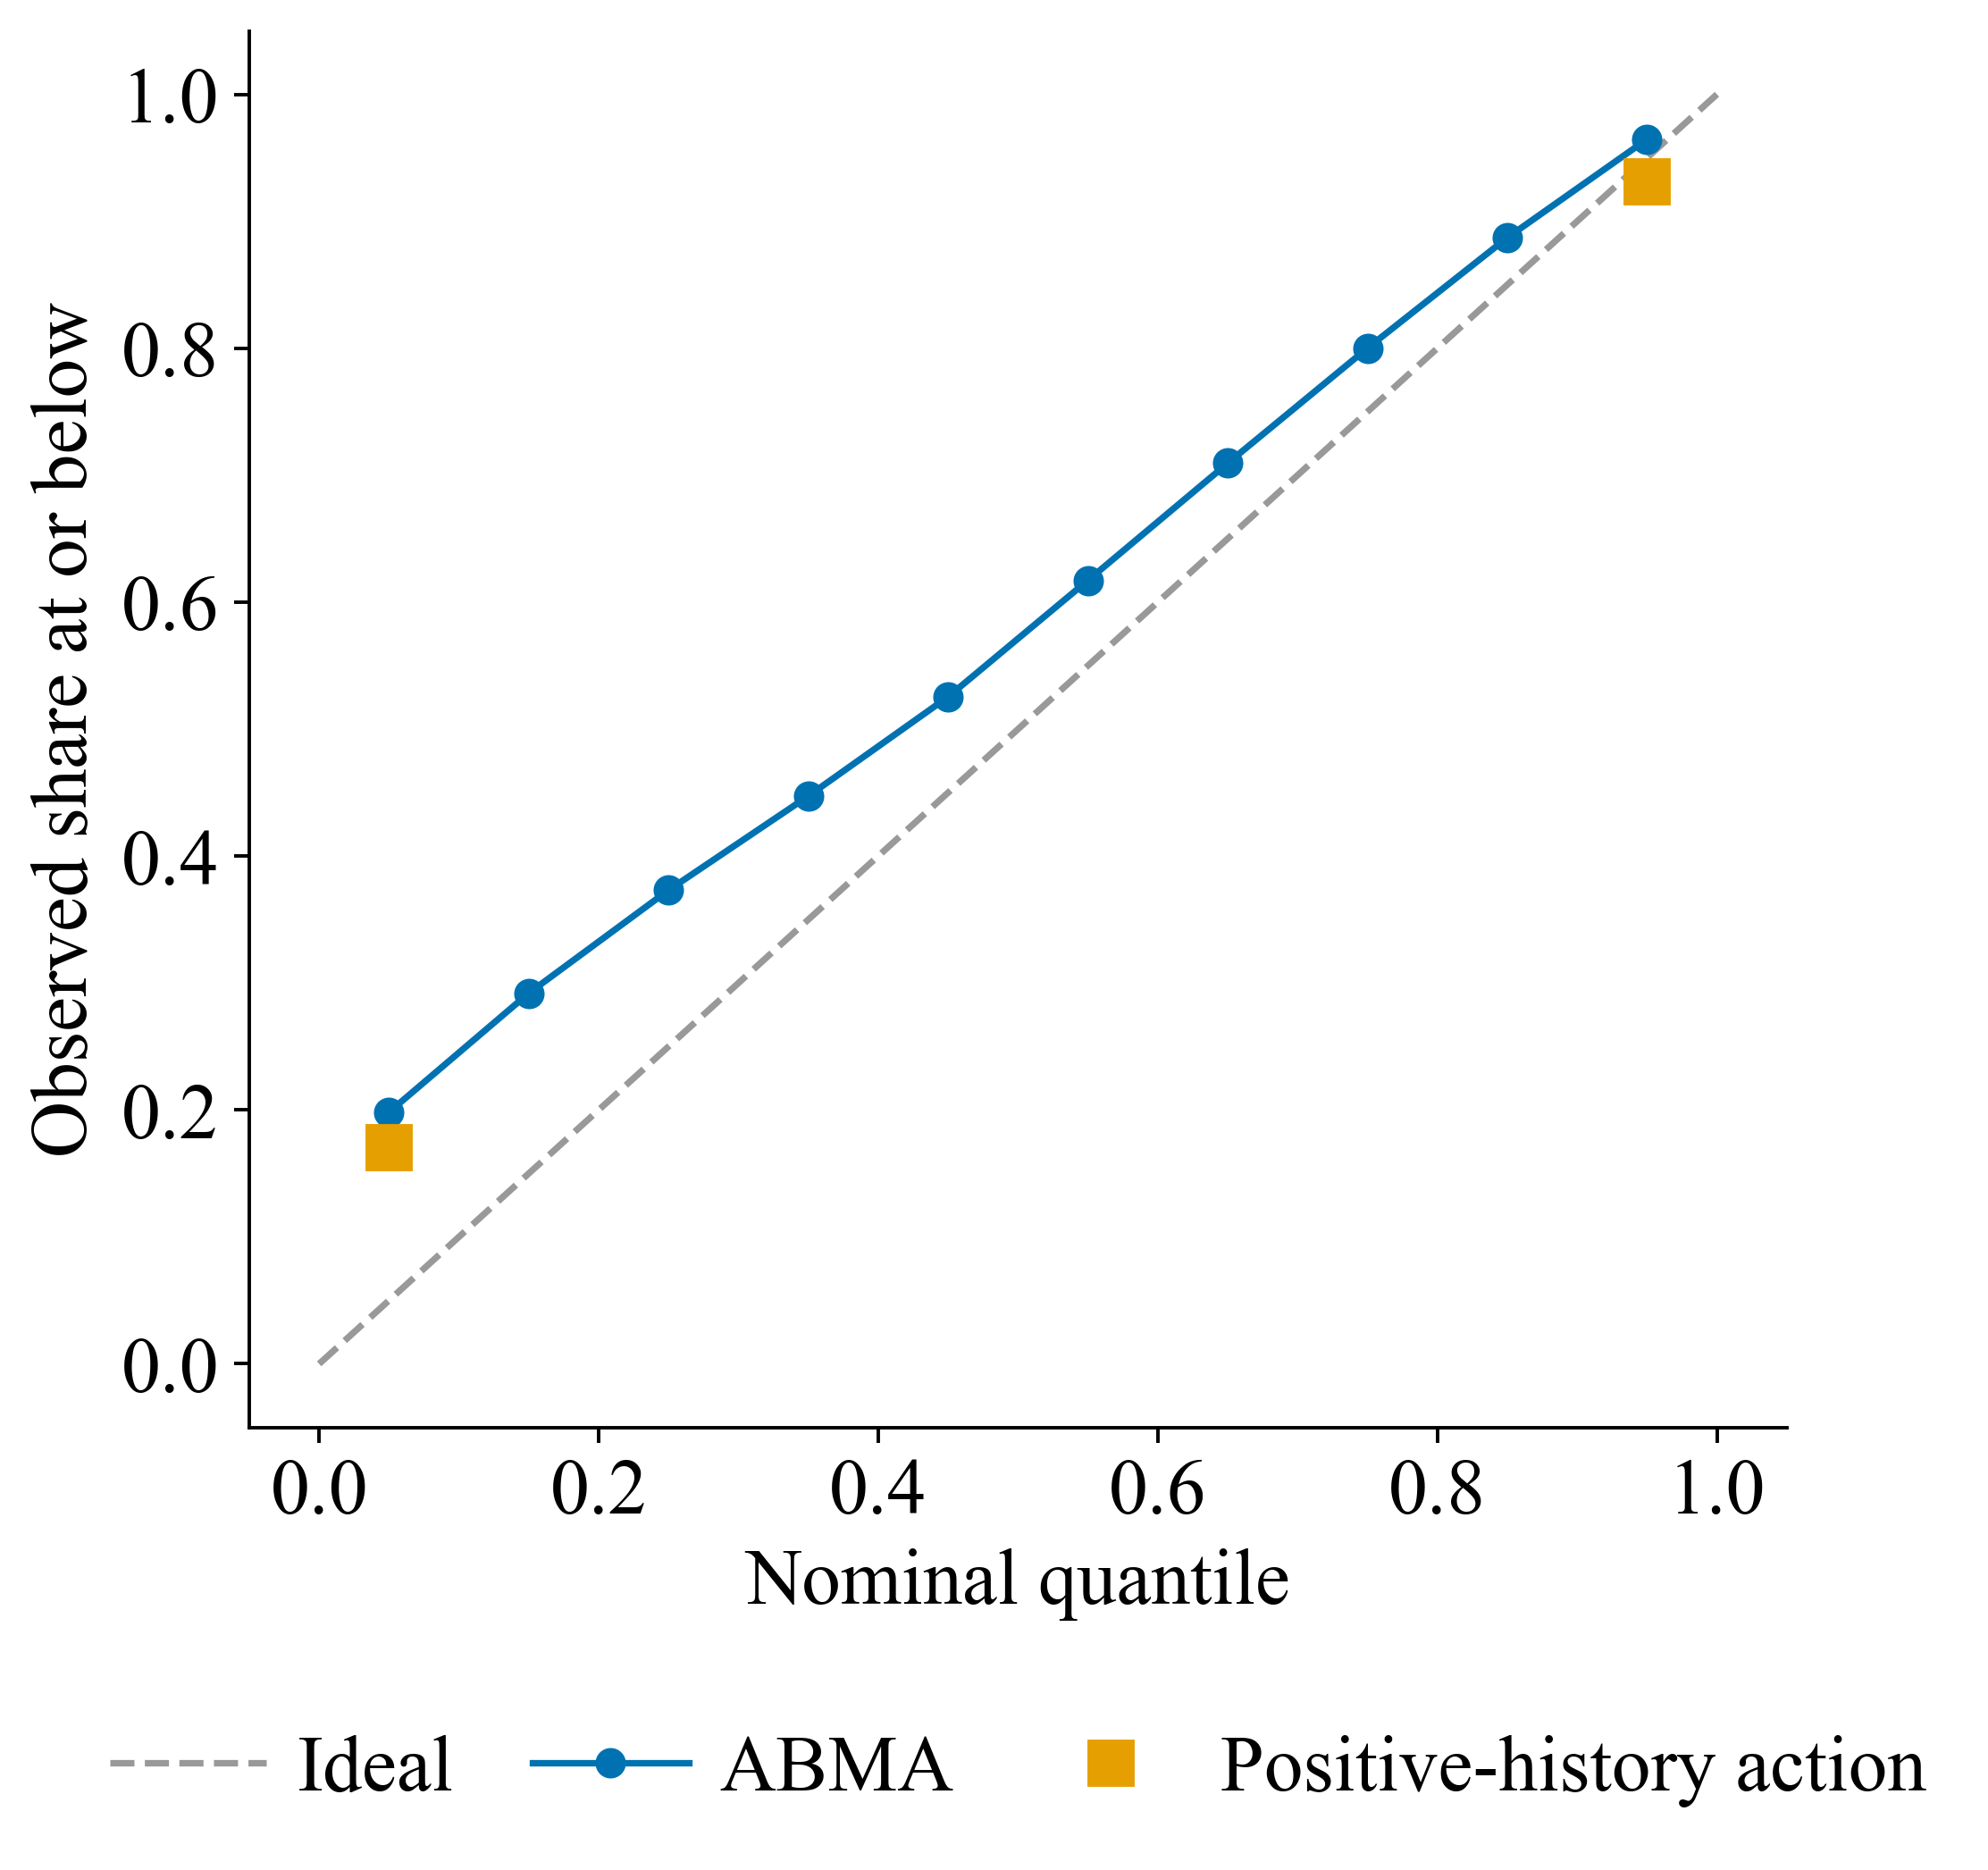

In [12]:
# NB06_INTERVALS
def mix_q(mk,q,scale=CTRL['pi_scale']):return mixture_quantile(abma_tr['W'][mk],abma_tr['MU'][mk],abma_tr['SG'][mk],q,count=(abma_tr['P'][mk],abma_tr['LAW']*scale,abma_tr['LAW_IDX'][mk]))
qlo,qhi=mix_q(Tm,0.05),mix_q(Tm,0.95);yT=y[Tm];best_comp=BEST_B[3:];cal_=np.load(NB03_OUT/'nested_residual_calibrators.npz') if best_comp in NB03_MODELS else np.load(NB04_OUT/'nested_residual_calibrators.npz');grid_r=cal_[str((NB03_MODELS if best_comp in NB03_MODELS else NB04_MODELS).index(best_comp))]
pc_=Pq[Tm,AGENTS.index(best_comp)];clo=np.zeros(len(pc_));chi=np.zeros(len(pc_))
for a in range(0,len(pc_),100000):ix=slice(a,a+100000);draws=np.maximum(0,np.rint(pc_[ix][:,None]+np.sqrt(pc_[ix][:,None]+1)*grid_r[None,:]));clo[ix],chi[ix]=np.quantile(draws,[.05,.95],axis=1,method='inverted_cdf')
def interval_row(name,lo,hi):cov=float(np.mean((yT>=lo)&(yT<=hi)));return {'Model':name,'PICP90':cov,'Coverage error':abs(cov-0.9),'MPIW90':float(np.mean(hi-lo)),'Interval score':float(np.mean((hi-lo)+20*np.maximum(lo-yT,0)+20*np.maximum(yT-hi,0))),'Zero-target coverage':float(np.mean(lo[yT==0]<=0))}
def mix_q_b(mk,q,scale=FROZEN_B['pi_scale']):return mixture_quantile(b_tr['W'][mk],b_tr['MU'][mk],b_tr['SG'][mk],q,count=(b_tr['P'][mk],b_tr['LAW']*scale,b_tr['LAW_IDX'][mk]))
blo,bhi=mix_q_b(Tm,0.05),mix_q_b(Tm,0.95)
pi=pd.DataFrame([interval_row('ABMA count-law mixture (frozen scale)',qlo,qhi),interval_row(f'{best_comp}, nested residual law',clo,chi),interval_row('ABMA-B count-law mixture (frozen scale)',blo,bhi)]);pi['Width ratio to competitor']=pi['MPIW90']/pi['MPIW90'].iloc[1];table(pi,'intervals_sealed')
pc=np.linspace(.05,.95,10);cov_curve=[float((yT<=mix_q(Tm,q)).mean()) for q in pc];fig,ax=plt.subplots(figsize=(6.6,6.4));ax.plot([0,1],[0,1],color='0.6',ls='--',label='Ideal');ax.plot(pc,cov_curve,color=PALETTE[0],marker='o',label='ABMA');ax.plot([0.05,0.95],[(yT<=clo).mean(),(yT<=chi).mean()],ls='none',marker='s',ms=10,color=PALETTE[1],label=best_comp)
ax.set(xlabel='Nominal quantile',ylabel='Observed share at or below');ax.legend(loc='upper center',bbox_to_anchor=(0.5,-0.17),ncol=3,frameon=False,columnspacing=1.0,handletextpad=0.4);fig.tight_layout();figure(fig,'fig_m5_sealed_reliability')

### 10. Computational scalability of the online layer at 27,441 series

Wall time (no tracing) and peak traced memory of one pass of the online layer on the full stream, for random subsets of series and for the 3, 7 and all agents with the largest sealed-week weights.

series 1000 agents 3: 0.3s, 13 MiB


series 1000 agents 7: 0.6s, 18 MiB


series 1000 agents 12: 0.9s, 24 MiB


series 5000 agents 3: 1.5s, 62 MiB


series 5000 agents 7: 3.2s, 82 MiB


series 5000 agents 12: 7.4s, 108 MiB


... (4 outputs left out)

series 27441 agents 7: 25.9s, 443 MiB


series 27441 agents 12: 43.8s, 577 MiB


,Series,Agents,Series-weeks,Seconds,Seconds per million series-weeks,Peak memory (MiB)
0,1000,3,30000,0.25856,8.61869,12.93810
1,1000,7,30000,0.56730,18.91002,17.69362
2,1000,12,30000,0.93447,31.14887,23.64037
3,5000,3,150000,1.45680,9.71198,61.97173
4,5000,7,150000,3.23376,21.55842,82.27036
5,5000,12,150000,7.40284,49.35226,107.65232
6,10000,3,300000,4.12688,13.75628,123.29249
7,10000,7,300000,9.05562,30.18539,162.98955
8,10000,12,300000,15.31588,51.05294,212.66659
9,27441,3,823230,11.25689,13.67406,336.69211


,Combiner,Seconds
0,ABMA online layer (12 agents),54.18010
1,ABMA-B online layer (12 agents),47.19192
2,Rolling NNLS,0.32892
3,Dynamic model averaging,2.30587
4,Fixed-share exponential weighting,0.68731
5,Dynamic weighted majority,0.68281
6,Drift-reset NNLS (Page-Hinkley),9.77973


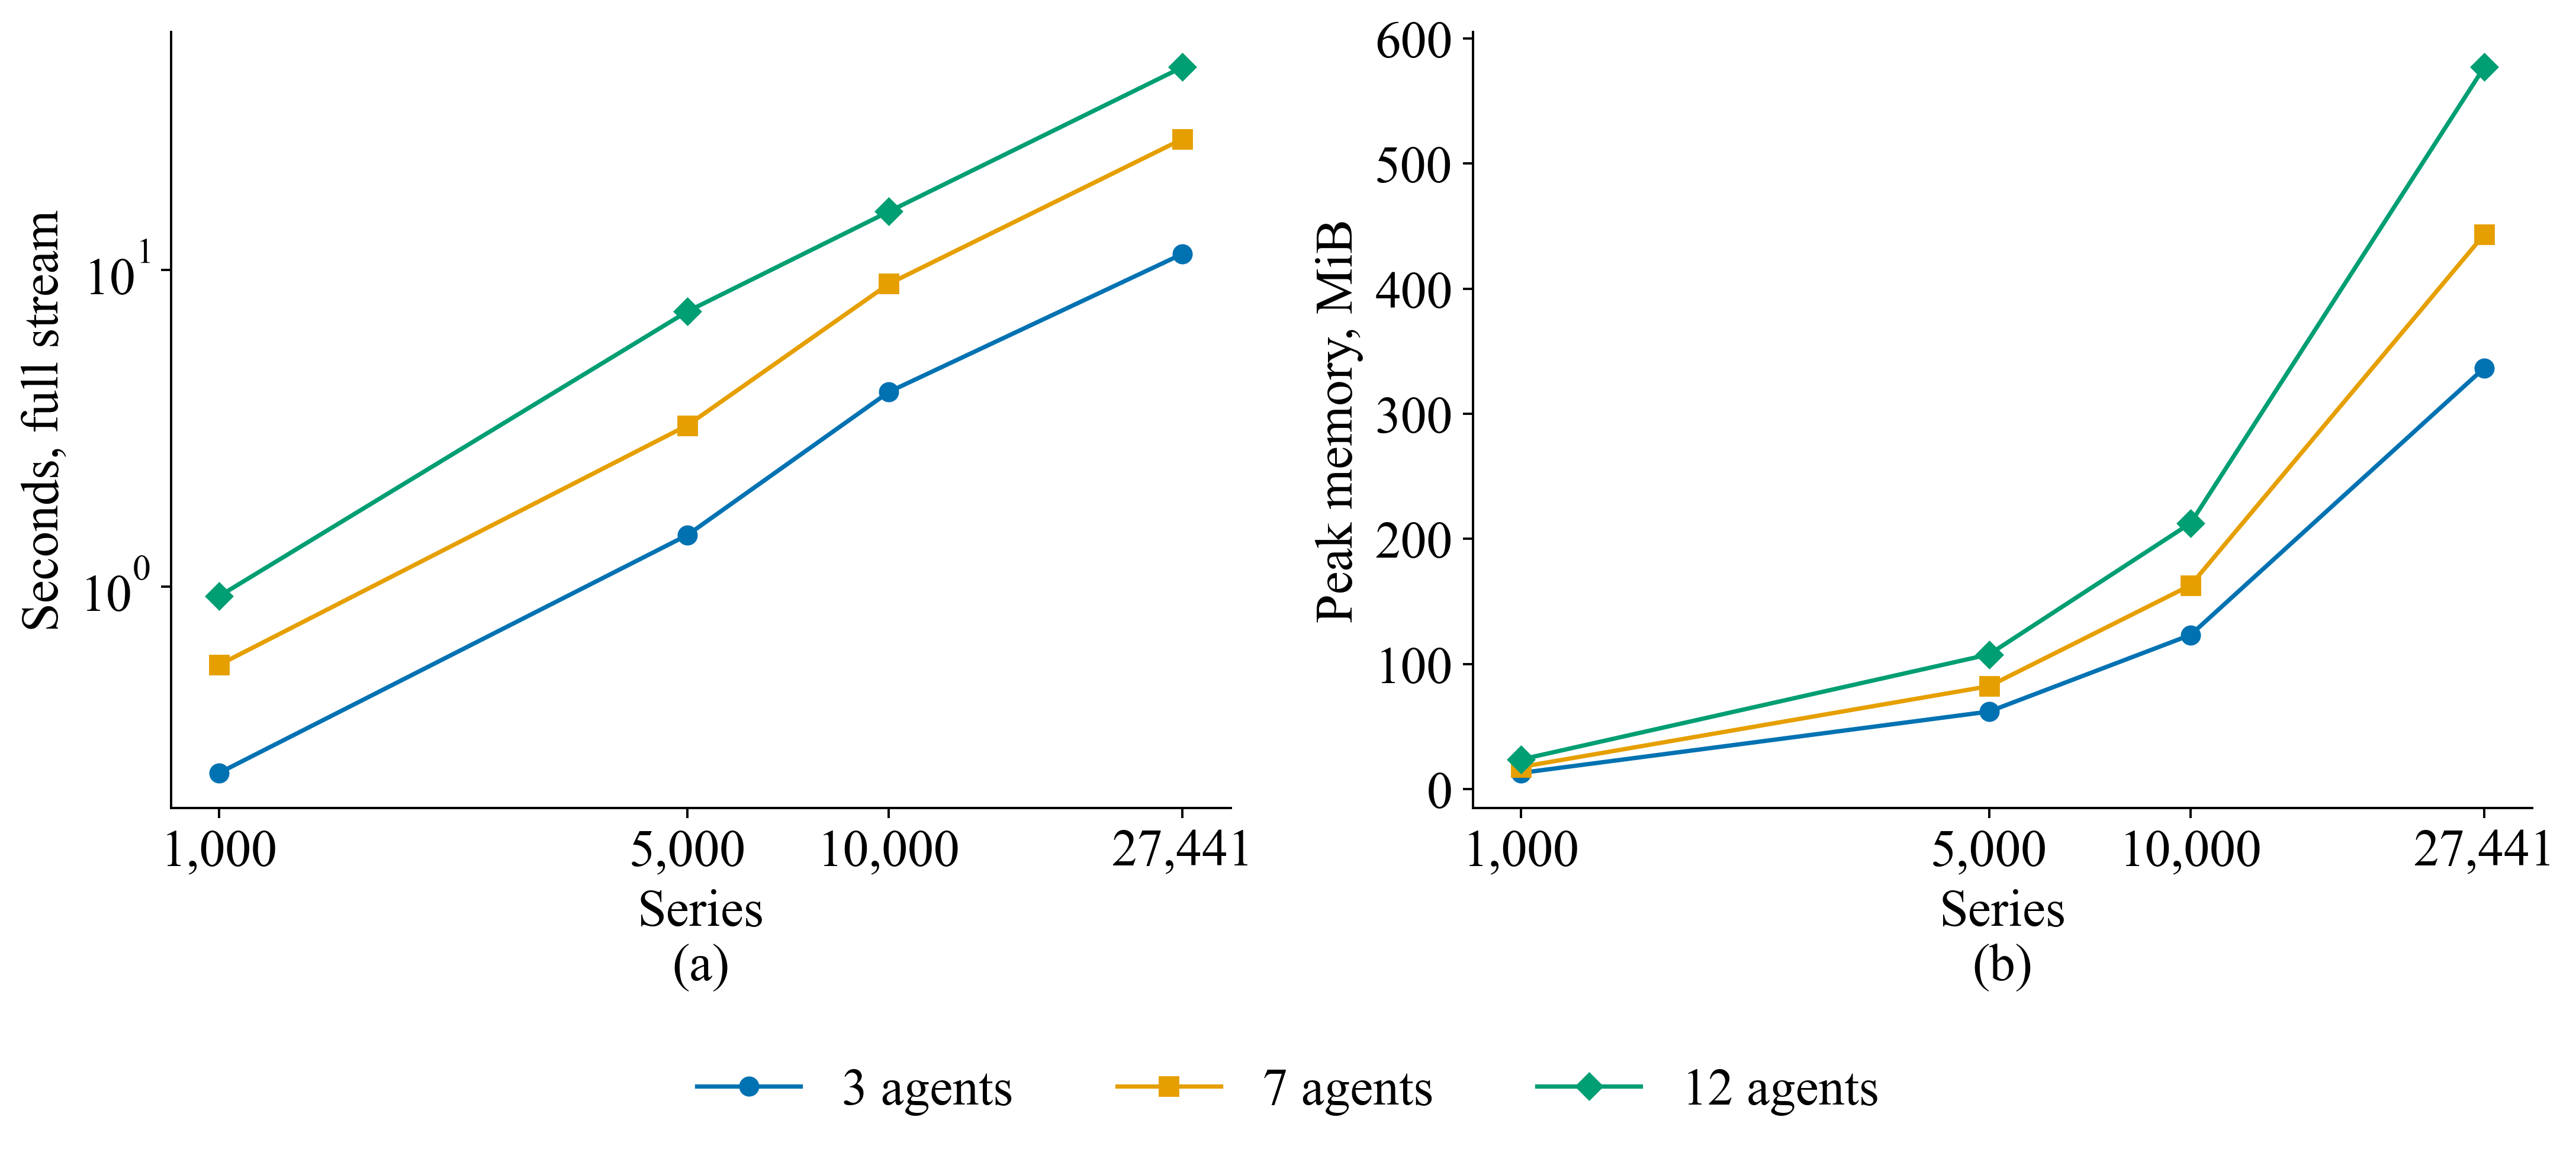

In [13]:
# NB06_SCALABILITY
def timed_layer(st_,Pm):
    t0=time.perf_counter();abma_run(st_,Pm,ABMA_CFG);dt=time.perf_counter()-t0;tracemalloc.start();abma_run(st_,Pm,ABMA_CFG);peak=tracemalloc.get_traced_memory()[1]/2**20;tracemalloc.stop();return dt,peak
top_agents=list(wT.mean().sort_values(ascending=False).index);series_all=np.sort(stream.Store.unique());g_sc=np.random.default_rng(SEED);scal=[]
for ns in (1000,5000,10000,len(series_all)):
    sel=series_all if ns==len(series_all) else g_sc.choice(series_all,ns,replace=False);m=stream.Store.isin(sel).to_numpy();st_=stream.loc[m,['Store','Date','Sales','ctx']].reset_index(drop=True)
    for k in (3,7,len(AGENTS)):
        cols=[AGENTS.index(a) for a in top_agents[:k]];dt,peak=timed_layer(st_,Pq[m][:,cols]);scal.append({'Series':int(ns),'Agents':k,'Series-weeks':int(m.sum()),'Seconds':dt,'Seconds per million series-weeks':1e6*dt/m.sum(),'Peak memory (MiB)':peak});print(f'series {ns} agents {k}: {dt:.1f}s, {peak:.0f} MiB',flush=True)
scal=pd.DataFrame(scal);table(scal,'scalability',fmt='%.2f')
table(pd.DataFrame([{'Combiner':f'ABMA online layer ({len(AGENTS)} agents)','Seconds':ABMA_SEC},{'Combiner':f'ABMA-B online layer ({len(AGENTS)} agents)','Seconds':B_SEC}]+[{'Combiner':k[3:],'Seconds':v} for k,v in CTRL_SEC.items()]),'combiner_time',fmt='%.1f')
fig,axes=plt.subplots(1,2,figsize=(12.8,5.8))
for k,col,mk in zip((3,7,len(AGENTS)),PALETTE,'osD'):sk=scal[scal.Agents==k];axes[0].plot(sk.Series,sk.Seconds,color=col,marker=mk,label=f'{k} agents');axes[1].plot(sk.Series,sk['Peak memory (MiB)'],color=col,marker=mk,label=f'{k} agents')
axes[0].set(xlabel='Series',ylabel='Seconds, full stream',xscale='log',yscale='log');axes[1].set(xlabel='Series',ylabel='Peak memory, MiB',xscale='log')
for ax in axes:ax.set_xticks([1000,5000,10000,len(series_all)],['1,000','5,000','10,000',f'{len(series_all):,}']);ax.minorticks_off()
h,l=axes[0].get_legend_handles_labels();label_panels(axes);fig.legend(h,l,loc='lower center',ncol=3,frameon=False);fig.tight_layout(rect=[0,0.10,1,1]);figure(fig,'fig_m5_scalability')

### 11. Component evidence and forest plot

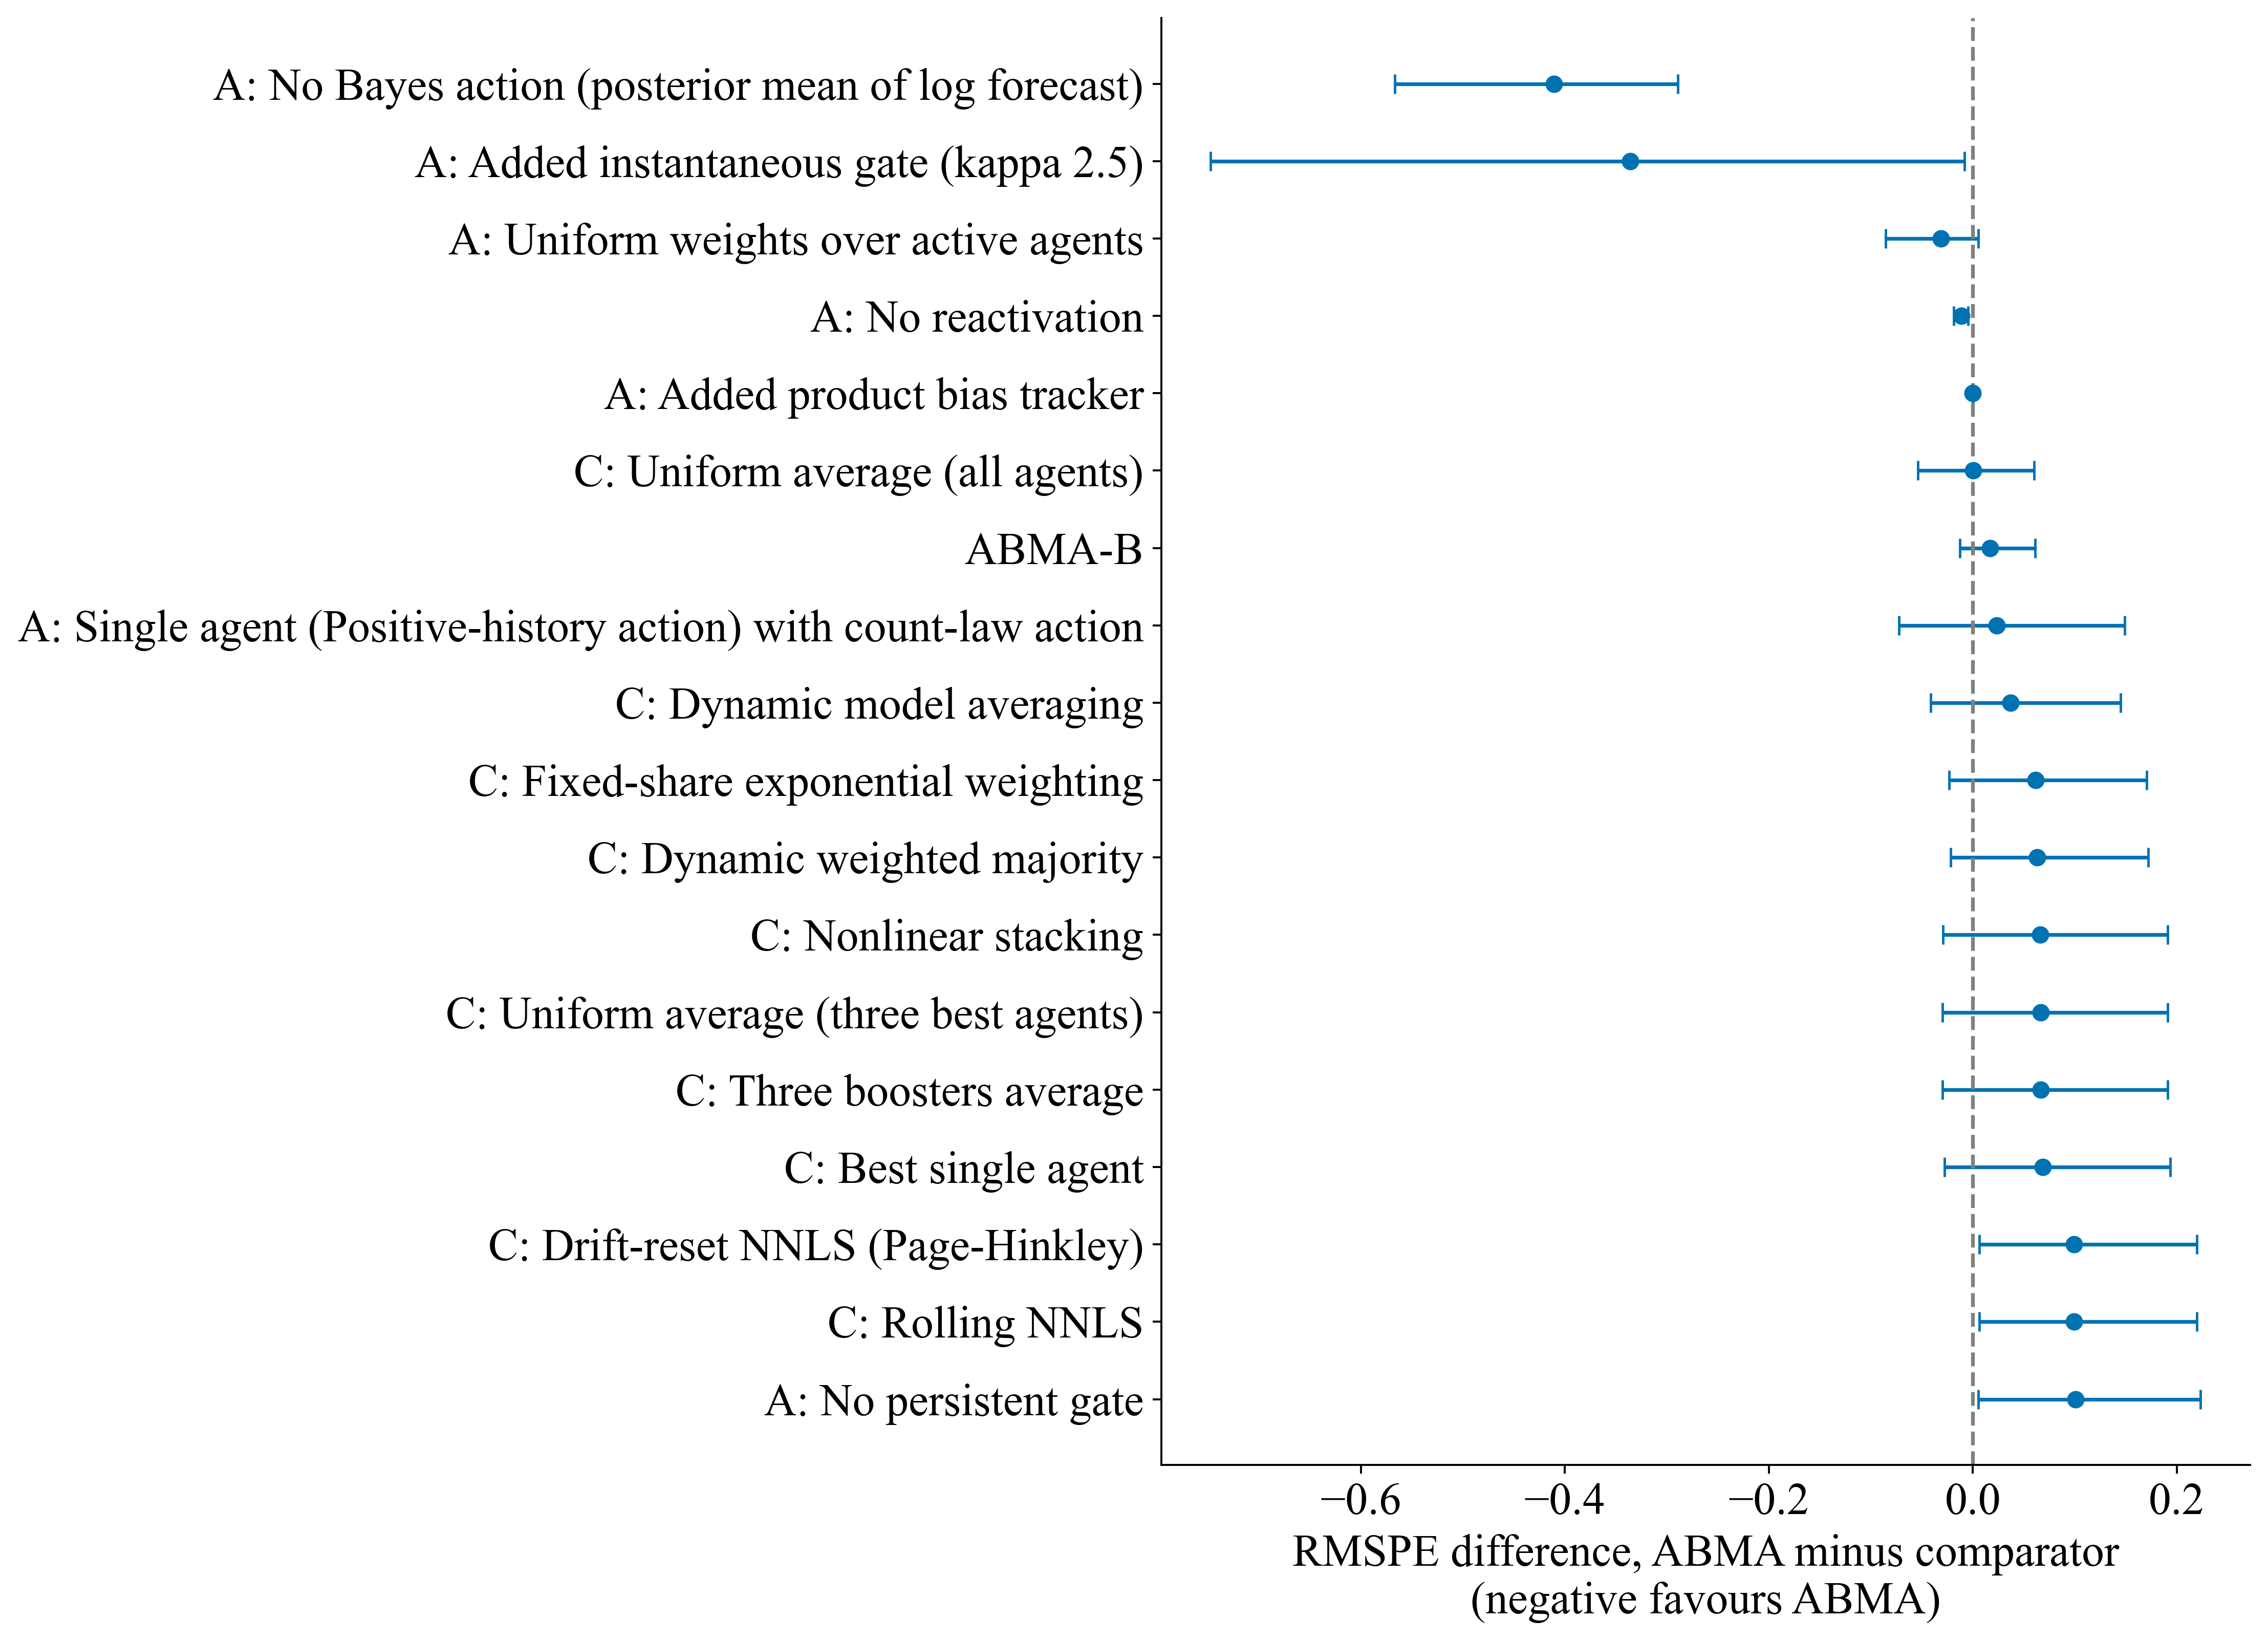

,Component removed,Kind,Difference (ABMA - ablation),Holm p (all comparators),Significantly worse without it
0,No Bayes action (posterior mean of log forecast),protected,-0.41038,0.012,True
1,Uniform weights over active agents,protected,-0.03144,1,False
2,No persistent gate,protected,0.10045,0.024,False
3,No reactivation,protected,-0.01105,0.012,True


,Component removed,Kind,Difference (ABMA-B - ablation),Holm p (all comparators),Significantly worse without it
0,No Bayes action (posterior mean of log forecast),protected,-0.22914,0.0116,True
1,Uniform weights over active agents,protected,-0.04837,1,False
2,No persistent gate,protected,0.08214,0.0116,False
3,No reactivation,protected,-0.01619,0.0116,True
4,Log-mass weights instead of the decision-loss criterion,arm-B component,-0.02072,1,False
5,Weight discount of arm A (0.99),arm-B component,-0.01085,0.0216,True


In [14]:
# NB06_FOREST
keys=[k for k in pair_T['Comparator'] if k.startswith(('A:','C:')) or k=='ABMA-B'];pf=pair_T.set_index('Comparator').loc[keys].sort_values('Difference (ABMA - comparator)',ascending=False);fig,ax=plt.subplots(figsize=(13,9.5));yy=np.arange(len(pf))
ax.errorbar(pf['Difference (ABMA - comparator)'],yy,xerr=[pf['Difference (ABMA - comparator)']-pf['CI low'],pf['CI high']-pf['Difference (ABMA - comparator)']],fmt='o',color=PALETTE[0],capsize=4);ax.axvline(0,color='0.5',ls='--');ax.set_yticks(yy,list(pf.index));ax.set(xlabel='RMSPE difference, ABMA minus comparator\n(negative favours ABMA)');fig.tight_layout();figure(fig,'fig_m5_sealed_forest')
MECH=list(PROTECTED);pt=pair_T.set_index('Comparator');component=pd.DataFrame({'Component removed':MECH,'Kind':['protected']*4,'Difference (ABMA - ablation)':[pt.loc['A: '+m,'Difference (ABMA - comparator)'] for m in MECH],'Holm p (all comparators)':[pt.loc['A: '+m,'Holm p'] for m in MECH],'Significantly worse without it':[bool(pt.loc['A: '+m,'Difference (ABMA - comparator)']<0 and pt.loc['A: '+m,'Holm p']<0.05) for m in MECH]});table(component,'component_sealed')
MECH_B=list(PROTECTED)+list(BCOMP);ptb=pair_TB.set_index('Comparator');component_b=pd.DataFrame({'Component removed':MECH_B,'Kind':['protected']*len(PROTECTED)+['arm-B component']*len(BCOMP),'Difference (ABMA-B - ablation)':[ptb.loc['A-B: '+m,'Difference (ABMA-B - comparator)'] for m in MECH_B],'Holm p (all comparators)':[ptb.loc['A-B: '+m,'Holm p'] for m in MECH_B],'Significantly worse without it':[bool(ptb.loc['A-B: '+m,'Difference (ABMA-B - comparator)']<0 and ptb.loc['A-B: '+m,'Holm p']<0.05) for m in MECH_B]});table(component_b,'component_sealed_b')

In [15]:
# NB06_SAVE: forecasts of every model on the sealed rows
stream[['row_id','id','week','quantity','block']].assign(**{k:v.astype(np.float32) for k,v in fc.items()}).to_parquet(OUT/'sealed_forecasts_core.parquet',index=False);xs[['row_id','id','week','quantity','block']].assign(**{k:v.astype(np.float32) for k,v in xfc.items()}).to_parquet(OUT/'sealed_forecasts_external.parquet',index=False)